<a href="https://colab.research.google.com/github/anhthuvo0506-web/Colab-AI-Project/blob/main/KLTN_CGAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# KHÓA LUẬN TỐT NGHIỆP
## Tăng cường dữ liệu Wi-Fi Fingerprint tại vị trí chưa khảo sát bằng Conditional GAN

**Notebook thực nghiệm — bản tái cấu trúc**

### Nguyên tắc sử dụng
- Chạy tuần tự từ trên xuống trong một phiên runtime mới để kiểm tra khả năng tái lập.
- Không dùng tập Test để chọn cấu hình; Validation phục vụ lựa chọn, Test chỉ dùng đánh giá cuối.
- Các kết quả output lưu sẵn là bằng chứng tham khảo, không thay thế việc chạy lại toàn bộ notebook.
- Giữ nguyên số liệu gốc; mọi thay đổi mô hình hoặc tiền xử lý phải được ghi rõ và đánh giá lại.

### Mục lục
1. Kiểm tra dữ liệu và khảo sát vị trí tham chiếu
2. Tiền xử lý RSSI và chuẩn bị dữ liệu
3. Xây dựng, huấn luyện và kiểm định cGAN
4. Sinh fingerprint và đánh giá định vị KNN
5. Tổng hợp kết quả và thảo luận

---


# PHẦN 1. DATA AUDIT & PREPROCESSING
## 1.1. Kiểm tra cấu trúc dữ liệu gốc

Mục tiêu:
- Kiểm tra 6 file Excel của ba tầng F1, F2, F3.
- Liệt kê các sheet, kích thước và tên cột.
- Xác minh nguồn dữ liệu trước khi xây dựng quy tắc tiền xử lý.

Lưu ý: Chưa thay đổi dữ liệu gốc ở bước này.

In [ ]:

from pathlib import Path
import zipfile
import pandas as pd

# Tìm file ZIP trong runtime Colab
zip_files = list(Path("/content").glob("DATASET_DLULIB.zip"))

if not zip_files:
    from google.colab import files
    uploaded = files.upload()
    zip_files = [
        Path("/content") / name
        for name in uploaded
        if name.endswith(".zip")
    ]

if not zip_files:
    raise FileNotFoundError("Chưa tìm thấy DATASET_DLULIB.zip")

ZIP_PATH = zip_files[0]
DATA_DIR = Path("/content/DATASET_DLULIB")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Giải nén dataset
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall("/content")

# Tìm 6 file Excel thực tế
excel_files = sorted(DATA_DIR.glob("*.xlsx"))

if len(excel_files) != 6:
    raise ValueError(
        f"Mong đợi 6 file Excel, nhưng tìm thấy {len(excel_files)}. "
        f"Thư mục đang kiểm tra: {DATA_DIR}"
    )

# Thống kê cấu trúc từng sheet
summary = []

for file in excel_files:
    workbook = pd.ExcelFile(file)

    for sheet in workbook.sheet_names:
        df = pd.read_excel(file, sheet_name=sheet)

        summary.append({
            "File": file.name,
            "Sheet": sheet,
            "Số dòng": len(df),
            "Số cột": len(df.columns),
            "Tên cột": ", ".join(map(str, df.columns))
        })

display(pd.DataFrame(summary))


Saving DATASET_DLULIB.zip to DATASET_DLULIB.zip


,File,Sheet,Số dòng,Số cột,Tên cột
0,DLULIB_Test_F1.xlsx,Test_F1_1,3140,19,"ID_RP, AP1, AP2, AP3, AP4, AP5, AP6, AP7, AP8,..."
1,DLULIB_Test_F1.xlsx,Test_F1_2,3140,19,"ID_RP, AP1, AP2, AP3, AP4, AP5, AP6, AP7, AP8,..."
2,DLULIB_Test_F1.xlsx,Test_F1_3,314,18,"ID_RP, AP1, AP2, AP3, AP4, AP5, AP6, AP7, AP8,..."
3,DLULIB_Test_F2.xlsx,Test_F2_1,1860,19,"ID_RP, AP1, AP2, AP3, AP4, AP5, AP6, AP7, AP8,..."
4,DLULIB_Test_F2.xlsx,Test_F2_2,1860,19,"ID_RP, AP1, AP2, AP3, AP4, AP5, AP6, AP7, AP8,..."
5,DLULIB_Test_F2.xlsx,Test_F2_3,186,18,"ID_RP, AP1, AP2, AP3, AP4, AP5, AP6, AP7, AP8,..."
6,DLULIB_Test_F3.xlsx,Test_F3_1,1500,21,"ID_RP, X, Y, AP1, AP2, AP3, AP4, AP5, AP6, AP7..."
7,DLULIB_Test_F3.xlsx,Test_F3_2,1500,19,"ID_RP, AP1, AP2, AP3, AP4, AP5, AP6, AP7, AP8,..."
8,DLULIB_Test_F3.xlsx,Test_F3_3,150,18,"ID_RP, AP1, AP2, AP3, AP4, AP5, AP6, AP7, AP8,..."
9,DLULIB_Train_F1.xlsx,Train_F1_1,6283,23,"ID_RP, X, Y, AP1, AP2, AP3, AP4, AP5, AP6, AP7..."


### 1.2. Đối chiếu các sheet và kiểm tra mã RSSI

Mục tiêu:
- So sánh tên cột và số lượng RP giữa `_1`, `_2`, `_3`.
- Kiểm tra ID_RP trùng, thiếu hoặc khác nhau.
- Thống kê giá trị RSSI bất thường và kiểm tra giả thuyết `100` tương ứng với `-100`.

Chưa thay thế hoặc xóa bất kỳ giá trị nào trong dữ liệu gốc.

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np

DATA_DIR = Path("/content/DATASET_DLULIB")
floors = ["F1", "F2", "F3"]

for floor in floors:
    print(f"\n{'='*22} {floor} {'='*22}")

    for split in ["Train", "Test"]:
        path = DATA_DIR / f"DLULIB_{split}_{floor}.xlsx"

        if not path.exists():
            print(f"Không tìm thấy: {path}")
            continue

        xls = pd.ExcelFile(path)
        print(f"\n--- {split} ---")

        for sheet in xls.sheet_names:
            df = pd.read_excel(path, sheet_name=sheet)
            ap_cols = [c for c in df.columns if str(c).startswith("AP")]

            print(f"\n{sheet}: {df.shape}")
            print("Cột:", df.columns.tolist())

            if "ID_RP" in df.columns:
                ids = df["ID_RP"].dropna()
                print(
                    "ID_RP duy nhất:", ids.nunique(),
                    "| ID thiếu:", df["ID_RP"].isna().sum(),
                    "| ID lặp:", ids.duplicated().sum()
                )
                print("Ví dụ ID:", ids.astype(str).unique()[:5].tolist())

            if ap_cols:
                rss = df[ap_cols].apply(pd.to_numeric, errors="coerce")
                values = rss.to_numpy().ravel()
                values = values[~np.isnan(values)]

                print("Số AP:", len(ap_cols))
                print("NaN:", int(rss.isna().sum().sum()))
                print("Giá trị < -100:", int((rss < -100).sum().sum()))
                print("Giá trị = -100:", int((rss == -100).sum().sum()))
                print("Giá trị = 100:", int((rss == 100).sum().sum()))
                print("Giá trị >= 0:", int((rss >= 0).sum().sum()))
                print("RSSI min/max:",
                      (values.min(), values.max()) if len(values) else None)

    # Đối chiếu _1 và _2 trên các cột AP chung của Train
    path = DATA_DIR / f"DLULIB_Train_{floor}.xlsx"
    xls = pd.ExcelFile(path)
    d1 = pd.read_excel(path, sheet_name=f"Train_{floor}_1")
    d2 = pd.read_excel(path, sheet_name=f"Train_{floor}_2")

    ap_common = [
        c for c in d1.columns
        if c in d2.columns and str(c).startswith("AP")
    ]

    print(f"\n--- ĐỐI CHIẾU TRAIN {floor}: _1 VÀ _2 ---")
    print("Số dòng _1 / _2:", len(d1), "/", len(d2))
    print("Cột AP chung:", ap_common)

    if len(d1) == len(d2):
        a = d1[ap_common].apply(pd.to_numeric, errors="coerce")
        b = d2[ap_common].apply(pd.to_numeric, errors="coerce")
        valid = a.notna() & b.notna()

        print("Số ô AP so sánh được:", int(valid.sum().sum()))
        print("Số ô khác nhau:", int(((a != b) & valid).sum().sum()))
        print("Số ô 100 ở _1 và -100 ở _2:",
              int(((a == 100) & (b == -100) & valid).sum().sum()))
    else:
        print("Hai sheet khác số dòng: chưa so sánh theo thứ tự dòng.")



====================== F1 ======================

--- Train ---

Train_F1_1: (6283, 23)
Cột: ['ID_RP', 'X', 'Y', 'AP1', 'AP2', 'AP3', 'AP4', 'AP5', 'AP6', 'AP7', 'AP8', 'AP9', 'AP10', 'AP11', 'AP12', 'AP13', 'AP14', 'AP15', 'AP16', 'AP17', 'Smartphones', 'Users', 'Direction']
ID_RP duy nhất: 316 | ID thiếu: 1 | ID lặp: 5966
Ví dụ ID: ['1', '2', '3', '4', '5']
Số AP: 17
NaN: 17
Giá trị < -100: 0
Giá trị = -100: 0
Giá trị = 100: 40869
Giá trị >= 0: 40903
RSSI min/max: (np.float64(-99.0), np.float64(6255.0))

Train_F1_2: (6280, 23)
Cột: ['ID_RP', 'X', 'Y', 'AP1', 'AP2', 'AP3', 'AP4', 'AP5', 'AP6', 'AP7', 'AP8', 'AP9', 'AP10', 'AP11', 'AP12', 'AP13', 'AP14', 'AP15', 'AP16', 'AP17', 'Smartphones', 'Users', 'Direction']
ID_RP duy nhất: 314 | ID thiếu: 0 | ID lặp: 5966
Ví dụ ID: ['1', '2', '3', '4', '5']
Số AP: 17
NaN: 0
Giá trị < -100: 0
Giá trị = -100: 40869
Giá trị = 100: 0
Giá trị >= 0: 0
RSSI min/max: (np.int64(-100), np.int64(-28))

Train_F1_3: (314, 20)
Cột: ['ID_RP', 'X', 'Y', 'AP1',

### 1.3. Xác minh tính nhất quán giữa Train `_1` và `_2`

Đối chiếu theo `ID_RP` và thứ tự mẫu trong từng RP. Không sửa dữ liệu gốc. Chỉ xác nhận quy tắc mã hóa sau khi kiểm tra kết quả.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

DATA_DIR = Path("/content/DATASET_DLULIB")
AP = [f"AP{i}" for i in range(1, 18)]

for floor in ["F1", "F2", "F3"]:
    path = DATA_DIR / f"DLULIB_Train_{floor}.xlsx"
    d1 = pd.read_excel(path, sheet_name=f"Train_{floor}_1")
    d2 = pd.read_excel(path, sheet_name=f"Train_{floor}_2")

    print(f"\n{'='*18} {floor}: _1 vs _2 {'='*18}")

    id1 = pd.to_numeric(d1["ID_RP"], errors="coerce")
    id2 = pd.to_numeric(d2["ID_RP"], errors="coerce")

    print("ID không hợp lệ ở _1:", int(id1.isna().sum()))
    print("ID không hợp lệ ở _2:", int(id2.isna().sum()))

    valid1 = d1.loc[id1.notna()].copy()
    valid2 = d2.loc[id2.notna()].copy()

    valid1["ID_RP"] = id1[id1.notna()].astype(int)
    valid2["ID_RP"] = id2[id2.notna()].astype(int)

    n1 = valid1.groupby("ID_RP").size()
    n2 = valid2.groupby("ID_RP").size()

    all_ids = set(n1.index) | set(n2.index)
    mismatched_ids = sorted(
        i for i in all_ids
        if n1.get(i, 0) != n2.get(i, 0)
    )

    print("Số RP _1 / _2:", len(n1), "/", len(n2))
    print("RP có số mẫu khác nhau:", mismatched_ids)

    coord1 = valid1.groupby("ID_RP")[["X", "Y"]].nunique()
    coord2 = valid2.groupby("ID_RP")[["X", "Y"]].nunique()

    print("RP có tọa độ không nhất quán trong _1:",
          int((coord1 > 1).any(axis=1).sum()))
    print("RP có tọa độ không nhất quán trong _2:",
          int((coord2 > 1).any(axis=1).sum()))

    common_ids = sorted(set(n1.index) & set(n2.index))
    comparable = [
        i for i in common_ids if n1[i] == n2[i]
    ]

    a = valid1[valid1["ID_RP"].isin(comparable)].copy()
    b = valid2[valid2["ID_RP"].isin(comparable)].copy()

    a["_order"] = a.groupby("ID_RP").cumcount()
    b["_order"] = b.groupby("ID_RP").cumcount()

    keys = ["ID_RP", "_order"]
    merged = a[keys + AP + ["X", "Y"]].merge(
        b[keys + AP + ["X", "Y"]],
        on=keys,
        suffixes=("_1", "_2"),
        validate="one_to_one"
    )

    rss1 = merged[[f"{c}_1" for c in AP]].apply(
        pd.to_numeric, errors="coerce"
    ).to_numpy()

    rss2 = merged[[f"{c}_2" for c in AP]].apply(
        pd.to_numeric, errors="coerce"
    ).to_numpy()

    rss1[rss1 == 100] = -100
    valid = np.isfinite(rss1) & np.isfinite(rss2)

    print("RP so sánh được:", len(comparable))
    print("Số mẫu so sánh được:", len(merged))
    print("Số ô RSSI so sánh được:", int(valid.sum()))
    print("Số ô RSSI không khớp:",
          int(((rss1 != rss2) & valid).sum()))

    x1 = merged["X_1"].to_numpy()
    x2 = merged["X_2"].to_numpy()
    y1 = merged["Y_1"].to_numpy()
    y2 = merged["Y_2"].to_numpy()

    print("Số dòng tọa độ không khớp:",
          int(((x1 != x2) | (y1 != y2)).sum()))


================== F1: _1 vs _2 ==================
ID không hợp lệ ở _1: 3
ID không hợp lệ ở _2: 0
Số RP _1 / _2: 314 / 314
RP có số mẫu khác nhau: []
RP có tọa độ không nhất quán trong _1: 0
RP có tọa độ không nhất quán trong _2: 0
RP so sánh được: 314
Số mẫu so sánh được: 6280
Số ô RSSI so sánh được: 106760
Số ô RSSI không khớp: 0
Số dòng tọa độ không khớp: 0

================== F2: _1 vs _2 ==================
ID không hợp lệ ở _1: 3
ID không hợp lệ ở _2: 0
Số RP _1 / _2: 186 / 186
RP có số mẫu khác nhau: []
RP có tọa độ không nhất quán trong _1: 0
RP có tọa độ không nhất quán trong _2: 0
RP so sánh được: 186
Số mẫu so sánh được: 3720
Số ô RSSI so sánh được: 63240
Số ô RSSI không khớp: 0
Số dòng tọa độ không khớp: 0

================== F3: _1 vs _2 ==================
ID không hợp lệ ở _1: 3
ID không hợp lệ ở _2: 0
Số RP _1 / _2: 150 / 150
RP có số mẫu khác nhau: []
RP có tọa độ không nhất quán trong _1: 0
RP có tọa độ không nhất quán trong _2: 0
RP so sánh được: 150
Số mẫu so sánh đ

### Cell 1.4 — Kiểm tra fingerprint đại diện

**Mục tiêu:** So sánh RSSI tại mỗi RP trong sheet `_3` với giá trị trung bình và trung vị của 20 mẫu trong sheet `_2`.

**Chỉ số:** MAE (dBm), tính trên các ô RSSI đối chiếu được.

**Quy ước:** Xanh lá biểu thị sai lệch nhỏ; vàng biểu thị cần kiểm tra; đỏ biểu thị sai lệch lớn theo ngưỡng tham khảo 1 dBm. Màu sắc chỉ hỗ trợ quan sát, không tự xác nhận nguồn gốc dữ liệu.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, HTML
import html

DATA_DIR = Path("/content/DATASET_DLULIB")
AP = [f"AP{i}" for i in range(1, 18)]

def show_result(title, value, status="info"):
    styles = {
        "success": ("#E1F5E8", "#166534", "✓"),
        "warning": ("#FFF4D6", "#92400E", "!"),
        "error":   ("#FCE7E7", "#991B1B", "✕"),
        "info":    ("#E6F0FF", "#1E40AF", "●")
    }
    bg, fg, icon = styles[status]

    display(HTML(f"""
    <div style="background:{bg};color:{fg};padding:10px 14px;
                border-radius:8px;border-left:5px solid {fg};
                margin:5px 0;font-family:Arial,sans-serif;">
      <b>{icon} {html.escape(str(title))}</b><br>
      {html.escape(str(value))}
    </div>
    """))

summary = []

for floor in ["F1", "F2", "F3"]:
    path = DATA_DIR / f"DLULIB_Train_{floor}.xlsx"
    raw = pd.read_excel(path, sheet_name=f"Train_{floor}_2")
    ref = pd.read_excel(path, sheet_name=f"Train_{floor}_3")

    for df in [raw, ref]:
        df["ID_RP"] = pd.to_numeric(df["ID_RP"], errors="coerce")
        df[AP] = df[AP].apply(pd.to_numeric, errors="coerce")
        df[AP] = df[AP].replace(100, -100)

    raw = raw.dropna(subset=["ID_RP"]).copy()
    ref = ref.dropna(subset=["ID_RP"]).copy()
    raw["ID_RP"] = raw["ID_RP"].astype(int)
    ref["ID_RP"] = ref["ID_RP"].astype(int)

    mean_rssi = raw.groupby("ID_RP")[AP].mean()
    median_rssi = raw.groupby("ID_RP")[AP].median()
    ref_rssi = ref.drop_duplicates("ID_RP").set_index("ID_RP")[AP]

    common = mean_rssi.index.intersection(ref_rssi.index)

    a = mean_rssi.loc[common].to_numpy()
    b = median_rssi.loc[common].to_numpy()
    c = ref_rssi.loc[common].to_numpy()

    # Chỉ tính MAE trên các ô có giá trị hợp lệ ở cả hai phía
    err_mean = np.abs(a - c)
    err_median = np.abs(b - c)

    mae_mean = np.nanmean(
        np.where(np.isfinite(a) & np.isfinite(c), err_mean, np.nan)
    )
    mae_median = np.nanmean(
        np.where(np.isfinite(b) & np.isfinite(c), err_median, np.nan)
    )

    summary.append({
        "Tầng": floor,
        "Số RP đối chiếu": len(common),
        "MAE so với trung bình (dBm)": mae_mean,
        "MAE so với trung vị (dBm)": mae_median
    })

    status = "success" if mae_mean < 1 else (
        "warning" if mae_mean <= 3 else "error"
    )

    show_result(
        f"TẦNG {floor}",
        f"{len(common)} RP | MAE so với trung bình: {mae_mean:.4f} dBm"
        f" | MAE so với trung vị: {mae_median:.4f} dBm",
        status
    )

result_df = pd.DataFrame(summary)

display(HTML("""
<h4 style="font-family:Arial;color:#2563EB;margin-top:18px;">
  BẢNG TỔNG HỢP BA TẦNG
</h4>
"""))

display(
    result_df.style
    .format({
        "MAE so với trung bình (dBm)": "{:.4f}",
        "MAE so với trung vị (dBm)": "{:.4f}"
    })
    .background_gradient(
        subset=["MAE so với trung bình (dBm)",
                "MAE so với trung vị (dBm)"],
        cmap="RdYlGn_r"
    )
)

,Tầng,Số RP đối chiếu,MAE so với trung bình (dBm),MAE so với trung vị (dBm)
0,F1,314,0.2127,2.4223
1,F2,186,0.2303,3.7872
2,F3,150,0.2222,3.4918


### Cell 1.5 — Phân tích RSSI và số AP được phát hiện

**Mục tiêu:**
- Thống kê số ô RSSI bằng `-100` và số ô có RSSI lớn hơn `-100`.
- Tính số AP được phát hiện trung bình trên mỗi fingerprint.
- So sánh RSSI trung bình khi giữ `-100` với RSSI trung bình chỉ tính trên các giá trị lớn hơn `-100`.

**Ý nghĩa:** Xác định ảnh hưởng của cách xử lý `-100` trước khi xây dựng dữ liệu tăng cường và huấn luyện cGAN.

**Lưu ý:** Trong cell này, `-100` được tạm xem là giá trị không phát hiện AP để kiểm tra. Cần xác minh quy ước mã hóa của bộ dữ liệu trước khi chốt phương pháp.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, HTML
import html

DATA_DIR = Path("/content/DATASET_DLULIB")
AP = [f"AP{i}" for i in range(1, 18)]

def show_result(title, message, status="info"):
    styles = {
        "success": ("#E1F5E8", "#166534", "✓"),
        "warning": ("#FFF4D6", "#92400E", "!"),
        "error":   ("#FCE7E7", "#991B1B", "✕"),
        "info":    ("#E6F0FF", "#1E40AF", "●")
    }
    bg, fg, icon = styles[status]

    display(HTML(f"""
    <div style="background:{bg};color:{fg};padding:12px 15px;
                border-radius:8px;border-left:5px solid {fg};
                margin:6px 0;font-family:Arial,sans-serif;">
      <b>{icon} {html.escape(str(title))}</b><br>
      {html.escape(str(message))}
    </div>
    """))

results = []

for floor in ["F1", "F2", "F3"]:
    path = DATA_DIR / f"DLULIB_Train_{floor}.xlsx"
    df = pd.read_excel(path, sheet_name=f"Train_{floor}_2")

    rssi = df[AP].apply(pd.to_numeric, errors="coerce")
    rssi = rssi.replace(100, -100)

    detected = rssi > -100
    ap_per_sample = detected.sum(axis=1)

    mean_all = rssi.mean(axis=0)
    mean_detected = rssi.where(detected).mean(axis=0)

    mae_mean = (mean_all - mean_detected).abs().mean()

    row = {
        "Tầng": floor,
        "Số mẫu": len(df),
        "Ô RSSI = -100": int((rssi == -100).sum().sum()),
        "Ô RSSI > -100": int(detected.sum().sum()),
        "AP phát hiện TB/mẫu": ap_per_sample.mean(),
        "Mẫu không phát hiện AP": int((ap_per_sample == 0).sum()),
        "MAE hai cách tính (dBm)": mae_mean
    }
    results.append(row)

    show_result(
        f"TẦNG {floor}",
        f"Số mẫu: {row['Số mẫu']:,} | "
        f"AP phát hiện trung bình: {row['AP phát hiện TB/mẫu']:.2f}/17 | "
        f"Ô -100: {row['Ô RSSI = -100']:,} | "
        f"Mẫu không phát hiện AP: {row['Mẫu không phát hiện AP']}",
        "success" if row["AP phát hiện TB/mẫu"] > 0 else "warning"
    )

result_df = pd.DataFrame(results)

display(HTML("""
<h4 style="font-family:Arial;color:#2563EB;margin-top:18px;">
    BẢNG TỔNG HỢP RSSI VÀ AP
</h4>
"""))

display(
    result_df.style
    .format({
        "AP phát hiện TB/mẫu": "{:.2f}",
        "MAE hai cách tính (dBm)": "{:.3f}"
    })
    .background_gradient(
        subset=["AP phát hiện TB/mẫu"],
        cmap="RdYlGn"
    )
    .background_gradient(
        subset=["MAE hai cách tính (dBm)"],
        cmap="RdYlGn_r"
    )
)

,Tầng,Số mẫu,Ô RSSI = -100,Ô RSSI > -100,AP phát hiện TB/mẫu,Mẫu không phát hiện AP,MAE hai cách tính (dBm)
0,F1,6280,40869,65891,10.49,0,8.294
1,F2,3720,23219,40021,10.76,0,10.829
2,F3,3000,26690,24310,8.10,0,13.407


### Cell 1.6 — Kiểm tra cấu trúc vị trí tham chiếu (RP)

**Mục tiêu:**
- Xác định số RP và số mẫu tại mỗi tầng.
- Kiểm tra mỗi `ID_RP` có duy nhất một cặp tọa độ `(X, Y)` hay không.
- Thống kê phạm vi tọa độ và số mẫu trên mỗi RP.

**Ý nghĩa:** Chuẩn bị cơ sở cho việc chia dữ liệu theo RP, phục vụ thí nghiệm sinh fingerprint tại các vị trí chưa khảo sát.

**Nguyên tắc:** Chỉ kiểm tra cấu trúc dữ liệu, chưa huấn luyện mô hình và chưa dùng dữ liệu Test để điều chỉnh mô hình.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, HTML

DATA_DIR = Path("/content/DATASET_DLULIB")

results = []

for floor in ["F1", "F2", "F3"]:
    path = DATA_DIR / f"DLULIB_Train_{floor}.xlsx"
    df = pd.read_excel(path, sheet_name=f"Train_{floor}_2")

    df["ID_RP"] = pd.to_numeric(df["ID_RP"], errors="coerce")
    df["X"] = pd.to_numeric(df["X"], errors="coerce")
    df["Y"] = pd.to_numeric(df["Y"], errors="coerce")
    df = df.dropna(subset=["ID_RP", "X", "Y"]).copy()

    coord_count = df.groupby("ID_RP")[["X", "Y"]].nunique()
    inconsistent = int((coord_count > 1).any(axis=1).sum())
    samples = df.groupby("ID_RP").size()

    results.append({
        "Tầng": floor,
        "Số RP": df["ID_RP"].nunique(),
        "Số mẫu": len(df),
        "Mẫu/RP nhỏ nhất": int(samples.min()),
        "Mẫu/RP lớn nhất": int(samples.max()),
        "RP lệch tọa độ": inconsistent,
        "X min": df["X"].min(),
        "X max": df["X"].max(),
        "Y min": df["Y"].min(),
        "Y max": df["Y"].max()
    })

summary = pd.DataFrame(results)

for _, row in summary.iterrows():
    good = row["RP lệch tọa độ"] == 0
    color = "#E1F5E8" if good else "#FCE7E7"
    text_color = "#166534" if good else "#991B1B"
    status = "ĐẠT" if good else "CẦN KIỂM TRA"

    display(HTML(f"""
    <div style="background:{color};color:{text_color};
                padding:12px 15px;border-radius:8px;
                border-left:5px solid {text_color};
                margin:6px 0;font-family:Arial,sans-serif;">
      <b>TẦNG {row['Tầng']} — {status}</b><br>
      RP: {row['Số RP']} | Mẫu: {row['Số mẫu']:,} |
      Mẫu/RP: {row['Mẫu/RP nhỏ nhất']}–{row['Mẫu/RP lớn nhất']}<br>
      RP có tọa độ không nhất quán: {row['RP lệch tọa độ']}
    </div>
    """))

display(
    summary.style.format({
        "X min": "{:.2f}", "X max": "{:.2f}",
        "Y min": "{:.2f}", "Y max": "{:.2f}"
    })
)

,Tầng,Số RP,Số mẫu,Mẫu/RP nhỏ nhất,Mẫu/RP lớn nhất,RP lệch tọa độ,X min,X max,Y min,Y max
0,F1,314,6280,20,20,0,0.80,35.60,0.80,15.20
1,F2,186,3720,20,20,0,0.80,35.60,0.80,14.00
2,F3,150,3000,20,20,0,0.80,35.60,0.80,6.80


### Cell 1.7 — Phân tích lưới tọa độ RP

**Mục tiêu:**
- Kiểm tra khoảng cách giữa các tọa độ X và Y khác nhau.
- Xác định bước lưới tọa độ phổ biến.
- Đếm số tọa độ RP duy nhất và số cặp tọa độ trùng nhau.

**Ý nghĩa:** Chuẩn bị tạo danh sách tọa độ ứng viên chưa khảo sát, làm cơ sở cho thí nghiệm cGAN có điều kiện theo tọa độ.

**Lưu ý:** Chưa sinh dữ liệu ở cell này. Không giả định bước lưới trước khi xem kết quả thực tế.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, HTML

DATA_DIR = Path("/content/DATASET_DLULIB")

for floor in ["F1", "F2", "F3"]:
    path = DATA_DIR / f"DLULIB_Train_{floor}.xlsx"
    df = pd.read_excel(path, sheet_name=f"Train_{floor}_2")

    coords = df[["X", "Y"]].dropna().drop_duplicates()

    dx = np.diff(np.sort(coords["X"].unique()))
    dy = np.diff(np.sort(coords["Y"].unique()))

    def common_steps(values):
        values = np.round(values, 4)
        values = values[values > 0]
        if len(values) == 0:
            return "Không xác định"

        counts = pd.Series(values).value_counts()
        return ", ".join(
            f"{step:g} m ({count} lần)"
            for step, count in counts.head(5).items()
        )

    display(HTML(f"""
    <div style="background:#E6F0FF;color:#1E40AF;
                padding:12px 15px;border-radius:8px;
                border-left:5px solid #1D4ED8;
                margin:8px 0;font-family:Arial,sans-serif;">
      <b>● TẦNG {floor}</b><br>
      Số tọa độ duy nhất: {len(coords)}<br>
      Số giá trị X: {coords['X'].nunique()}<br>
      Số giá trị Y: {coords['Y'].nunique()}<br>
      Khoảng cách X phổ biến: {common_steps(dx)}<br>
      Khoảng cách Y phổ biến: {common_steps(dy)}
    </div>
    """))

### Cell 1.8 — Xác định tọa độ ứng viên chưa khảo sát

**Mục tiêu:**
- Tạo lưới tọa độ ứng viên theo bước 1,2 m.
- Đối chiếu các tọa độ ứng viên với RP đã khảo sát.
- Thống kê số tọa độ đã có và chưa có trong dữ liệu huấn luyện.

**Phạm vi:** Chỉ xét hình chữ nhật giới hạn bởi tọa độ X và Y nhỏ nhất, lớn nhất của các RP hiện có.

**Lưu ý:** Các tọa độ chưa có trong dữ liệu được gọi là *ứng viên chưa khảo sát theo dữ liệu*, không mặc định là vị trí thực tế có thể tiếp cận.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, HTML

DATA_DIR = Path("/content/DATASET_DLULIB")
STEP = 1.2
results = []

for floor in ["F1", "F2", "F3"]:
    path = DATA_DIR / f"DLULIB_Train_{floor}.xlsx"
    df = pd.read_excel(path, sheet_name=f"Train_{floor}_2")

    coords = df[["X", "Y"]].dropna().drop_duplicates()
    known = set(map(tuple, np.round(coords.to_numpy(), 4)))

    # Tạo lưới trong phạm vi tọa độ quan sát được
    xs = np.round(np.arange(
        coords["X"].min(), coords["X"].max() + STEP / 2, STEP
    ), 4)
    ys = np.round(np.arange(
        coords["Y"].min(), coords["Y"].max() + STEP / 2, STEP
    ), 4)

    grid = {(float(x), float(y)) for x in xs for y in ys}
    unseen = grid - known

    results.append({
        "Tầng": floor,
        "RP đã khảo sát": len(known),
        "Điểm lưới ứng viên": len(grid),
        "Điểm trùng RP": len(grid & known),
        "Ứng viên chưa có RP": len(unseen)
    })

    display(HTML(f"""
    <div style="background:#E6F0FF;color:#1E40AF;
                padding:12px 15px;border-radius:8px;
                border-left:5px solid #1D4ED8;
                margin:8px 0;font-family:Arial,sans-serif;">
      <b>● TẦNG {floor}</b><br>
      RP đã khảo sát: {len(known)}<br>
      Tổng điểm lưới ứng viên: {len(grid)}<br>
      Điểm trùng RP: {len(grid & known)}<br>
      Ứng viên chưa có RP: {len(unseen)}
    </div>
    """))

summary = pd.DataFrame(results)

display(summary.style.background_gradient(
    subset=["Ứng viên chưa có RP"], cmap="RdYlGn"
))

,Tầng,RP đã khảo sát,Điểm lưới ứng viên,Điểm trùng RP,Ứng viên chưa có RP
0,F1,314,390,314,76
1,F2,186,360,186,174
2,F3,150,180,150,30


### Cell 1.9 — Xác minh tọa độ có nằm trên lưới 1,2 m

**Mục tiêu:** Kiểm tra sai lệch giữa tọa độ RP thực tế và lưới được tạo từ bước 1,2 m.

**Ý nghĩa:** Xác nhận cách tạo lưới ở Cell 1.8 có phù hợp với dữ liệu trước khi dùng danh sách tọa độ ứng viên cho cGAN.

**Lưu ý:** Chưa loại bỏ RP hoặc tạo thêm fingerprint trong bước này.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, HTML

DATA_DIR = Path("/content/DATASET_DLULIB")
STEP = 1.2
TOL = 0.05  # Sai số cho phép 5 cm

for floor in ["F1", "F2", "F3"]:
    path = DATA_DIR / f"DLULIB_Train_{floor}.xlsx"
    df = pd.read_excel(path, sheet_name=f"Train_{floor}_2")

    coords = df[["X", "Y"]].dropna().drop_duplicates()

    # Khoảng cách từ mỗi tọa độ tới bội số gần nhất của bước lưới
    x0, y0 = coords["X"].min(), coords["Y"].min()

    dx = (coords["X"].to_numpy() - x0) / STEP
    dy = (coords["Y"].to_numpy() - y0) / STEP

    err_x = np.abs(dx - np.round(dx)) * STEP
    err_y = np.abs(dy - np.round(dy)) * STEP

    err = np.maximum(err_x, err_y)
    n_ok = int((err <= TOL).sum())
    n_bad = int((err > TOL).sum())

    good = n_bad == 0
    bg = "#E1F5E8" if good else "#FFF4D6"
    fg = "#166534" if good else "#92400E"
    icon = "✓" if good else "!"

    display(HTML(f"""
    <div style="background:{bg};color:{fg};padding:12px 15px;
                border-radius:8px;border-left:5px solid {fg};
                margin:8px 0;font-family:Arial,sans-serif;">
      <b>{icon} TẦNG {floor}</b><br>
      Tọa độ kiểm tra: {len(coords)}<br>
      Nằm trên lưới trong sai số {TOL:.2f} m: {n_ok}<br>
      Sai lệch quá ngưỡng: {n_bad}<br>
      Sai lệch lớn nhất: {err.max():.4f} m
    </div>
    """))

### Cell 1.10 — Trực quan hóa phân bố RP

**Mục tiêu:** Vẽ các vị trí RP theo tọa độ `(X, Y)` cho từng tầng.

**Ý nghĩa:** Quan sát cấu trúc không gian của dữ liệu, hỗ trợ kiểm tra danh sách tọa độ ứng viên ở bước tiếp theo.

**Quy ước:** Mỗi điểm là một RP duy nhất. Hình vẽ chỉ thể hiện vị trí trong dữ liệu, không đại diện cho sơ đồ kiến trúc hoặc khu vực có thể di chuyển.

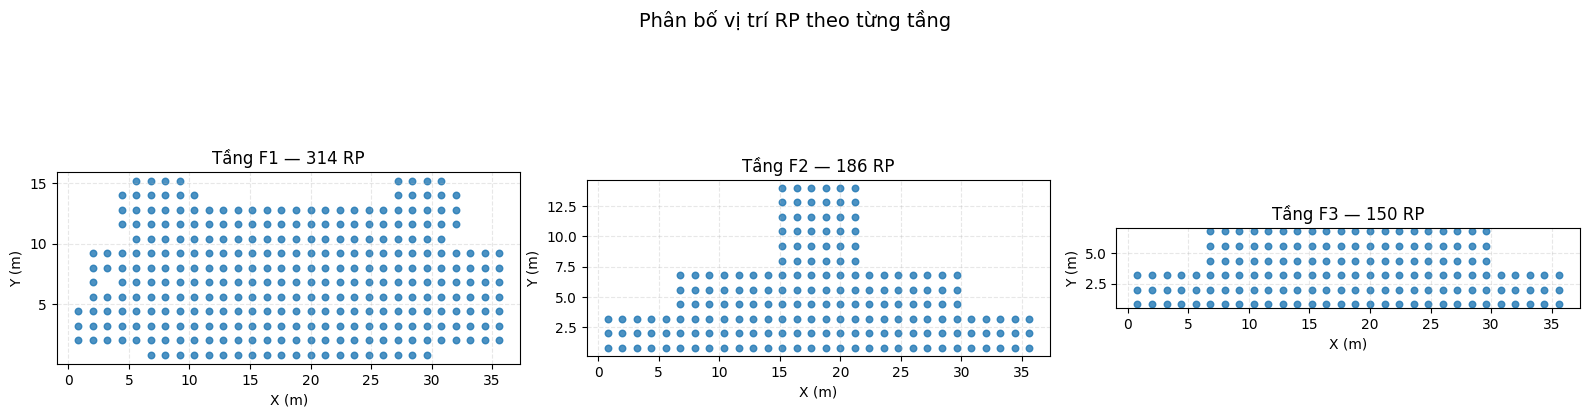

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("/content/DATASET_DLULIB")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, floor in zip(axes, ["F1", "F2", "F3"]):
    path = DATA_DIR / f"DLULIB_Train_{floor}.xlsx"
    df = pd.read_excel(path, sheet_name=f"Train_{floor}_2")

    coords = df[["X", "Y"]].dropna().drop_duplicates()

    ax.scatter(
        coords["X"], coords["Y"],
        s=22, alpha=0.8
    )
    ax.set_title(f"Tầng {floor} — {len(coords)} RP")
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, linestyle="--", alpha=0.3)

plt.suptitle("Phân bố vị trí RP theo từng tầng", fontsize=14)
plt.tight_layout()
plt.show()

### Cell 1.11 — Phân biệt RP đã khảo sát và tọa độ ứng viên

**Mục tiêu:** Trực quan hóa các RP hiện có và các tọa độ lưới chưa trùng với RP đã khảo sát.

**Quy ước:**
- Xanh dương: RP đã khảo sát.
- Đỏ: tọa độ ứng viên chưa có RP trong dữ liệu.

**Lưu ý:** Điểm màu đỏ chỉ là ứng viên theo lưới tọa độ, chưa được xác nhận là vị trí có thể khảo sát thực tế.

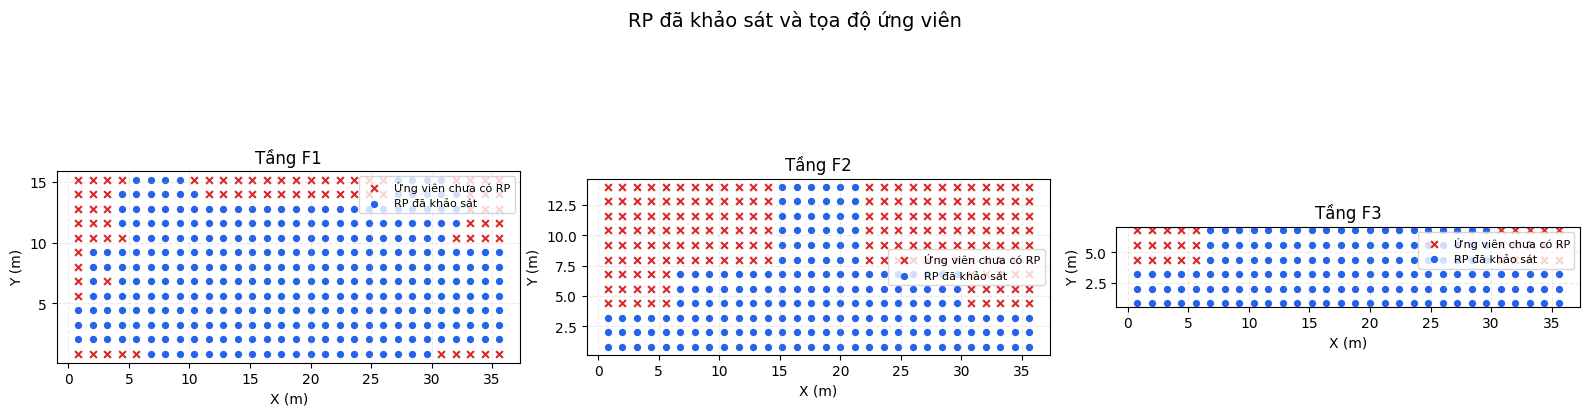

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("/content/DATASET_DLULIB")
STEP = 1.2

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, floor in zip(axes, ["F1", "F2", "F3"]):
    path = DATA_DIR / f"DLULIB_Train_{floor}.xlsx"
    df = pd.read_excel(path, sheet_name=f"Train_{floor}_2")

    coords = df[["X", "Y"]].dropna().drop_duplicates()
    known = set(map(tuple, np.round(coords.to_numpy(), 4)))

    xs = np.round(np.arange(
        coords["X"].min(), coords["X"].max() + STEP / 2, STEP
    ), 4)
    ys = np.round(np.arange(
        coords["Y"].min(), coords["Y"].max() + STEP / 2, STEP
    ), 4)

    grid = {(float(x), float(y)) for x in xs for y in ys}
    unseen = sorted(grid - known)

    if unseen:
        ux, uy = np.array(unseen).T
        ax.scatter(ux, uy, c="#DC2626", s=24,
                   marker="x", label="Ứng viên chưa có RP")

    ax.scatter(coords["X"], coords["Y"],
               c="#2563EB", s=18, label="RP đã khảo sát")

    ax.set_title(f"Tầng {floor}")
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, linestyle="--", alpha=0.25)
    ax.legend(fontsize=8)

plt.suptitle("RP đã khảo sát và tọa độ ứng viên", fontsize=14)
plt.tight_layout()
plt.show()

### Cell 1.12 — Xuất danh sách tọa độ ứng viên

**Mục tiêu:** Lưu tọa độ RP đã khảo sát và tọa độ lưới chưa trùng với RP hiện có theo từng tầng.

**Đầu ra:** Một file CSV chứa tầng, tọa độ X, Y và trạng thái của từng điểm.

**Lưu ý:** Trạng thái “ứng viên chưa có RP” chỉ có nghĩa là tọa độ chưa xuất hiện trong dữ liệu huấn luyện. Chưa xác nhận tính hợp lệ về mặt kiến trúc hoặc khả năng tiếp cận.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, HTML

DATA_DIR = Path("/content/DATASET_DLULIB")
OUTPUT_PATH = Path("/content/toa_do_RP_va_ung_vien.csv")
STEP = 1.2

all_points = []

for floor in ["F1", "F2", "F3"]:
    path = DATA_DIR / f"DLULIB_Train_{floor}.xlsx"
    df = pd.read_excel(path, sheet_name=f"Train_{floor}_2")

    coords = df[["X", "Y"]].dropna().drop_duplicates()
    known = set(map(tuple, np.round(coords.to_numpy(), 4)))

    xs = np.round(np.arange(
        coords["X"].min(), coords["X"].max() + STEP / 2, STEP
    ), 4)
    ys = np.round(np.arange(
        coords["Y"].min(), coords["Y"].max() + STEP / 2, STEP
    ), 4)

    grid = {(float(x), float(y)) for x in xs for y in ys}

    for x, y in sorted(grid):
        status = (
            "Da_khao_sat" if (x, y) in known
            else "Ung_vien_chua_co_RP"
        )
        all_points.append({
            "Floor": floor,
            "X": x,
            "Y": y,
            "Status": status
        })

points_df = pd.DataFrame(all_points)
points_df.to_csv(OUTPUT_PATH, index=False, encoding="utf-8-sig")

summary = points_df.groupby(["Floor", "Status"]).size().unstack(fill_value=0)

display(summary)

display(HTML(f"""
<div style="background:#E1F5E8;color:#166534;padding:12px 15px;
            border-radius:8px;border-left:5px solid #16A34A;
            margin:8px 0;font-family:Arial,sans-serif;">
  <b>✓ ĐÃ XUẤT DANH SÁCH TỌA ĐỘ</b><br>
  Tổng số điểm: {len(points_df)}<br>
  File: {OUTPUT_PATH}
</div>
"""))

display(points_df.head(10))

Status,Da_khao_sat,Ung_vien_chua_co_RP
Floor,,
F1,314,76
F2,186,174
F3,150,30


,Floor,X,Y,Status
0,F1,0.8,0.8,Ung_vien_chua_co_RP
1,F1,0.8,2.0,Da_khao_sat
2,F1,0.8,3.2,Da_khao_sat
3,F1,0.8,4.4,Da_khao_sat
4,F1,0.8,5.6,Ung_vien_chua_co_RP
5,F1,0.8,6.8,Ung_vien_chua_co_RP
6,F1,0.8,8.0,Ung_vien_chua_co_RP
7,F1,0.8,9.2,Ung_vien_chua_co_RP
8,F1,0.8,10.4,Ung_vien_chua_co_RP
9,F1,0.8,11.6,Ung_vien_chua_co_RP


### Cell 1.13 — Tái dựng phân bố RP và tọa độ ứng viên trong không gian 3D

**Mục tiêu:** Sử dụng tọa độ thực trong dataset để biểu diễn vị trí RP và các tọa độ ứng viên trên ba tầng F1, F2, F3.

**Quy ước:**
- 🔵 Chấm xanh: RP đã khảo sát.
- 🔴 Dấu X đỏ: tọa độ ứng viên chưa có RP trong dữ liệu.
- Trục X, Y: tọa độ thực tế từ dataset (m).
- Trục Z: thứ tự tầng quy ước để minh họa không gian 3D.

**Lưu ý:** Chưa có chiều cao kiến trúc thực tế nên khoảng cách Z chỉ mang tính minh họa. Mặt phẳng nền không đại diện cho tường hoặc khu vực có thể di chuyển.

<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

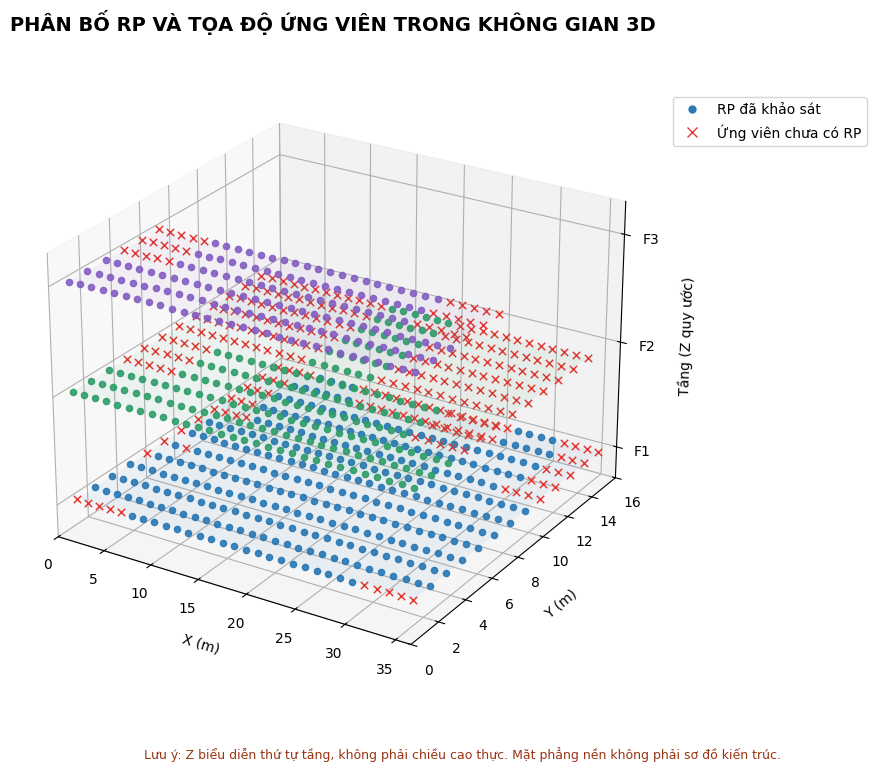

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, HTML

DATA_DIR = Path("/content/DATASET_DLULIB")
STEP = 1.2

FLOOR_Z = {"F1": 0, "F2": 1, "F3": 2}
FLOOR_COLORS = {
    "F1": "#2878B5",
    "F2": "#2E9D68",
    "F3": "#845EC2"
}

fig = plt.figure(figsize=(13, 8))
ax = fig.add_subplot(111, projection="3d")
summary = []

for floor in ["F1", "F2", "F3"]:
    path = DATA_DIR / f"DLULIB_Train_{floor}.xlsx"
    df = pd.read_excel(path, sheet_name=f"Train_{floor}_2")

    coords = df[["X", "Y"]].apply(
        pd.to_numeric, errors="coerce"
    ).dropna().drop_duplicates()

    known = set(map(tuple, np.round(coords.to_numpy(), 4)))

    xs = np.round(np.arange(
        coords["X"].min(),
        coords["X"].max() + STEP / 2, STEP
    ), 4)

    ys = np.round(np.arange(
        coords["Y"].min(),
        coords["Y"].max() + STEP / 2, STEP
    ), 4)

    grid = {(float(x), float(y)) for x in xs for y in ys}
    unseen = sorted(grid - known)
    z = FLOOR_Z[floor]
    color = FLOOR_COLORS[floor]

    # Mặt phẳng nền chỉ minh họa phạm vi X/Y
    xx, yy = np.meshgrid(
        [coords["X"].min(), coords["X"].max()],
        [coords["Y"].min(), coords["Y"].max()]
    )
    ax.plot_surface(
        xx, yy, np.full_like(xx, z, dtype=float),
        color=color, alpha=0.06, shade=False
    )

    # RP đã khảo sát
    ax.scatter(
        coords["X"], coords["Y"], np.full(len(coords), z),
        s=20, c=color, marker="o", alpha=0.9,
        depthshade=False
    )

    # Tọa độ ứng viên
    if unseen:
        ux, uy = np.array(unseen).T
        ax.scatter(
            ux, uy, np.full(len(unseen), z),
            s=28, c="#E53935", marker="x",
            linewidths=1.1, depthshade=False
        )

    summary.append({
        "Tầng": floor,
        "RP đã khảo sát": len(known),
        "Ứng viên chưa có RP": len(unseen),
        "Tổng điểm lưới": len(grid)
    })

ax.set_title(
    "PHÂN BỐ RP VÀ TỌA ĐỘ ỨNG VIÊN TRONG KHÔNG GIAN 3D",
    fontsize=14, fontweight="bold", pad=20
)

ax.set_xlabel("X (m)", labelpad=8)
ax.set_ylabel("Y (m)", labelpad=8)
ax.set_zlabel("Tầng (Z quy ước)", labelpad=8)

ax.set_zticks([0, 1, 2])
ax.set_zticklabels(["F1", "F2", "F3"])
ax.set_xlim(0, 36.5)
ax.set_ylim(0, 16)
ax.set_zlim(-0.3, 2.3)
ax.view_init(elev=25, azim=-58)
ax.grid(True, alpha=0.2)

# Chú giải ngắn, đặt ngoài vùng dữ liệu
legend_items = [
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="#2878B5", markersize=7,
           label="RP đã khảo sát"),
    Line2D([0], [0], marker="x", color="#E53935",
           linestyle="None", markersize=7,
           label="Ứng viên chưa có RP")
]
ax.legend(
    handles=legend_items,
    loc="upper left", bbox_to_anchor=(1.02, 0.95),
    frameon=True, fontsize=10
)

fig.text(
    0.5, 0.025,
    "Lưu ý: Z biểu diễn thứ tự tầng, không phải chiều cao thực. "
    "Mặt phẳng nền không phải sơ đồ kiến trúc.",
    ha="center", fontsize=9, color="#9A3412"
)

plt.subplots_adjust(left=0.02, right=0.78, top=0.90, bottom=0.10)

plt

### Cell 2.1 — Thiết kế thí nghiệm chia dữ liệu theo RP

**Mục tiêu:** Chia các vị trí RP thành tập huấn luyện và tập kiểm thử độc lập theo vị trí.

**Phương pháp:** Chia 80% RP cho huấn luyện và 20% RP cho kiểm thử, thực hiện riêng cho từng tầng.

**Nguyên tắc:**
- Tất cả 20 mẫu RSSI của cùng một RP phải nằm trong cùng một tập.
- Chỉ sử dụng RSSI của RP thuộc tập huấn luyện để huấn luyện mô hình.
- Giữ lại RSSI thật của RP kiểm thử để đánh giá khả năng sinh fingerprint tại vị trí bị loại khỏi huấn luyện.
- Không dùng tập kiểm thử để điều chỉnh mô hình.

**Lưu ý:** Đây là phép đánh giá mô phỏng vị trí chưa khảo sát. Tọa độ của RP kiểm thử vẫn được biết để làm điều kiện đánh giá; RSSI thật của chúng không được đưa vào huấn luyện.

In [ ]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split
from IPython.display import display, HTML

DATA_DIR = Path("/content/DATASET_DLULIB")
RANDOM_STATE = 42
TEST_SIZE = 0.20

splits = {}
summary = []

for floor in ["F1", "F2", "F3"]:
    path = DATA_DIR / f"DLULIB_Train_{floor}.xlsx"
    df = pd.read_excel(path, sheet_name=f"Train_{floor}_2")

    # Mỗi RP chỉ xuất hiện một lần trong danh sách chia
    rp_table = df[["ID_RP", "X", "Y"]].drop_duplicates()

    # Chia theo ID_RP, không chia ngẫu nhiên từng dòng RSSI
    train_ids, test_ids = train_test_split(
        rp_table["ID_RP"].unique(),
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE
    )

    train_ids = set(train_ids)
    test_ids = set(test_ids)

    train_df = df[df["ID_RP"].isin(train_ids)].copy()
    test_df = df[df["ID_RP"].isin(test_ids)].copy()

    # Kiểm tra không có RP giao nhau
    overlap = train_ids & test_ids

    splits[floor] = {
        "train_ids": train_ids,
        "test_ids": test_ids,
        "train_df": train_df,
        "test_df": test_df
    }

    summary.append({
        "Tầng": floor,
        "RP tổng": rp_table["ID_RP"].nunique(),
        "RP train": len(train_ids),
        "RP test": len(test_ids),
        "Mẫu train": len(train_df),
        "Mẫu test": len(test_df),
        "RP giao nhau": len(overlap)
    })

summary_df = pd.DataFrame(summary)

for _, row in summary_df.iterrows():
    good = row["RP giao nhau"] == 0

    bg = "#E1F5E8" if good else "#FCE7E7"
    fg = "#166534" if good else "#991B1B"
    status = "ĐẠT" if good else "LỖI"

    display(HTML(f"""
    <div style="background:{bg};color:{fg};padding:12px 15px;
                border-radius:8px;border-left:5px solid {fg};
                margin:6px 0;font-family:Arial,sans-serif;">
      <b>{status} — TẦNG {row['Tầng']}</b><br>
      RP train: {row['RP train']} | RP test: {row['RP test']}<br>
      Mẫu train: {row['Mẫu train']:,} | Mẫu test: {row['Mẫu test']:,}<br>
      RP xuất hiện ở cả hai tập: {row['RP giao nhau']}
    </div>
    """))

display(summary_df)

,Tầng,RP tổng,RP train,RP test,Mẫu train,Mẫu test,RP giao nhau
0,F1,314,251,63,5020,1260,0
1,F2,186,148,38,2960,760,0
2,F3,150,120,30,2400,600,0


### Cell 2.2 — Kiểm tra giá trị RSSI và chuẩn bị chuẩn hóa

**Mục tiêu:**
- Thống kê các giá trị RSSI trong tập train của từng tầng.
- Kiểm tra số lượng giá trị `-100`, giá trị thiếu và các giá trị ngoài miền RSSI dự kiến.
- Chưa thay đổi dữ liệu hoặc thực hiện chuẩn hóa.

**Nguyên tắc:** Thống kê chỉ được thực hiện trên tập train. Tập test sẽ được giữ riêng để đánh giá sau này.

In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display, HTML

AP = [f"AP{i}" for i in range(1, 18)]
results = []

for floor in ["F1", "F2", "F3"]:
    train_df = splits[floor]["train_df"]

    rssi = train_df[AP].apply(
        pd.to_numeric, errors="coerce"
    ).to_numpy(dtype=float)

    finite = np.isfinite(rssi)

    row = {
        "Tầng": floor,
        "Số mẫu train": len(train_df),
        "Ô RSSI": rssi.size,
        "Giá trị thiếu": int((~finite).sum()),
        "RSSI = -100": int((rssi == -100).sum()),
        "RSSI > -100": int((finite & (rssi > -100)).sum()),
        "RSSI >= 0": int((finite & (rssi >= 0)).sum()),
        "RSSI < -100": int((finite & (rssi < -100)).sum())
    }
    results.append(row)

    issues = (
        row["Giá trị thiếu"] > 0
        or row["RSSI >= 0"] > 0
        or row["RSSI < -100"] > 0
    )

    bg = "#FFF4D6" if issues else "#E1F5E8"
    fg = "#92400E" if issues else "#166534"
    status = "CẦN XÁC MINH" if issues else "ĐẠT"

    display(HTML(f"""
    <div style="background:{bg};color:{fg};padding:12px 15px;
                border-radius:8px;border-left:5px solid {fg};
                margin:6px 0;font-family:Arial,sans-serif;">
      <b>{status} — TẦNG {floor}</b><br>
      Mẫu train: {row['Số mẫu train']:,}<br>
      RSSI = -100: {row['RSSI = -100']:,} |
      RSSI > -100: {row['RSSI > -100']:,}<br>
      Giá trị thiếu: {row['Giá trị thiếu']} |
      RSSI >= 0: {row['RSSI >= 0']} |
      RSSI < -100: {row['RSSI < -100']}
    </div>
    """))

display(pd.DataFrame(results))

,Tầng,Số mẫu train,Ô RSSI,Giá trị thiếu,RSSI = -100,RSSI > -100,RSSI >= 0,RSSI < -100
0,F1,5020,85340,0,32809,52531,0,0
1,F2,2960,50320,0,18554,31766,0,0
2,F3,2400,40800,0,21244,19556,0,0


### Cell 2.3 — Chuẩn hóa RSSI và tạo mặt nạ AP

**Mục tiêu:**
- Chuẩn hóa RSSI từ miền `[-100, -20]` về `[0, 1]`.
- Tạo mặt nạ phát hiện AP: `1` nếu RSSI lớn hơn `-100`, `0` nếu RSSI bằng `-100`.
- Giữ nguyên cấu trúc chia train/test theo RP.

**Quy ước tạm thời:** Giá trị RSSI nhỏ hơn hoặc bằng `-100` được xem là không phát hiện AP. Miền chuẩn hóa `[-100, -20]` là miền kỹ thuật ban đầu, cần xác minh và chỉ dùng nếu phù hợp với tài liệu dữ liệu.

**Lưu ý:** Chưa huấn luyện mô hình và chưa dùng tập test để điều chỉnh tham số.

In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display, HTML

AP = [f"AP{i}" for i in range(1, 18)]

RSSI_MIN = -100.0
RSSI_MAX = -20.0

prepared = {}

for floor in ["F1", "F2", "F3"]:
    train_df = splits[floor]["train_df"].copy()
    test_df = splits[floor]["test_df"].copy()

    train_rssi = train_df[AP].to_numpy(dtype=float)
    test_rssi = test_df[AP].to_numpy(dtype=float)

    # 1 = AP được phát hiện; 0 = không phát hiện AP
    train_mask = (train_rssi > -100).astype(np.float32)
    test_mask = (test_rssi > -100).astype(np.float32)

    # Chuẩn hóa RSSI về [0, 1]
    # Giá trị -100 được ánh xạ thành 0 nhưng vẫn có mask riêng.
    train_norm = np.clip(
        (train_rssi - RSSI_MIN) / (RSSI_MAX - RSSI_MIN),
        0, 1
    ).astype(np.float32)

    test_norm = np.clip(
        (test_rssi - RSSI_MIN) / (RSSI_MAX - RSSI_MIN),
        0, 1
    ).astype(np.float32)

    prepared[floor] = {
        "train_df": train_df,
        "test_df": test_df,
        "train_rssi": train_rssi,
        "test_rssi": test_rssi,
        "train_mask": train_mask,
        "test_mask": test_mask,
        "train_norm": train_norm,
        "test_norm": test_norm
    }

    valid = train_mask == 1
    good = (
        np.isfinite(train_norm).all()
        and train_norm.min() >= 0
        and train_norm.max() <= 1
    )

    bg = "#E1F5E8" if good else "#FCE7E7"
    fg = "#166534" if good else "#991B1B"

    display(HTML(f"""
    <div style="background:{bg};color:{fg};padding:12px 15px;
                border-radius:8px;border-left:5px solid {fg};
                margin:6px 0;font-family:Arial,sans-serif;">
      <b>{'✓' if good else '✕'} TẦNG {floor}</b><br>
      Shape RSSI chuẩn hóa: {train_norm.shape}<br>
      Shape mặt nạ AP: {train_mask.shape}<br>
      Miền RSSI chuẩn hóa: [{train_norm.min():.3f}, {train_norm.max():.3f}]<br>
      Tỷ lệ AP được phát hiện: {valid.mean() * 100:.2f}%
    </div>
    """))

### Cell 2.4 — Kiểm tra điều kiện tọa độ và trạng thái phát hiện AP

**Mục tiêu:**
- Kiểm tra tọa độ `(X,Y)` trong tập train có đầy đủ hay không.
- Thống kê số AP được phát hiện tại mỗi RP.
- Xác định các RP có số AP được phát hiện thấp.

**Ý nghĩa:** Chuẩn bị điều kiện tọa độ và nhãn phát hiện AP cho mô hình cGAN.

**Lưu ý:** Chỉ dùng tập train. Chưa loại bỏ RP hoặc thay đổi dữ liệu.

In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display, HTML

AP = [f"AP{i}" for i in range(1, 18)]
results = []

for floor in ["F1", "F2", "F3"]:
    train_df = prepared[floor]["train_df"]

    coords = train_df[["X", "Y"]].apply(
        pd.to_numeric, errors="coerce"
    )
    mask = prepared[floor]["train_mask"]

    ap_count = mask.sum(axis=1)

    rp_stats = pd.DataFrame({
        "ID_RP": train_df["ID_RP"].to_numpy(),
        "AP_detected": ap_count
    }).groupby("ID_RP")["AP_detected"].mean()

    row = {
        "Tầng": floor,
        "Thiếu tọa độ": int(coords.isna().any(axis=1).sum()),
        "RP train": train_df["ID_RP"].nunique(),
        "AP phát hiện TB/mẫu": float(ap_count.mean()),
        "AP phát hiện TB/RP": float(rp_stats.mean()),
        "RP có trung bình dưới 5 AP": int((rp_stats < 5).sum()),
        "RP có trung bình dưới 8 AP": int((rp_stats < 8).sum())
    }
    results.append(row)

    good = row["Thiếu tọa độ"] == 0
    bg = "#E1F5E8" if good else "#FCE7E7"
    fg = "#166534" if good else "#991B1B"

    display(HTML(f"""
    <div style="background:{bg};color:{fg};padding:12px 15px;
                border-radius:8px;border-left:5px solid {fg};
                margin:6px 0;font-family:Arial,sans-serif;">
      <b>{'✓' if good else '✕'} TẦNG {floor}</b><br>
      Thiếu tọa độ: {row['Thiếu tọa độ']}<br>
      AP phát hiện trung bình/mẫu: {row['AP phát hiện TB/mẫu']:.2f}/17<br>
      RP có trung bình dưới 5 AP: {row['RP có trung bình dưới 5 AP']}<br>
      RP có trung bình dưới 8 AP: {row['RP có trung bình dưới 8 AP']}
    </div>
    """))

display(pd.DataFrame(results).round(3))

,Tầng,Thiếu tọa độ,RP train,AP phát hiện TB/mẫu,AP phát hiện TB/RP,RP có trung bình dưới 5 AP,RP có trung bình dưới 8 AP
0,F1,0,251,10.464,10.464,0,18
1,F2,0,148,10.732,10.732,0,8
2,F3,0,120,8.148,8.148,3,61


### Cell 2.5 — Kiểm tra mẫu RSSI theo từng RP

**Mục tiêu:**
- Kiểm tra số mẫu tại mỗi RP trong tập train.
- Xác nhận mỗi RP có duy nhất một cặp tọa độ `(X, Y)`.
- Thống kê số RP có số mẫu khác với kỳ vọng 20.

**Ý nghĩa:** Xác nhận dữ liệu điều kiện của generator đã sẵn sàng cho bước xây dựng mô hình.

**Nguyên tắc:** Không xóa RP và không sử dụng dữ liệu test để điều chỉnh mô hình.

In [ ]:
import pandas as pd
from IPython.display import display, HTML

results = []

for floor in ["F1", "F2", "F3"]:
    df = prepared[floor]["train_df"]

    samples_per_rp = df.groupby("ID_RP").size()
    coords_per_rp = df.groupby("ID_RP")[["X", "Y"]].nunique()

    bad_samples = int((samples_per_rp != 20).sum())
    bad_coords = int((coords_per_rp > 1).any(axis=1).sum())

    results.append({
        "Tầng": floor,
        "RP train": len(samples_per_rp),
        "Mẫu/RP nhỏ nhất": int(samples_per_rp.min()),
        "Mẫu/RP lớn nhất": int(samples_per_rp.max()),
        "RP không đủ 20 mẫu": bad_samples,
        "RP lệch tọa độ": bad_coords
    })

    passed = bad_samples == 0 and bad_coords == 0
    bg = "#E1F5E8" if passed else "#FCE7E7"
    fg = "#166534" if passed else "#991B1B"

    display(HTML(f"""
    <div style="background:{bg};color:{fg};padding:12px 15px;
                border-radius:8px;border-left:5px solid {fg};
                margin:6px 0;font-family:Arial,sans-serif;">
      <b>{'✓ ĐẠT' if passed else '✕ CẦN KIỂM TRA'} — TẦNG {floor}</b><br>
      RP train: {len(samples_per_rp)}<br>
      Số mẫu/RP: {samples_per_rp.min()}–{samples_per_rp.max()}<br>
      RP không đủ 20 mẫu: {bad_samples}<br>
      RP lệch tọa độ: {bad_coords}
    </div>
    """))

display(pd.DataFrame(results))

,Tầng,RP train,Mẫu/RP nhỏ nhất,Mẫu/RP lớn nhất,RP không đủ 20 mẫu,RP lệch tọa độ
0,F1,251,20,20,0,0
1,F2,148,20,20,0,0
2,F3,120,20,20,0,0


### Cell 2.6 — Chuẩn bị đầu vào cho cGAN

**Mục tiêu:**
- Tạo ma trận tọa độ điều kiện `(X, Y)`.
- Kiểm tra hình dạng và miền tọa độ.
- Giữ dữ liệu RSSI chuẩn hóa và mặt nạ phát hiện AP riêng biệt.

**Thiết kế dự kiến:** Generator nhận tọa độ và nhiễu ngẫu nhiên, dự đoán trạng thái phát hiện AP và RSSI. Discriminator đánh giá tính chân thực của fingerprint trong điều kiện tọa độ tương ứng.

**Nguyên tắc:** Chỉ sử dụng dữ liệu train để chuẩn bị huấn luyện; tập test vẫn được giữ riêng để đánh giá cuối cùng.

In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display, HTML

condition_data = {}

for floor in ["F1", "F2", "F3"]:
    item = prepared[floor]
    train_df = item["train_df"]

    # Tọa độ điều kiện
    coords = train_df[["X", "Y"]].to_numpy(dtype=np.float32)

    # RSSI chuẩn hóa và trạng thái AP
    rssi = item["train_norm"]
    mask = item["train_mask"]

    # Kiểm tra dữ liệu
    assert coords.shape == (len(train_df), 2)
    assert rssi.shape == (len(train_df), 17)
    assert mask.shape == (len(train_df), 17)
    assert np.isfinite(coords).all()
    assert np.isfinite(rssi).all()
    assert np.isfinite(mask).all()

    condition_data[floor] = {
        "coords": coords,
        "rssi": rssi,
        "mask": mask
    }

    display(HTML(f"""
    <div style="background:#E1F5E8;color:#166534;padding:12px 15px;
                border-radius:8px;border-left:5px solid #16A34A;
                margin:6px 0;font-family:Arial,sans-serif;">
      <b>✓ TẦNG {floor}</b><br>
      Tọa độ: {coords.shape}<br>
      RSSI: {rssi.shape}<br>
      Mặt nạ AP: {mask.shape}<br>
      X: {coords[:, 0].min():.2f} đến {coords[:, 0].max():.2f} m<br>
      Y: {coords[:, 1].min():.2f} đến {coords[:, 1].max():.2f} m
    </div>
    """))

### Cell 2.7 — Phân tích mức độ phát hiện của từng AP

**Mục tiêu:**
- Tính số mẫu và tỷ lệ phát hiện của từng AP trên mỗi tầng.
- Xác định AP có tỷ lệ phát hiện thấp.
- Làm cơ sở lựa chọn hàm loss cho hai nhiệm vụ: dự đoán trạng thái phát hiện AP và dự đoán RSSI khi AP được phát hiện.

**Lưu ý:** Thống kê chỉ sử dụng tập train. Tỷ lệ phát hiện thấp không đồng nghĩa AP đó phải bị loại bỏ.

,AP,Số mẫu phát hiện,Tổng mẫu train,Tỷ lệ phát hiện (%)
0,AP1,4506,5020,89.760002
1,AP2,3891,5020,77.510002
2,AP3,4928,5020,98.169998
3,AP4,4043,5020,80.540001
4,AP5,4169,5020,83.050003
5,AP6,4727,5020,94.160004
6,AP7,4828,5020,96.180000
7,AP8,3730,5020,74.300003
8,AP9,542,5020,10.800000
9,AP10,4057,5020,80.820000


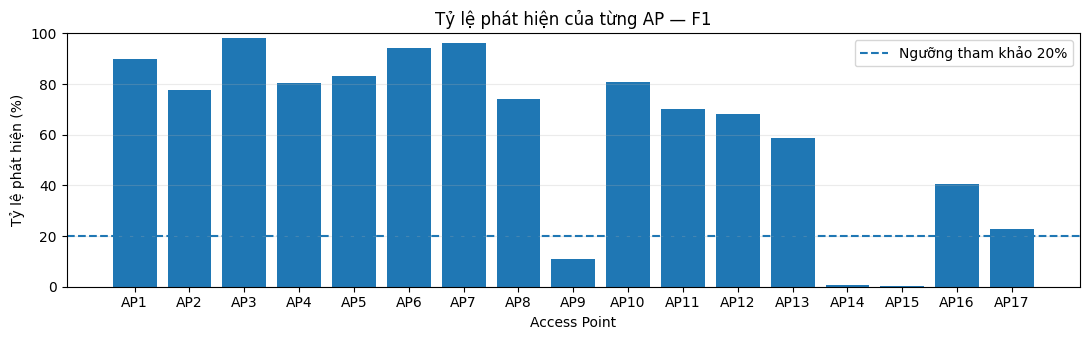

,AP,Số mẫu phát hiện,Tổng mẫu train,Tỷ lệ phát hiện (%)
0,AP1,1912,2960,64.589996
1,AP2,1818,2960,61.419998
2,AP3,1990,2960,67.230003
3,AP4,1777,2960,60.029999
4,AP5,1974,2960,66.690002
5,AP6,1881,2960,63.549999
6,AP7,2293,2960,77.470001
7,AP8,2333,2960,78.820000
8,AP9,1043,2960,35.240002
9,AP10,2464,2960,83.239998


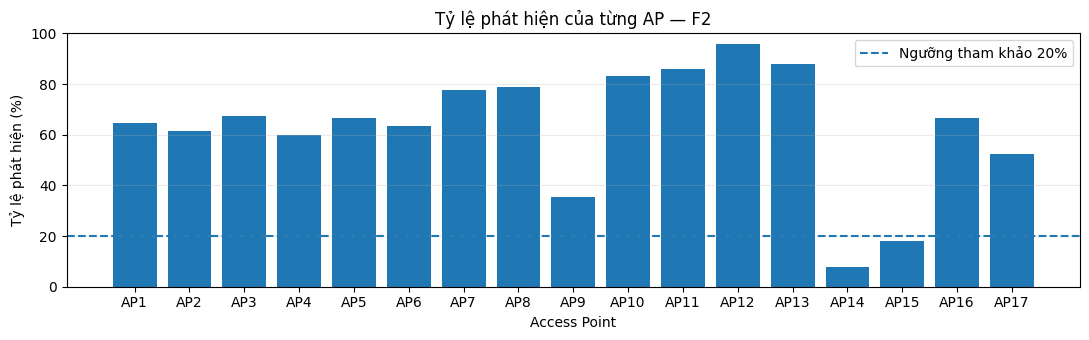

,AP,Số mẫu phát hiện,Tổng mẫu train,Tỷ lệ phát hiện (%)
0,AP1,899,2400,37.459999
1,AP2,1077,2400,44.880001
2,AP3,1018,2400,42.419998
3,AP4,1014,2400,42.250000
4,AP5,1421,2400,59.209999
5,AP6,816,2400,34.000000
6,AP7,869,2400,36.209999
7,AP8,1530,2400,63.750000
8,AP9,408,2400,17.000000
9,AP10,1302,2400,54.250000


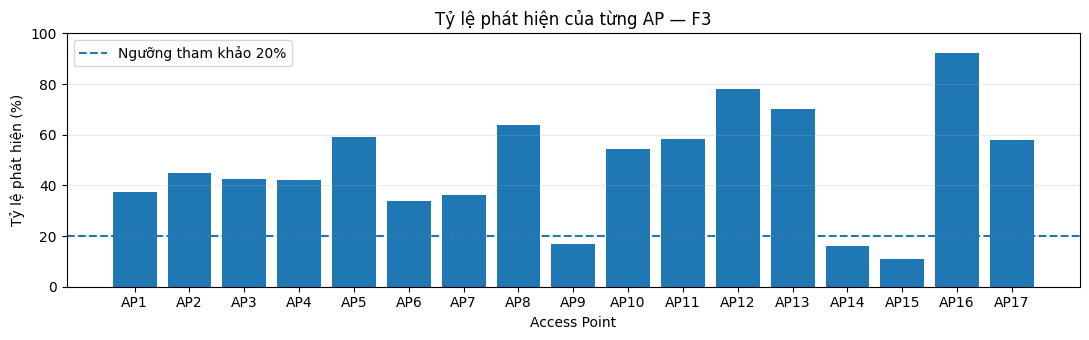

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ap_stats = {}

for floor in ["F1", "F2", "F3"]:
    mask = condition_data[floor]["mask"]
    ap_names = [f"AP{i}" for i in range(1, 18)]

    detected = mask.sum(axis=0)
    total = mask.shape[0]
    rate = detected / total * 100

    stats = pd.DataFrame({
        "AP": ap_names,
        "Số mẫu phát hiện": detected.astype(int),
        "Tổng mẫu train": total,
        "Tỷ lệ phát hiện (%)": rate.round(2)
    })

    ap_stats[floor] = stats

    low_count = int((rate < 20).sum())

    display(HTML(f"""
    <div style="background:#EAF2FF;color:#1D4ED8;padding:12px 15px;
                border-radius:8px;border-left:5px solid #2563EB;
                margin:8px 0;font-family:Arial,sans-serif;">
      <b>THỐNG KÊ AP — TẦNG {floor}</b><br>
      Số AP: {len(ap_names)}<br>
      Tỷ lệ phát hiện trung bình: {rate.mean():.2f}%<br>
      AP có tỷ lệ phát hiện dưới 20%: {low_count}
    </div>
    """))

    display(stats)

    plt.figure(figsize=(11, 3.5))
    plt.bar(ap_names, rate)
    plt.axhline(20, linestyle="--", label="Ngưỡng tham khảo 20%")
    plt.title(f"Tỷ lệ phát hiện của từng AP — {floor}")
    plt.xlabel("Access Point")
    plt.ylabel("Tỷ lệ phát hiện (%)")
    plt.ylim(0, 100)
    plt.grid(axis="y", alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

### Cell 2.8 — Xác minh biểu diễn RSSI và mặt nạ AP

**Mục tiêu:**
1. Xác nhận quy tắc chuyển RSSI thành mặt nạ phát hiện AP.
2. Kiểm tra miền RSSI của những AP được phát hiện.
3. Xác minh tính nhất quán giữa RSSI gốc, RSSI chuẩn hóa và mặt nạ.

**Quy ước hiện tại:** `-100 dBm` được xem là mã không phát hiện AP; mọi giá trị RSSI lớn hơn `-100 dBm` được xem là đã phát hiện. Quy ước này cần được đối chiếu với tài liệu mô tả dataset nếu có.

In [ ]:
import numpy as np
from IPython.display import display, HTML

for floor in ["F1", "F2", "F3"]:
    item = prepared[floor]

    raw = np.asarray(item["train_rssi"], dtype=np.float32)
    norm = np.asarray(item["train_norm"], dtype=np.float32)
    mask = np.asarray(item["train_mask"], dtype=np.float32)

    # Kiểm tra quy ước phát hiện AP
    expected_mask = (raw > -100).astype(np.float32)
    mask_errors = int(np.sum(mask != expected_mask))

    # RSSI chuẩn hóa phải khớp với công thức đã chọn
    expected_norm = np.clip((raw + 100) / 80, 0, 1)
    norm_max_error = float(np.max(np.abs(norm - expected_norm)))

    detected_values = raw[expected_mask == 1]
    undetected_values = raw[expected_mask == 0]

    passed = (
        mask_errors == 0
        and norm_max_error < 1e-5
        and np.isfinite(norm).all()
    )

    bg = "#E1F5E8" if passed else "#FCE7E7"
    fg = "#166534" if passed else "#991B1B"

    display(HTML(f"""
    <div style="background:{bg};color:{fg};padding:13px 16px;
                border-radius:8px;border-left:5px solid {fg};
                margin:8px 0;font-family:Arial,sans-serif;">
      <b>{'✓ KIỂM TRA ĐẠT' if passed else '✕ CẦN KIỂM TRA'} — {floor}</b><br>
      Số ô mask không khớp: {mask_errors}<br>
      Sai lệch chuẩn hóa lớn nhất: {norm_max_error:.8f}<br>
      Số ô AP được phát hiện: {len(detected_values):,}<br>
      RSSI phát hiện: {detected_values.min():.1f} đến
      {detected_values.max():.1f} dBm<br>
      Số ô AP không phát hiện: {len(undetected_values):,}<br>
      Giá trị không phát hiện duy nhất:
      {np.unique(undetected_values).tolist()}
    </div>
    """))

### Cell 2.9 — Tổng hợp dữ liệu đầu vào cho cGAN

**Mục tiêu:**
- Xác nhận số lượng mẫu train và số chiều đầu vào của từng tầng.
- Xác nhận số AP, số RP và số tọa độ điều kiện.
- Kiểm tra dữ liệu đã sẵn sàng cho bước xây dựng mô hình.

**Quy ước mô hình dự kiến:**
- Điều kiện: tọa độ `(X, Y)`.
- Nhiễu ngẫu nhiên: vector `z`.
- Đầu ra Generator: xác suất phát hiện 17 AP và RSSI tương ứng.
- Discriminator: đánh giá tính chân thực của fingerprint khi kết hợp với tọa độ.

**Lưu ý:** Đây là kiểm tra cấu trúc dữ liệu, chưa phải huấn luyện hay đánh giá hiệu quả cGAN.

In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display, HTML

summary = []

for floor in ["F1", "F2", "F3"]:
    item = prepared[floor]
    cond = condition_data[floor]

    n_samples = len(cond["coords"])
    n_rp = item["train_df"]["ID_RP"].nunique()
    n_aps = cond["rssi"].shape[1]

    checks = {
        "Tọa độ đúng 2 chiều": cond["coords"].shape == (n_samples, 2),
        "RSSI đúng 17 AP": cond["rssi"].shape == (n_samples, 17),
        "Mask đúng 17 AP": cond["mask"].shape == (n_samples, 17),
        "Dữ liệu hữu hạn": (
            np.isfinite(cond["coords"]).all()
            and np.isfinite(cond["rssi"]).all()
            and np.isfinite(cond["mask"]).all()
        ),
        "Đủ 20 mẫu mỗi RP": (
            item["train_df"].groupby("ID_RP").size().eq(20).all()
        )
    }

    passed = all(checks.values())

    summary.append({
        "Tầng": floor,
        "Mẫu train": n_samples,
        "RP train": n_rp,
        "Số AP": n_aps,
        "Số chiều tọa độ": cond["coords"].shape[1],
        "Kiểm tra": "ĐẠT" if passed else "CẦN KIỂM TRA"
    })

    bg = "#E1F5E8" if passed else "#FCE7E7"
    fg = "#166534" if passed else "#991B1B"
    details = "<br>".join(
        f"{'✓' if ok else '✕'} {name}" for name, ok in checks.items()
    )

    display(HTML(f"""
    <div style="background:{bg};color:{fg};padding:12px 15px;
                border-radius:8px;border-left:5px solid {fg};
                margin:6px 0;font-family:Arial,sans-serif;">
      <b>{'✓ SẴN SÀNG' if passed else '✕ CHƯA SẴN SÀNG'} — {floor}</b><br>
      {details}
    </div>
    """))

display(pd.DataFrame(summary))

,Tầng,Mẫu train,RP train,Số AP,Số chiều tọa độ,Kiểm tra
0,F1,5020,251,17,2,ĐẠT
1,F2,2960,148,17,2,ĐẠT
2,F3,2400,120,17,2,ĐẠT


### Cell 3.1 — Xây dựng Generator và Discriminator cho cGAN

**Đầu vào Generator**
- Tọa độ điều kiện: `(X, Y)`, 2 chiều.
- Nhiễu ngẫu nhiên `z`: 16 chiều.

**Đầu ra Generator**
- `mask_logits`: 17 giá trị biểu diễn trạng thái phát hiện AP dưới dạng logits.
- `rssi_norm`: 17 giá trị RSSI chuẩn hóa trong `[0, 1]`.

**Đầu vào Discriminator**
- Tọa độ: 2 chiều.
- Mặt nạ AP: 17 chiều.
- RSSI chuẩn hóa: 17 chiều.

**Đầu ra Discriminator:** một điểm số cho mỗi fingerprint.

Cell này định nghĩa kiến trúc và kiểm tra kích thước đầu ra. Chưa huấn luyện mô hình.

In [ ]:

import torch
import torch.nn as nn
import pandas as pd
from IPython.display import display, HTML

# 1. Cấu hình
SEED = 42
LATENT_DIM = 16
COORD_DIM = 2
N_AP = 17
HIDDEN_DIM = 128

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# 2. Generator
class Generator(nn.Module):
    def __init__(self):
        super().__init__()

        self.backbone = nn.Sequential(
            nn.Linear(COORD_DIM + LATENT_DIM, HIDDEN_DIM),
            nn.LeakyReLU(0.2),

            nn.Linear(HIDDEN_DIM, HIDDEN_DIM),
            nn.BatchNorm1d(HIDDEN_DIM),
            nn.LeakyReLU(0.2),

            nn.Linear(HIDDEN_DIM, HIDDEN_DIM),
            nn.BatchNorm1d(HIDDEN_DIM),
            nn.LeakyReLU(0.2)
        )

        self.mask_head = nn.Linear(HIDDEN_DIM, N_AP)

        self.rssi_head = nn.Sequential(
            nn.Linear(HIDDEN_DIM, N_AP),
            nn.Sigmoid()
        )

    def forward(self, coords, noise):
        x = torch.cat([coords, noise], dim=1)
        features = self.backbone(x)

        mask_logits = self.mask_head(features)
        rssi_norm = self.rssi_head(features)

        return mask_logits, rssi_norm


# 3. Discriminator
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        input_dim = COORD_DIM + 2 * N_AP

        self.network = nn.Sequential(
            nn.Linear(input_dim, HIDDEN_DIM),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.2),

            nn.Linear(HIDDEN_DIM, HIDDEN_DIM),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.2),

            nn.Linear(HIDDEN_DIM, 1)
        )

    def forward(self, coords, mask, rssi_norm):
        x = torch.cat([coords, mask, rssi_norm], dim=1)
        return self.network(x)


# 4. Khởi tạo mô hình riêng cho mỗi tầng
models = {}

for floor in ["F1", "F2", "F3"]:
    models[floor] = {
        "G": Generator().to(DEVICE),
        "D": Discriminator().to(DEVICE)
    }


# 5. Kiểm tra đầu ra, dùng dữ liệu train
results = []

for floor in ["F1", "F2", "F3"]:
    coords_np = condition_data[floor]["coords"][:8]

    coords = torch.as_tensor(
        coords_np,
        dtype=torch.float32,
        device=DEVICE
    )

    noise = torch.randn(8, LATENT_DIM, device=DEVICE)

    G = models[floor]["G"]
    D = models[floor]["D"]

    G.eval()
    D.eval()

    with torch.no_grad():
        mask_logits, rssi_fake = G(coords, noise)
        mask_prob = torch.sigmoid(mask_logits)
        score = D(coords, mask_prob, rssi_fake)

    passed = (
        mask_logits.shape == (8, 17)
        and rssi_fake.shape == (8, 17)
        and score.shape == (8, 1)
        and torch.isfinite(mask_logits).all().item()
        and torch.isfinite(rssi_fake).all().item()
        and ((rssi_fake >= 0) & (rssi_fake <= 1)).all().item()
    )

    results.append({
        "Tầng": floor,
        "Mask logits": str(tuple(mask_logits.shape)),
        "RSSI sinh": str(tuple(rssi_fake.shape)),
        "Điểm D": str(tuple(score.shape)),
        "Trạng thái": "ĐẠT" if passed else "CẦN KIỂM TRA"
    })

    color = "#166534" if passed else "#991B1B"
    bg = "#E1F5E8" if passed else "#FCE7E7"

    display(HTML(f"""
    <div style="background:{bg};color:{color};padding:12px 15px;
                border-left:5px solid {color};border-radius:8px;
                margin:6px 0;font-family:Arial,sans-serif;">
      <b>{'✓' if passed else '✕'} {floor}</b><br>
      Mask logits: {tuple(mask_logits.shape)}<br>
      RSSI sinh: {tuple(rssi_fake.shape)}<br>
      Điểm Discriminator: {tuple(score.shape)}
    </div>
    """))

    G.train()
    D.train()

display(pd.DataFrame(results))
print("Thiết bị:", DEVICE)
print("Chưa huấn luyện — trọng số đang ở trạng thái khởi tạo.")


,Tầng,Mask logits,RSSI sinh,Điểm D,Trạng thái
0,F1,"(8, 17)","(8, 17)","(8, 1)",ĐẠT
1,F2,"(8, 17)","(8, 17)","(8, 1)",ĐẠT
2,F3,"(8, 17)","(8, 17)","(8, 1)",ĐẠT


Thiết bị: cpu
Chưa huấn luyện — trọng số đang ở trạng thái khởi tạo.


### Cell 3.2 — Định nghĩa các hàm loss cho cGAN

**Mục tiêu**
- Tính loss dự đoán trạng thái phát hiện AP bằng BCE.
- Tính sai số RSSI chỉ trên các AP được phát hiện trong mẫu thật.
- Kiểm tra loss có giá trị hữu hạn và có thể tính gradient.

**Lưu ý**
- `mask` thật được tạo từ RSSI gốc: `1` nếu RSSI lớn hơn `-100 dBm`, ngược lại là `0`.
- Cell này chỉ kiểm tra hàm loss trên một batch dữ liệu train; chưa cập nhật trọng số và không sử dụng tập test để huấn luyện.

In [ ]:
import torch
import torch.nn as nn
from IPython.display import display, HTML

bce_loss = nn.BCEWithLogitsLoss()


def detection_loss(mask_logits, mask_true):
    """Loss dự đoán trạng thái phát hiện AP."""
    return bce_loss(mask_logits, mask_true)


def masked_rssi_mae(rssi_pred, rssi_true, mask_true):
    """MAE RSSI chỉ trên những AP được phát hiện trong mẫu thật."""
    abs_error = torch.abs(rssi_pred - rssi_true) * mask_true
    denominator = mask_true.sum().clamp_min(1.0)
    return abs_error.sum() / denominator


# Kiểm tra loss bằng batch train, không dùng test
loss_results = []

for floor in ["F1", "F2", "F3"]:
    data = condition_data[floor]

    coords = torch.as_tensor(
        data["coords"][:32], dtype=torch.float32, device=DEVICE
    )
    rssi_true = torch.as_tensor(
        data["rssi"][:32], dtype=torch.float32, device=DEVICE
    )
    mask_true = torch.as_tensor(
        data["mask"][:32], dtype=torch.float32, device=DEVICE
    )
    noise = torch.randn(32, LATENT_DIM, device=DEVICE)

    G = models[floor]["G"]
    G.train()
    G.zero_grad(set_to_none=True)

    mask_logits, rssi_pred = G(coords, noise)

    loss_mask = detection_loss(mask_logits, mask_true)
    loss_rssi = masked_rssi_mae(rssi_pred, rssi_true, mask_true)

    # Chỉ kiểm tra gradient của hai loss giám sát
    loss_total = loss_mask + loss_rssi
    loss_total.backward()

    grad_exists = any(
        p.grad is not None and torch.isfinite(p.grad).all().item()
        for p in G.parameters()
    )

    passed = (
        torch.isfinite(loss_mask).item()
        and torch.isfinite(loss_rssi).item()
        and grad_exists
    )

    loss_results.append({
        "Tầng": floor,
        "Loss mask (BCE)": round(loss_mask.item(), 4),
        "Loss RSSI (MAE chuẩn hóa)": round(loss_rssi.item(), 4),
        "Gradient": "Có" if grad_exists else "Không",
        "Trạng thái": "ĐẠT" if passed else "CẦN KIỂM TRA"
    })

    color = "#166534" if passed else "#991B1B"
    bg = "#E1F5E8" if passed else "#FCE7E7"

    display(HTML(f"""
    <div style="background:{bg};color:{color};padding:12px 15px;
                border-left:5px solid {color};border-radius:8px;
                margin:6px 0;font-family:Arial,sans-serif;">
      <b>{'✓' if passed else '✕'} {floor}</b><br>
      Loss mask: {loss_mask.item():.4f}<br>
      Loss RSSI: {loss_rssi.item():.4f}<br>
      Gradient hữu hạn: {grad_exists}
    </div>
    """))

    G.zero_grad(set_to_none=True)

display(__import__("pandas").DataFrame(loss_results))
print("Chưa cập nhật trọng số; chưa huấn luyện cGAN.")

,Tầng,Loss mask (BCE),Loss RSSI (MAE chuẩn hóa),Gradient,Trạng thái
0,F1,0.7198,0.1500,Có,ĐẠT
1,F2,0.7325,0.1749,Có,ĐẠT
2,F3,0.7171,0.2066,Có,ĐẠT


Chưa cập nhật trọng số; chưa huấn luyện cGAN.


### Cell 3.3 — Định nghĩa loss đối kháng cho cGAN

**Mục tiêu**
- Xây dựng loss cho Discriminator khi phân biệt fingerprint thật và giả.
- Xây dựng loss đối kháng cho Generator.
- Kiểm tra các loss có giá trị hữu hạn và có thể tính gradient.

**Quy ước**
- Discriminator nhận tọa độ, mask và RSSI chuẩn hóa.
- Fingerprint thật dùng mask và RSSI từ dữ liệu train.
- Fingerprint giả dùng đầu ra của Generator.
- Cell này chỉ kiểm tra phép tính loss, chưa cập nhật trọng số và không sử dụng tập test để huấn luyện.

In [ ]:
import torch
import torch.nn as nn
from IPython.display import display, HTML

adv_loss_fn = nn.BCEWithLogitsLoss()

loss_results = []

for floor in ["F1", "F2", "F3"]:
    data = condition_data[floor]

    # Chỉ lấy một batch từ dữ liệu train
    coords = torch.as_tensor(
        data["coords"][:32], dtype=torch.float32, device=DEVICE
    )
    rssi_real = torch.as_tensor(
        data["rssi"][:32], dtype=torch.float32, device=DEVICE
    )
    mask_real = torch.as_tensor(
        data["mask"][:32], dtype=torch.float32, device=DEVICE
    )

    G = models[floor]["G"]
    D = models[floor]["D"]

    G.train()
    D.train()
    G.zero_grad(set_to_none=True)
    D.zero_grad(set_to_none=True)

    noise = torch.randn(32, LATENT_DIM, device=DEVICE)
    mask_logits_fake, rssi_fake = G(coords, noise)
    mask_fake = torch.sigmoid(mask_logits_fake)

    # Tách hai lượt đánh giá để kiểm tra phép tính loss
    score_real = D(coords, mask_real, rssi_real)
    score_fake = D(coords, mask_fake.detach(), rssi_fake.detach())

    # D học phân biệt thật = 1, giả = 0
    loss_D_real = adv_loss_fn(
        score_real, torch.ones_like(score_real)
    )
    loss_D_fake = adv_loss_fn(
        score_fake, torch.zeros_like(score_fake)
    )
    loss_D = 0.5 * (loss_D_real + loss_D_fake)

    # G muốn fingerprint giả được D đánh giá là thật
    score_for_G = D(coords, mask_fake, rssi_fake)
    loss_G_adv = adv_loss_fn(
        score_for_G, torch.ones_like(score_for_G)
    )

    loss_D.backward()
    loss_G_adv.backward()

    d_grad_ok = any(
        p.grad is not None and torch.isfinite(p.grad).all().item()
        for p in D.parameters()
    )
    g_grad_ok = any(
        p.grad is not None and torch.isfinite(p.grad).all().item()
        for p in G.parameters()
    )

    passed = (
        torch.isfinite(loss_D).item()
        and torch.isfinite(loss_G_adv).item()
        and d_grad_ok and g_grad_ok
    )

    loss_results.append({
        "Tầng": floor,
        "Loss D": round(loss_D.item(), 4),
        "Loss G đối kháng": round(loss_G_adv.item(), 4),
        "Gradient D": d_grad_ok,
        "Gradient G": g_grad_ok,
        "Trạng thái": "ĐẠT" if passed else "CẦN KIỂM TRA"
    })

    color = "#166534" if passed else "#991B1B"
    bg = "#E1F5E8" if passed else "#FCE7E7"

    display(HTML(f"""
    <div style="background:{bg};color:{color};padding:12px 15px;
                border-left:5px solid {color};border-radius:8px;
                margin:6px 0;font-family:Arial,sans-serif;">
      <b>{'✓' if passed else '✕'} {floor}</b><br>
      Loss D: {loss_D.item():.4f}<br>
      Loss G đối kháng: {loss_G_adv.item():.4f}<br>
      Gradient D hợp lệ: {d_grad_ok}<br>
      Gradient G hợp lệ: {g_grad_ok}
    </div>
    """))

    G.zero_grad(set_to_none=True)
    D.zero_grad(set_to_none=True)

display(__import__("pandas").DataFrame(loss_results))
print("Chỉ kiểm tra loss và gradient; chưa cập nhật trọng số.")

,Tầng,Loss D,Loss G đối kháng,Gradient D,Gradient G,Trạng thái
0,F1,0.7097,0.5401,True,True,ĐẠT
1,F2,0.6897,0.7980,True,True,ĐẠT
2,F3,0.6847,0.6989,True,True,ĐẠT


Chỉ kiểm tra loss và gradient; chưa cập nhật trọng số.


### Cell 3.4 — Thiết lập tham số huấn luyện cGAN

**Mục tiêu**
- Khởi tạo optimizer riêng cho Generator (G) và Discriminator (D) ở từng tầng.
- Khai báo hệ số kết hợp loss đối kháng, loss phát hiện AP và loss RSSI.
- Chuẩn bị cấu hình dùng chung cho vòng huấn luyện.

**Lưu ý**
- Mỗi tầng có một cặp G–D và hai optimizer riêng.
- Cell này chưa huấn luyện, chưa cập nhật trọng số và không sử dụng tập test để tối ưu mô hình.
- Các hệ số loss là giá trị khởi đầu để thử nghiệm, không phải giá trị tối ưu đã được xác nhận.

In [ ]:
import torch
from IPython.display import display, HTML

# =====================================================
# 1. CẤU HÌNH HUẤN LUYỆN BAN ĐẦU
# =====================================================
LEARNING_RATE_G = 2e-4
LEARNING_RATE_D = 2e-4
BETAS = (0.5, 0.999)

# Hệ số loss — giá trị khởi đầu cần đánh giá thực nghiệm
LAMBDA_MASK = 1.0
LAMBDA_RSSI = 1.0

# Cấu hình dùng ở cell huấn luyện sau
BATCH_SIZE = 64
EPOCHS = 100

# =====================================================
# 2. TẠO OPTIMIZER RIÊNG CHO TỪNG TẦNG
# =====================================================
optimizers = {}

for floor in ["F1", "F2", "F3"]:
    G = models[floor]["G"]
    D = models[floor]["D"]

    optimizer_G = torch.optim.Adam(
        G.parameters(),
        lr=LEARNING_RATE_G,
        betas=BETAS
    )

    optimizer_D = torch.optim.Adam(
        D.parameters(),
        lr=LEARNING_RATE_D,
        betas=BETAS
    )

    optimizers[floor] = {
        "G": optimizer_G,
        "D": optimizer_D
    }

# =====================================================
# 3. KIỂM TRA CẤU HÌNH
# =====================================================
results = []

for floor in ["F1", "F2", "F3"]:
    G = models[floor]["G"]
    D = models[floor]["D"]
    opt_G = optimizers[floor]["G"]
    opt_D = optimizers[floor]["D"]

    passed = (
        len(opt_G.param_groups) == 1
        and len(opt_D.param_groups) == 1
        and opt_G.param_groups[0]["lr"] == LEARNING_RATE_G
        and opt_D.param_groups[0]["lr"] == LEARNING_RATE_D
    )

    results.append({
        "Tầng": floor,
        "Optimizer G": type(opt_G).__name__,
        "Optimizer D": type(opt_D).__name__,
        "Learning rate G": LEARNING_RATE_G,
        "Learning rate D": LEARNING_RATE_D,
        "Trạng thái": "ĐẠT" if passed else "CẦN KIỂM TRA"
    })

    bg = "#E1F5E8" if passed else "#FCE7E7"
    fg = "#166534" if passed else "#991B1B"

    display(HTML(f"""
    <div style="background:{bg};color:{fg};padding:12px 15px;
                border-radius:8px;border-left:5px solid {fg};
                margin:6px 0;font-family:Arial,sans-serif;">
      <b>{'✓' if passed else '✕'} TẦNG {floor}</b><br>
      Optimizer G: {type(opt_G).__name__}<br>
      Optimizer D: {type(opt_D).__name__}<br>
      Learning rate: {LEARNING_RATE_G}
    </div>
    """))

display(__import__("pandas").DataFrame(results))

print(f"Thiết bị: {DEVICE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Số epoch dự kiến: {EPOCHS}")
print(f"Lambda mask: {LAMBDA_MASK}")
print(f"Lambda RSSI: {LAMBDA_RSSI}")
print("Chưa huấn luyện — chưa cập nhật trọng số.")

,Tầng,Optimizer G,Optimizer D,Learning rate G,Learning rate D,Trạng thái
0,F1,Adam,Adam,0.0002,0.0002,ĐẠT
1,F2,Adam,Adam,0.0002,0.0002,ĐẠT
2,F3,Adam,Adam,0.0002,0.0002,ĐẠT


Thiết bị: cpu
Batch size: 64
Số epoch dự kiến: 100
Lambda mask: 1.0
Lambda RSSI: 1.0
Chưa huấn luyện — chưa cập nhật trọng số.


### Cell 3.5 — Tạo DataLoader từ dữ liệu train

**Mục tiêu**
- Đóng gói tọa độ, RSSI chuẩn hóa và mask AP thành Tensor.
- Tạo DataLoader riêng cho từng tầng.
- Trộn thứ tự mẫu train mỗi epoch để giảm phụ thuộc vào thứ tự dữ liệu.

**Nguyên tắc**
- Chỉ dùng dữ liệu train đã được chia theo RP ở Cell 2.1.
- Không dùng RSSI của tập test để huấn luyện.
- Không loại bỏ giá trị `-100` khỏi mask; giá trị này được giữ làm mã không phát hiện AP.

In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from IPython.display import display, HTML

train_loaders = {}

for floor in ["F1", "F2", "F3"]:
    data = condition_data[floor]

    coords = torch.as_tensor(
        data["coords"], dtype=torch.float32
    )
    rssi = torch.as_tensor(
        data["rssi"], dtype=torch.float32
    )
    mask = torch.as_tensor(
        data["mask"], dtype=torch.float32
    )

    dataset = TensorDataset(coords, rssi, mask)

    generator = torch.Generator()
    generator.manual_seed(SEED)

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=False,
        generator=generator
    )

    train_loaders[floor] = loader

    # Kiểm tra một batch, không cập nhật trọng số
    coords_b, rssi_b, mask_b = next(iter(loader))

    passed = (
        coords_b.shape[1] == 2
        and rssi_b.shape[1] == N_AP
        and mask_b.shape[1] == N_AP
        and len(dataset) == len(data["coords"])
    )

    bg = "#E1F5E8" if passed else "#FCE7E7"
    fg = "#166534" if passed else "#991B1B"

    display(HTML(f"""
    <div style="background:{bg};color:{fg};padding:12px 15px;
                border-radius:8px;border-left:5px solid {fg};
                margin:6px 0;font-family:Arial,sans-serif;">
      <b>{'✓ DATALOADER ĐẠT' if passed else '✕ CẦN KIỂM TRA'}
      — {floor}</b><br>
      Tổng mẫu train: {len(dataset):,}<br>
      Số batch mỗi epoch: {len(loader)}<br>
      Batch kiểm tra: {len(coords_b)} mẫu<br>
      Tọa độ: {tuple(coords_b.shape)}<br>
      RSSI: {tuple(rssi_b.shape)}<br>
      Mask: {tuple(mask_b.shape)}
    </div>
    """))

print("Đã tạo DataLoader chỉ từ dữ liệu train.")
print("Chưa huấn luyện — chưa cập nhật trọng số.")

Đã tạo DataLoader chỉ từ dữ liệu train.
Chưa huấn luyện — chưa cập nhật trọng số.


### Cell 3.6 — Chuẩn hóa tọa độ đầu vào cho cGAN

**Mục tiêu**
- Chuẩn hóa tọa độ X, Y về miền [0, 1].
- Tính tham số chuẩn hóa chỉ từ tọa độ của tập train.
- Áp dụng cùng tham số đó cho tọa độ train và tọa độ test khi cần đánh giá.
- Giữ nguyên tọa độ gốc để có thể chuyển kết quả dự đoán về đơn vị mét.

**Nguyên tắc:** Không dùng RSSI hoặc nhãn của tập test để huấn luyện. Các tọa độ test chỉ được biến đổi bằng tham số đã tính từ tập train.

In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display, HTML

coord_scalers = {}
normalized_coords = {}

for floor in ["F1", "F2", "F3"]:
    train_df = prepared[floor]["train_df"]
    test_df = prepared[floor]["test_df"]

    # Chỉ tính min/max từ tọa độ train
    coord_min = train_df[["X", "Y"]].to_numpy(
        dtype=np.float32
    ).min(axis=0)

    coord_max = train_df[["X", "Y"]].to_numpy(
        dtype=np.float32
    ).max(axis=0)

    coord_range = np.maximum(coord_max - coord_min, 1e-8)

    train_coords = train_df[["X", "Y"]].to_numpy(
        dtype=np.float32
    )
    test_coords = test_df[["X", "Y"]].to_numpy(
        dtype=np.float32
    )

    train_coords_norm = (train_coords - coord_min) / coord_range
    test_coords_norm = (test_coords - coord_min) / coord_range

    coord_scalers[floor] = {
        "min": coord_min,
        "max": coord_max,
        "range": coord_range
    }

    normalized_coords[floor] = {
        "train": train_coords_norm,
        "test": test_coords_norm
    }

    passed = (
        np.isfinite(train_coords_norm).all()
        and np.isfinite(test_coords_norm).all()
        and train_coords_norm.min() >= -1e-6
        and train_coords_norm.max() <= 1 + 1e-6
    )

    bg = "#E1F5E8" if passed else "#FCE7E7"
    fg = "#166534" if passed else "#991B1B"

    display(HTML(f"""
    <div style="background:{bg};color:{fg};padding:12px 15px;
                border-radius:8px;border-left:5px solid {fg};
                margin:6px 0;font-family:Arial,sans-serif;">
      <b>{'✓ CHUẨN HÓA ĐẠT' if passed else '✕ CẦN KIỂM TRA'}
      — {floor}</b><br>
      Train shape: {train_coords_norm.shape}<br>
      Test shape: {test_coords_norm.shape}<br>
      X train min/max: {train_coords[:, 0].min():.2f} / {train_coords[:, 0].max():.2f} m<br>
      Y train min/max: {train_coords[:, 1].min():.2f} / {train_coords[:, 1].max():.2f} m<br>
      Miền tọa độ train chuẩn hóa: [{train_coords_norm.min():.3f}, {train_coords_norm.max():.3f}]
    </div>
    """))

print("Đã lưu tham số chuẩn hóa tọa độ cho từng tầng.")
print("Chưa huấn luyện cGAN.")

Đã lưu tham số chuẩn hóa tọa độ cho từng tầng.
Chưa huấn luyện cGAN.


### Cell 3.7 — Cập nhật DataLoader cho cGAN

**Mục tiêu**
- Thay tọa độ gốc bằng tọa độ chuẩn hóa từ Cell 3.6.
- Giữ nguyên RSSI chuẩn hóa và mask AP.
- Tạo DataLoader riêng cho từng tầng để sử dụng trong vòng huấn luyện.

**Nguyên tắc**
- Chỉ đưa mẫu train vào DataLoader.
- RSSI và mask vẫn được lấy từ dữ liệu train đã chuẩn bị ở các cell trước.
- Tập test không được sử dụng để cập nhật trọng số.

In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from IPython.display import display, HTML

train_loaders = {}

for floor in ["F1", "F2", "F3"]:
    coords_norm = normalized_coords[floor]["train"]

    rssi = condition_data[floor]["rssi"]
    mask = condition_data[floor]["mask"]

    assert len(coords_norm) == len(rssi) == len(mask)

    dataset = TensorDataset(
        torch.as_tensor(coords_norm, dtype=torch.float32),
        torch.as_tensor(rssi, dtype=torch.float32),
        torch.as_tensor(mask, dtype=torch.float32)
    )

    shuffle_generator = torch.Generator()
    shuffle_generator.manual_seed(SEED)

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=False,
        generator=shuffle_generator
    )

    train_loaders[floor] = loader

    coords_b, rssi_b, mask_b = next(iter(loader))

    passed = (
        coords_b.shape[1] == 2
        and rssi_b.shape[1] == 17
        and mask_b.shape[1] == 17
        and torch.isfinite(coords_b).all().item()
        and coords_b.min().item() >= -1e-6
        and coords_b.max().item() <= 1 + 1e-6
    )

    bg = "#E1F5E8" if passed else "#FCE7E7"
    fg = "#166534" if passed else "#991B1B"

    display(HTML(f"""
    <div style="background:{bg};color:{fg};padding:12px 15px;
                border-radius:8px;border-left:5px solid {fg};
                margin:6px 0;font-family:Arial,sans-serif;">
      <b>{'✓ DATALOADER CẬP NHẬT ĐẠT' if passed else '✕ CẦN KIỂM TRA'}
      — {floor}</b><br>
      Tổng mẫu train: {len(dataset):,}<br>
      Số batch mỗi epoch: {len(loader)}<br>
      Tọa độ batch: {tuple(coords_b.shape)}<br>
      RSSI batch: {tuple(rssi_b.shape)}<br>
      Mask batch: {tuple(mask_b.shape)}<br>
      Tọa độ batch nằm trong [0, 1]: {passed}
    </div>
    """))

print("DataLoader mới đã dùng tọa độ chuẩn hóa.")
print("Chưa huấn luyện và chưa cập nhật trọng số.")

DataLoader mới đã dùng tọa độ chuẩn hóa.
Chưa huấn luyện và chưa cập nhật trọng số.


### Cell 3.8 — Kiểm tra một bước cập nhật cGAN

**Mục tiêu**
- Thực hiện một bước cập nhật Discriminator.
- Thực hiện một bước cập nhật Generator với loss đối kháng, loss mask và loss RSSI.
- Kiểm tra loss và trọng số có thay đổi hợp lệ.

**Nguyên tắc**
- Chỉ sử dụng một batch từ DataLoader train của F1.
- Không sử dụng tập test.
- Đây là bước thử optimizer, không phải kết quả huấn luyện cuối cùng; trọng số F1 sẽ thay đổi một bước.

In [ ]:
import torch
import torch.nn as nn
from IPython.display import display, HTML

floor = "F1"
G = models[floor]["G"]
D = models[floor]["D"]
opt_G = optimizers[floor]["G"]
opt_D = optimizers[floor]["D"]

bce = nn.BCEWithLogitsLoss()

# Lấy một batch train
coords, rssi_real, mask_real = next(iter(train_loaders[floor]))
coords = coords.to(DEVICE)
rssi_real = rssi_real.to(DEVICE)
mask_real = mask_real.to(DEVICE)

# Lưu trọng số trước cập nhật để kiểm tra
g_before = next(G.parameters()).detach().clone()
d_before = next(D.parameters()).detach().clone()

# =========================
# 1. CẬP NHẬT DISCRIMINATOR
# =========================
G.train()
D.train()

opt_D.zero_grad(set_to_none=True)

noise = torch.randn(len(coords), LATENT_DIM, device=DEVICE)

with torch.no_grad():
    mask_logits_fake, rssi_fake = G(coords, noise)
    mask_fake = torch.sigmoid(mask_logits_fake)

score_real = D(coords, mask_real, rssi_real)
score_fake = D(coords, mask_fake, rssi_fake)

loss_D_real = bce(score_real, torch.ones_like(score_real))
loss_D_fake = bce(score_fake, torch.zeros_like(score_fake))
loss_D = 0.5 * (loss_D_real + loss_D_fake)

loss_D.backward()
opt_D.step()

# =========================
# 2. CẬP NHẬT GENERATOR
# =========================
opt_G.zero_grad(set_to_none=True)
opt_D.zero_grad(set_to_none=True)

noise = torch.randn(len(coords), LATENT_DIM, device=DEVICE)
mask_logits_fake, rssi_fake = G(coords, noise)
mask_fake = torch.sigmoid(mask_logits_fake)

# Đóng băng D trong bước cập nhật G
for p in D.parameters():
    p.requires_grad_(False)

score_fake_for_G = D(coords, mask_fake, rssi_fake)
loss_adv = bce(
    score_fake_for_G,
    torch.ones_like(score_fake_for_G)
)

loss_mask = bce(mask_logits_fake, mask_real)

# RSSI loss chỉ trên AP được phát hiện ở mẫu thật
abs_error = torch.abs(rssi_fake - rssi_real) * mask_real
loss_rssi = abs_error.sum() / mask_real.sum().clamp_min(1.0)

loss_G = (
    loss_adv
    + LAMBDA_MASK * loss_mask
    + LAMBDA_RSSI * loss_rssi
)

loss_G.backward()
opt_G.step()

for p in D.parameters():
    p.requires_grad_(True)

# =========================
# 3. KIỂM TRA KẾT QUẢ
# =========================
g_after = next(G.parameters()).detach()
d_after = next(D.parameters()).detach()

g_changed = not torch.equal(g_before, g_after)
d_changed = not torch.equal(d_before, d_after)

finite_losses = all(
    torch.isfinite(x).item()
    for x in [loss_D, loss_adv, loss_mask, loss_rssi, loss_G]
)

passed = finite_losses and g_changed and d_changed

display(HTML(f"""
<div style="background:{'#E1F5E8' if passed else '#FCE7E7'};
            color:{'#166534' if passed else '#991B1B'};
            padding:14px 16px;border-radius:8px;
            border-left:5px solid {'#166534' if passed else '#991B1B'};
            font-family:Arial,sans-serif;">
  <b>{'✓ CẬP NHẬT THỬ THÀNH CÔNG' if passed else '✕ CẦN KIỂM TRA'}</b><br>
  Loss D: {loss_D.item():.4f}<br>
  Loss G đối kháng: {loss_adv.item():.4f}<br>
  Loss mask: {loss_mask.item():.4f}<br>
  Loss RSSI: {loss_rssi.item():.4f}<br>
  Tổng loss G: {loss_G.item():.4f}<br>
  Trọng số G đã thay đổi: {g_changed}<br>
  Trọng số D đã thay đổi: {d_changed}<br>
  Loss hữu hạn: {finite_losses}
</div>
"""))

print("Đã cập nhật một batch trên F1.")
print("Đây chưa phải kết quả huấn luyện cuối cùng.")

Đã cập nhật một batch trên F1.
Đây chưa phải kết quả huấn luyện cuối cùng.


### Cell 3.9 — Khởi tạo lại mô hình cho thực nghiệm chính thức

**Mục tiêu**
- Khởi tạo lại Generator và Discriminator của cả ba tầng.
- Tạo lại optimizer từ trọng số mới.
- Giữ nguyên DataLoader và các tham số đã thiết lập.

**Lý do:** Cell 3.8 chỉ là phép thử một bước cập nhật. Thực nghiệm chính thức cần bắt đầu từ trọng số khởi tạo, tránh để riêng F1 được hưởng lợi từ bước thử trước.

**Lưu ý:** Cell này chưa huấn luyện và không sử dụng tập test để cập nhật trọng số.

In [ ]:
import torch
import torch.nn as nn
import pandas as pd
from IPython.display import display, HTML

# Đặt lại seed để khởi tạo nhất quán
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Khởi tạo mới cả G và D ở từng tầng
models = {}
optimizers = {}

for floor in ["F1", "F2", "F3"]:
    G = Generator().to(DEVICE)
    D = Discriminator().to(DEVICE)

    opt_G = torch.optim.Adam(
        G.parameters(),
        lr=LEARNING_RATE_G,
        betas=BETAS
    )

    opt_D = torch.optim.Adam(
        D.parameters(),
        lr=LEARNING_RATE_D,
        betas=BETAS
    )

    models[floor] = {"G": G, "D": D}
    optimizers[floor] = {"G": opt_G, "D": opt_D}

    display(HTML(f"""
    <div style="background:#E1F5E8;color:#166534;padding:12px 15px;
                border-radius:8px;border-left:5px solid #16A34A;
                margin:6px 0;font-family:Arial,sans-serif;">
      <b>✓ {floor} — ĐÃ KHỞI TẠO LẠI</b><br>
      Generator: mới<br>
      Discriminator: mới<br>
      Optimizer G/D: mới
    </div>
    """))

print("Đã khởi tạo lại mô hình và optimizer cho F1, F2, F3.")
print("Chưa huấn luyện — chưa cập nhật trọng số.")

Đã khởi tạo lại mô hình và optimizer cho F1, F2, F3.
Chưa huấn luyện — chưa cập nhật trọng số.


### Cell 3.10 — Chia Train/Validation theo Reference Point (RP)

- Chỉ chia dữ liệu từ tập train đã được xác định ở Cell 2.1.
- Chia theo `ID_RP`, không chia ngẫu nhiên từng dòng, để tránh dữ liệu cùng vị trí xuất hiện ở cả hai tập.
- Dùng khoảng 15% số RP của tập train làm validation.
- Tập test được giữ nguyên, chưa sử dụng trong quá trình huấn luyện.
- Validation sẽ hỗ trợ theo dõi mô hình và lựa chọn checkpoint.

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import torch

VAL_SIZE = 0.15
SEED = 42

train_loaders = {}
val_loaders = {}
train_ids_by_floor = {}
val_ids_by_floor = {}

for floor in ["F1", "F2", "F3"]:
    train_df = prepared[floor]["train_df"].copy()
    unique_ids = np.sort(train_df["ID_RP"].unique())

    subtrain_ids, val_ids = train_test_split(
        unique_ids,
        test_size=VAL_SIZE,
        random_state=SEED
    )

    subtrain_df = train_df[
        train_df["ID_RP"].isin(subtrain_ids)
    ].copy()

    val_df = train_df[
        train_df["ID_RP"].isin(val_ids)
    ].copy()

    # Lấy scaler tọa độ nếu đối tượng hiện có hỗ trợ transform.
    scaler_info = coord_scalers[floor]

    if hasattr(scaler_info, "transform"):
        scaler = scaler_info
    elif isinstance(scaler_info, dict) and hasattr(
        scaler_info.get("scaler"), "transform"
    ):
        scaler = scaler_info["scaler"]
    else:
        # Fallback: fit scaler chỉ trên các RP dùng để huấn luyện.
        # Không dùng tập test để fit scaler.
        scaler = MinMaxScaler()
        scaler.fit(subtrain_df[["X", "Y"]].to_numpy(dtype=np.float32))

    train_coords = scaler.transform(
        subtrain_df[["X", "Y"]].to_numpy(dtype=np.float32)
    ).astype(np.float32)

    val_coords = scaler.transform(
        val_df[["X", "Y"]].to_numpy(dtype=np.float32)
    ).astype(np.float32)

    ap_cols = [f"AP{i}" for i in range(1, 18)]

    train_raw = subtrain_df[ap_cols].to_numpy(dtype=np.float32)
    val_raw = val_df[ap_cols].to_numpy(dtype=np.float32)

    train_mask = (train_raw > -100).astype(np.float32)
    val_mask = (val_raw > -100).astype(np.float32)

    train_rssi = np.clip((train_raw + 100) / 80, 0, 1).astype(np.float32)
    val_rssi = np.clip((val_raw + 100) / 80, 0, 1).astype(np.float32)

    train_ds = TensorDataset(
        torch.tensor(train_coords),
        torch.tensor(train_rssi),
        torch.tensor(train_mask)
    )

    val_ds = TensorDataset(
        torch.tensor(val_coords),
        torch.tensor(val_rssi),
        torch.tensor(val_mask)
    )

    train_loaders[floor] = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True
    )

    val_loaders[floor] = DataLoader(
        val_ds, batch_size=BATCH_SIZE, shuffle=False
    )

    train_ids_by_floor[floor] = set(subtrain_ids)
    val_ids_by_floor[floor] = set(val_ids)

    overlap = train_ids_by_floor[floor] & val_ids_by_floor[floor]

    print(f"\n{'='*40}")
    print(f"🏢 {floor}")
    print(f"Train: {len(subtrain_ids)} RP | {len(subtrain_df)} mẫu")
    print(f"Validation: {len(val_ids)} RP | {len(val_df)} mẫu")
    print(f"Trùng RP: {len(overlap)}")
    print(f"Scaler sử dụng: {type(scaler).__name__}")

    assert len(overlap) == 0
    assert len(subtrain_df) + len(val_df) == len(train_df)

print("\n✅ Đã chia train/validation theo RP.")
print("🔒 Tập test vẫn được giữ riêng.")



🏢 F1
Train: 213 RP | 4260 mẫu
Validation: 38 RP | 760 mẫu
Trùng RP: 0
Scaler sử dụng: MinMaxScaler

🏢 F2
Train: 125 RP | 2500 mẫu
Validation: 23 RP | 460 mẫu
Trùng RP: 0
Scaler sử dụng: MinMaxScaler

🏢 F3
Train: 102 RP | 2040 mẫu
Validation: 18 RP | 360 mẫu
Trùng RP: 0
Scaler sử dụng: MinMaxScaler

✅ Đã chia train/validation theo RP.
🔒 Tập test vẫn được giữ riêng.


### Cell 3.10.2 — Khởi tạo optimizer theo từng tầng

Mỗi tầng F1, F2, F3 có một Generator, một Discriminator và hai optimizer riêng. Optimizer được khởi tạo trực tiếp từ tham số của mô hình tương ứng để bảo đảm cập nhật đúng trọng số trong quá trình huấn luyện.

In [ ]:

# Cell 3.10.2 — Optimizer riêng cho từng tầng

import torch

optimizers_G = {}
optimizers_D = {}

for floor in ["F1", "F2", "F3"]:
    G_floor = models[floor]["G"]
    D_floor = models[floor]["D"]

    optimizers_G[floor] = torch.optim.Adam(
        G_floor.parameters(),
        lr=2e-4,
        betas=(0.5, 0.999)
    )

    optimizers_D[floor] = torch.optim.Adam(
        D_floor.parameters(),
        lr=2e-4,
        betas=(0.5, 0.999)
    )

    # Xác nhận optimizer gắn đúng mô hình
    g_params = {
        id(p) for group in optimizers_G[floor].param_groups
        for p in group["params"]
    }
    d_params = {
        id(p) for group in optimizers_D[floor].param_groups
        for p in group["params"]
    }

    g_model_params = {id(p) for p in G_floor.parameters()}
    d_model_params = {id(p) for p in D_floor.parameters()}

    assert g_params == g_model_params
    assert d_params == d_model_params

    print(f"✅ {floor}: G và D đã liên kết đúng optimizer")

print("\nĐã tạo optimizer riêng cho cả ba tầng.")


✅ F1: G và D đã liên kết đúng optimizer
✅ F2: G và D đã liên kết đúng optimizer
✅ F3: G và D đã liên kết đúng optimizer

Đã tạo optimizer riêng cho cả ba tầng.


### Cell 3.11 — Kiểm tra giao diện Generator và Discriminator

Kiểm tra đầu vào, đầu ra và hàm loss hiện có trước khi huấn luyện chính thức. Cell này chỉ kiểm tra cấu trúc, không cập nhật trọng số mô hình.

In [ ]:

import inspect

print("=== GIAO DIỆN MÔ HÌNH ===")

for floor in ["F1", "F2", "F3"]:
    G_floor = models[floor]["G"]
    D_floor = models[floor]["D"]

    print(f"\n🏢 {floor}")
    print("Generator.forward:", inspect.signature(G_floor.forward))
    print("Discriminator.forward:", inspect.signature(D_floor.forward))

print("\n=== HÀM LOSS HIỆN CÓ ===")

for name in ["bce_loss", "adv_loss_fn", "bce"]:
    obj = globals().get(name)
    if obj is not None:
        print(f"{name}: {type(obj).__name__}")

print("\n=== CẤU HÌNH HUẤN LUYỆN ===")

for name in [
    "LATENT_DIM", "BATCH_SIZE", "EPOCHS",
    "LAMBDA_MASK", "LAMBDA_RSSI", "DEVICE"
]:
    if name in globals():
        print(f"{name} = {globals()[name]}")

print("\n✅ Kiểm tra hoàn tất — chưa huấn luyện.")


=== GIAO DIỆN MÔ HÌNH ===

🏢 F1
Generator.forward: (coords, noise)
Discriminator.forward: (coords, mask, rssi_norm)

🏢 F2
Generator.forward: (coords, noise)
Discriminator.forward: (coords, mask, rssi_norm)

🏢 F3
Generator.forward: (coords, noise)
Discriminator.forward: (coords, mask, rssi_norm)

=== HÀM LOSS HIỆN CÓ ===
bce_loss: BCEWithLogitsLoss
adv_loss_fn: BCEWithLogitsLoss
bce: BCEWithLogitsLoss

=== CẤU HÌNH HUẤN LUYỆN ===
LATENT_DIM = 16
BATCH_SIZE = 64
EPOCHS = 100
LAMBDA_MASK = 1.0
LAMBDA_RSSI = 1.0
DEVICE = cpu

✅ Kiểm tra hoàn tất — chưa huấn luyện.


### Cell 3.12 — Huấn luyện cGAN

Generator học tạo mask phát hiện AP và RSSI theo tọa độ cùng nhiễu đầu vào. Discriminator học phân biệt fingerprint thật và fingerprint sinh. Quá trình huấn luyện kết hợp loss đối kháng, loss mask và loss RSSI có xét mask.

Validation được dùng để chọn checkpoint dựa trên tổng `Mask BCE + RSSI MAE` chuẩn hóa. Đây là tiêu chí lựa chọn mô hình, không phải chỉ số đánh giá vị trí cuối cùng.

In [ ]:

# Cell 3.12 — Huấn luyện cGAN cho F1, F2, F3

import copy
import os
import numpy as np
import torch
import torch.nn as nn

# Thư mục lưu checkpoint
CHECKPOINT_DIR = "/content/cgan_checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

history = {}
best_checkpoints = {}
best_val_scores = {}

bce_train = nn.BCEWithLogitsLoss()

def masked_rssi_mae(pred, target, mask):
    """MAE RSSI chỉ tính tại AP được phát hiện trong dữ liệu thật."""
    abs_error = torch.abs(pred - target) * mask
    return abs_error.sum() / mask.sum().clamp(min=1.0)


def evaluate_validation(G, loader, device):
    """Đánh giá validation; không cập nhật trọng số."""
    G.eval()

    total_mask_loss = 0.0
    total_rssi_error = 0.0
    total_rssi_count = 0
    total_samples = 0

    with torch.no_grad():
        for coords, real_rssi, real_mask in loader:
            coords = coords.to(device)
            real_rssi = real_rssi.to(device)
            real_mask = real_mask.to(device)

            noise = torch.randn(
                coords.size(0), LATENT_DIM, device=device
            )

            mask_logits, fake_rssi = G(coords, noise)

            mask_loss = bce_train(mask_logits, real_mask)
            rssi_error = torch.abs(fake_rssi - real_rssi) * real_mask

            batch_size = coords.size(0)
            total_samples += batch_size
            total_mask_loss += mask_loss.item() * batch_size
            total_rssi_error += rssi_error.sum().item()
            total_rssi_count += real_mask.sum().item()

    mask_bce = total_mask_loss / max(total_samples, 1)
    rssi_mae = total_rssi_error / max(total_rssi_count, 1)

    # Hai thành phần được tính trên RSSI chuẩn hóa [0, 1]
    score = mask_bce + rssi_mae

    return mask_bce, rssi_mae, score


for floor in ["F1", "F2", "F3"]:
    print(f"\n{'='*60}")
    print(f"🚀 BẮT ĐẦU HUẤN LUYỆN {floor}")

    G = models[floor]["G"].to(DEVICE)
    D = models[floor]["D"].to(DEVICE)

    opt_G = optimizers_G[floor]
    opt_D = optimizers_D[floor]

    train_loader = train_loaders[floor]
    val_loader = val_loaders[floor]

    history[floor] = {
        "D_loss": [],
        "G_loss": [],
        "G_adv": [],
        "mask_loss": [],
        "rssi_loss": [],
        "val_mask_bce": [],
        "val_rssi_mae": [],
        "val_score": []
    }

    best_score = float("inf")
    best_epoch = 0
    bad_epochs = 0
    PATIENCE = 15

    for epoch in range(1, EPOCHS + 1):
        G.train()
        D.train()

        sum_d = 0.0
        sum_g = 0.0
        sum_adv = 0.0
        sum_mask = 0.0
        sum_rssi = 0.0
        n_samples = 0

        for coords, real_rssi, real_mask in train_loader:
            coords = coords.to(DEVICE)
            real_rssi = real_rssi.to(DEVICE)
            real_mask = real_mask.to(DEVICE)

            batch_size = coords.size(0)
            real_labels = torch.ones(batch_size, 1, device=DEVICE)
            fake_labels = torch.zeros(batch_size, 1, device=DEVICE)

            # ==========================================
            # 1. Cập nhật Discriminator
            # ==========================================
            opt_D.zero_grad(set_to_none=True)

            noise = torch.randn(batch_size, LATENT_DIM, device=DEVICE)
            with torch.no_grad():
                fake_mask_logits, fake_rssi = G(coords, noise)
                fake_mask = torch.sigmoid(fake_mask_logits)

            real_score = D(coords, real_mask, real_rssi)
            fake_score = D(coords, fake_mask, fake_rssi)

            d_real_loss = bce_train(real_score, real_labels)
            d_fake_loss = bce_train(fake_score, fake_labels)
            d_loss = 0.5 * (d_real_loss + d_fake_loss)

            if not torch.isfinite(d_loss):
                raise RuntimeError(
                    f"{floor}: D loss NaN/Inf tại epoch {epoch}"
                )

            d_loss.backward()
            opt_D.step()

            # ==========================================
            # 2. Cập nhật Generator
            # ==========================================
            opt_G.zero_grad(set_to_none=True)

            # Tạm khóa gradient của D nhưng vẫn truyền gradient
            # từ đầu ra D về fingerprint giả do G tạo ra.
            for p in D.parameters():
                p.requires_grad_(False)

            noise = torch.randn(batch_size, LATENT_DIM, device=DEVICE)
            fake_mask_logits, fake_rssi = G(coords, noise)
            fake_mask = torch.sigmoid(fake_mask_logits)

            fake_score_for_g = D(coords, fake_mask, fake_rssi)

            g_adv = bce_train(fake_score_for_g, real_labels)
            mask_loss = bce_train(fake_mask_logits, real_mask)
            rssi_loss = masked_rssi_mae(
                fake_rssi, real_rssi, real_mask
            )

            g_loss = (
                g_adv
                + LAMBDA_MASK * mask_loss
                + LAMBDA_RSSI * rssi_loss
            )

            if not torch.isfinite(g_loss):
                raise RuntimeError(
                    f"{floor}: G loss NaN/Inf tại epoch {epoch}"
                )

            g_loss.backward()
            opt_G.step()

            for p in D.parameters():
                p.requires_grad_(True)

            sum_d += d_loss.item() * batch_size
            sum_g += g_loss.item() * batch_size
            sum_adv += g_adv.item() * batch_size
            sum_mask += mask_loss.item() * batch_size
            sum_rssi += rssi_loss.item() * batch_size
            n_samples += batch_size

        # Trung bình loss train theo số mẫu
        train_d = sum_d / max(n_samples, 1)
        train_g = sum_g / max(n_samples, 1)
        train_adv = sum_adv / max(n_samples, 1)
        train_mask = sum_mask / max(n_samples, 1)
        train_rssi = sum_rssi / max(n_samples, 1)

        # ==========================================
        # 3. Validation — không cập nhật trọng số
        # ==========================================
        val_mask_bce, val_rssi_mae, val_score = evaluate_validation(
            G, val_loader, DEVICE
        )

        history[floor]["D_loss"].append(train_d)
        history[floor]["G_loss"].append(train_g)
        history[floor]["G_adv"].append(train_adv)
        history[floor]["mask_loss"].append(train_mask)
        history[floor]["rssi_loss"].append(train_rssi)
        history[floor]["val_mask_bce"].append(val_mask_bce)
        history[floor]["val_rssi_mae"].append(val_rssi_mae)
        history[floor]["val_score"].append(val_score)

        # Lưu checkpoint tốt nhất theo validation score
        if val_score < best_score:
            best_score = val_score
            best_epoch = epoch
            bad_epochs = 0

            best_checkpoints[floor] = {
                "G": copy.deepcopy(G.state_dict()),
                "D": copy.deepcopy(D.state_dict()),
                "epoch": epoch,
                "val_score": val_score
            }

            torch.save(
                best_checkpoints[floor],
                os.path.join(CHECKPOINT_DIR, f"{floor}_best.pt")
            )
        else:
            bad_epochs += 1

        if epoch == 1 or epoch % 10 == 0:
            print(
                f"Epoch {epoch:03d}/{EPOCHS} | "
                f"D={train_d:.4f} | G={train_g:.4f} | "
                f"Adv={train_adv:.4f} | "
                f"Mask={train_mask:.4f} | RSSI={train_rssi:.4f} | "
                f"ValMask={val_mask_bce:.4f} | "
                f"ValRSSI={val_rssi_mae:.4f}"
            )

        if bad_epochs >= PATIENCE:
            print(
                f"⏹️ Early stopping tại epoch {epoch}; "
                f"validation không cải thiện trong {PATIENCE} epoch."
            )
            break

    # Khôi phục trọng số tốt nhất cho tầng hiện tại
    G.load_state_dict(best_checkpoints[floor]["G"])
    D.load_state_dict(best_checkpoints[floor]["D"])

    best_val_scores[floor] = best_score

    print(f"\n✅ {floor} hoàn tất")
    print(f"Epoch tốt nhất: {best_epoch}")
    print(f"Validation score tốt nhất: {best_score:.6f}")
    print(
        "Checkpoint:",
        os.path.join(CHECKPOINT_DIR, f"{floor}_best.pt")
    )

print("\n🎉 HOÀN TẤT HUẤN LUYỆN CẢ BA TẦNG")
print("📁 Checkpoint được lưu tại:", CHECKPOINT_DIR)
print("🔒 Tập test chưa được sử dụng.")



🚀 BẮT ĐẦU HUẤN LUYỆN F1
Epoch 001/100 | D=0.5860 | G=1.5411 | Adv=0.7790 | Mask=0.6359 | RSSI=0.1262 | ValMask=0.5686 | ValRSSI=0.1068
Epoch 010/100 | D=0.5490 | G=1.6911 | Adv=0.9870 | Mask=0.5283 | RSSI=0.1758 | ValMask=0.5886 | ValRSSI=0.1770
⏹️ Early stopping tại epoch 18; validation không cải thiện trong 15 epoch.

✅ F1 hoàn tất
Epoch tốt nhất: 3
Validation score tốt nhất: 0.600998
Checkpoint: /content/cgan_checkpoints/F1_best.pt

🚀 BẮT ĐẦU HUẤN LUYỆN F2
Epoch 001/100 | D=0.6358 | G=1.6258 | Adv=0.7943 | Mask=0.6844 | RSSI=0.1471 | ValMask=0.6491 | ValRSSI=0.1214
Epoch 010/100 | D=0.5326 | G=1.7303 | Adv=0.9513 | Mask=0.6008 | RSSI=0.1782 | ValMask=0.6112 | ValRSSI=0.1738
⏹️ Early stopping tại epoch 17; validation không cải thiện trong 15 epoch.

✅ F2 hoàn tất
Epoch tốt nhất: 2
Validation score tốt nhất: 0.706316
Checkpoint: /content/cgan_checkpoints/F2_best.pt

🚀 BẮT ĐẦU HUẤN LUYỆN F3
Epoch 001/100 | D=0.6518 | G=1.6297 | Adv=0.7575 | Mask=0.6941 | RSSI=0.1781 | ValMask=0.6727 |

### Cell 3.13 — Kiểm tra chất lượng fingerprint sinh

Sử dụng checkpoint tốt nhất của từng tầng để sinh fingerprint tại các tọa độ thuộc validation. So sánh phân bố RSSI và tỷ lệ phát hiện AP giữa dữ liệu thật và dữ liệu sinh.

Mục tiêu là kiểm tra tính hợp lý của dữ liệu sinh trước khi sử dụng chúng cho bước tăng cường dữ liệu và đánh giá định vị.

In [ ]:

# Cell 3.13 — Kiểm tra fingerprint sinh

import numpy as np
import torch
import pandas as pd

AP_COLS = [f"AP{i}" for i in range(1, 18)]
synthetic_quality = {}

for floor in ["F1", "F2", "F3"]:
    G = models[floor]["G"].to(DEVICE)
    G.eval()

    # Khôi phục checkpoint tốt nhất
    checkpoint_path = f"/content/cgan_checkpoints/{floor}_best.pt"
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )
    G.load_state_dict(checkpoint["G"])

    real_masks = []
    fake_masks = []
    real_rssi_values = []
    fake_rssi_values = []

    with torch.no_grad():
        for coords, rssi_real, mask_real in val_loaders[floor]:
            coords = coords.to(DEVICE)

            noise = torch.randn(
                coords.size(0), LATENT_DIM, device=DEVICE
            )

            mask_logits, rssi_fake_norm = G(coords, noise)

            mask_fake = (
                torch.sigmoid(mask_logits) >= 0.5
            ).float()

            # Đưa RSSI về đơn vị dBm
            rssi_fake_dbm = rssi_fake_norm * 80 - 100
            rssi_real_dbm = rssi_real * 80 - 100

            real_masks.append(mask_real.numpy())
            fake_masks.append(mask_fake.cpu().numpy())

            real_rssi_values.append(rssi_real_dbm.numpy())
            fake_rssi_values.append(rssi_fake_dbm.cpu().numpy())

    real_mask = np.concatenate(real_masks)
    fake_mask = np.concatenate(fake_masks)
    real_rssi = np.concatenate(real_rssi_values)
    fake_rssi = np.concatenate(fake_rssi_values)

    real_detection = real_mask.mean()
    fake_detection = fake_mask.mean()

    # RSSI chỉ tính tại các AP được mask tương ứng đánh dấu là phát hiện
    real_detected_rssi = real_rssi[real_mask == 1]
    fake_detected_rssi = fake_rssi[fake_mask == 1]

    real_mean = (
        real_detected_rssi.mean()
        if len(real_detected_rssi) else np.nan
    )
    fake_mean = (
        fake_detected_rssi.mean()
        if len(fake_detected_rssi) else np.nan
    )

    fake_min = (
        fake_detected_rssi.min()
        if len(fake_detected_rssi) else np.nan
    )
    fake_max = (
        fake_detected_rssi.max()
        if len(fake_detected_rssi) else np.nan
    )

    synthetic_quality[floor] = {
        "Real_AP_detection_%": real_detection * 100,
        "Fake_AP_detection_%": fake_detection * 100,
        "Real_RSSI_mean_dBm": real_mean,
        "Fake_RSSI_mean_dBm": fake_mean,
        "Fake_RSSI_min_dBm": fake_min,
        "Fake_RSSI_max_dBm": fake_max,
    }

quality_df = pd.DataFrame(synthetic_quality).T

print("=== CHẤT LƯỢNG FINGERPRINT SINH ===")
display(quality_df.round(3))

print("\n=== KIỂM TRA GIÁ TRỊ KHÔNG HỢP LỆ ===")
for floor in ["F1", "F2", "F3"]:
    row = synthetic_quality[floor]
    invalid = (
        np.isfinite(row["Fake_RSSI_min_dBm"])
        and (
            row["Fake_RSSI_min_dBm"] < -100
            or row["Fake_RSSI_max_dBm"] > -20
        )
    )
    print(
        f"{floor}: "
        + ("⚠️ Cần kiểm tra RSSI" if invalid else "Đã kiểm tra miền RSSI")
    )


=== CHẤT LƯỢNG FINGERPRINT SINH ===


,Real_AP_detection_%,Fake_AP_detection_%,Real_RSSI_mean_dBm,Fake_RSSI_mean_dBm,Fake_RSSI_min_dBm,Fake_RSSI_max_dBm
F1,59.938000,69.598000,-68.691002,-76.336998,-97.873001,-44.022999
F2,60.269001,72.851997,-68.511002,-70.888000,-88.125999,-40.845001
F3,46.731998,52.729000,-74.852997,-75.737000,-93.042999,-48.418999



=== KIỂM TRA GIÁ TRỊ KHÔNG HỢP LỆ ===
F1: Đã kiểm tra miền RSSI
F2: Đã kiểm tra miền RSSI
F3: Đã kiểm tra miền RSSI


### Cell 3.14 — So sánh tỷ lệ phát hiện và RSSI theo từng AP

So sánh từng AP giữa dữ liệu validation thật và dữ liệu do Generator sinh. Mục tiêu là xác định các AP có sai lệch lớn, từ đó đánh giá liệu fingerprint sinh có phản ánh đặc điểm tín hiệu của từng tầng hay không.

,AP,Thật (%),Sinh (%),Lệch phát hiện (điểm %),RSSI thật (dBm),RSSI sinh (dBm),Lệch RSSI (dB)
0,AP1,87.24,100.00,+12.76,-63.68,-70.02,-6.34
1,AP2,71.97,98.55,+26.58,-71.24,-83.98,-12.74
2,AP3,97.24,100.00,+2.76,-57.80,-66.42,-8.62
3,AP4,85.66,98.95,+13.29,-61.50,-75.00,-13.50
4,AP5,73.55,100.00,+26.45,-68.77,-69.42,-0.65
5,AP6,94.61,100.00,+5.39,-62.47,-65.39,-2.92
6,AP7,94.21,100.00,+5.79,-66.70,-70.74,-4.04
7,AP8,74.34,98.29,+23.95,-81.18,-93.22,-12.03
8,AP9,14.61,0.00,-14.61,-78.76,—,—
9,AP10,82.63,95.92,+13.29,-65.44,-69.12,-3.68


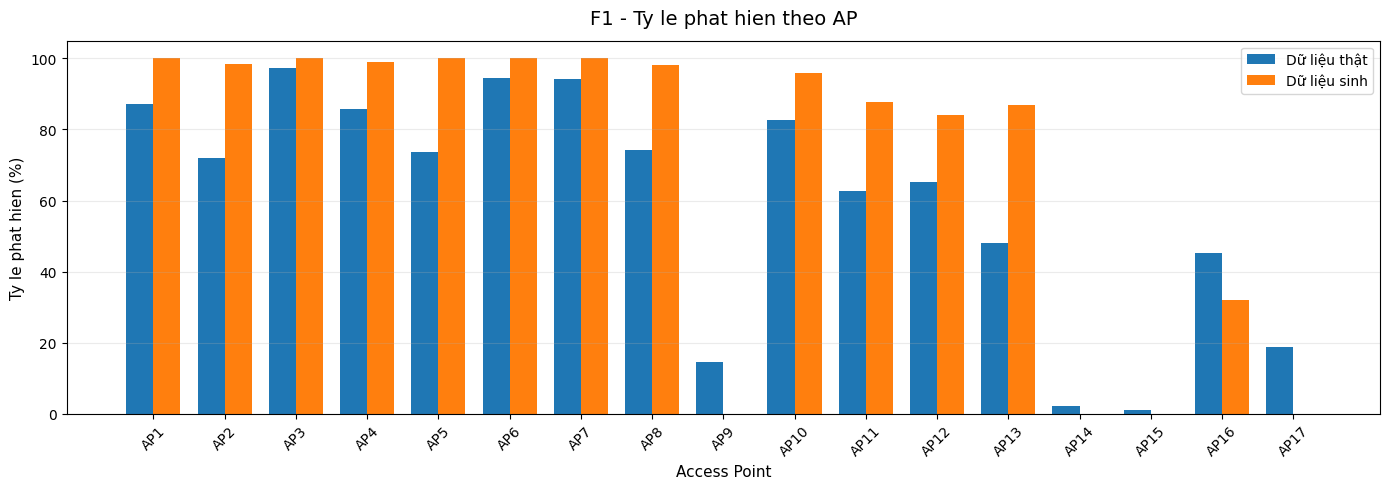

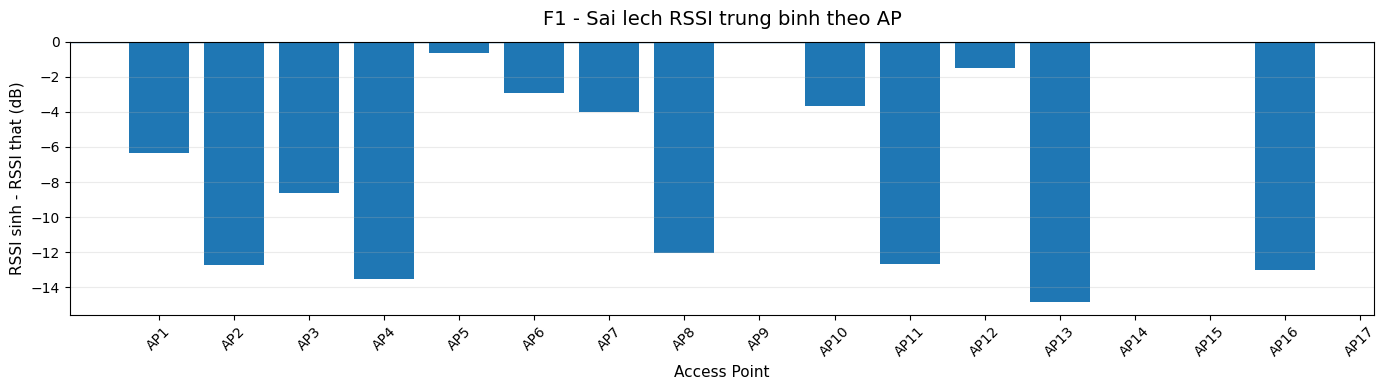

,AP,Thật (%),Sinh (%),Lệch phát hiện (điểm %),RSSI thật (dBm),RSSI sinh (dBm),Lệch RSSI (dB)
0,AP1,57.39,93.91,+36.52,-74.47,-74.10,+0.37
1,AP2,59.13,93.26,+34.13,-75.51,-74.20,+1.31
2,AP3,67.17,74.78,+7.61,-70.73,-74.81,-4.08
3,AP4,70.87,38.48,-32.39,-69.61,-71.16,-1.55
4,AP5,56.96,93.91,+36.96,-70.59,-71.17,-0.58
5,AP6,61.52,97.17,+35.65,-73.97,-73.98,-0.01
6,AP7,71.74,99.57,+27.83,-76.40,-72.71,+3.70
7,AP8,78.04,98.70,+20.65,-67.46,-74.38,-6.92
8,AP9,27.61,0.65,-26.96,-62.66,-76.66,-14.00
9,AP10,86.09,98.91,+12.83,-63.23,-68.94,-5.71


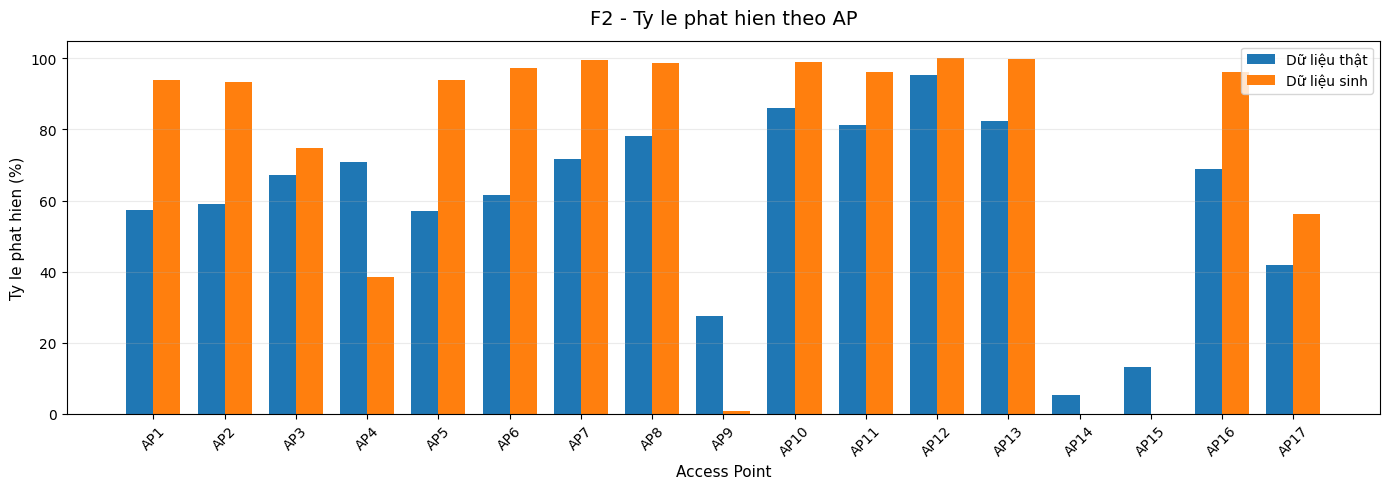

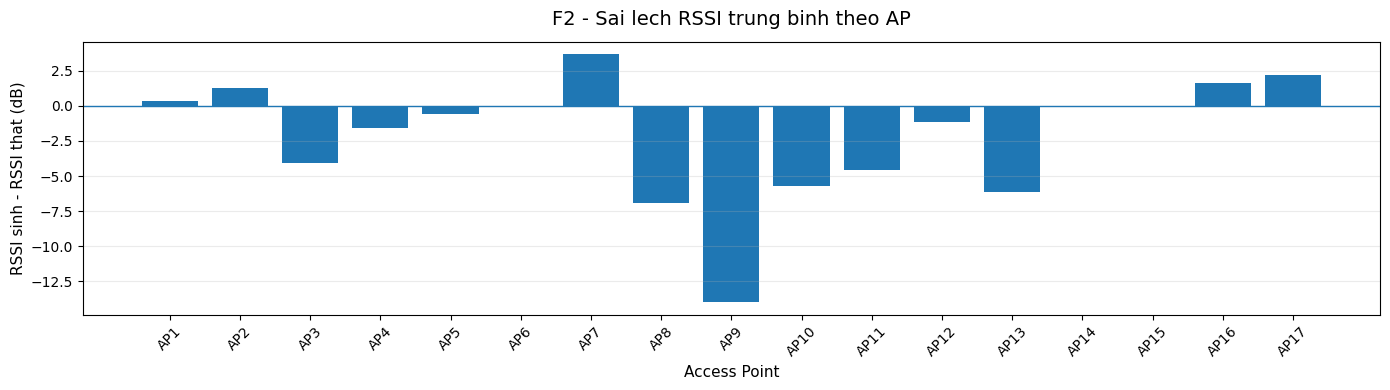

,AP,Thật (%),Sinh (%),Lệch phát hiện (điểm %),RSSI thật (dBm),RSSI sinh (dBm),Lệch RSSI (dB)
0,AP1,32.78,1.39,-31.39,-86.54,-79.92,+6.62
1,AP2,45.56,95.00,+49.44,-83.38,-80.36,+3.03
2,AP3,35.83,34.44,-1.39,-84.43,-81.99,+2.45
3,AP4,46.11,22.78,-23.33,-74.08,-79.05,-4.97
4,AP5,54.44,97.50,+43.06,-76.59,-76.94,-0.35
5,AP6,32.50,0.00,-32.50,-84.74,—,—
6,AP7,33.06,6.39,-26.67,-85.87,-83.07,+2.79
7,AP8,69.17,99.17,+30.00,-77.66,-80.89,-3.23
8,AP9,17.78,0.28,-17.50,-80.67,-85.08,-4.40
9,AP10,52.78,69.72,+16.94,-78.81,-79.72,-0.91


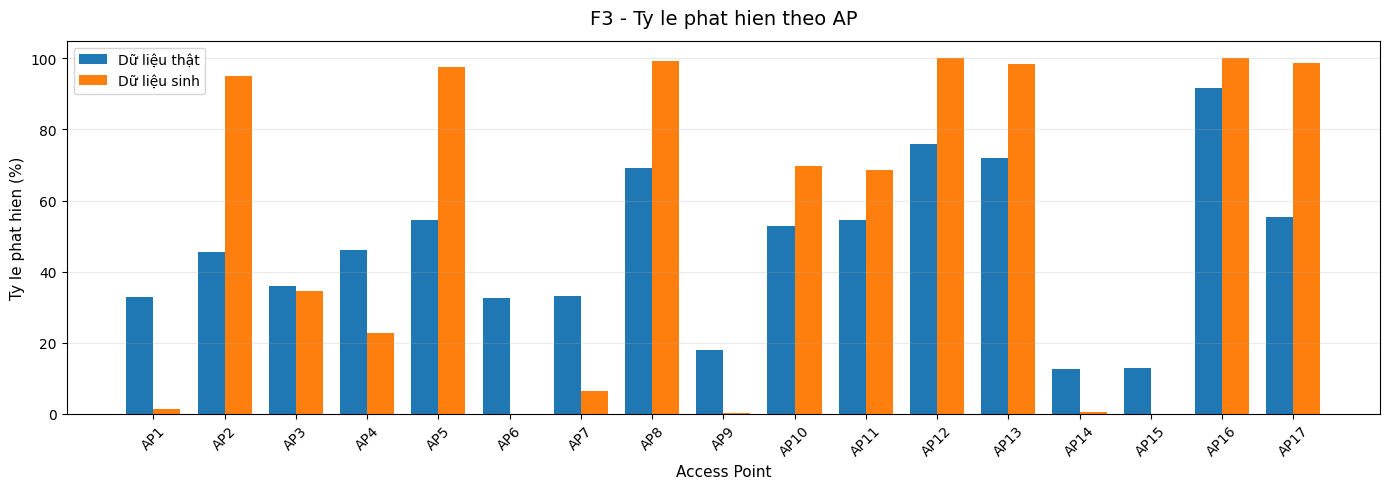

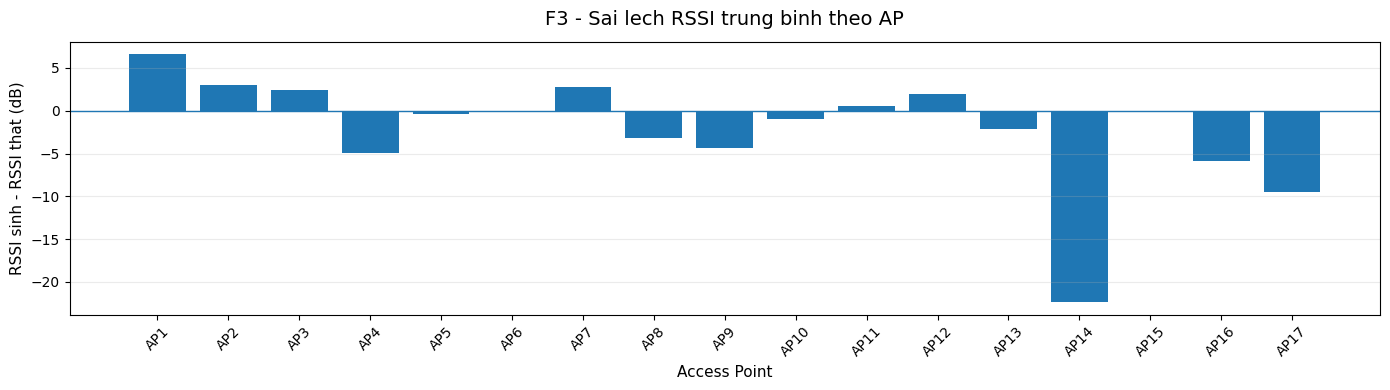

In [ ]:

# ============================================================
# 🌈 CELL 3.14 — SO SÁNH FINGERPRINT THẬT VÀ SINH THEO TỪNG AP
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, HTML

AP_COLS = [f"AP{i}" for i in range(1, 18)]
ap_comparison = {}

# ------------------------------------------------------------
# 🎨 HÀM HIỂN THỊ THÔNG BÁO MÀU
# ------------------------------------------------------------
def show_box(color, title, message, border_color="#64748B"):
    display(HTML(f"""
    <div style="
        background:{color};
        padding:12px 16px;
        border-radius:10px;
        margin:10px 0;
        border-left:6px solid {border_color};
        color:#1F2937;
        font-family:Arial,sans-serif;
        line-height:1.6;">
        <b>{title}</b><br>{message}
    </div>
    """))

show_box(
    "#DBEAFE",
    "🔵 BẮT ĐẦU PHÂN TÍCH",
    "So sánh tỷ lệ phát hiện và RSSI trung bình của 17 AP "
    "trên dữ liệu validation thật và dữ liệu sinh.",
    "#2563EB"
)

# ------------------------------------------------------------
# 🏢 PHÂN TÍCH RIÊNG TỪNG TẦNG
# ------------------------------------------------------------
for floor in ["F1", "F2", "F3"]:

    checkpoint_path = f"/content/cgan_checkpoints/{floor}_best.pt"

    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(
            f"Không tìm thấy checkpoint: {checkpoint_path}"
        )

    # Khôi phục checkpoint tốt nhất
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    G = models[floor]["G"].to(DEVICE)
    G.load_state_dict(checkpoint["G"])
    G.eval()

    real_masks, fake_masks = [], []
    real_rssis, fake_rssis = [], []

    # --------------------------------------------------------
    # Sinh fingerprint tại tọa độ validation
    # --------------------------------------------------------
    with torch.no_grad():
        for coords, rssi_real, mask_real in val_loaders[floor]:

            coords = coords.to(DEVICE)

            noise = torch.randn(
                coords.size(0),
                LATENT_DIM,
                device=DEVICE
            )

            mask_logits, fake_rssi_norm = G(coords, noise)

            # Chuyển xác suất mask thành nhị phân với ngưỡng 0.5
            fake_mask = (
                torch.sigmoid(mask_logits) >= 0.5
            ).float()

            real_masks.append(mask_real.cpu().numpy())
            fake_masks.append(fake_mask.cpu().numpy())

            # RSSI chuẩn hóa [0, 1] -> dBm
            real_rssis.append(
                rssi_real.cpu().numpy() * 80 - 100
            )

            fake_rssis.append(
                fake_rssi_norm.cpu().numpy() * 80 - 100
            )

    real_mask = np.concatenate(real_masks, axis=0)
    fake_mask = np.concatenate(fake_masks, axis=0)
    real_rssi = np.concatenate(real_rssis, axis=0)
    fake_rssi = np.concatenate(fake_rssis, axis=0)

    # --------------------------------------------------------
    # TÍNH TOÁN THEO TỪNG AP
    # --------------------------------------------------------
    rows = []

    for j, ap in enumerate(AP_COLS):

        real_rate = real_mask[:, j].mean() * 100
        fake_rate = fake_mask[:, j].mean() * 100

        # RSSI chỉ tính trên các mẫu AP được phát hiện
        real_detected = real_rssi[real_mask[:, j] == 1, j]
        fake_detected = fake_rssi[fake_mask[:, j] == 1, j]

        real_mean = (
            float(real_detected.mean())
            if len(real_detected) > 0 else np.nan
        )

        fake_mean = (
            float(fake_detected.mean())
            if len(fake_detected) > 0 else np.nan
        )

        rows.append({
            "AP": ap,
            "Thật (%)": real_rate,
            "Sinh (%)": fake_rate,
            "Lệch phát hiện (điểm %)": fake_rate - real_rate,
            "RSSI thật (dBm)": real_mean,
            "RSSI sinh (dBm)": fake_mean,
            "Lệch RSSI (dB)": (
                fake_mean - real_mean
                if np.isfinite(real_mean) and np.isfinite(fake_mean)
                else np.nan
            )
        })

    df = pd.DataFrame(rows)
    ap_comparison[floor] = df

    # --------------------------------------------------------
    # 📊 BẢNG MÀU
    # --------------------------------------------------------
    show_box(
        "#EDE9FE",
        f"🟣 TẦNG {floor}",
        f"Số mẫu validation: {len(real_mask):,} | "
        f"Số AP được phân tích: {len(AP_COLS)}",
        "#7C3AED"
    )

    styled = (
        df.style
        .format({
            "Thật (%)": "{:.2f}",
            "Sinh (%)": "{:.2f}",
            "Lệch phát hiện (điểm %)": "{:+.2f}",
            "RSSI thật (dBm)": "{:.2f}",
            "RSSI sinh (dBm)": "{:.2f}",
            "Lệch RSSI (dB)": "{:+.2f}"
        }, na_rep="—")
        .background_gradient(
            subset=["Lệch phát hiện (điểm %)"],
            cmap="RdYlGn_r",
            vmin=-20,
            vmax=20
        )
        .background_gradient(
            subset=["Lệch RSSI (dB)"],
            cmap="RdYlBu_r",
            vmin=-15,
            vmax=15
        )
        .set_properties(**{
            "text-align": "center",
            "padding": "6px"
        })
    )

    display(styled)

    # --------------------------------------------------------
    # 🔵 BIỂU ĐỒ 1 — TỶ LỆ PHÁT HIỆN AP
    # Không dùng emoji trong tiêu đề để tránh cảnh báo font
    # --------------------------------------------------------
    x = np.arange(len(AP_COLS))
    width = 0.38

    fig, ax = plt.subplots(figsize=(14, 5))

    ax.bar(
        x - width / 2,
        df["Thật (%)"],
        width,
        label="Dữ liệu thật"
    )

    ax.bar(
        x + width / 2,
        df["Sinh (%)"],
        width,
        label="Dữ liệu sinh"
    )

    ax.set_title(
        f"{floor} - Ty le phat hien theo AP",
        fontsize=14,
        pad=12
    )
    ax.set_xlabel("Access Point", fontsize=11)
    ax.set_ylabel("Ty le phat hien (%)", fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels(AP_COLS, rotation=45)
    ax.set_ylim(0, 105)
    ax.legend(frameon=True)
    ax.grid(axis="y", alpha=0.25)

    fig.tight_layout()
    plt.show()
    plt.close(fig)

    # --------------------------------------------------------
    # 🟣 BIỂU ĐỒ 2 — SAI LỆCH RSSI
    # --------------------------------------------------------
    fig, ax = plt.subplots(figsize=(14, 4))

    rssi_gap = df["Lệch RSSI (dB)"].to_numpy(dtype=float)

    ax.bar(AP_COLS, rssi_gap)
    ax.axhline(0, linewidth=1)

    ax.set_title(
        f"{floor} - Sai lech RSSI trung binh theo AP",
        fontsize=14,
        pad=12
    )
    ax.set_xlabel("Access Point", fontsize=11)
    ax.set_ylabel("RSSI sinh - RSSI that (dB)", fontsize=11)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.25)

    fig.tight_layout()
    plt.show()
    plt.close(fig)

    # --------------------------------------------------------
    # 🚦 ĐÁNH GIÁ SÀNG LỌC TỰ ĐỘNG
    # --------------------------------------------------------
    max_detection_gap = (
        df["Lệch phát hiện (điểm %)"].abs().max()
    )

    rssi_gaps = df["Lệch RSSI (dB)"].abs().dropna()

    max_rssi_gap = (
        rssi_gaps.max() if len(rssi_gaps) > 0 else np.nan
    )

    if (
        max_detection_gap > 15
        or (
            np.isfinite(max_rssi_gap)
            and max_rssi_gap > 10
        )
    ):
        show_box(
            "#FEE2E2",
            f"🔴 {floor} — CẦN KIỂM TRA",
            f"Sai lệch phát hiện lớn nhất: "
            f"{max_detection_gap:.2f} điểm %. "
            f"Sai lệch RSSI tuyệt đối lớn nhất: "
            f"{max_rssi_gap:.2f} dB.",
            "#DC2626"
        )

    elif (
        max_detection_gap > 8
        or (
            np.isfinite(max_rssi_gap)
            and max_rssi_gap > 5
        )
    ):
        show_box(
            "#FEF3C7",
            f"🟡 {floor} — CẦN THEO DÕI",
            f"Sai lệch phát hiện lớn nhất: "
            f"{max_detection_gap:.2f} điểm %. "
            f"Sai lệch RSSI tuyệt đối lớn nhất: "
            f"{max_rssi_gap:.2f} dB.",
            "#D97706"
        )

    else:
        show_box(
            "#DCFCE7",
            f"🟢 {floor} — SAI LỆCH TRONG NGƯỠNG SÀNG LỌC",
            f"Sai lệch phát hiện lớn nhất: "
            f"{max_detection_gap:.2f} điểm %. "
            f"Sai lệch RSSI tuyệt đối lớn nhất: "
            f"{max_rssi_gap:.2f} dB.",
            "#16A34A"
        )

# ------------------------------------------------------------
# 🎉 HOÀN TẤT
# ------------------------------------------------------------
show_box(
    "#DBEAFE",
    "🔵 HOÀN TẤT CELL 3.14",
    "Đã hoàn thành bảng màu và biểu đồ so sánh 17 AP "
    "cho cả ba tầng F1, F2, F3. Các biểu đồ không dùng emoji "
    "trong tiêu đề nên tránh cảnh báo thiếu glyph tương ứng.",
    "#2563EB"
)


### Cell 3.15 — Phân tích xác suất phát hiện AP

Generator tạo ra logits cho 17 AP. Sau khi áp dụng sigmoid, mỗi AP có xác suất dự đoán trong khoảng [0, 1]. Ngưỡng 0.5 hiện được dùng để chuyển xác suất thành mask nhị phân.

Cell này so sánh tỷ lệ phát hiện trên dữ liệu thật với tỷ lệ dự đoán ở nhiều ngưỡng, nhằm chẩn đoán sai lệch mask. Việc thay đổi ngưỡng chỉ là phân tích; chưa thay đổi mô hình hoặc checkpoint.

,AP,Real rate (%),Mean probability (%),Probability std,Below 0.1 (%),Above 0.9 (%),Threshold 0.3 (%),Threshold 0.5 (%),Threshold 0.7 (%)
0,AP1,87.24,88.45,0.025,0.00,28.29,100.00,100.00,100.00
1,AP2,71.97,67.85,0.081,0.00,0.00,100.00,98.29,42.37
2,AP3,97.24,91.20,0.021,0.00,72.76,100.00,100.00,100.00
3,AP4,85.66,71.91,0.086,0.00,0.39,100.00,98.68,62.11
4,AP5,73.55,81.88,0.047,0.00,2.50,100.00,100.00,98.95
5,AP6,94.61,89.72,0.021,0.00,46.45,100.00,100.00,100.00
6,AP7,94.21,90.81,0.022,0.00,67.24,100.00,100.00,100.00
7,AP8,74.34,68.96,0.086,0.00,0.00,100.00,97.63,47.89
8,AP9,14.61,7.38,0.017,92.76,0.00,0.00,0.00,0.00
9,AP10,82.63,71.04,0.121,0.00,2.50,100.00,94.87,57.63


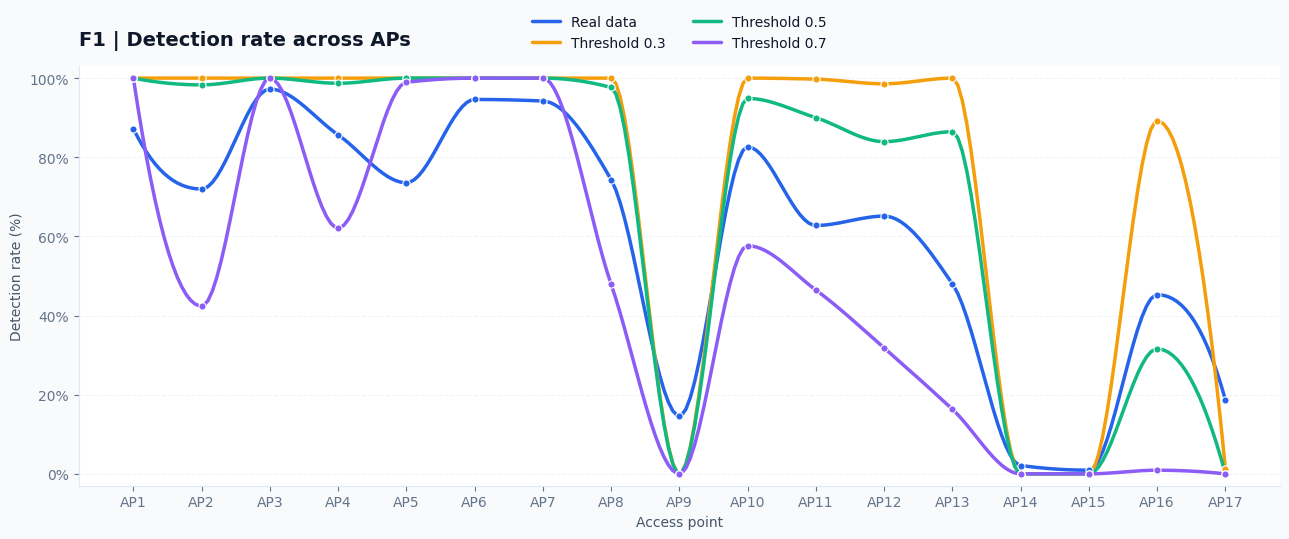

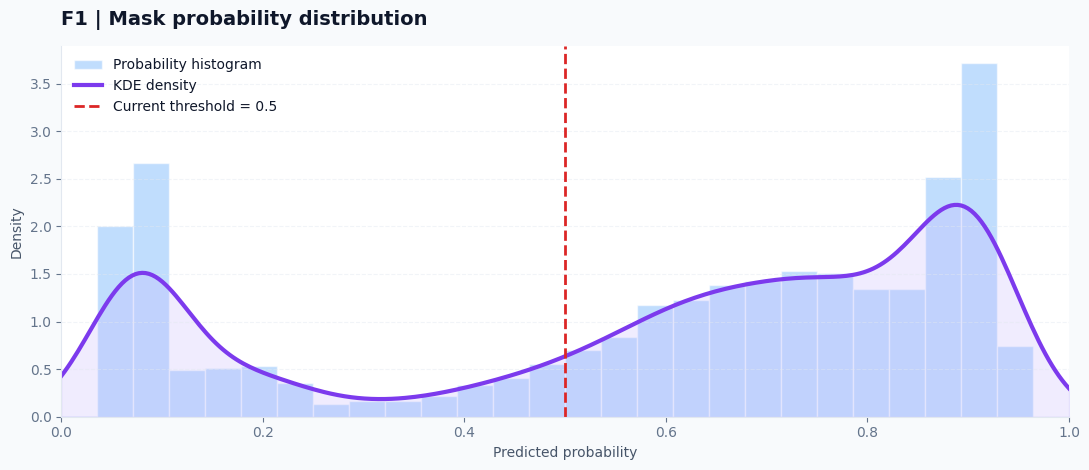

,AP,Real rate (%),Mean probability (%),Probability std,Below 0.1 (%),Above 0.9 (%),Threshold 0.3 (%),Threshold 0.5 (%),Threshold 0.7 (%)
0,AP1,57.39,62.00,0.078,0.00,0.00,100.00,94.35,16.96
1,AP2,59.13,60.26,0.070,0.00,0.00,100.00,93.04,7.61
2,AP3,67.17,55.46,0.075,0.00,0.00,100.00,74.78,2.61
3,AP4,70.87,47.60,0.057,0.00,0.00,99.78,35.22,0.00
4,AP5,56.96,60.79,0.065,0.00,0.00,100.00,95.65,7.61
5,AP6,61.52,62.71,0.065,0.00,0.00,100.00,96.09,13.04
6,AP7,71.74,65.09,0.065,0.00,0.00,100.00,99.57,22.39
7,AP8,78.04,64.42,0.059,0.00,0.00,100.00,99.78,15.87
8,AP9,27.61,35.73,0.066,0.00,0.00,81.52,0.43,0.00
9,AP10,86.09,62.74,0.060,0.00,0.00,100.00,97.39,10.43


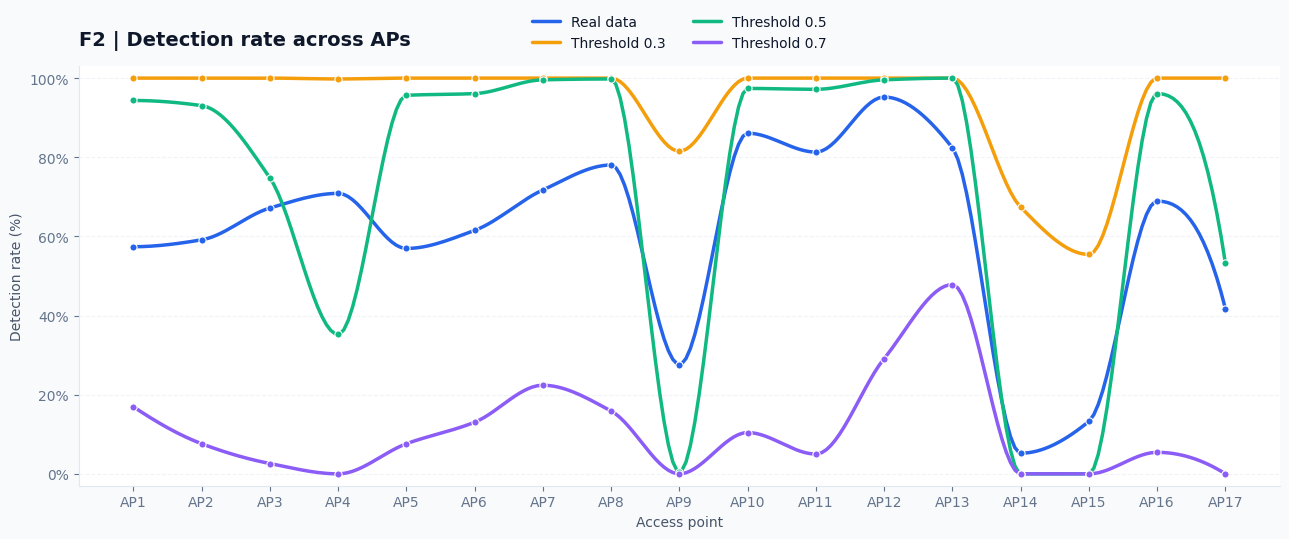

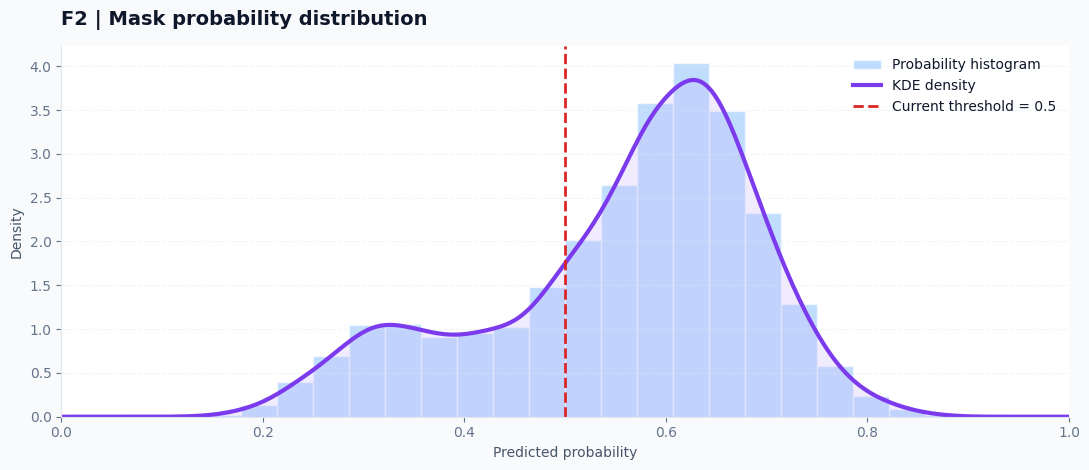

,AP,Real rate (%),Mean probability (%),Probability std,Below 0.1 (%),Above 0.9 (%),Threshold 0.3 (%),Threshold 0.5 (%),Threshold 0.7 (%)
0,AP1,32.78,36.20,0.062,0.00,0.00,84.72,0.28,0.00
1,AP2,45.56,59.38,0.066,0.00,0.00,100.00,91.94,5.00
2,AP3,35.83,47.97,0.065,0.00,0.00,99.72,37.22,0.28
3,AP4,46.11,43.78,0.077,0.00,0.00,95.28,21.11,0.00
4,AP5,54.44,64.95,0.078,0.00,0.00,100.00,97.78,25.28
5,AP6,32.50,31.04,0.061,0.00,0.00,57.50,0.00,0.00
6,AP7,33.06,38.90,0.080,0.00,0.00,83.89,9.72,0.00
7,AP8,69.17,65.35,0.060,0.00,0.00,100.00,100.00,23.06
8,AP9,17.78,32.07,0.069,0.00,0.00,61.39,0.28,0.00
9,AP10,52.78,53.95,0.071,0.00,0.00,100.00,70.00,1.67


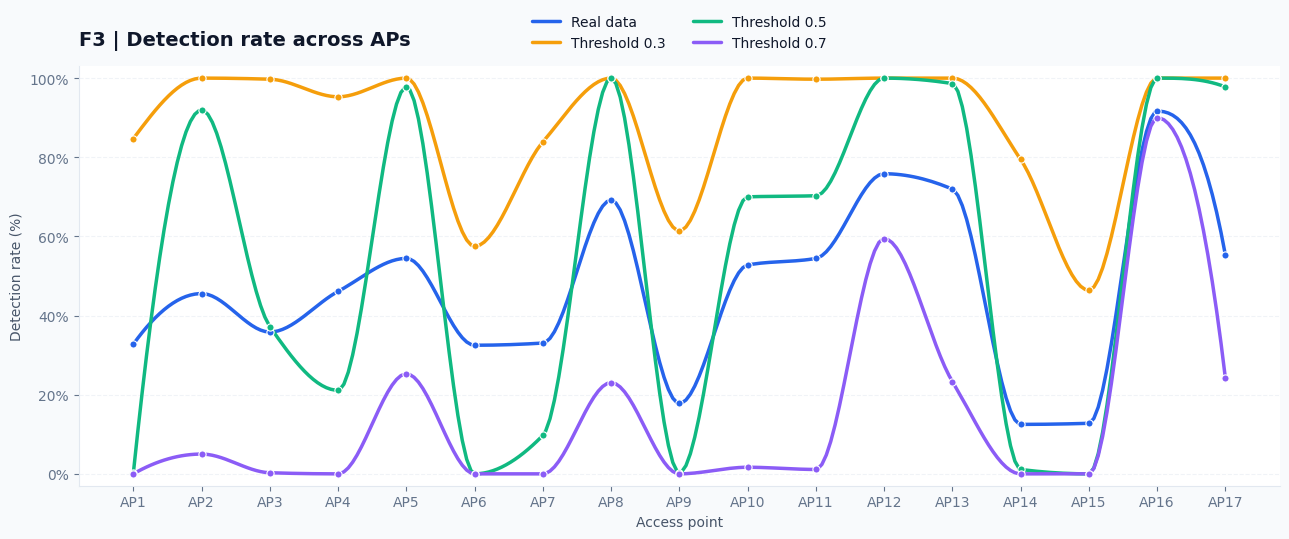

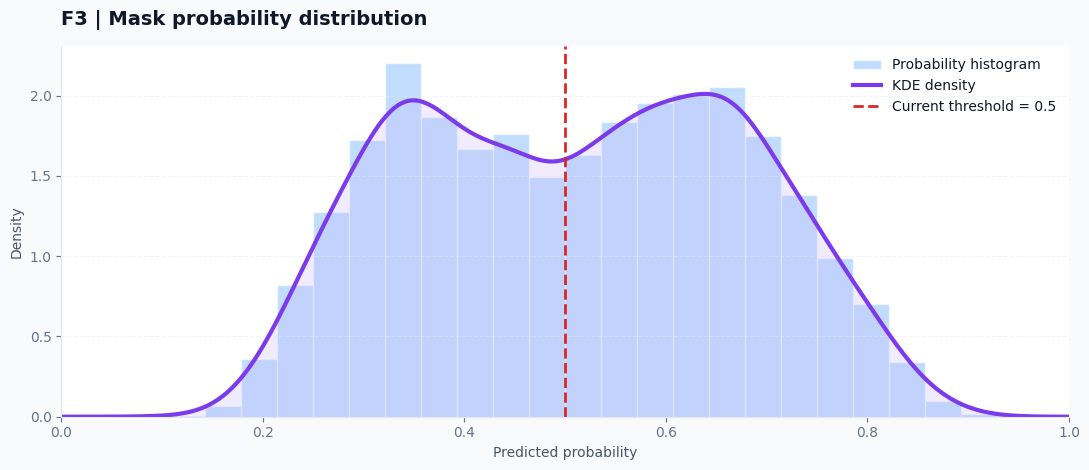

,n_validation,real_detection_rate,pred_detection_rate,mean_abs_detection_gap_pp,mean_probability_gap_pp,saturated_probability_pct
Floor,,,,,,
F1,760,59.94,69.50,15.44,5.84,28.74
F2,460,60.27,72.49,21.79,13.06,0.00
F3,360,46.73,52.71,24.22,8.43,0.03


In [ ]:

# ============================================================
# CELL 3.15 — MODERN MASK ANALYTICS DASHBOARD
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, HTML
from scipy.stats import gaussian_kde

AP_COLS = [f"AP{i}" for i in range(1, 18)]
THRESHOLDS = [0.3, 0.5, 0.7]

mask_diagnostics = {}
mask_summary = {}

# ------------------------------------------------------------
# 1. STYLE — CLEAN MODERN DASHBOARD
# ------------------------------------------------------------
plt.rcParams.update({
    "figure.facecolor": "#F8FAFC",
    "axes.facecolor": "#FFFFFF",
    "axes.edgecolor": "#E2E8F0",
    "axes.labelcolor": "#475569",
    "axes.titlecolor": "#0F172A",
    "xtick.color": "#64748B",
    "ytick.color": "#64748B",
    "text.color": "#0F172A",
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.labelsize": 10,
    "legend.frameon": False,
    "grid.color": "#E2E8F0",
    "grid.alpha": 0.65
})

COLORS = {
    "real": "#2563EB",
    "t03": "#F59E0B",
    "t05": "#10B981",
    "t07": "#8B5CF6",
    "density": "#7C3AED",
    "warning": "#DC2626"
}

def dashboard_box(title, message, color="#2563EB", bg="#EFF6FF"):
    display(HTML(f"""
    <div style="
        background:{bg};
        border-left:5px solid {color};
        padding:14px 18px;
        border-radius:12px;
        margin:12px 0;
        font-family:Arial,sans-serif;
        color:#1E293B;
        line-height:1.6;
        box-shadow:0 2px 8px rgba(15,23,42,.04)">
        <div style="font-size:15px;font-weight:700;margin-bottom:4px">
            {title}
        </div>
        <div style="font-size:13px">{message}</div>
    </div>
    """))

def kpi_card(title, value, subtitle, color):
    return f"""
    <div style="
        background:white;
        border:1px solid #E2E8F0;
        border-top:4px solid {color};
        border-radius:12px;
        padding:15px;
        min-width:150px;
        flex:1;
        box-shadow:0 2px 8px rgba(15,23,42,.04)">
        <div style="font-size:12px;color:#64748B">{title}</div>
        <div style="font-size:25px;font-weight:750;color:{color};
                    margin:5px 0">{value}</div>
        <div style="font-size:11px;color:#64748B">{subtitle}</div>
    </div>
    """

def smooth_line(ax, x, y, color, label, smooth=True):
    """Nội suy chỉ để hiển thị; marker là dữ liệu gốc."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if smooth and len(x) >= 4:
        try:
            from scipy.interpolate import PchipInterpolator
            x_dense = np.linspace(x.min(), x.max(), 250)
            y_dense = PchipInterpolator(x, y)(x_dense)
            ax.plot(
                x_dense, y_dense,
                color=color, linewidth=2.5,
                solid_capstyle="round", label=label
            )
        except Exception:
            ax.plot(x, y, color=color, linewidth=2, label=label)
    else:
        ax.plot(x, y, color=color, linewidth=2, label=label)

    ax.scatter(
        x, y, color=color, s=27,
        edgecolor="white", linewidth=0.8, zorder=3
    )

dashboard_box(
    "MODERN MASK ANALYTICS",
    "Phân tích xác suất mask trên validation. "
    "Checkpoint và trọng số mô hình được giữ nguyên.",
    "#2563EB", "#EFF6FF"
)

# ------------------------------------------------------------
# 2. LOAD CHECKPOINT AND COLLECT VALIDATION OUTPUTS
# ------------------------------------------------------------
for floor in ["F1", "F2", "F3"]:

    checkpoint_path = f"/content/cgan_checkpoints/{floor}_best.pt"

    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(
            f"Không tìm thấy checkpoint: {checkpoint_path}"
        )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    G = models[floor]["G"].to(DEVICE)
    G.load_state_dict(checkpoint["G"])
    G.eval()

    real_masks = []
    probabilities = []

    with torch.no_grad():
        for coords, _, real_mask in val_loaders[floor]:
            coords = coords.to(DEVICE)

            noise = torch.randn(
                coords.size(0),
                LATENT_DIM,
                device=DEVICE
            )

            mask_logits, _ = G(coords, noise)
            probs = torch.sigmoid(mask_logits)

            real_masks.append(real_mask.cpu().numpy())
            probabilities.append(probs.cpu().numpy())

    real_mask = np.concatenate(real_masks, axis=0)
    probs = np.concatenate(probabilities, axis=0)

    # --------------------------------------------------------
    # 3. TABLE — PER-AP DIAGNOSTICS
    # --------------------------------------------------------
    rows = []

    for j, ap in enumerate(AP_COLS):
        row = {
            "AP": ap,
            "Real rate (%)": real_mask[:, j].mean() * 100,
            "Mean probability (%)": probs[:, j].mean() * 100,
            "Probability std": probs[:, j].std(),
            "Below 0.1 (%)": (probs[:, j] < 0.1).mean() * 100,
            "Above 0.9 (%)": (probs[:, j] > 0.9).mean() * 100
        }

        for threshold in THRESHOLDS:
            row[f"Threshold {threshold:.1f} (%)"] = (
                probs[:, j] >= threshold
            ).mean() * 100

        rows.append(row)

    df = pd.DataFrame(rows)
    mask_diagnostics[floor] = df

    real_rate = real_mask.mean(axis=0) * 100
    predicted_rate = (probs >= 0.5).mean(axis=0) * 100

    mean_abs_gap = np.mean(np.abs(predicted_rate - real_rate))
    mean_probability_gap = np.mean(
        np.abs(probs.mean(axis=0) * 100 - real_rate)
    )
    saturated = np.mean((probs < 0.1) | (probs > 0.9)) * 100

    mask_summary[floor] = {
        "n_validation": len(real_mask),
        "real_detection_rate": real_mask.mean() * 100,
        "pred_detection_rate": (probs >= 0.5).mean() * 100,
        "mean_abs_detection_gap_pp": mean_abs_gap,
        "mean_probability_gap_pp": mean_probability_gap,
        "saturated_probability_pct": saturated
    }

    # --------------------------------------------------------
    # 4. FLOOR HEADER AND KPI CARDS
    # --------------------------------------------------------
    dashboard_box(
        f"FLOOR {floor}",
        f"{len(real_mask):,} validation samples | "
        "17 access points | Threshold baseline = 0.5",
        "#7C3AED", "#F5F3FF"
    )

    cards = (
        kpi_card(
            "Real detection rate",
            f"{real_mask.mean()*100:.1f}%",
            "Tỷ lệ AP được phát hiện trong dữ liệu thật",
            COLORS["real"]
        )
        + kpi_card(
            "Predicted detection",
            f"{(probs >= 0.5).mean()*100:.1f}%",
            "Tỷ lệ dự đoán ở ngưỡng 0.5",
            COLORS["t05"]
        )
        + kpi_card(
            "Mean abs. gap",
            f"{mean_abs_gap:.2f} pp",
            "Sai lệch trung bình trên 17 AP",
            COLORS["warning"] if mean_abs_gap > 15 else COLORS["t05"]
        )
        + kpi_card(
            "Probability saturation",
            f"{saturated:.1f}%",
            "Xác suất dưới 0.1 hoặc trên 0.9",
            COLORS["t07"]
        )
    )

    display(HTML(f"""
    <div style="display:flex;flex-wrap:wrap;gap:12px;margin:12px 0 20px">
        {cards}
    </div>
    """))

    display(
        df.style
        .format({
            "Real rate (%)": "{:.2f}",
            "Mean probability (%)": "{:.2f}",
            "Probability std": "{:.3f}",
            "Below 0.1 (%)": "{:.2f}",
            "Above 0.9 (%)": "{:.2f}",
            "Threshold 0.3 (%)": "{:.2f}",
            "Threshold 0.5 (%)": "{:.2f}",
            "Threshold 0.7 (%)": "{:.2f}"
        })
        .background_gradient(
            subset=["Mean probability (%)"],
            cmap="PuBu",
            vmin=0, vmax=100
        )
        .background_gradient(
            subset=["Probability std"],
            cmap="OrRd"
        )
        .set_properties(**{
            "text-align": "center",
            "padding": "7px"
        })
    )

    # --------------------------------------------------------
    # 5. CHART A — SMOOTH DETECTION-RATE CURVES
    # --------------------------------------------------------
    x = np.arange(1, 18)

    fig, ax = plt.subplots(figsize=(13, 5.5))

    smooth_line(
        ax, x, real_rate, COLORS["real"],
        "Real data", smooth=True
    )

    for threshold, color, label in [
        (0.3, COLORS["t03"], "Threshold 0.3"),
        (0.5, COLORS["t05"], "Threshold 0.5"),
        (0.7, COLORS["t07"], "Threshold 0.7")
    ]:
        rates = (probs >= threshold).mean(axis=0) * 100

        smooth_line(
            ax, x, rates, color, label, smooth=True
        )

    ax.set_title(
        f"{floor} | Detection rate across APs",
        loc="left", fontweight="bold", pad=15
    )
    ax.set_xlabel("Access point")
    ax.set_ylabel("Detection rate (%)")
    ax.set_xticks(x)
    ax.set_xticklabels(AP_COLS, rotation=0)
    ax.set_ylim(-3, 103)
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(ncol=2, loc="lower center",
              bbox_to_anchor=(0.5, 1.01))

    fig.tight_layout()
    plt.show()
    plt.close(fig)

    # --------------------------------------------------------
    # 6. CHART B — HISTOGRAM + KDE
    # --------------------------------------------------------
    values = probs.ravel()

    fig, ax = plt.subplots(figsize=(11, 4.8))

    ax.hist(
        values,
        bins=28,
        range=(0, 1),
        density=True,
        color="#93C5FD",
        edgecolor="white",
        alpha=0.58,
        label="Probability histogram"
    )

    # KDE chỉ được vẽ khi dữ liệu đủ biến thiên
    if len(values) > 1 and np.std(values) > 1e-8:
        try:
            kde = gaussian_kde(values)
            x_density = np.linspace(0, 1, 300)
            y_density = kde(x_density)

            ax.plot(
                x_density, y_density,
                color=COLORS["density"],
                linewidth=3,
                label="KDE density"
            )
            ax.fill_between(
                x_density, y_density,
                color="#C4B5FD", alpha=0.25
            )
        except (ValueError, np.linalg.LinAlgError):
            pass

    ax.axvline(
        0.5,
        color=COLORS["warning"],
        linestyle="--",
        linewidth=2,
        label="Current threshold = 0.5"
    )

    ax.set_title(
        f"{floor} | Mask probability distribution",
        loc="left", fontweight="bold", pad=15
    )
    ax.set_xlabel("Predicted probability")
    ax.set_ylabel("Density")
    ax.set_xlim(0, 1)
    ax.grid(axis="y", linestyle="--", alpha=0.45)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend()

    fig.tight_layout()
    plt.show()
    plt.close(fig)

    # --------------------------------------------------------
    # 7. STATUS CARD
    # --------------------------------------------------------
    if mean_abs_gap > 20:
        dashboard_box(
            f"{floor} | Significant mask mismatch",
            f"Mean absolute detection-rate gap = {mean_abs_gap:.2f} "
            f"percentage points. Cần xem xét lại cách học mask.",
            "#DC2626", "#FEF2F2"
        )
    elif mean_abs_gap > 10:
        dashboard_box(
            f"{floor} | Mask needs review",
            f"Mean absolute detection-rate gap = {mean_abs_gap:.2f} "
            f"percentage points.",
            "#D97706", "#FFFBEB"
        )
    else:
        dashboard_box(
            f"{floor} | Smaller mask mismatch",
            f"Mean absolute detection-rate gap = {mean_abs_gap:.2f} "
            f"percentage points. Vẫn cần đánh giá RSSI và định vị.",
            "#059669", "#ECFDF5"
        )

# ------------------------------------------------------------
# 8. CROSS-FLOOR SUMMARY
# ------------------------------------------------------------
summary_df = pd.DataFrame(mask_summary).T
summary_df.index.name = "Floor"

dashboard_box(
    "CROSS-FLOOR SUMMARY",
    "So sánh nhanh sai lệch mask giữa ba tầng.",
    "#2563EB", "#EFF6FF"
)

display(
    summary_df.style.format({
        "n_validation": "{:.0f}",
        "real_detection_rate": "{:.2f}",
        "pred_detection_rate": "{:.2f}",
        "mean_abs_detection_gap_pp": "{:.2f}",
        "mean_probability_gap_pp": "{:.2f}",
        "saturated_probability_pct": "{:.2f}"
    }).background_gradient(
        subset=["mean_abs_detection_gap_pp"],
        cmap="RdYlGn_r"
    )
)

dashboard_box(
    "CELL 3.15 COMPLETED",
    "Dashboard hoàn tất. Đường cong nội suy chỉ phục vụ hiển thị; "
    "marker thể hiện số liệu thực. Không huấn luyện lại mô hình "
    "và không sử dụng tập test.",
    "#059669", "#ECFDF5"
)


## Cell 3.16 — Phân tích lịch sử huấn luyện cGAN

Phân tích lịch sử huấn luyện của Generator và Discriminator, đồng thời theo dõi loss mask, RSSI và validation score trên từng tầng F1, F2, F3.

Mục tiêu là quan sát sự ổn định của quá trình tối ưu, phát hiện dấu hiệu overfitting và xác định epoch có validation score tốt nhất. Cell chỉ đọc lịch sử đã lưu, không huấn luyện lại hoặc thay đổi checkpoint.

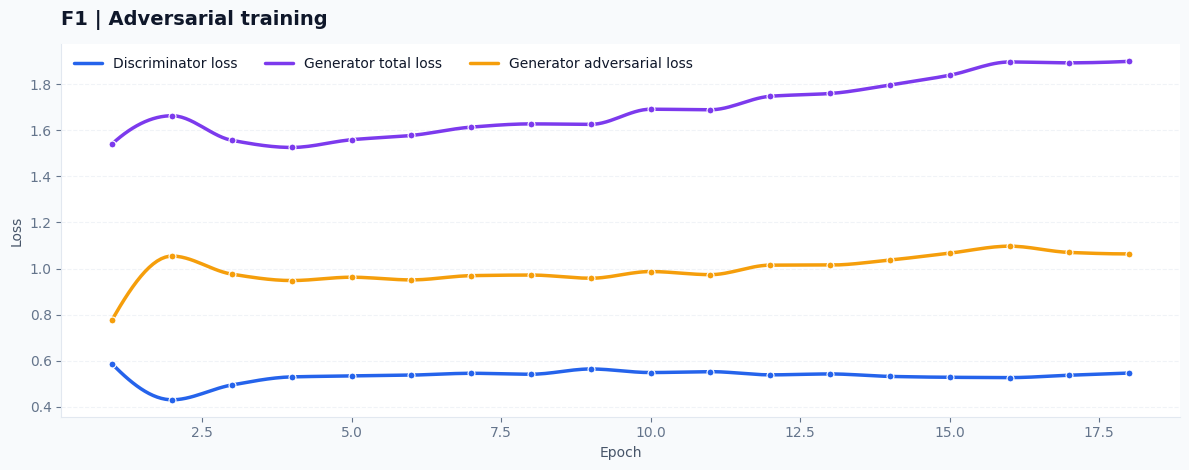

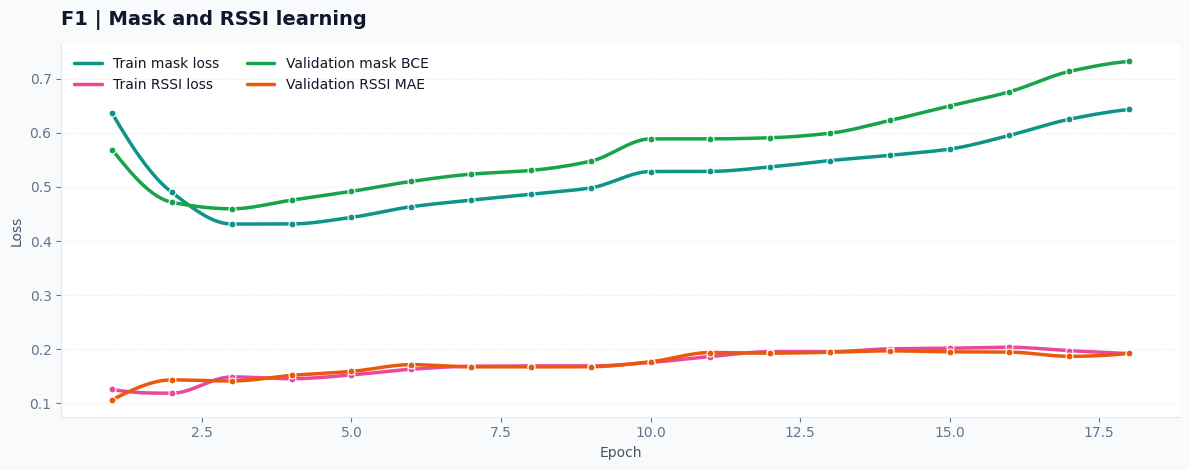

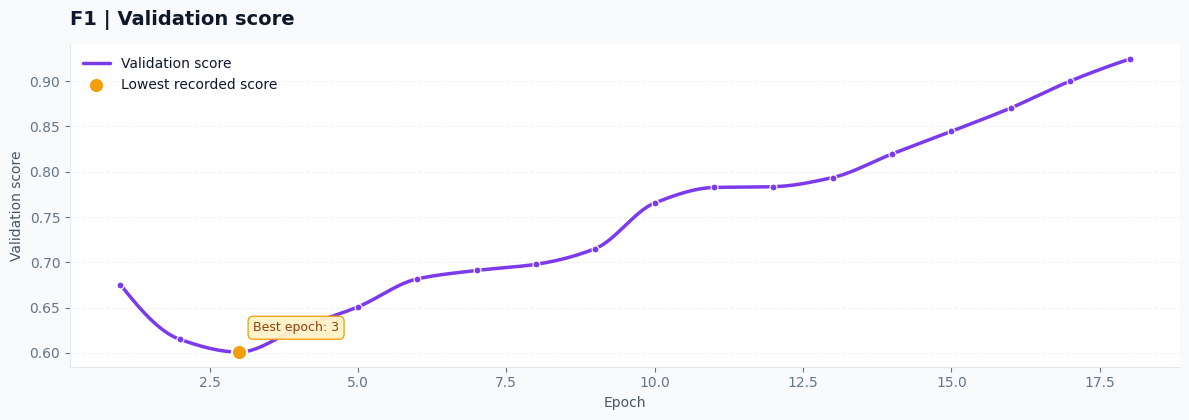

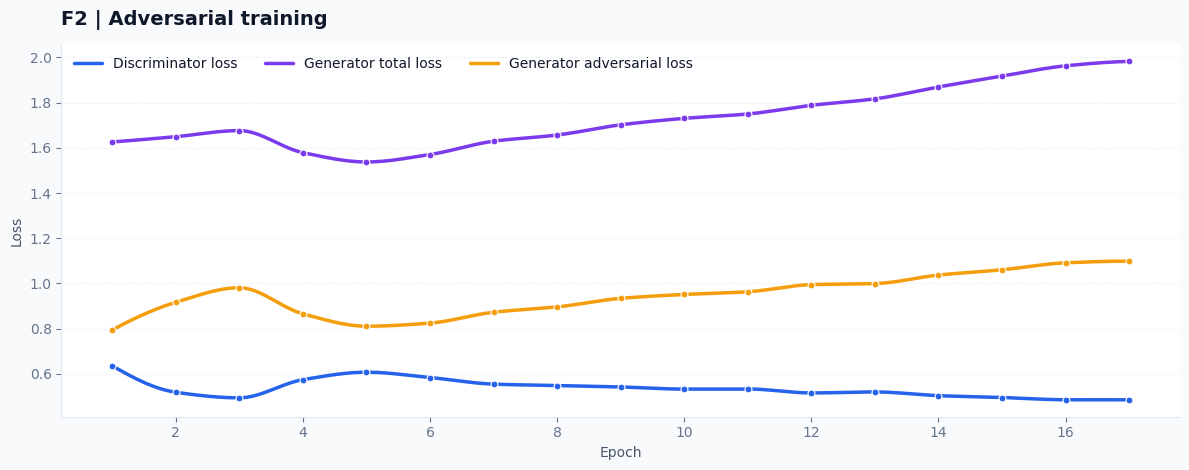

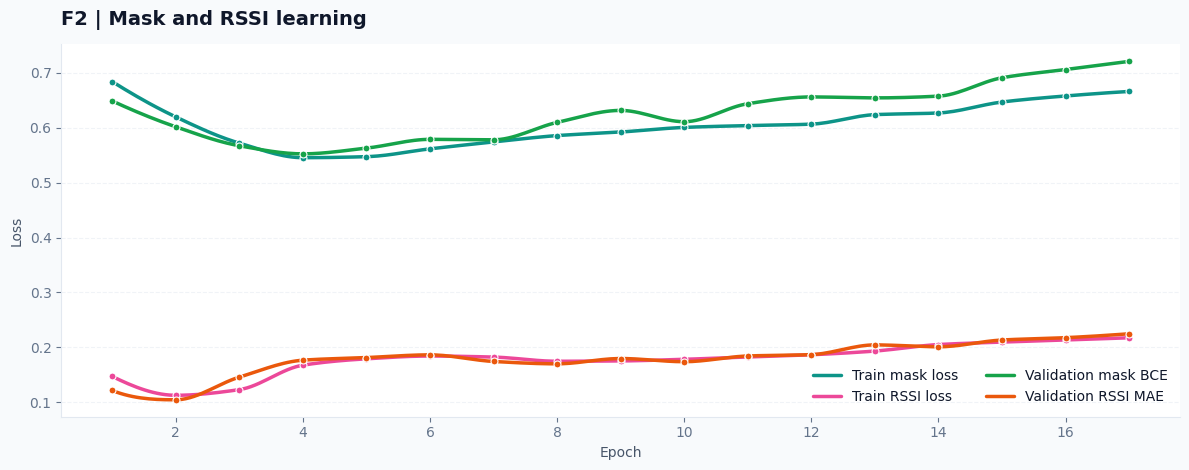

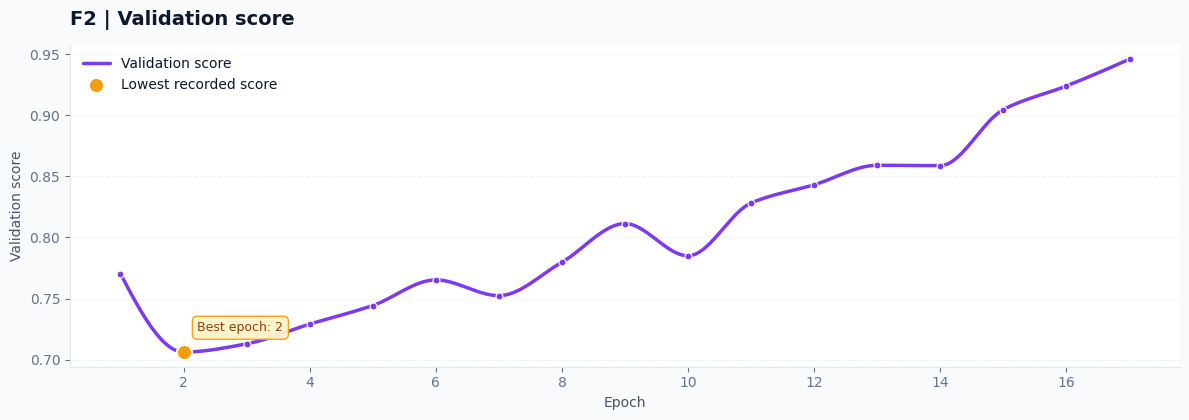

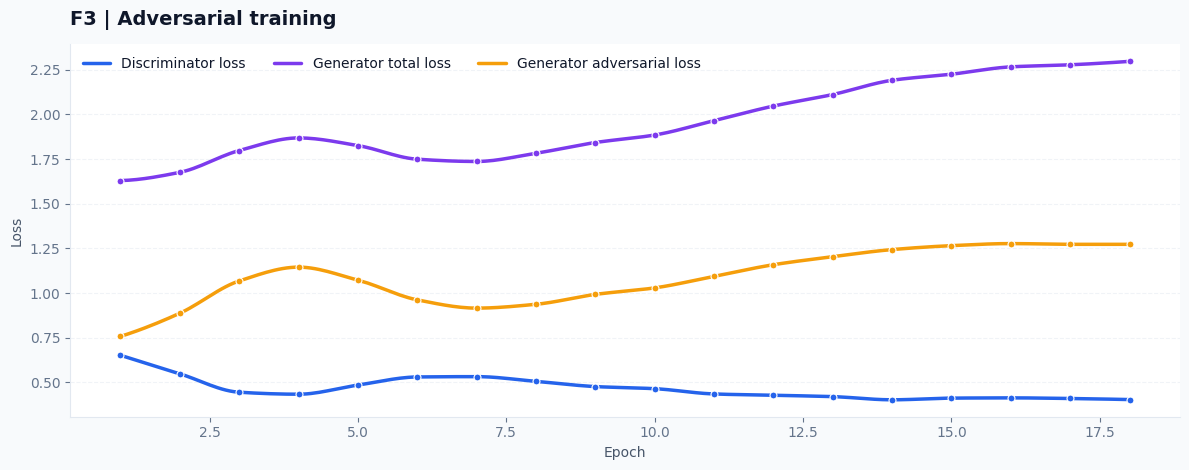

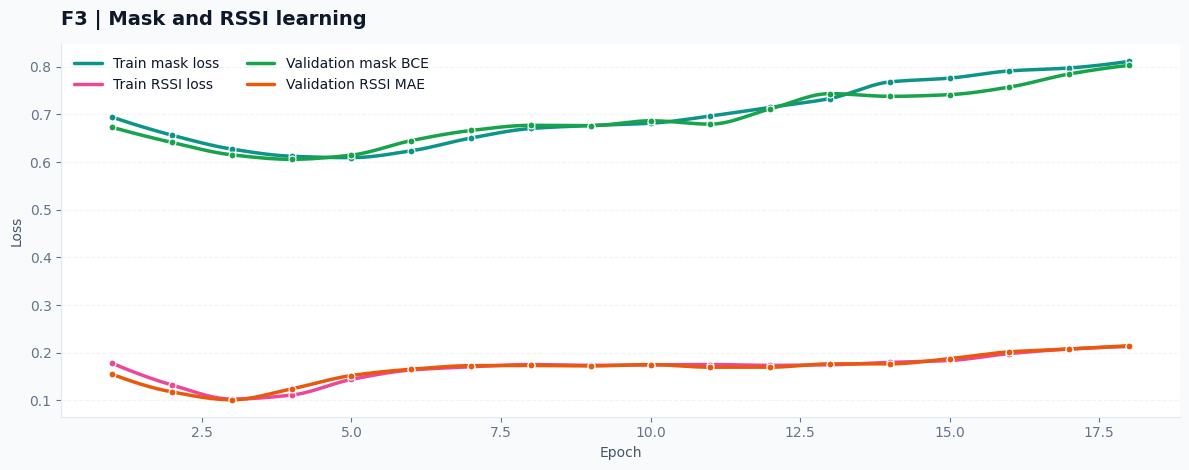

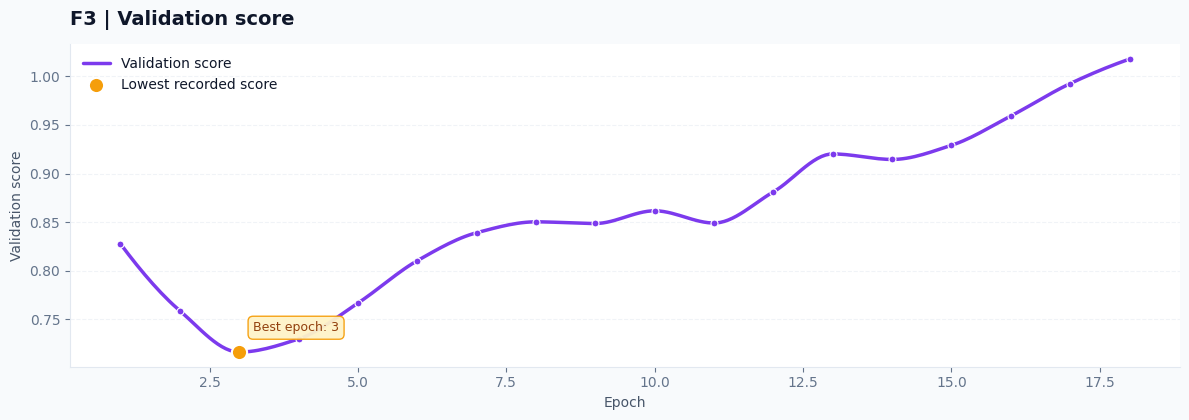

,Epochs,Best epoch,Best validation score,Final D loss,Final G loss,Final mask loss,Final RSSI loss
Floor,,,,,,,
F1,18,3,0.6010,0.5467,1.8986,0.6431,0.1921
F2,17,2,0.7063,0.4853,1.9824,0.6663,0.2174
F3,18,3,0.7165,0.4038,2.2972,0.8110,0.2132


In [ ]:

# ============================================================
# CELL 3.16 — MODERN TRAINING ANALYTICS DASHBOARD
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# ------------------------------------------------------------
# 1. MODERN VISUAL STYLE
# ------------------------------------------------------------
plt.rcParams.update({
    "figure.facecolor": "#F8FAFC",
    "axes.facecolor": "#FFFFFF",
    "axes.edgecolor": "#E2E8F0",
    "axes.labelcolor": "#475569",
    "axes.titlecolor": "#0F172A",
    "xtick.color": "#64748B",
    "ytick.color": "#64748B",
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.labelsize": 10,
    "grid.color": "#E2E8F0",
    "grid.alpha": 0.65,
    "legend.frameon": False
})

C = {
    "D": "#2563EB",
    "G": "#7C3AED",
    "adv": "#F59E0B",
    "mask": "#0D9488",
    "rssi": "#EC4899",
    "val_mask": "#16A34A",
    "val_rssi": "#EA580C",
    "score": "#7C3AED",
    "warning": "#DC2626"
}

def train_box(title, message, color="#2563EB", bg="#EFF6FF"):
    display(HTML(f"""
    <div style="
        background:{bg};
        border-left:5px solid {color};
        padding:14px 18px;
        border-radius:12px;
        margin:12px 0;
        color:#1E293B;
        font-family:Arial,sans-serif;
        line-height:1.6;
        box-shadow:0 2px 8px rgba(15,23,42,.04)">
        <div style="font-weight:700;font-size:15px;margin-bottom:4px">
            {title}
        </div>
        <div style="font-size:13px">{message}</div>
    </div>
    """))

def train_kpi(title, value, subtitle, color):
    return f"""
    <div style="
        background:#FFFFFF;
        border:1px solid #E2E8F0;
        border-top:4px solid {color};
        border-radius:12px;
        padding:14px;
        min-width:150px;
        flex:1;
        box-shadow:0 2px 8px rgba(15,23,42,.04)">
        <div style="font-size:12px;color:#64748B">{title}</div>
        <div style="font-size:24px;font-weight:750;color:{color};
                    margin:5px 0">{value}</div>
        <div style="font-size:11px;color:#64748B">{subtitle}</div>
    </div>
    """

def smooth_training_line(ax, x, y, color, label):
    """Đường nội suy chỉ để hiển thị; marker là giá trị theo epoch."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]

    if len(x) == 0:
        return

    if len(x) >= 4:
        try:
            from scipy.interpolate import PchipInterpolator
            x_dense = np.linspace(x.min(), x.max(), 250)
            y_dense = PchipInterpolator(x, y)(x_dense)
            ax.plot(
                x_dense, y_dense, color=color,
                linewidth=2.5, label=label,
                solid_capstyle="round"
            )
        except Exception:
            ax.plot(x, y, color=color, linewidth=2, label=label)
    else:
        ax.plot(x, y, color=color, linewidth=2, label=label)

    ax.scatter(
        x, y, color=color, s=25,
        edgecolor="white", linewidth=0.8, zorder=3
    )

# ------------------------------------------------------------
# 2. CHECK TRAINING HISTORY
# Supports:
#   history[floor] = dict of lists
#   history[floor] = list of epoch dictionaries
# ------------------------------------------------------------
if "history" not in globals():
    train_box(
        "KHÔNG TÌM THẤY LỊCH SỬ",
        "Không có biến `history` trong bộ nhớ hiện tại. "
        "Cell này không thể tái tạo loss từ checkpoint. "
        "Hãy kiểm tra biến lịch sử được tạo trong cell huấn luyện.",
        "#DC2626", "#FEF2F2"
    )
    raise RuntimeError(
        "Thiếu biến history. Không huấn luyện lại tự động."
    )

ALIASES = {
    "D_loss": ["D_loss", "d_loss", "loss_D", "D"],
    "G_loss": ["G_loss", "g_loss", "loss_G", "G"],
    "G_adv": ["G_adv", "adv_loss", "G_adv_loss"],
    "mask_loss": ["mask_loss", "G_mask", "train_mask"],
    "rssi_loss": ["rssi_loss", "G_rssi", "train_rssi"],
    "val_mask_bce": [
        "val_mask_bce", "ValMask", "val_mask",
        "val_mask_loss", "validation_mask"
    ],
    "val_rssi_mae": [
        "val_rssi_mae", "ValRSSI", "val_rssi",
        "validation_rssi"
    ],
    "val_score": [
        "val_score", "validation_score", "Validation score"
    ]
}

def extract_series(floor_history, aliases):
    """Lấy series từ dict-of-lists hoặc list-of-dicts."""
    if isinstance(floor_history, dict):
        for key in aliases:
            if key in floor_history:
                try:
                    return np.asarray(
                        floor_history[key], dtype=float
                    ).reshape(-1)
                except (TypeError, ValueError):
                    continue

    if isinstance(floor_history, (list, tuple)):
        if len(floor_history) > 0 and isinstance(
            floor_history[0], dict
        ):
            values = []
            for record in floor_history:
                found = False
                for key in aliases:
                    if key in record:
                        values.append(record[key])
                        found = True
                        break
                if not found:
                    return None
            try:
                return np.asarray(values, dtype=float).reshape(-1)
            except (TypeError, ValueError):
                return None

    return None

def get_floor_history(floor):
    # Dạng chuẩn được sử dụng trong notebook
    if isinstance(history, dict) and floor in history:
        return history[floor]

    # Tương thích nếu history được lưu dạng list theo tầng
    return None

train_box(
    "MODERN TRAINING ANALYTICS",
    "Đọc lịch sử huấn luyện có sẵn. Không cập nhật trọng số "
    "và không sử dụng tập test.",
    "#2563EB", "#EFF6FF"
)

training_summary = {}

# ------------------------------------------------------------
# 3. ANALYZE EACH FLOOR
# ------------------------------------------------------------
for floor in ["F1", "F2", "F3"]:

    h_floor = get_floor_history(floor)

    if h_floor is None:
        train_box(
            f"{floor} — KHÔNG CÓ LỊCH SỬ",
            f"Không tìm thấy history['{floor}']. "
            "Bỏ qua tầng này; không tự tạo số liệu.",
            "#DC2626", "#FEF2F2"
        )
        continue

    series = {
        name: extract_series(h_floor, aliases)
        for name, aliases in ALIASES.items()
    }

    # Chỉ yêu cầu các chuỗi thiết yếu để vẽ được biểu đồ
    essential = ["D_loss", "G_loss", "mask_loss", "rssi_loss"]
    missing = [
        name for name in essential
        if series[name] is None
    ]

    if missing:
        available = (
            list(h_floor.keys())
            if isinstance(h_floor, dict)
            else ["history dạng list hoặc cấu trúc khác"]
        )
        train_box(
            f"{floor} — CHƯA ĐỦ DỮ LIỆU",
            f"Thiếu: {missing}. Các khóa tìm thấy: {available}. "
            "Không suy đoán hoặc tạo giá trị thay thế.",
            "#D97706", "#FFFBEB"
        )
        continue

    # Dùng độ dài chung của các chuỗi thiết yếu
    lengths = [
        len(series[name])
        for name in essential
        if series[name] is not None
    ]
    n_epochs = min(lengths)

    if n_epochs == 0:
        train_box(
            f"{floor} — LỊCH SỬ RỖNG",
            "Các chuỗi loss không có dữ liệu.",
            "#DC2626", "#FEF2F2"
        )
        continue

    # Cắt các chuỗi về độ dài chung, giữ nguyên dữ liệu gốc
    for name, values in series.items():
        if values is not None:
            series[name] = values[:n_epochs]

    epochs = np.arange(1, n_epochs + 1)

    # Validation score: dùng trực tiếp lịch sử nếu có.
    # Nếu không có, tính lại từ hai validation loss đã lưu,
    # chỉ khi cả hai chuỗi đều tồn tại.
    if series["val_score"] is None:
        if (
            series["val_mask_bce"] is not None
            and series["val_rssi_mae"] is not None
        ):
            series["val_score"] = (
                series["val_mask_bce"]
                + series["val_rssi_mae"]
            )
        else:
            series["val_score"] = None

    for name in [
        "val_mask_bce", "val_rssi_mae", "val_score", "G_adv"
    ]:
        if series[name] is not None:
            series[name] = series[name][:n_epochs]

    # --------------------------------------------------------
    # KPI SUMMARY
    # --------------------------------------------------------
    score = series["val_score"]
    finite_score = (
        score is not None
        and len(score) > 0
        and np.isfinite(score).any()
    )

    if finite_score:
        valid_idx = np.where(np.isfinite(score))[0]
        best_idx = valid_idx[np.argmin(score[valid_idx])]
        best_epoch = int(best_idx + 1)
        best_score = float(score[best_idx])
    else:
        best_idx = None
        best_epoch = None
        best_score = np.nan

    last_d = float(series["D_loss"][-1])
    last_g = float(series["G_loss"][-1])
    last_mask = float(series["mask_loss"][-1])
    last_rssi = float(series["rssi_loss"][-1])

    training_summary[floor] = {
        "Epochs": n_epochs,
        "Best epoch": best_epoch,
        "Best validation score": best_score,
        "Final D loss": last_d,
        "Final G loss": last_g,
        "Final mask loss": last_mask,
        "Final RSSI loss": last_rssi
    }

    train_box(
        f"FLOOR {floor}",
        f"Đã ghi nhận {n_epochs} epoch. "
        "Các biểu đồ bên dưới sử dụng lịch sử thực đã lưu.",
        "#7C3AED", "#F5F3FF"
    )

    cards = (
        train_kpi(
            "Epochs recorded",
            str(n_epochs),
            "Số epoch có dữ liệu",
            C["D"]
        )
        + train_kpi(
            "Best val epoch",
            str(best_epoch) if best_epoch else "N/A",
            "Theo validation score đã lưu",
            C["score"]
        )
        + train_kpi(
            "Final mask loss",
            f"{last_mask:.4f}",
            "Loss mask ở epoch cuối",
            C["mask"]
        )
        + train_kpi(
            "Final RSSI loss",
            f"{last_rssi:.4f}",
            "Loss RSSI ở epoch cuối",
            C["rssi"]
        )
    )

    display(HTML(f"""
    <div style="display:flex;flex-wrap:wrap;gap:12px;margin:12px 0 20px">
        {cards}
    </div>
    """))

    # --------------------------------------------------------
    # CHART A — ADVERSARIAL TRAINING
    # --------------------------------------------------------
    fig, ax = plt.subplots(figsize=(12, 4.8))

    smooth_training_line(
        ax, epochs, series["D_loss"], C["D"], "Discriminator loss"
    )
    smooth_training_line(
        ax, epochs, series["G_loss"], C["G"], "Generator total loss"
    )

    if series["G_adv"] is not None:
        smooth_training_line(
            ax, epochs, series["G_adv"], C["adv"],
            "Generator adversarial loss"
        )

    ax.set_title(
        f"{floor} | Adversarial training",
        loc="left", fontweight="bold", pad=14
    )
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(ncol=3)

    fig.tight_layout()
    plt.show()
    plt.close(fig)

    # --------------------------------------------------------
    # CHART B — MASK AND RSSI LEARNING
    # --------------------------------------------------------
    fig, ax = plt.subplots(figsize=(12, 4.8))

    smooth_training_line(
        ax, epochs, series["mask_loss"],
        C["mask"], "Train mask loss"
    )
    smooth_training_line(
        ax, epochs, series["rssi_loss"],
        C["rssi"], "Train RSSI loss"
    )

    if series["val_mask_bce"] is not None:
        smooth_training_line(
            ax, epochs, series["val_mask_bce"],
            C["val_mask"], "Validation mask BCE"
        )

    if series["val_rssi_mae"] is not None:
        smooth_training_line(
            ax, epochs, series["val_rssi_mae"],
            C["val_rssi"], "Validation RSSI MAE"
        )

    ax.set_title(
        f"{floor} | Mask and RSSI learning",
        loc="left", fontweight="bold", pad=14
    )
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(ncol=2)

    fig.tight_layout()
    plt.show()
    plt.close(fig)

    # --------------------------------------------------------
    # CHART C — VALIDATION SCORE
    # --------------------------------------------------------
    if score is not None and len(score) > 0:
        fig, ax = plt.subplots(figsize=(12, 4.3))

        smooth_training_line(
            ax, epochs, score, C["score"], "Validation score"
        )

        if best_idx is not None:
            ax.scatter(
                [best_epoch], [best_score],
                s=120, color="#F59E0B",
                edgecolor="white", linewidth=1.5,
                zorder=5, label="Lowest recorded score"
            )
            ax.annotate(
                f"Best epoch: {best_epoch}",
                xy=(best_epoch, best_score),
                xytext=(10, 15),
                textcoords="offset points",
                fontsize=9,
                color="#92400E",
                bbox=dict(
                    boxstyle="round,pad=0.4",
                    fc="#FEF3C7",
                    ec="#F59E0B",
                    alpha=0.95
                )
            )

        ax.set_title(
            f"{floor} | Validation score",
            loc="left", fontweight="bold", pad=14
        )
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Validation score")
        ax.grid(axis="y", linestyle="--", alpha=0.5)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.legend()

        fig.tight_layout()
        plt.show()
        plt.close(fig)

    # --------------------------------------------------------
    # DIAGNOSTIC NOTE — NOT A FORMAL OVERFITTING TEST
    # --------------------------------------------------------
    if (
        series["val_mask_bce"] is not None
        and series["val_rssi_mae"] is not None
    ):
        val_combined = (
            series["val_mask_bce"]
            + series["val_rssi_mae"]
        )
        valid = np.isfinite(val_combined)

        if valid.sum() >= 5:
            first_window = val_combined[valid][:max(2, valid.sum() // 5)]
            last_window = val_combined[valid][-max(2, valid.sum() // 5):]

            first_mean = float(np.mean(first_window))
            last_mean = float(np.mean(last_window))

            if last_mean > first_mean * 1.05:
                train_box(
                    f"{floor} | Validation loss tăng về cuối",
                    f"Trung bình giai đoạn đầu: {first_mean:.4f}; "
                    f"giai đoạn cuối: {last_mean:.4f}. "
                    "Đây là dấu hiệu cần xem xét, chưa đủ để kết luận "
                    "overfitting chỉ từ loss.",
                    "#D97706", "#FFFBEB"
                )
            else:
                train_box(
                    f"{floor} | Validation loss không tăng rõ",
                    f"Trung bình giai đoạn đầu: {first_mean:.4f}; "
                    f"giai đoạn cuối: {last_mean:.4f}. "
                    "Cần kết hợp chất lượng fingerprint sinh để đánh giá.",
                    "#059669", "#ECFDF5"
                )

# ------------------------------------------------------------
# 4. CROSS-FLOOR SUMMARY
# ------------------------------------------------------------
if training_summary:
    summary_df = pd.DataFrame(training_summary).T
    summary_df.index.name = "Floor"

    train_box(
        "CROSS-FLOOR SUMMARY",
        "Tổng hợp lịch sử thực của các tầng có dữ liệu hợp lệ.",
        "#2563EB", "#EFF6FF"
    )

    display(
        summary_df.style.format({
            "Epochs": "{:.0f}",
            "Best epoch": "{:.0f}",
            "Best validation score": "{:.4f}",
            "Final D loss": "{:.4f}",
            "Final G loss": "{:.4f}",
            "Final mask loss": "{:.4f}",
            "Final RSSI loss": "{:.4f}"
        }, na_rep="—")
        .background_gradient(
            subset=["Best validation score"],
            cmap="PuBu"
        )
    )

    train_box(
        "CELL 3.16 COMPLETED",
        "Đã phân tích lịch sử huấn luyện. Không có trọng số nào "
        "được cập nhật và tập test vẫn được giữ riêng.",
        "#059669", "#ECFDF5"
    )
else:
    train_box(
        "CHƯA TẠO ĐƯỢC DASHBOARD",
        "Không tìm thấy lịch sử loss tương thích cho F1, F2, F3. "
        "Kiểm tra lại cấu trúc biến history trong cell huấn luyện.",
        "#DC2626", "#FEF2F2"
    )


## Cell 3.17 — Xác minh checkpoint cGAN

Kiểm tra checkpoint của Generator và Discriminator trên ba tầng F1, F2, F3. Đối chiếu epoch và validation score được lưu với lịch sử huấn luyện nếu checkpoint có chứa metadata tương ứng.

Cell chỉ đọc checkpoint, không cập nhật trọng số, không huấn luyện lại và không sử dụng tập test.

In [ ]:

# ============================================================
# CELL 3.17 — CHECKPOINT AUDIT
# Chỉ đọc file, không thay đổi mô hình
# ============================================================

import os
import torch
import pandas as pd
from IPython.display import display, HTML

CHECKPOINT_DIR = "/content/cgan_checkpoints"

def audit_box(title, message, color="#2563EB", bg="#EFF6FF"):
    display(HTML(f"""
    <div style="background:{bg};border-left:5px solid {color};
        border-radius:12px;padding:14px 18px;margin:10px 0;
        font-family:Arial,sans-serif;color:#1E293B;line-height:1.6">
        <b>{title}</b><br>{message}
    </div>
    """))

audit_box(
    "🔍 CHECKPOINT AUDIT",
    "Đang kiểm tra file checkpoint và metadata hiện có. "
    "Không nạp trọng số vào mô hình đang chạy và không ghi đè file.",
    "#2563EB", "#EFF6FF"
)

if not os.path.isdir(CHECKPOINT_DIR):
    audit_box(
        "❌ KHÔNG TÌM THẤY THƯ MỤC",
        f"Không tồn tại: {CHECKPOINT_DIR}",
        "#DC2626", "#FEF2F2"
    )
else:
    rows = []

    for floor in ["F1", "F2", "F3"]:
        path = os.path.join(CHECKPOINT_DIR, f"{floor}_best.pt")

        if not os.path.isfile(path):
            rows.append({
                "Tầng": floor,
                "Trạng thái": "Không tìm thấy file",
                "Epoch lưu": None,
                "Validation score": None,
                "Các khóa metadata": "—",
                "G/D weights": "—"
            })
            continue

        try:
            # Chỉ đọc file. weights_only=False cần thiết với checkpoint
            # dạng dict chứa metadata; chỉ dùng file do chính notebook tạo.
            try:
                ckpt = torch.load(
                    path, map_location="cpu", weights_only=False
                )
            except TypeError:
                ckpt = torch.load(path, map_location="cpu")

            if isinstance(ckpt, dict):
                keys = list(ckpt.keys())

                epoch_value = next(
                    (
                        ckpt[k] for k in [
                            "epoch", "best_epoch", "best_epoch_idx"
                        ] if k in ckpt
                    ),
                    None
                )

                score_value = next(
                    (
                        ckpt[k] for k in [
                            "val_score", "best_val_score",
                            "validation_score", "best_score"
                        ] if k in ckpt
                    ),
                    None
                )

                has_g = any(
                    k in ckpt for k in [
                        "G", "generator", "G_state_dict",
                        "generator_state_dict"
                    ]
                )
                has_d = any(
                    k in ckpt for k in [
                        "D", "discriminator", "D_state_dict",
                        "discriminator_state_dict"
                    ]
                )

                # Trường hợp checkpoint chỉ lưu state_dict trực tiếp
                if not has_g and not has_d:
                    looks_like_state = (
                        len(ckpt) > 0
                        and all(torch.is_tensor(v) for v in ckpt.values())
                    )
                    weights_status = (
                        "State dict đơn; không thấy metadata G/D"
                        if looks_like_state
                        else "Chưa xác định được cấu trúc G/D"
                    )
                else:
                    weights_status = (
                        f"G: {'có' if has_g else 'không thấy'}, "
                        f"D: {'có' if has_d else 'không thấy'}"
                    )

                rows.append({
                    "Tầng": floor,
                    "Trạng thái": "Đọc được",
                    "Epoch lưu": (
                        str(epoch_value)
                        if epoch_value is not None else "Không lưu"
                    ),
                    "Validation score": (
                        str(score_value)
                        if score_value is not None else "Không lưu"
                    ),
                    "Các khóa metadata": ", ".join(map(str, keys)),
                    "G/D weights": weights_status
                })

            else:
                rows.append({
                    "Tầng": floor,
                    "Trạng thái": f"Định dạng {type(ckpt).__name__}",
                    "Epoch lưu": "Không xác định",
                    "Validation score": "Không xác định",
                    "Các khóa metadata": "Không phải dict",
                    "G/D weights": "Cần kiểm tra"
                })

        except Exception as e:
            rows.append({
                "Tầng": floor,
                "Trạng thái": f"Lỗi đọc: {type(e).__name__}",
                "Epoch lưu": None,
                "Validation score": None,
                "Các khóa metadata": str(e)[:180],
                "G/D weights": "Không xác định"
            })

    audit_df = pd.DataFrame(rows)
    display(audit_df)

    audit_box(
        "📌 CẦN ĐỐI CHIẾU",
        "Nếu checkpoint không lưu epoch hoặc validation score, "
        "không thể xác minh hai thông tin đó chỉ từ tên file. "
        "Khi ấy cần kiểm tra đoạn code lưu checkpoint trong cell huấn luyện.",
        "#D97706", "#FFFBEB"
    )

    print("\nLịch sử trong bộ nhớ:")
    if "history" in globals() and isinstance(history, dict):
        for floor in ["F1", "F2", "F3"]:
            h = history.get(floor)
            if isinstance(h, dict):
                print(f"{floor}: {list(h.keys())}")
            else:
                print(f"{floor}: history dạng {type(h).__name__}")
    else:
        print("Không tìm thấy history dạng dict trong bộ nhớ.")


,Tầng,Trạng thái,Epoch lưu,Validation score,Các khóa metadata,G/D weights
0,F1,Đọc được,3,0.6009982773846987,"G, D, epoch, val_score","G: có, D: có"
1,F2,Đọc được,2,0.7063163323822896,"G, D, epoch, val_score","G: có, D: có"
2,F3,Đọc được,3,0.7164901217751106,"G, D, epoch, val_score","G: có, D: có"



Lịch sử trong bộ nhớ:
F1: ['D_loss', 'G_loss', 'G_adv', 'mask_loss', 'rssi_loss', 'val_mask_bce', 'val_rssi_mae', 'val_score']
F2: ['D_loss', 'G_loss', 'G_adv', 'mask_loss', 'rssi_loss', 'val_mask_bce', 'val_rssi_mae', 'val_score']
F3: ['D_loss', 'G_loss', 'G_adv', 'mask_loss', 'rssi_loss', 'val_mask_bce', 'val_rssi_mae', 'val_score']


## Cell 3.18 — Đối chiếu trọng số checkpoint

Kiểm tra xem trọng số Generator và Discriminator đang nằm trong bộ nhớ có trùng khớp với trọng số được lưu trong checkpoint tốt nhất của từng tầng F1, F2, F3 hay không.

Cell chỉ đọc checkpoint và so sánh tensor, không huấn luyện lại, không cập nhật trọng số, không ghi đè checkpoint và không sử dụng tập test.

In [ ]:

# ============================================================
# CELL 3.18 — CHECKPOINT vs MODEL WEIGHT AUDIT
# Chỉ đọc và so sánh, KHÔNG thay đổi trọng số
# ============================================================

import os
import torch
import pandas as pd
from IPython.display import display, HTML

CHECKPOINT_DIR = "/content/cgan_checkpoints"

def audit_box_318(title, message, color="#2563EB", bg="#EFF6FF"):
    display(HTML(f"""
    <div style="
        background:{bg};
        border-left:5px solid {color};
        border-radius:12px;
        padding:14px 18px;
        margin:10px 0;
        font-family:Arial,sans-serif;
        color:#1E293B;
        line-height:1.6">
        <div style="font-weight:700;margin-bottom:4px">{title}</div>
        <div>{message}</div>
    </div>
    """))

# Hỗ trợ các tên khóa G/D đã thấy trong notebook
G_KEYS = ["G", "generator", "G_state_dict", "generator_state_dict"]
D_KEYS = ["D", "discriminator", "D_state_dict", "discriminator_state_dict"]

def find_state_dict(checkpoint, keys):
    if not isinstance(checkpoint, dict):
        return None

    for key in keys:
        value = checkpoint.get(key)
        if isinstance(value, dict):
            return value

    return None

def compare_state_dict(model, saved_state):
    """
    So sánh state_dict của mô hình với checkpoint.
    Không load_state_dict, không sửa mô hình.
    """
    if saved_state is None:
        return {
            "status": "Không tìm thấy state_dict",
            "matched": 0,
            "total": 0,
            "mismatched": None,
            "max_abs_diff": None
        }

    current_state = model.state_dict()

    current_keys = set(current_state.keys())
    saved_keys = set(saved_state.keys())

    common_keys = current_keys & saved_keys
    missing_keys = current_keys - saved_keys
    extra_keys = saved_keys - current_keys

    matched = 0
    mismatched = 0
    max_abs_diff = 0.0

    for key in common_keys:
        current_tensor = current_state[key].detach().cpu()
        saved_tensor = saved_state[key]

        if not torch.is_tensor(saved_tensor):
            mismatched += 1
            continue

        saved_tensor = saved_tensor.detach().cpu()

        if current_tensor.shape != saved_tensor.shape:
            mismatched += 1
            continue

        if current_tensor.is_floating_point() or saved_tensor.is_floating_point():
            diff = (
                current_tensor.to(torch.float64)
                - saved_tensor.to(torch.float64)
            ).abs()

            if diff.numel() > 0:
                key_max_diff = float(diff.max().item())
                max_abs_diff = max(max_abs_diff, key_max_diff)

            if torch.equal(current_tensor, saved_tensor):
                matched += 1
            else:
                mismatched += 1
        else:
            if torch.equal(current_tensor, saved_tensor):
                matched += 1
            else:
                mismatched += 1

    total_current = len(current_state)
    all_exact = (
        not missing_keys
        and not extra_keys
        and mismatched == 0
        and matched == total_current
    )

    return {
        "status": "TRÙNG KHỚP" if all_exact else "KHÔNG TRÙNG KHỚP",
        "matched": matched,
        "total": total_current,
        "mismatched": mismatched,
        "max_abs_diff": max_abs_diff,
        "missing_keys": len(missing_keys),
        "extra_keys": len(extra_keys)
    }

# ------------------------------------------------------------
# Xác định cấu trúc models hiện có
# ------------------------------------------------------------
audit_box_318(
    "🔬 CHECKPOINT vs MODEL AUDIT",
    "So sánh từng tensor của mô hình trong bộ nhớ với checkpoint. "
    "Không nạp trọng số và không cập nhật mô hình.",
    "#7C3AED", "#F5F3FF"
)

if "models" not in globals() or not isinstance(models, dict):
    audit_box_318(
        "❌ KHÔNG TÌM THẤY models",
        "Không tìm thấy biến models dạng dict. "
        "Cần kiểm tra tên biến mô hình trong notebook.",
        "#DC2626", "#FEF2F2"
    )
else:
    rows = []

    for floor in ["F1", "F2", "F3"]:
        checkpoint_path = os.path.join(
            CHECKPOINT_DIR, f"{floor}_best.pt"
        )

        if floor not in models:
            rows.append({
                "Tầng": floor,
                "Mô hình": "G/D",
                "Kết quả": "Không tìm thấy tầng trong models",
                "Tensor khớp": "—",
                "Tensor tổng": "—",
                "Tensor lệch": "—",
                "Sai khác lớn nhất": "—"
            })
            continue

        if not os.path.isfile(checkpoint_path):
            rows.append({
                "Tầng": floor,
                "Mô hình": "G/D",
                "Kết quả": "Không tìm thấy checkpoint",
                "Tensor khớp": "—",
                "Tensor tổng": "—",
                "Tensor lệch": "—",
                "Sai khác lớn nhất": "—"
            })
            continue

        try:
            try:
                checkpoint = torch.load(
                    checkpoint_path,
                    map_location="cpu",
                    weights_only=False
                )
            except TypeError:
                checkpoint = torch.load(
                    checkpoint_path, map_location="cpu"
                )

            saved_G = find_state_dict(checkpoint, G_KEYS)
            saved_D = find_state_dict(checkpoint, D_KEYS)

            for model_name, model_keys, saved_state in [
                ("Generator", ["G", "generator"], saved_G),
                ("Discriminator", ["D", "discriminator"], saved_D)
            ]:
                model = None

                for key in model_keys:
                    candidate = models[floor].get(key)
                    if isinstance(candidate, torch.nn.Module):
                        model = candidate
                        break

                if model is None:
                    rows.append({
                        "Tầng": floor,
                        "Mô hình": model_name,
                        "Kết quả": "Không tìm thấy mô hình",
                        "Tensor khớp": "—",
                        "Tensor tổng": "—",
                        "Tensor lệch": "—",
                        "Sai khác lớn nhất": "—"
                    })
                    continue

                result = compare_state_dict(model, saved_state)

                rows.append({
                    "Tầng": floor,
                    "Mô hình": model_name,
                    "Kết quả": result["status"],
                    "Tensor khớp": result["matched"],
                    "Tensor tổng": result["total"],
                    "Tensor lệch": result.get("mismatched", "—"),
                    "Sai khác lớn nhất": (
                        f'{result["max_abs_diff"]:.8g}'
                        if result["max_abs_diff"] is not None
                        else "—"
                    )
                })

        except Exception as e:
            rows.append({
                "Tầng": floor,
                "Mô hình": "G/D",
                "Kết quả": f"Lỗi: {type(e).__name__}: {str(e)[:100]}",
                "Tensor khớp": "—",
                "Tensor tổng": "—",
                "Tensor lệch": "—",
                "Sai khác lớn nhất": "—"
            })

    audit_df_318 = pd.DataFrame(rows)
    display(audit_df_318)

    # --------------------------------------------------------
    # Kết luận tự động
    # --------------------------------------------------------
    valid_rows = audit_df_318[
        audit_df_318["Mô hình"].isin(["Generator", "Discriminator"])
    ]

    if (
        len(valid_rows) == 6
        and (valid_rows["Kết quả"] == "TRÙNG KHỚP").all()
    ):
        audit_box_318(
            "✅ TẤT CẢ TRỌNG SỐ ĐANG TRÙNG KHỚP",
            "Generator và Discriminator của cả ba tầng trùng với "
            "checkpoint tương ứng. Đây là bằng chứng trực tiếp rằng "
            "mô hình hiện tại có cùng trọng số với file đã lưu.",
            "#15803D", "#F0FDF4"
        )
    else:
        audit_box_318(
            "🟠 CÓ TRỌNG SỐ KHÔNG TRÙNG KHỚP HOẶC CHƯA KIỂM TRA ĐƯỢC",
            "Chưa thể xác nhận tất cả mô hình trong bộ nhớ đang dùng "
            "checkpoint tốt nhất. Không tự động nạp lại hoặc thay đổi "
            "trọng số; cần xem bảng để xác định tầng và mô hình cụ thể.",
            "#D97706", "#FFFBEB"
        )

    print("Checkpoint audit hoàn tất.")
    print("Không huấn luyện lại; không ghi đè checkpoint; không dùng test.")


,Tầng,Mô hình,Kết quả,Tensor khớp,Tensor tổng,Tensor lệch,Sai khác lớn nhất
0,F1,Generator,TRÙNG KHỚP,20,20,0,0
1,F1,Discriminator,TRÙNG KHỚP,6,6,0,0
2,F2,Generator,TRÙNG KHỚP,20,20,0,0
3,F2,Discriminator,TRÙNG KHỚP,6,6,0,0
4,F3,Generator,TRÙNG KHỚP,20,20,0,0
5,F3,Discriminator,TRÙNG KHỚP,6,6,0,0


Checkpoint audit hoàn tất.
Không huấn luyện lại; không ghi đè checkpoint; không dùng test.


## Cell 3.19 — Kiểm tra tính tái lập và miền giá trị fingerprint sinh

Nạp checkpoint tốt nhất vào mô hình kiểm tra độc lập, sau đó sinh fingerprint hai lần với cùng tọa độ và cùng noise.

Cell kiểm tra:
- Tính nhất quán của đầu ra mask và RSSI.
- Phân bố xác suất mask và tỷ lệ phát hiện AP.
- Miền giá trị RSSI sau khi chuyển về dBm.
- Số AP được dự đoán phát hiện trên mỗi fingerprint.

Cell chỉ thực hiện suy luận, không cập nhật trọng số, không ghi đè checkpoint và không sử dụng tập test.

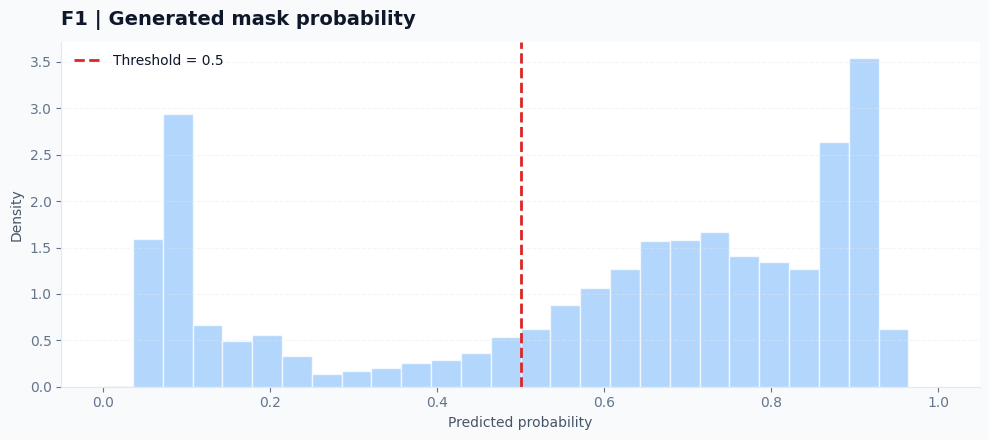

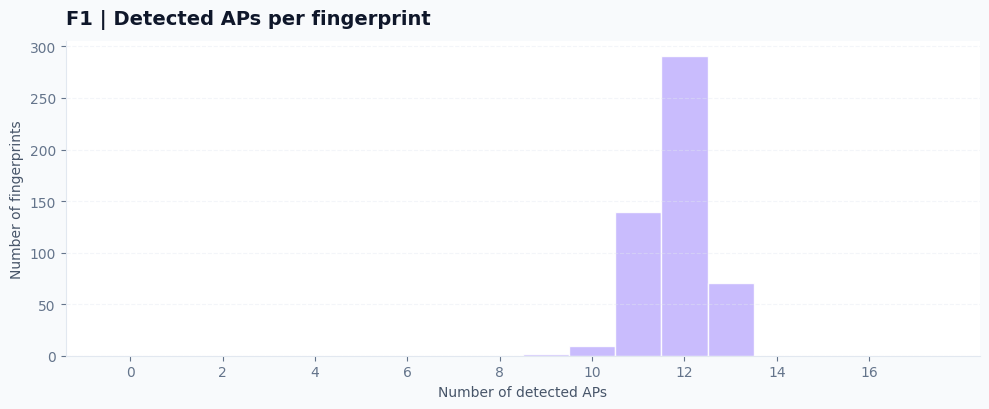

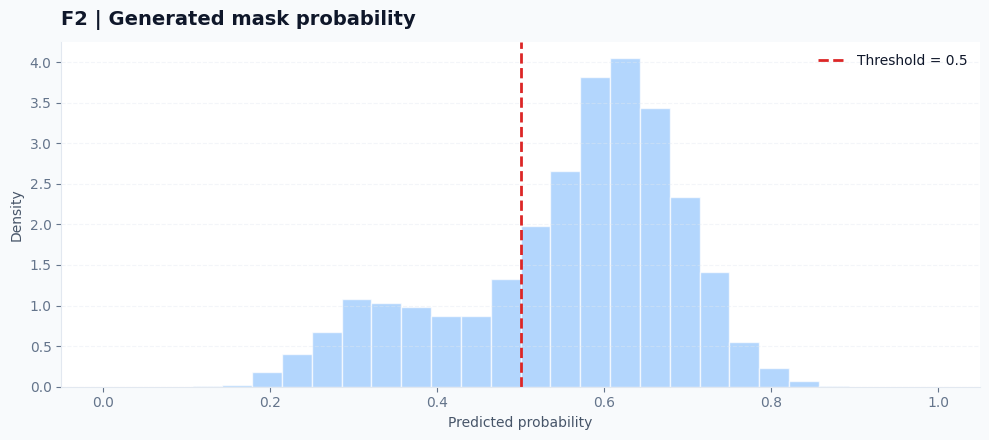

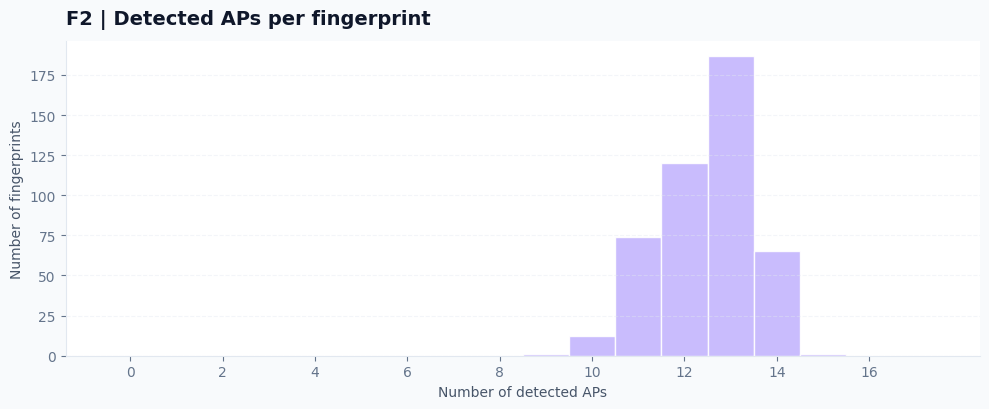

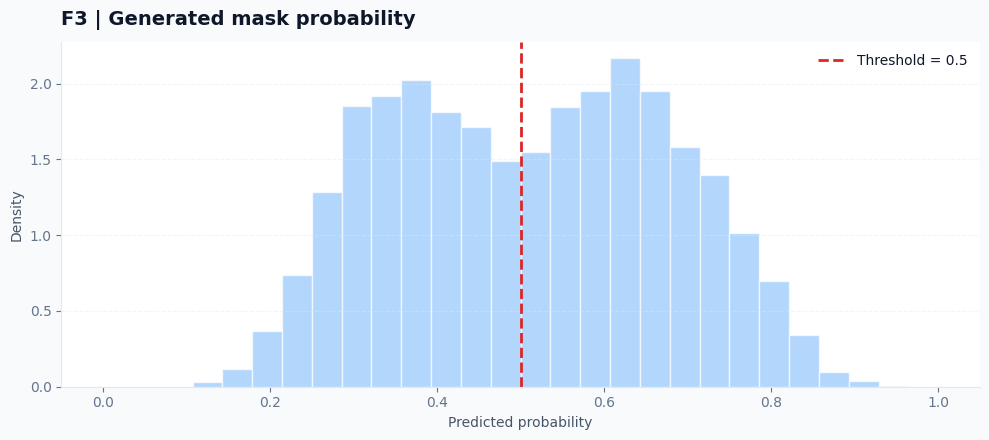

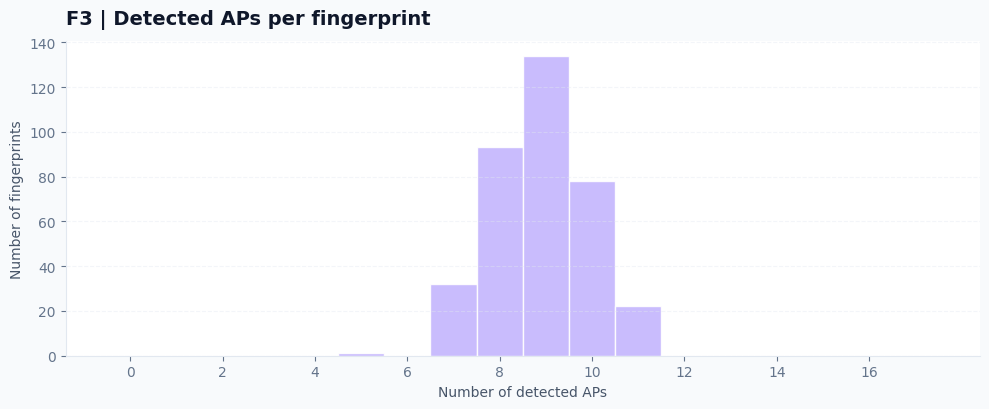

,Tầng,Số fingerprint,Tỷ lệ phát hiện (%),AP trung bình / mẫu,Mask trùng khớp,Max |delta prob|,Max |delta RSSI norm|,RSSI sinh nhỏ nhất (dBm),RSSI sinh lớn nhất (dBm)
0,F1,512,69.53,11.82,True,0.000e+00,0.000e+00,-97.99,-43.91
1,F2,460,73.39,12.48,True,0.000e+00,0.000e+00,-92.82,-44.65
2,F3,360,52.30,8.89,True,0.000e+00,0.000e+00,-92.93,-50.94


In [ ]:

# ============================================================
# CELL 3.19 — REPRODUCIBILITY & FINGERPRINT SANITY CHECK
# ============================================================

import os
import copy
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, HTML

AP_COLS = [f"AP{i}" for i in range(1, 18)]
CHECKPOINT_DIR = "/content/cgan_checkpoints"
N_CHECK = 512
MASK_THRESHOLD = 0.5

# ------------------------------------------------------------
# MODERN STYLE
# ------------------------------------------------------------
plt.rcParams.update({
    "figure.facecolor": "#F8FAFC",
    "axes.facecolor": "#FFFFFF",
    "axes.edgecolor": "#E2E8F0",
    "axes.labelcolor": "#475569",
    "axes.titlecolor": "#0F172A",
    "xtick.color": "#64748B",
    "ytick.color": "#64748B",
    "font.size": 10,
    "axes.titlesize": 14,
    "grid.color": "#E2E8F0",
    "grid.alpha": 0.6
})

COLORS = {
    "blue": "#2563EB",
    "purple": "#7C3AED",
    "green": "#059669",
    "orange": "#F59E0B",
    "red": "#DC2626",
    "pink": "#EC4899"
}

def box_319(title, message, color="#2563EB", bg="#EFF6FF"):
    display(HTML(f"""
    <div style="
        background:{bg};
        border-left:5px solid {color};
        border-radius:12px;
        padding:14px 18px;
        margin:12px 0;
        font-family:Arial,sans-serif;
        color:#1E293B;
        line-height:1.6;
        box-shadow:0 2px 8px rgba(15,23,42,.04)">
        <b>{title}</b><br>{message}
    </div>
    """))

def card_319(title, value, subtitle, color):
    return f"""
    <div style="background:white;border:1px solid #E2E8F0;
        border-top:4px solid {color};border-radius:12px;
        padding:14px;min-width:150px;flex:1">
        <div style="font-size:12px;color:#64748B">{title}</div>
        <div style="font-size:24px;font-weight:750;color:{color};
                    margin:5px 0">{value}</div>
        <div style="font-size:11px;color:#64748B">{subtitle}</div>
    </div>
    """

def find_state(checkpoint, names):
    for name in names:
        value = checkpoint.get(name)
        if isinstance(value, dict):
            return value
    return None

def find_model_key(floor, names):
    for name in names:
        value = models[floor].get(name)
        if isinstance(value, torch.nn.Module):
            return value
    return None

box_319(
    "REPRODUCIBILITY & FINGERPRINT AUDIT",
    "Kiểm tra suy luận với checkpoint trên mô hình độc lập. "
    "Không cập nhật trọng số và không dùng tập test.",
    COLORS["blue"], "#EFF6FF"
)

if "models" not in globals() or not isinstance(models, dict):
    raise RuntimeError("Không tìm thấy biến models.")
if "normalized_coords" not in globals():
    raise RuntimeError(
        "Không tìm thấy normalized_coords. "
        "Cần kiểm tra lại cell chuẩn hóa tọa độ."
    )
if not os.path.isdir(CHECKPOINT_DIR):
    raise FileNotFoundError(CHECKPOINT_DIR)

device = torch.device(DEVICE)
results_319 = {}
summary_319 = []

# ------------------------------------------------------------
# KIỂM TRA TỪNG TẦNG
# ------------------------------------------------------------
for floor in ["F1", "F2", "F3"]:

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR, f"{floor}_best.pt"
    )
    if not os.path.isfile(checkpoint_path):
        raise FileNotFoundError(checkpoint_path)

    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=False
        )
    except TypeError:
        checkpoint = torch.load(checkpoint_path, map_location="cpu")

    saved_G = find_state(
        checkpoint, ["G", "generator", "G_state_dict",
                     "generator_state_dict"]
    )
    if saved_G is None:
        raise KeyError(f"{floor}: không tìm thấy Generator state_dict.")

    # Tạo bản sao độc lập từ kiến trúc đang có.
    # Không sửa mô hình gốc trong models.
    source_G = find_model_key(floor, ["G", "generator"])
    if source_G is None:
        raise KeyError(f"{floor}: không tìm thấy Generator trong models.")

    G_check = copy.deepcopy(source_G).to(device)
    G_check.load_state_dict(saved_G, strict=True)
    G_check.eval()

    # Lấy tọa độ đã chuẩn hóa của train/validation.
    # Đây là kiểm tra suy luận, không đánh giá định vị.
    coords_source = normalized_coords.get(floor)

    if isinstance(coords_source, dict):
        coords_array = coords_source.get(
            "val", coords_source.get("validation")
        )
    else:
        coords_array = None

    # Tương thích với notebook nếu normalized_coords lưu dạng khác:
    if coords_array is None:
        if "val_loaders" not in globals() or floor not in val_loaders:
            raise KeyError(
                f"{floor}: không tìm được tọa độ validation "
                "từ normalized_coords hoặc val_loaders."
            )

        collected_coords = []
        for batch in val_loaders[floor]:
            collected_coords.append(batch[0].cpu().numpy())

        coords_array = np.concatenate(collected_coords, axis=0)

    if torch.is_tensor(coords_array):
        coords_array = coords_array.detach().cpu().numpy()

    coords_array = np.asarray(coords_array, dtype=np.float32)

    if coords_array.ndim != 2 or coords_array.shape[1] != 2:
        raise ValueError(
            f"{floor}: tọa độ phải có shape (N, 2), "
            f"nhưng nhận được {coords_array.shape}."
        )

    # Chọn một tập tọa độ để kiểm tra; không sử dụng RSSI thật.
    n = min(N_CHECK, len(coords_array))
    if n == 0:
        raise ValueError(f"{floor}: không có tọa độ để kiểm tra.")

    coords = torch.as_tensor(
        coords_array[:n], dtype=torch.float32, device=device
    )

    # Cố định noise để so sánh hai lần suy luận.
    generator = torch.Generator(device=device)
    generator.manual_seed(31900)

    noise = torch.randn(
        n, LATENT_DIM,
        generator=generator,
        device=device
    )

    with torch.no_grad():
        logits_1, rssi_norm_1 = G_check(coords, noise)
        logits_2, rssi_norm_2 = G_check(coords, noise)

        prob_1 = torch.sigmoid(logits_1)
        prob_2 = torch.sigmoid(logits_2)

        mask_1 = (prob_1 >= MASK_THRESHOLD).float()
        mask_2 = (prob_2 >= MASK_THRESHOLD).float()

    # Chuyển sang NumPy
    p1 = prob_1.cpu().numpy()
    p2 = prob_2.cpu().numpy()
    m1 = mask_1.cpu().numpy()
    m2 = mask_2.cpu().numpy()

    r1 = rssi_norm_1.cpu().numpy() * 80.0 - 100.0
    r2 = rssi_norm_2.cpu().numpy() * 80.0 - 100.0

    # RSSI chỉ có ý nghĩa vật lý tại AP được dự đoán phát hiện.
    # Vẫn kiểm tra miền toàn bộ đầu ra riêng để phát hiện lỗi số.
    prob_diff = float(np.max(np.abs(p1 - p2)))
    rssi_norm_diff = float(np.max(np.abs(rssi_norm_1.cpu().numpy()
                                         - rssi_norm_2.cpu().numpy())))
    mask_equal = bool(np.array_equal(m1, m2))

    detected_rssi = r1[m1 == 1]
    n_detected = int(m1.sum())
    detection_rate = float(m1.mean() * 100)
    mean_aps_per_sample = float(m1.sum(axis=1).mean())

    summary_319.append({
        "Tầng": floor,
        "Số fingerprint": n,
        "Tỷ lệ phát hiện (%)": detection_rate,
        "AP trung bình / mẫu": mean_aps_per_sample,
        "Mask trùng khớp": mask_equal,
        "Max |delta prob|": prob_diff,
        "Max |delta RSSI norm|": rssi_norm_diff,
        "RSSI sinh nhỏ nhất (dBm)": (
            float(detected_rssi.min()) if n_detected else np.nan
        ),
        "RSSI sinh lớn nhất (dBm)": (
            float(detected_rssi.max()) if n_detected else np.nan
        )
    })

    results_319[floor] = {
        "coords": coords.cpu().numpy(),
        "prob": p1,
        "mask": m1,
        "rssi_dbm": r1
    }

    # --------------------------------------------------------
    # DASHBOARD KPI
    # --------------------------------------------------------
    cards = (
        card_319(
            "Fingerprints checked", f"{n:,}",
            "Số tọa độ được kiểm tra", COLORS["blue"]
        )
        + card_319(
            "Detection rate", f"{detection_rate:.1f}%",
            "Tỷ lệ AP dự đoán có mặt", COLORS["green"]
        )
        + card_319(
            "APs per fingerprint", f"{mean_aps_per_sample:.2f}",
            "Trung bình 17 AP", COLORS["purple"]
        )
        + card_319(
            "Repeatability",
            "PASS" if mask_equal and prob_diff == 0 and rssi_norm_diff == 0
            else "CHECK",
            "Cùng tọa độ và cùng noise",
            COLORS["green"] if mask_equal and prob_diff == 0 and rssi_norm_diff == 0
            else COLORS["orange"]
        )
    )

    box_319(
        f"FLOOR {floor}",
        "Đã nạp checkpoint vào bản sao Generator độc lập.",
        COLORS["purple"], "#F5F3FF"
    )

    display(HTML(f"""
    <div style="display:flex;flex-wrap:wrap;gap:12px;margin:12px 0">
        {cards}
    </div>
    """))

    # --------------------------------------------------------
    # BIỂU ĐỒ A — PHÂN BỐ XÁC SUẤT MASK
    # --------------------------------------------------------
    fig, ax = plt.subplots(figsize=(10, 4.5))

    ax.hist(
        p1.ravel(), bins=28, range=(0, 1),
        density=True, color="#93C5FD",
        edgecolor="white", alpha=0.7
    )

    ax.axvline(
        MASK_THRESHOLD, color=COLORS["red"],
        linestyle="--", linewidth=2,
        label=f"Threshold = {MASK_THRESHOLD:.1f}"
    )

    ax.set_title(
        f"{floor} | Generated mask probability",
        loc="left", fontweight="bold", pad=12
    )
    ax.set_xlabel("Predicted probability")
    ax.set_ylabel("Density")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend()

    fig.tight_layout()
    plt.show()
    plt.close(fig)

    # --------------------------------------------------------
    # BIỂU ĐỒ B — SỐ AP ĐƯỢC PHÁT HIỆN TRÊN MỖI MẪU
    # --------------------------------------------------------
    aps_per_sample = m1.sum(axis=1)

    fig, ax = plt.subplots(figsize=(10, 4.2))

    bins = np.arange(-0.5, 18.5, 1)
    ax.hist(
        aps_per_sample, bins=bins,
        color="#C4B5FD", edgecolor="white", alpha=0.9
    )

    ax.set_title(
        f"{floor} | Detected APs per fingerprint",
        loc="left", fontweight="bold", pad=12
    )
    ax.set_xlabel("Number of detected APs")
    ax.set_ylabel("Number of fingerprints")
    ax.set_xticks(range(0, 18, 2))
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()
    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# TỔNG HỢP BA TẦNG
# ------------------------------------------------------------
summary_df_319 = pd.DataFrame(summary_319)

box_319(
    "CROSS-FLOOR SUMMARY",
    "Tổng hợp tính tái lập, tỷ lệ phát hiện và miền RSSI sinh.",
    COLORS["blue"], "#EFF6FF"
)

display(
    summary_df_319.style.format({
        "Số fingerprint": "{:.0f}",
        "Tỷ lệ phát hiện (%)": "{:.2f}",
        "AP trung bình / mẫu": "{:.2f}",
        "Max |delta prob|": "{:.3e}",
        "Max |delta RSSI norm|": "{:.3e}",
        "RSSI sinh nhỏ nhất (dBm)": "{:.2f}",
        "RSSI sinh lớn nhất (dBm)": "{:.2f}"
    }, na_rep="—")
    .background_gradient(
        subset=["Tỷ lệ phát hiện (%)"], cmap="PuBu"
    )
)

box_319(
    "CELL 3.19 COMPLETED",
    "Đã kiểm tra khả năng tái lập và miền đầu ra. "
    "Không cập nhật trọng số, không ghi đè checkpoint và không dùng test.",
    COLORS["green"], "#ECFDF5"
)



## Cell 3.20 — So sánh fingerprint thật và fingerprint sinh

**Mục tiêu:**
- So sánh tỷ lệ phát hiện AP và số AP trung bình trên mỗi fingerprint.
- So sánh RSSI trên các AP thực sự được phát hiện.
- Đánh giá riêng từng tầng F1, F2, F3 trên tập validation.
- Chỉ đánh giá chất lượng dữ liệu sinh, không cập nhật trọng số và không sử dụng tập test.

**Lưu ý:** Đây là kiểm tra phân bố dữ liệu, chưa phải đánh giá sai số định vị.


Tầng,Số mẫu validation,AP phát hiện thật (%),AP phát hiện sinh (%),Chênh lệch tỷ lệ (điểm %),AP trung bình thật,AP trung bình sinh,RSSI thật trung bình (dBm),RSSI sinh trung bình (dBm)
F1,760,59.94,69.39,9.45,10.19,11.80,-68.69,-76.28
F2,460,60.27,72.69,12.42,10.25,12.36,-68.51,-70.96
F3,360,46.73,52.73,6.00,7.94,8.96,-74.85,-75.96


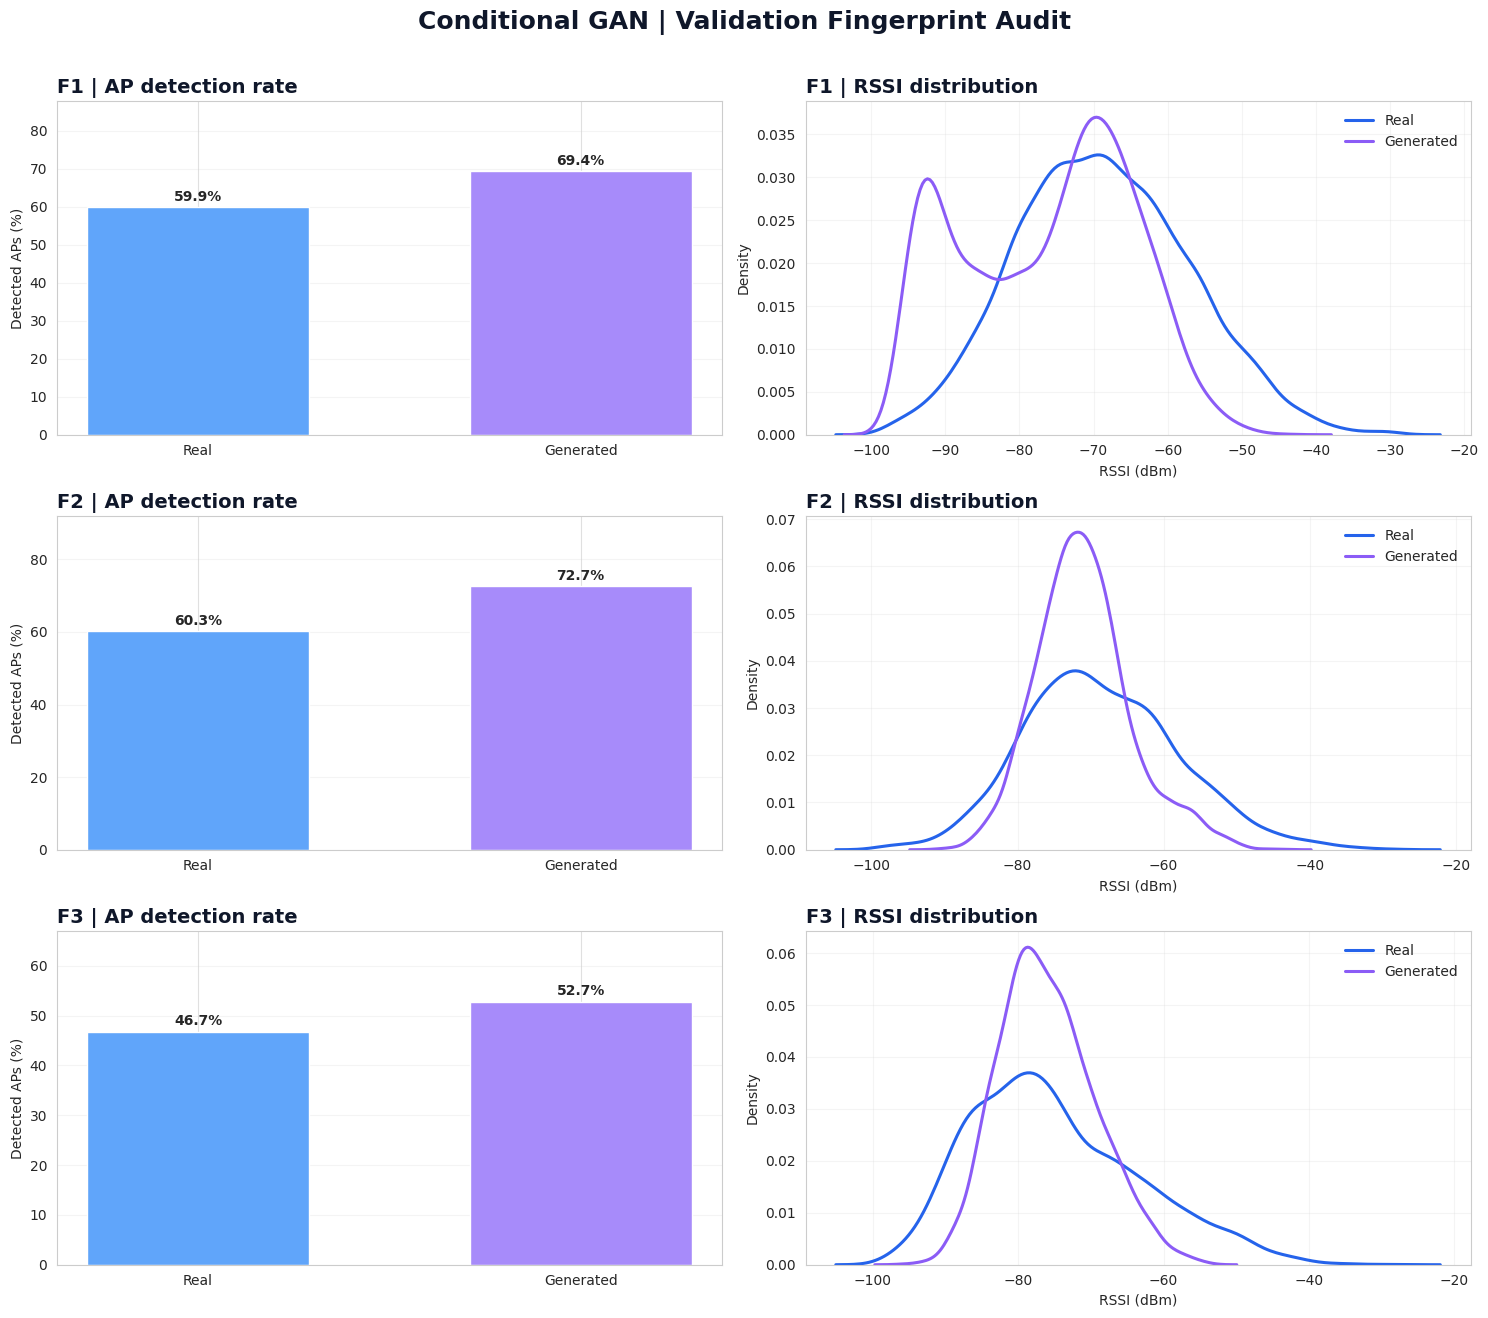

CELL 3.20 COMPLETED
F1: real AP rate=59.94% | generated=69.39% | gap=9.45 pp | AP/sample real=10.19, generated=11.80
F2: real AP rate=60.27% | generated=72.69% | gap=12.42 pp | AP/sample real=10.25, generated=12.36
F3: real AP rate=46.73% | generated=52.73% | gap=6.00 pp | AP/sample real=7.94, generated=8.96

Lưu ý: Đây là so sánh phân bố trên validation, không phải sai số định vị.
Chưa kết luận cGAN cải thiện định vị; cần đánh giá mô hình định vị trên cùng tập test độc lập.


In [ ]:

# ============================================================
# CELL 3.20 — REAL vs GENERATED FINGERPRINTS
# ============================================================

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

# ---------- Giao diện ----------
plt.rcParams.update({
    "figure.facecolor": "#F7F9FC",
    "axes.facecolor": "#FFFFFF",
    "axes.edgecolor": "#DCE3ED",
    "axes.labelcolor": "#475569",
    "xtick.color": "#64748B",
    "ytick.color": "#64748B",
    "axes.titleweight": "bold",
    "font.size": 10
})
sns.set_style("whitegrid")

def c320_card(title, value, subtitle, color="#2563EB"):
    return f"""
    <div style="background:white;border:1px solid #E2E8F0;
        border-left:5px solid {color};border-radius:12px;
        padding:14px 16px;min-width:150px;flex:1;">
        <div style="color:#64748B;font-size:12px;">{title}</div>
        <div style="color:#0F172A;font-size:25px;font-weight:750;
            margin:5px 0;">{value}</div>
        <div style="color:#64748B;font-size:11px;">{subtitle}</div>
    </div>
    """

def c320_get_generator(floor):
    item = models[floor]
    if isinstance(item, dict):
        G = item.get("G", item.get("generator"))
    else:
        G = item
    if G is None:
        raise KeyError(f"Không tìm thấy Generator của {floor}.")
    return G

def c320_get_val_batch(floor):
    """Lấy toàn bộ validation từ val_loaders, không dùng test."""
    loader = val_loaders[floor]
    coords_list, rssi_list, mask_list = [], [], []

    for batch in loader:
        coords, rssi, mask = batch[:3]
        coords_list.append(coords.detach().cpu())
        rssi_list.append(rssi.detach().cpu())
        mask_list.append(mask.detach().cpu())

    return (
        torch.cat(coords_list, dim=0),
        torch.cat(rssi_list, dim=0),
        torch.cat(mask_list, dim=0)
    )

def c320_generate(G, coords, seed):
    """Sinh dữ liệu với noise cố định để có thể tái lập."""
    G.eval()
    device = next(G.parameters()).device
    coords = coords.to(device)

    generator = torch.Generator(device=device)
    generator.manual_seed(seed)
    noise = torch.randn(
        coords.shape[0], LATENT_DIM,
        generator=generator, device=device
    )

    with torch.no_grad():
        output = G(coords, noise)

    # Tương thích với Generator trả về tuple/list hoặc dict
    if isinstance(output, dict):
        mask_logits = output.get("mask_logits", output.get("mask"))
        rssi_norm = output.get("rssi_norm", output.get("rssi"))
    elif isinstance(output, (tuple, list)):
        mask_logits, rssi_norm = output[:2]
    else:
        raise TypeError("Không nhận diện được đầu ra Generator.")

    if mask_logits is None or rssi_norm is None:
        raise ValueError("Generator không trả đủ mask và RSSI.")

    mask_prob = torch.sigmoid(mask_logits).cpu().numpy()
    rssi_norm = rssi_norm.cpu().numpy()

    # Dùng ngưỡng 0.5 nhất quán với các cell kiểm tra trước
    gen_mask = (mask_prob >= 0.5).astype(np.float32)

    return gen_mask, rssi_norm, mask_prob

# ---------- Kiểm tra cấu hình ----------
required_vars = ["models", "val_loaders", "LATENT_DIM"]
missing_vars = [v for v in required_vars if v not in globals()]

if missing_vars:
    raise NameError(
        f"Thiếu biến {missing_vars}. Hãy kiểm tra các cell chuẩn bị mô hình."
    )

floors = ["F1", "F2", "F3"]
results = {}
summary_rows = []

for floor_idx, floor in enumerate(floors):
    coords_val, real_rssi, real_mask = c320_get_val_batch(floor)

    G = c320_get_generator(floor)
    gen_mask, gen_rssi_norm, gen_prob = c320_generate(
        G, coords_val, seed=32000 + floor_idx
    )

    real_rssi = real_rssi.numpy()
    real_mask = real_mask.numpy()

    # Chuẩn hóa kiểu dữ liệu và kiểm tra kích thước
    real_mask = (real_mask > 0.5).astype(np.float32)
    if gen_mask.shape != real_mask.shape:
        raise ValueError(
            f"{floor}: mask sinh {gen_mask.shape} khác mask thật "
            f"{real_mask.shape}."
        )

    if gen_rssi_norm.shape != real_rssi.shape:
        raise ValueError(
            f"{floor}: RSSI sinh {gen_rssi_norm.shape} khác RSSI thật "
            f"{real_rssi.shape}."
        )

    # Dữ liệu RSSI thật trong miền chuẩn hóa [0, 1].
    # RSSI_MIN/RSSI_MAX phải giống các cell tiền xử lý trước.
    real_rssi_dbm = real_rssi * (RSSI_MAX - RSSI_MIN) + RSSI_MIN
    gen_rssi_dbm = gen_rssi_norm * (RSSI_MAX - RSSI_MIN) + RSSI_MIN

    # Chỉ so sánh RSSI tại AP được phát hiện:
    # thật: real_mask; sinh: gen_mask.
    real_detected_rssi = real_rssi_dbm[real_mask > 0.5]
    gen_detected_rssi = gen_rssi_dbm[gen_mask > 0.5]

    real_detection_rate = float(real_mask.mean() * 100)
    gen_detection_rate = float(gen_mask.mean() * 100)

    real_aps = real_mask.sum(axis=1)
    gen_aps = gen_mask.sum(axis=1)

    real_rssi_mean = (
        float(real_detected_rssi.mean())
        if real_detected_rssi.size else np.nan
    )
    gen_rssi_mean = (
        float(gen_detected_rssi.mean())
        if gen_detected_rssi.size else np.nan
    )

    # Chỉ số mô tả độ khác biệt mask, không phải độ chính xác định vị
    mask_gap_pp = abs(gen_detection_rate - real_detection_rate)
    aps_gap = abs(float(gen_aps.mean() - real_aps.mean()))

    results[floor] = {
        "real_mask": real_mask,
        "gen_mask": gen_mask,
        "real_rssi_dbm": real_rssi_dbm,
        "gen_rssi_dbm": gen_rssi_dbm,
        "real_detected_rssi": real_detected_rssi,
        "gen_detected_rssi": gen_detected_rssi,
        "real_aps": real_aps,
        "gen_aps": gen_aps,
        "real_detection_rate": real_detection_rate,
        "gen_detection_rate": gen_detection_rate,
        "real_rssi_mean": real_rssi_mean,
        "gen_rssi_mean": gen_rssi_mean,
        "mask_gap_pp": mask_gap_pp,
        "aps_gap": aps_gap,
        "n": len(real_mask)
    }

    summary_rows.append({
        "Tầng": floor,
        "Số mẫu validation": len(real_mask),
        "AP phát hiện thật (%)": real_detection_rate,
        "AP phát hiện sinh (%)": gen_detection_rate,
        "Chênh lệch tỷ lệ (điểm %)": mask_gap_pp,
        "AP trung bình thật": float(real_aps.mean()),
        "AP trung bình sinh": float(gen_aps.mean()),
        "RSSI thật trung bình (dBm)": real_rssi_mean,
        "RSSI sinh trung bình (dBm)": gen_rssi_mean
    })

summary_df = pd.DataFrame(summary_rows)

# ---------- KPI tổng quan ----------
mean_mask_gap = summary_df["Chênh lệch tỷ lệ (điểm %)"].mean()
mean_aps_gap = np.mean([results[f]["aps_gap"] for f in floors])

display(HTML(
    '<h2 style="color:#0F172A;margin-bottom:4px;">'
    'CELL 3.20 | REAL vs GENERATED</h2>'
    '<p style="color:#64748B;margin-top:0;">'
    'Đối chiếu trên validation; checkpoint giữ nguyên; test không được sử dụng.'
    '</p>'
    '<div style="display:flex;gap:12px;flex-wrap:wrap;margin:12px 0 20px;">'
    + c320_card("Tầng đánh giá", "3", "F1 · F2 · F3", "#2563EB")
    + c320_card("Chênh lệch tỷ lệ AP", f"{mean_mask_gap:.2f} pp",
                "Trung bình 3 tầng; càng thấp càng gần", "#7C3AED")
    + c320_card("Chênh lệch AP/mẫu", f"{mean_aps_gap:.2f}",
                "Số AP trung bình; càng thấp càng gần", "#0891B2")
    + '</div>'
))

# ---------- Bảng tổng hợp ----------
display(
    summary_df.style
    .format({
        "AP phát hiện thật (%)": "{:.2f}",
        "AP phát hiện sinh (%)": "{:.2f}",
        "Chênh lệch tỷ lệ (điểm %)": "{:.2f}",
        "AP trung bình thật": "{:.2f}",
        "AP trung bình sinh": "{:.2f}",
        "RSSI thật trung bình (dBm)": "{:.2f}",
        "RSSI sinh trung bình (dBm)": "{:.2f}"
    })
    .background_gradient(
        subset=["Chênh lệch tỷ lệ (điểm %)"], cmap="RdYlGn_r"
    )
    .hide(axis="index")
)

# ---------- Dashboard theo từng tầng ----------
fig, axes = plt.subplots(3, 2, figsize=(15, 13))
fig.suptitle(
    "Conditional GAN | Validation Fingerprint Audit",
    fontsize=18, fontweight="bold", color="#0F172A", y=1.01
)

for i, floor in enumerate(floors):
    r = results[floor]
    ax_mask, ax_rssi = axes[i]

    # Biểu đồ 1: tỷ lệ AP phát hiện
    labels = ["Real", "Generated"]
    rates = [r["real_detection_rate"], r["gen_detection_rate"]]
    bars = ax_mask.bar(
        labels, rates,
        color=["#60A5FA", "#A78BFA"], width=0.58
    )
    ax_mask.set_title(f"{floor} | AP detection rate", loc="left")
    ax_mask.set_ylabel("Detected APs (%)")
    ax_mask.set_ylim(0, max(rates) * 1.25 + 1)
    ax_mask.grid(axis="y", alpha=0.2)

    for bar, value in zip(bars, rates):
        ax_mask.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.8,
            f"{value:.1f}%",
            ha="center", va="bottom", fontweight="bold"
        )

    # Biểu đồ 2: phân bố RSSI ở các AP được phát hiện
    real_vals = r["real_detected_rssi"]
    gen_vals = r["gen_detected_rssi"]

    if real_vals.size and gen_vals.size:
        sns.kdeplot(
            x=real_vals, ax=ax_rssi, color="#2563EB",
            linewidth=2.2, label="Real", fill=False
        )
        sns.kdeplot(
            x=gen_vals, ax=ax_rssi, color="#8B5CF6",
            linewidth=2.2, label="Generated", fill=False
        )
        ax_rssi.legend(frameon=False)

    ax_rssi.set_title(f"{floor} | RSSI distribution", loc="left")
    ax_rssi.set_xlabel("RSSI (dBm)")
    ax_rssi.set_ylabel("Density")
    ax_rssi.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# ---------- Kết luận tự động có điều kiện ----------
print("=" * 72)
print("CELL 3.20 COMPLETED")
print("=" * 72)

for floor in floors:
    r = results[floor]
    print(
        f"{floor}: real AP rate={r['real_detection_rate']:.2f}% | "
        f"generated={r['gen_detection_rate']:.2f}% | "
        f"gap={r['mask_gap_pp']:.2f} pp | "
        f"AP/sample real={r['real_aps'].mean():.2f}, "
        f"generated={r['gen_aps'].mean():.2f}"
    )

print(
    "\nLưu ý: Đây là so sánh phân bố trên validation, "
    "không phải sai số định vị."
)
print(
    "Chưa kết luận cGAN cải thiện định vị; cần đánh giá mô hình định vị "
    "trên cùng tập test độc lập."
)



## Cell 3.21 — Tổng hợp chất lượng dữ liệu sinh cGAN

**Mục tiêu:**
- Tổng hợp kết quả so sánh fingerprint thật và sinh trên validation.
- Đánh giá mức chênh lệch tỷ lệ phát hiện AP, số AP trung bình và RSSI.
- Đưa ra nhận định về khả năng sử dụng dữ liệu cGAN cho tăng cường dữ liệu.

**Nguyên tắc:** Chỉ tổng hợp kết quả đã có; không huấn luyện lại, không cập nhật checkpoint và không sử dụng tập test.


Tầng,Mẫu validation,Chênh lệch AP (điểm %),Chênh lệch AP/mẫu,Chênh lệch RSSI (dB),Đánh giá sơ bộ
F1,760,+9.45,+1.61,-7.59,Còn sai lệch
F2,460,+12.42,+2.11,-2.45,Còn sai lệch
F3,360,+6.00,+1.02,-1.11,Gần hơn tương đối


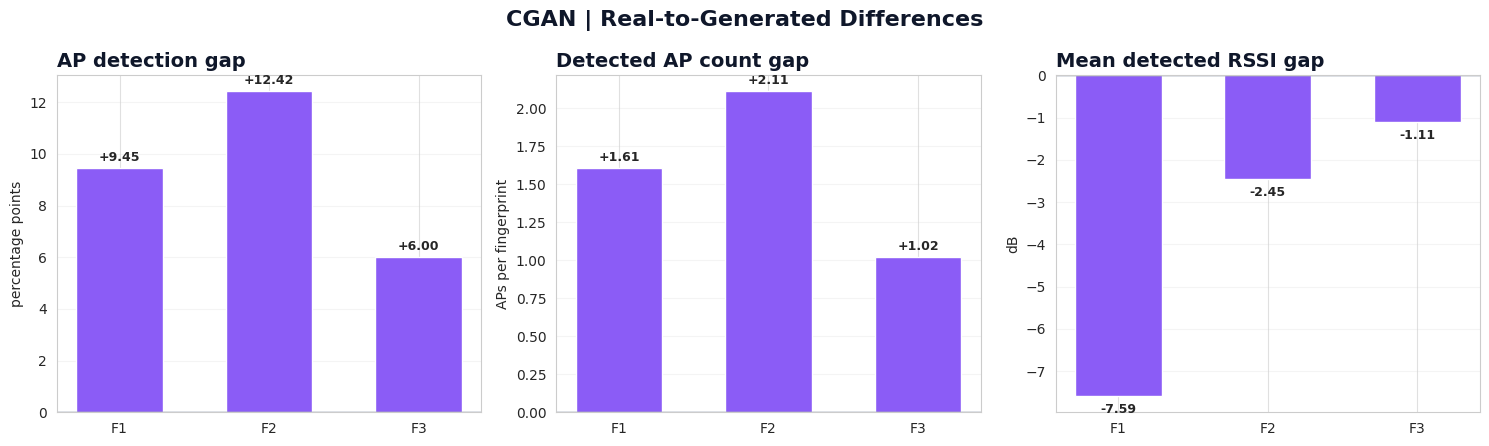

CELL 3.21 COMPLETED
1. Generator đã hoạt động và có thể tái lập đầu ra.
2. Phân bố fingerprint sinh vẫn khác dữ liệu thật ở cả ba tầng.
3. F2 có chênh lệch tỷ lệ phát hiện AP lớn nhất trong kết quả hiện tại.
4. Chưa đủ bằng chứng để kết luận dữ liệu sinh cải thiện định vị.

QUYẾT ĐỊNH:
- Giữ checkpoint cGAN làm kết quả thực nghiệm hiện tại.
- Chưa mặc định trộn dữ liệu sinh vào tập huấn luyện chính.
- Nếu thử tăng cường dữ liệu, phải so sánh với baseline trên cùng test.
- Không dùng tập test để chỉnh mô hình hoặc chọn ngưỡng.


In [ ]:

# ============================================================
# CELL 3.21 — CGAN QUALITY SUMMARY & USAGE DECISION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

floors = ["F1", "F2", "F3"]

if "results" not in globals() or not all(f in results for f in floors):
    raise NameError(
        "Không tìm thấy kết quả Cell 3.20. "
        "Hãy chạy Cell 3.20 trước."
    )

rows = []

for floor in floors:
    r = results[floor]

    real_rate = float(r["real_detection_rate"])
    gen_rate = float(r["gen_detection_rate"])
    real_aps = float(np.mean(r["real_aps"]))
    gen_aps = float(np.mean(r["gen_aps"]))
    real_rssi = float(r["real_rssi_mean"])
    gen_rssi = float(r["gen_rssi_mean"])

    rows.append({
        "Tầng": floor,
        "Mẫu validation": int(r["n"]),
        "Chênh lệch AP (điểm %)": gen_rate - real_rate,
        "Chênh lệch AP/mẫu": gen_aps - real_aps,
        "Chênh lệch RSSI (dB)": gen_rssi - real_rssi,
        "Đánh giá sơ bộ": (
            "Gần hơn tương đối"
            if abs(gen_rate - real_rate) < 7
            else "Còn sai lệch"
        )
    })

quality_df = pd.DataFrame(rows)

mean_rate_gap = quality_df["Chênh lệch AP (điểm %)"].abs().mean()
mean_count_gap = quality_df["Chênh lệch AP/mẫu"].abs().mean()
mean_rssi_gap = quality_df["Chênh lệch RSSI (dB)"].abs().mean()

display(HTML("""
<div style="background:#F8FAFC;border:1px solid #DCE3ED;
border-radius:14px;padding:18px;margin-bottom:14px;">
<h2 style="color:#0F172A;margin:0 0 6px;">
CGAN QUALITY REVIEW
</h2>
<p style="color:#64748B;margin:0;">
Tổng hợp ba tầng từ kết quả validation của Cell 3.20.
</p>
</div>
"""))

display(HTML(
    '<div style="display:flex;gap:12px;flex-wrap:wrap;margin-bottom:16px;">'
    f'<div style="flex:1;min-width:170px;background:white;border:1px solid #E2E8F0;'
    f'border-radius:12px;padding:15px;"><div style="color:#64748B;font-size:12px;">'
    f'Chênh lệch tỷ lệ AP tuyệt đối</div><div style="font-size:25px;'
    f'font-weight:750;color:#7C3AED;">{mean_rate_gap:.2f} pp</div></div>'
    f'<div style="flex:1;min-width:170px;background:white;border:1px solid #E2E8F0;'
    f'border-radius:12px;padding:15px;"><div style="color:#64748B;font-size:12px;">'
    f'Chênh lệch AP/mẫu tuyệt đối</div><div style="font-size:25px;'
    f'font-weight:750;color:#2563EB;">{mean_count_gap:.2f}</div></div>'
    f'<div style="flex:1;min-width:170px;background:white;border:1px solid #E2E8F0;'
    f'border-radius:12px;padding:15px;"><div style="color:#64748B;font-size:12px;">'
    f'Chênh lệch RSSI trung bình tuyệt đối</div><div style="font-size:25px;'
    f'font-weight:750;color:#0891B2;">{mean_rssi_gap:.2f} dB</div></div>'
    '</div>'
))

display(
    quality_df.style.format({
        "Chênh lệch AP (điểm %)": "{:+.2f}",
        "Chênh lệch AP/mẫu": "{:+.2f}",
        "Chênh lệch RSSI (dB)": "{:+.2f}"
    }).background_gradient(
        subset=["Chênh lệch AP (điểm %)"],
        cmap="RdYlGn_r",
        vmin=-15,
        vmax=15
    ).hide(axis="index")
)

# ---------- Biểu đồ chênh lệch ----------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
fig.suptitle(
    "CGAN | Real-to-Generated Differences",
    fontsize=16, fontweight="bold", color="#0F172A"
)

plot_specs = [
    ("Chênh lệch AP (điểm %)", "AP detection gap", "percentage points"),
    ("Chênh lệch AP/mẫu", "Detected AP count gap", "APs per fingerprint"),
    ("Chênh lệch RSSI (dB)", "Mean detected RSSI gap", "dB")
]

for ax, (column, title, ylabel) in zip(axes, plot_specs):
    values = quality_df[column].values
    bar_colors = [
        "#10B981" if abs(v) < 1 else "#8B5CF6"
        for v in values
    ]
    bars = ax.bar(quality_df["Tầng"], values, color=bar_colors, width=0.58)
    ax.axhline(0, color="#64748B", linewidth=1)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.2)

    for bar, value in zip(bars, values):
        offset = 0.04 if value >= 0 else -0.04
        ax.annotate(
            f"{value:+.2f}",
            (bar.get_x() + bar.get_width()/2, value),
            xytext=(0, 5 if value >= 0 else -12),
            textcoords="offset points",
            ha="center", fontsize=9, fontweight="bold"
        )

plt.tight_layout()
plt.show()

# ---------- Kết luận dựa trên kết quả thực tế ----------
print("=" * 68)
print("CELL 3.21 COMPLETED")
print("=" * 68)

print("1. Generator đã hoạt động và có thể tái lập đầu ra.")
print("2. Phân bố fingerprint sinh vẫn khác dữ liệu thật ở cả ba tầng.")
print("3. F2 có chênh lệch tỷ lệ phát hiện AP lớn nhất trong kết quả hiện tại.")
print("4. Chưa đủ bằng chứng để kết luận dữ liệu sinh cải thiện định vị.")
print()
print("QUYẾT ĐỊNH:")
print("- Giữ checkpoint cGAN làm kết quả thực nghiệm hiện tại.")
print("- Chưa mặc định trộn dữ liệu sinh vào tập huấn luyện chính.")
print("- Nếu thử tăng cường dữ liệu, phải so sánh với baseline trên cùng test.")
print("- Không dùng tập test để chỉnh mô hình hoặc chọn ngưỡng.")



## Cell 3.22 — Final CGAN Dashboard & Experiment Record

**Mục tiêu:**
- Tổng kết quá trình xây dựng và đánh giá cGAN trên F1, F2, F3.
- Hiển thị trực quan chất lượng fingerprint sinh và trạng thái checkpoint.
- Lưu bảng kết quả, cấu hình và báo cáo tổng kết.

**Phạm vi:** Chỉ tổng hợp kết quả đã có. Không huấn luyện lại, không ghi đè checkpoint và không sử dụng tập test.


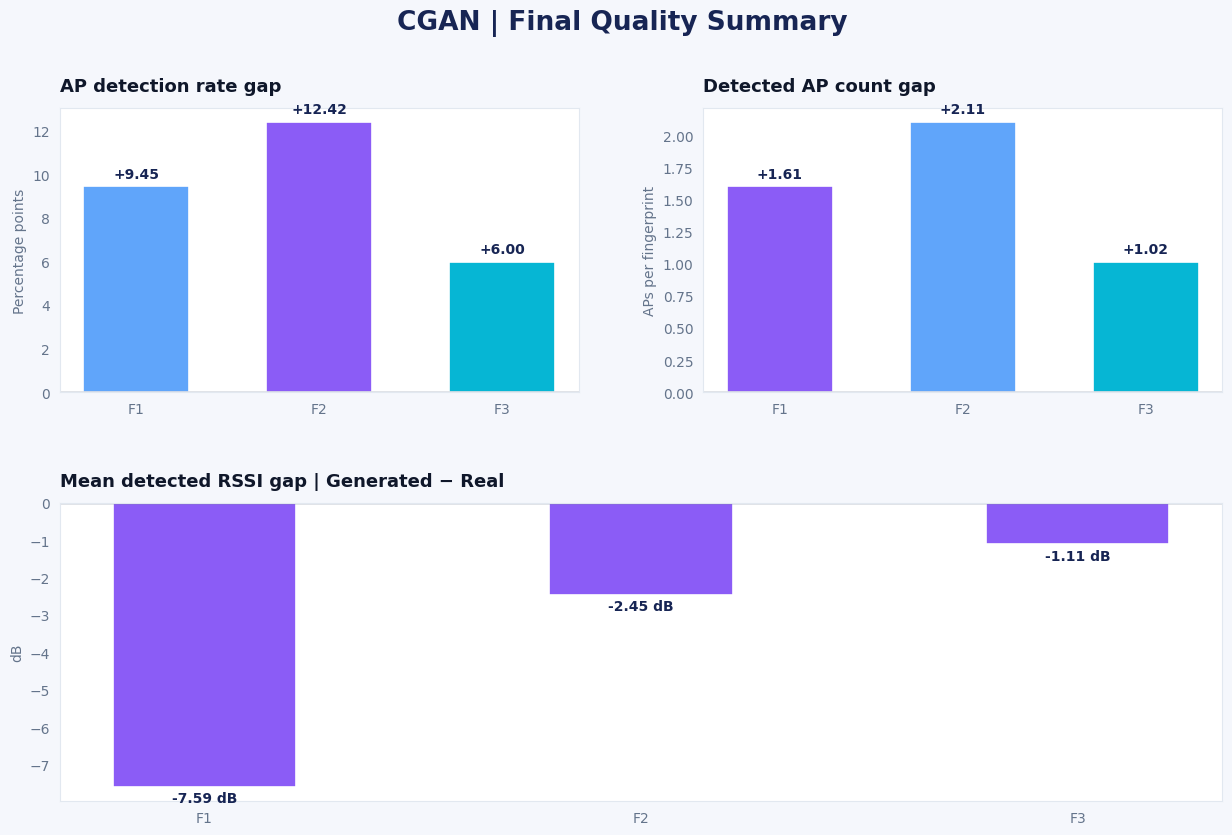

Tầng,Mẫu validation,Chênh lệch AP (điểm %),Chênh lệch AP/mẫu,Chênh lệch RSSI (dB),Đánh giá sơ bộ
F1,760,+9.45,+1.61,-7.59,Còn sai lệch
F2,460,+12.42,+2.11,-2.45,Còn sai lệch
F3,360,+6.00,+1.02,-1.11,Gần hơn tương đối


,Thông tin,Giá trị
0,Phương pháp,Conditional GAN (cGAN)
1,Các tầng,"F1, F2, F3"
2,Số AP,17
3,Latent dimension,16
4,Hidden dimension,128
5,Learning rate,Chưa xác minh
6,Batch size,64
7,Epoch tối đa,100
8,RSSI min (dBm),-100.0
9,RSSI max (dBm),-20.0


CELL 3.22 COMPLETED — CGAN STAGE CLOSED
Checkpoint status: 3/3
Không huấn luyện lại, không ghi đè checkpoint, không sử dụng test.
Kết luận: chất lượng phân bố fingerprint sinh còn sai lệch.
Chưa có cơ sở kết luận cGAN cải thiện độ chính xác định vị.
Sẵn sàng chuyển sang giai đoạn thử nghiệm tăng cường dữ liệu.


In [ ]:

# ============================================================
# CELL 3.22 — FINAL CGAN DASHBOARD & EXPERIMENT RECORD
# ============================================================

from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
from IPython.display import display, HTML

# ------------------------------------------------------------
# 1. VALIDATE INPUTS
# ------------------------------------------------------------
floors = ["F1", "F2", "F3"]

if "quality_df" not in globals() or "summary_df" not in globals():
    raise NameError(
        "Thiếu kết quả Cell 3.20/3.21. "
        "Không cần chạy lại các cell khác; hãy kiểm tra hai biến kết quả."
    )

required_columns = [
    "Tầng",
    "Chênh lệch AP (điểm %)",
    "Chênh lệch AP/mẫu",
    "Chênh lệch RSSI (dB)"
]
missing_columns = [
    c for c in required_columns if c not in quality_df.columns
]
if missing_columns:
    raise ValueError(f"quality_df thiếu cột: {missing_columns}")

# ------------------------------------------------------------
# 2. VISUAL THEME — MATCH PREVIOUS DASHBOARDS
# ------------------------------------------------------------
BG = "#F5F7FC"
NAVY = "#172554"
BLUE = "#60A5FA"
PURPLE = "#8B5CF6"
CYAN = "#06B6D4"
GREEN = "#10B981"
AMBER = "#F59E0B"
RED = "#EF4444"
MUTED = "#64748B"
BORDER = "#E2E8F0"
WHITE = "#FFFFFF"

plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": WHITE,
    "axes.edgecolor": BORDER,
    "axes.labelcolor": MUTED,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "text.color": NAVY,
    "axes.titleweight": "bold",
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.18,
    "grid.linestyle": "--"
})

def c322_card(title, value, note, color, icon):
    return f"""
    <div style="
        flex:1;min-width:165px;background:{WHITE};
        border:1px solid {BORDER};border-radius:16px;
        padding:17px 18px;box-shadow:0 3px 12px #0F172A0A;
        border-top:4px solid {color};">
        <div style="display:flex;justify-content:space-between;
                    align-items:center;">
            <span style="color:{MUTED};font-size:12px;
                         font-weight:600;">{title}</span>
            <span style="font-size:21px;">{icon}</span>
        </div>
        <div style="font-size:28px;font-weight:800;
                    color:{color};margin:8px 0 4px;">{value}</div>
        <div style="font-size:11px;color:{MUTED};">{note}</div>
    </div>
    """

# ------------------------------------------------------------
# 3. CHECKPOINT INVENTORY
# ------------------------------------------------------------
checkpoint_dir = Path("/content/cgan_checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

checkpoint_rows = []

for floor in floors:
    path = checkpoint_dir / f"{floor}_best.pt"
    row = {
        "Tầng": floor,
        "Checkpoint": str(path),
        "Trạng thái": "FOUND" if path.exists() else "MISSING",
        "Epoch tốt nhất": None,
        "Validation score": None
    }

    if path.exists():
        try:
            ckpt = torch.load(
                path, map_location="cpu", weights_only=True
            )
        except TypeError:
            ckpt = torch.load(path, map_location="cpu")

        row["Epoch tốt nhất"] = ckpt.get("epoch")
        row["Validation score"] = ckpt.get("val_score")

    checkpoint_rows.append(row)

checkpoint_df = pd.DataFrame(checkpoint_rows)
checkpoint_count = int((checkpoint_df["Trạng thái"] == "FOUND").sum())

# ------------------------------------------------------------
# 4. CONFIGURATION RECORD — UNKNOWN VALUES STAY UNKNOWN
# ------------------------------------------------------------
def c322_config(name):
    value = globals().get(name, None)
    return str(value) if value is not None else "Chưa xác minh"

config_df = pd.DataFrame([
    ("Phương pháp", "Conditional GAN (cGAN)"),
    ("Các tầng", "F1, F2, F3"),
    ("Số AP", c322_config("N_AP")),
    ("Latent dimension", c322_config("LATENT_DIM")),
    ("Hidden dimension", c322_config("HIDDEN_DIM")),
    ("Learning rate", c322_config("LR")),
    ("Batch size", c322_config("BATCH_SIZE")),
    ("Epoch tối đa", c322_config("EPOCHS")),
    ("RSSI min (dBm)", c322_config("RSSI_MIN")),
    ("RSSI max (dBm)", c322_config("RSSI_MAX")),
    ("Ngưỡng mask", "0.5"),
    ("Tập đánh giá chất lượng sinh", "Validation"),
    ("Sử dụng tập test", "Không"),
], columns=["Thông tin", "Giá trị"])

# ------------------------------------------------------------
# 5. COMPUTE SUMMARY METRICS
# ------------------------------------------------------------
rate_gap = quality_df["Chênh lệch AP (điểm %)"].abs()
count_gap = quality_df["Chênh lệch AP/mẫu"].abs()
rssi_gap = quality_df["Chênh lệch RSSI (dB)"].abs()

mean_rate_gap = float(rate_gap.mean())
mean_count_gap = float(count_gap.mean())
mean_rssi_gap = float(rssi_gap.mean())

validation_n = (
    int(summary_df["Số mẫu validation"].sum())
    if "Số mẫu validation" in summary_df.columns
    else int(quality_df["Mẫu validation"].sum())
    if "Mẫu validation" in quality_df.columns
    else None
)

# ------------------------------------------------------------
# 6. HEADER + COLORFUL KPI CARDS
# ------------------------------------------------------------
display(HTML(f"""
<div style="background:linear-gradient(120deg,#172554,#4C1D95);
            border-radius:18px;padding:24px 25px;color:white;
            margin:5px 0 16px;">
    <div style="font-size:12px;letter-spacing:2px;
                color:#C4B5FD;font-weight:700;">
        THESIS EXPERIMENT · PHASE 03
    </div>
    <div style="font-size:27px;font-weight:850;margin:7px 0;">
        Conditional GAN
    </div>
    <div style="font-size:13px;color:#E0E7FF;">
        Final experiment dashboard · F1 / F2 / F3
    </div>
    <div style="margin-top:14px;display:flex;gap:8px;flex-wrap:wrap;">
        <span style="background:#FFFFFF20;border-radius:20px;
                     padding:5px 10px;font-size:11px;">Validation audit</span>
        <span style="background:#FFFFFF20;border-radius:20px;
                     padding:5px 10px;font-size:11px;">Checkpoint preserved</span>
        <span style="background:#FFFFFF20;border-radius:20px;
                     padding:5px 10px;font-size:11px;">No test leakage</span>
    </div>
</div>
"""))

kpi_html = (
    '<div style="display:flex;gap:12px;flex-wrap:wrap;margin-bottom:18px;">'
    + c322_card(
        "Checkpoint đã lưu", f"{checkpoint_count}/3",
        "Generator tốt nhất theo validation", GREEN, "✓"
    )
    + c322_card(
        "Chênh lệch tỷ lệ AP", f"{mean_rate_gap:.2f} pp",
        "Trung bình tuyệt đối trên 3 tầng", PURPLE, "◈"
    )
    + c322_card(
        "Chênh lệch AP/mẫu", f"{mean_count_gap:.2f}",
        "Số AP trung bình mỗi fingerprint", BLUE, "▦"
    )
    + c322_card(
        "Chênh lệch RSSI", f"{mean_rssi_gap:.2f} dB",
        "Trung bình tuyệt đối giữa hai miền", CYAN, "∿"
    )
    + '</div>'
)
display(HTML(kpi_html))

# ------------------------------------------------------------
# 7. DASHBOARD CHARTS
# ------------------------------------------------------------
fig = plt.figure(figsize=(15, 9), facecolor=BG)
gs = fig.add_gridspec(
    2, 2, height_ratios=[1.0, 1.05],
    hspace=0.38, wspace=0.24
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

# Chart A — AP detection rate gap
x = np.arange(len(quality_df))
rate_values = quality_df["Chênh lệch AP (điểm %)"].values
bars = ax1.bar(
    x, rate_values, width=0.58,
    color=[BLUE, PURPLE, CYAN],
    edgecolor=WHITE, linewidth=1.2
)
ax1.set_xticks(x, quality_df["Tầng"])
ax1.set_title("AP detection rate gap", loc="left", fontsize=13, pad=12)
ax1.set_ylabel("Percentage points")
ax1.axhline(0, color=MUTED, linewidth=1)
ax1.grid(axis="y")
ax1.grid(axis="x", visible=False)

for bar, value in zip(bars, rate_values):
    ax1.annotate(
        f"{value:+.2f}",
        (bar.get_x() + bar.get_width()/2, bar.get_height()),
        xytext=(0, 6), textcoords="offset points",
        ha="center", fontweight="bold", color=NAVY
    )

# Chart B — Detected AP count gap
count_values = quality_df["Chênh lệch AP/mẫu"].values
bars = ax2.bar(
    x, count_values, width=0.58,
    color=[PURPLE, BLUE, CYAN],
    edgecolor=WHITE, linewidth=1.2
)
ax2.set_xticks(x, quality_df["Tầng"])
ax2.set_title("Detected AP count gap", loc="left", fontsize=13, pad=12)
ax2.set_ylabel("APs per fingerprint")
ax2.axhline(0, color=MUTED, linewidth=1)
ax2.grid(axis="y")
ax2.grid(axis="x", visible=False)

for bar, value in zip(bars, count_values):
    ax2.annotate(
        f"{value:+.2f}",
        (bar.get_x() + bar.get_width()/2, bar.get_height()),
        xytext=(0, 6), textcoords="offset points",
        ha="center", fontweight="bold", color=NAVY
    )

# Chart C — RSSI gap
rssi_values = quality_df["Chênh lệch RSSI (dB)"].values
colors = [GREEN if v >= 0 else PURPLE for v in rssi_values]
bars = ax3.bar(
    x, rssi_values, width=0.42,
    color=colors, edgecolor=WHITE, linewidth=1.2
)
ax3.set_xticks(x, quality_df["Tầng"])
ax3.set_title(
    "Mean detected RSSI gap | Generated − Real",
    loc="left", fontsize=13, pad=12
)
ax3.set_ylabel("dB")
ax3.axhline(0, color=MUTED, linewidth=1)
ax3.grid(axis="y")
ax3.grid(axis="x", visible=False)

for bar, value in zip(bars, rssi_values):
    if value >= 0:
        y_pos, va = value + 0.12, "bottom"
    else:
        y_pos, va = value - 0.12, "top"
    ax3.annotate(
        f"{value:+.2f} dB",
        (bar.get_x() + bar.get_width()/2, y_pos),
        ha="center", va=va, fontweight="bold", color=NAVY
    )

fig.suptitle(
    "CGAN | Final Quality Summary",
    fontsize=19, fontweight="bold", color=NAVY, y=0.99
)
plt.show()

# ------------------------------------------------------------
# 8. CHECKPOINT STATUS CARDS
# ------------------------------------------------------------
status_html = """
<div style="font-size:19px;font-weight:800;color:#172554;
            margin:20px 0 10px;">Checkpoint status</div>
<div style="display:flex;gap:12px;flex-wrap:wrap;">
"""

for _, row in checkpoint_df.iterrows():
    found = row["Trạng thái"] == "FOUND"
    color = GREEN if found else RED
    label = "CHECKPOINT FOUND" if found else "CHECKPOINT MISSING"
    epoch = row["Epoch tốt nhất"]
    score = row["Validation score"]

    epoch_text = str(epoch) if epoch is not None else "N/A"
    try:
        score_text = f"{float(score):.4f}" if score is not None else "N/A"
    except (TypeError, ValueError):
        score_text = "N/A"

    status_html += f"""
    <div style="flex:1;min-width:200px;background:white;
                border:1px solid {BORDER};border-radius:14px;
                padding:16px;border-top:4px solid {color};">
        <div style="font-size:20px;font-weight:850;color:#172554;">
            {row['Tầng']}
        </div>
        <div style="font-size:11px;font-weight:750;color:{color};
                    margin:5px 0 12px;">{label}</div>
        <div style="color:#64748B;font-size:12px;">Best epoch</div>
        <div style="font-size:19px;font-weight:800;">{epoch_text}</div>
        <div style="color:#64748B;font-size:12px;margin-top:8px;">
            Validation score
        </div>
        <div style="font-size:19px;font-weight:800;">{score_text}</div>
        <div style="font-size:10px;color:#64748B;margin-top:10px;
                    overflow-wrap:anywhere;">{row['Checkpoint']}</div>
    </div>
    """

status_html += "</div>"
display(HTML(status_html))

# ------------------------------------------------------------
# 9. TABLES
# ------------------------------------------------------------
display(HTML("""
<div style="font-size:19px;font-weight:800;color:#172554;
            margin:22px 0 8px;">Validation quality summary</div>
"""))

display(
    quality_df.style
    .format({
        "Chênh lệch AP (điểm %)": "{:+.2f}",
        "Chênh lệch AP/mẫu": "{:+.2f}",
        "Chênh lệch RSSI (dB)": "{:+.2f}"
    })
    .background_gradient(
        subset=["Chênh lệch AP (điểm %)"],
        cmap="RdYlGn_r", vmin=-15, vmax=15
    )
    .hide(axis="index")
)

display(HTML("""
<div style="font-size:19px;font-weight:800;color:#172554;
            margin:22px 0 8px;">Experiment configuration</div>
"""))
display(config_df)

# ------------------------------------------------------------
# 10. SAVE ARTIFACTS
# ------------------------------------------------------------
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

quality_csv = checkpoint_dir / f"cgan_validation_quality_{timestamp}.csv"
checkpoint_csv = checkpoint_dir / f"cgan_checkpoint_inventory_{timestamp}.csv"
config_csv = checkpoint_dir / f"cgan_experiment_config_{timestamp}.csv"
report_txt = checkpoint_dir / f"cgan_final_report_{timestamp}.txt"

quality_df.to_csv(quality_csv, index=False, encoding="utf-8-sig")
checkpoint_df.to_csv(checkpoint_csv, index=False, encoding="utf-8-sig")
config_df.to_csv(config_csv, index=False, encoding="utf-8-sig")

report_lines = [
    "FINAL REPORT — CONDITIONAL GAN",
    f"Created at: {datetime.now().isoformat(timespec='seconds')}",
    "",
    "VALIDATION QUALITY SUMMARY",
    quality_df.to_string(index=False),
    "",
    "CHECKPOINT INVENTORY",
    checkpoint_df.to_string(index=False),
    "",
    "EXPERIMENT CONFIGURATION",
    config_df.to_string(index=False),
    "",
    "INTERPRETATION",
    "- Generated fingerprint distributions differ from real validation data.",
    "- AP detection rates and AP counts are higher in generated data in this run.",
    "- RSSI mean gaps are descriptive and do not capture all distribution differences.",
    "- Validation distribution similarity does not establish localization improvement.",
    "- Localization performance must be evaluated on the same independent test set.",
    "- The test set was not used in this summary cell."
]
report_txt.write_text("\n".join(report_lines), encoding="utf-8")

# ------------------------------------------------------------
# 11. FINAL STATUS PANEL
# ------------------------------------------------------------
if checkpoint_count == 3:
    status_color = GREEN
    status_title = "ALL THREE CHECKPOINTS FOUND"
    status_note = "Hồ sơ checkpoint đủ cho F1, F2 và F3."
else:
    status_color = AMBER
    status_title = f"CHECKPOINTS FOUND: {checkpoint_count}/3"
    status_note = "Kiểm tra các đường dẫn checkpoint bị thiếu trước khi bàn giao."

display(HTML(f"""
<div style="background:linear-gradient(120deg,#FFFFFF,#F5F3FF);
            border:1px solid {BORDER};border-radius:16px;
            padding:20px;margin-top:22px;">
    <div style="font-size:12px;font-weight:800;letter-spacing:1.4px;
                color:{status_color};">{status_title}</div>
    <div style="font-size:23px;font-weight:850;color:#172554;
                margin:7px 0;">CELL 3.22 COMPLETED</div>
    <div style="color:#64748B;font-size:13px;">{status_note}</div>
    <div style="margin-top:14px;font-size:12px;color:#334155;
                line-height:1.9;">
        <b>Validation CSV:</b> {quality_csv}<br>
        <b>Checkpoint inventory:</b> {checkpoint_csv}<br>
        <b>Configuration:</b> {config_csv}<br>
        <b>Final report:</b> {report_txt}
    </div>
</div>
"""))

print("=" * 65)
print("CELL 3.22 COMPLETED — CGAN STAGE CLOSED")
print("=" * 65)
print(f"Checkpoint status: {checkpoint_count}/3")
print("Không huấn luyện lại, không ghi đè checkpoint, không sử dụng test.")
print("Kết luận: chất lượng phân bố fingerprint sinh còn sai lệch.")
print("Chưa có cơ sở kết luận cGAN cải thiện độ chính xác định vị.")
print("Sẵn sàng chuyển sang giai đoạn thử nghiệm tăng cường dữ liệu.")



## Cell 4.1.1 — Kiểm tra đầu vào cho giai đoạn tăng cường

**Mục tiêu:**
- Xác nhận checkpoint cGAN của ba tầng F1, F2, F3.
- Kiểm tra tệp tọa độ RP và tọa độ ứng viên đã tạo ở giai đoạn trước.
- Hiển thị trạng thái dữ liệu trước khi bắt đầu sinh fingerprint.

**Phạm vi:** Chỉ kiểm tra và đọc dữ liệu; không thay đổi trọng số, không sinh dữ liệu và không sử dụng tập test.


In [ ]:

# ============================================================
# CELL 4.1.1 — INPUT AUDIT FOR DATA AUGMENTATION
# ============================================================

from pathlib import Path
import os
import pandas as pd
import torch
from IPython.display import display, HTML

# ---------- Giao diện ----------
display(HTML("""
<div style="background:linear-gradient(120deg,#172554,#4C1D95);
            border-radius:16px;padding:20px 23px;color:white;">
  <div style="font-size:11px;letter-spacing:2px;color:#C4B5FD;
              font-weight:700;">PHẦN 4 · CELL 4.1.1</div>
  <div style="font-size:24px;font-weight:850;margin:7px 0;">
      Input Audit
  </div>
  <div style="font-size:13px;color:#E0E7FF;">
      Kiểm tra checkpoint và dữ liệu tọa độ trước tăng cường
  </div>
</div>
"""))

# ---------- Các đường dẫn đã sử dụng ở giai đoạn trước ----------
checkpoint_dir = Path("/content/cgan_checkpoints")
coordinate_file = Path("/content/toa_do_RP_va_ung_vien.csv")
dataset_dir = Path("/content/DATASET_DLULIB")

audit_rows = []

# 1. Checkpoint
for floor in ["F1", "F2", "F3"]:
    path = checkpoint_dir / f"{floor}_best.pt"

    epoch = None
    score = None
    status = "MISSING"

    if path.exists():
        status = "FOUND"
        try:
            ckpt = torch.load(
                path,
                map_location="cpu",
                weights_only=True
            )
        except TypeError:
            ckpt = torch.load(path, map_location="cpu")

        epoch = ckpt.get("epoch")
        score = ckpt.get("val_score")

    audit_rows.append({
        "Thành phần": f"Checkpoint {floor}",
        "Đường dẫn": str(path),
        "Trạng thái": status,
        "Chi tiết": (
            f"Best epoch={epoch}; val_score={score}"
            if status == "FOUND" else "Không tìm thấy tệp"
        )
    })

# 2. File tọa độ
if coordinate_file.exists():
    try:
        coords_df = pd.read_csv(coordinate_file)
        coord_status = "FOUND"
        coord_detail = (
            f"{len(coords_df)} dòng; "
            f"{len(coords_df.columns)} cột"
        )
    except Exception as exc:
        coords_df = None
        coord_status = "READ ERROR"
        coord_detail = str(exc)
else:
    coords_df = None
    coord_status = "MISSING"
    coord_detail = "Chưa tìm thấy file tọa độ"

audit_rows.append({
    "Thành phần": "Tọa độ RP và ứng viên",
    "Đường dẫn": str(coordinate_file),
    "Trạng thái": coord_status,
    "Chi tiết": coord_detail
})

# 3. Thư mục dữ liệu nguồn
audit_rows.append({
    "Thành phần": "Thư mục dataset",
    "Đường dẫn": str(dataset_dir),
    "Trạng thái": "FOUND" if dataset_dir.exists() else "MISSING",
    "Chi tiết": (
        "Thư mục nguồn tồn tại"
        if dataset_dir.exists()
        else "Không tìm thấy thư mục nguồn"
    )
})

audit_df = pd.DataFrame(audit_rows)

# ---------- Bảng trạng thái ----------
display(HTML("""
<h3 style="color:#172554;margin-top:18px;">
  Input readiness report
</h3>
"""))

def color_status(value):
    if value == "FOUND":
        return "background-color:#DCFCE7;color:#166534;font-weight:bold"
    if value == "MISSING" or value == "READ ERROR":
        return "background-color:#FEE2E2;color:#991B1B;font-weight:bold"
    return ""

display(
    audit_df.style
    .map(color_status, subset=["Trạng thái"])
    .hide(axis="index")
)

# ---------- Tổng quan ----------
found_count = int((audit_df["Trạng thái"] == "FOUND").sum())
total_count = len(audit_df)

all_checkpoints_found = all(
    (checkpoint_dir / f"{f}_best.pt").exists()
    for f in ["F1", "F2", "F3"]
)

display(HTML(f"""
<div style="display:flex;gap:12px;flex-wrap:wrap;margin-top:14px;">
  <div style="flex:1;min-width:170px;background:white;
              border:1px solid #E2E8F0;border-top:4px solid #8B5CF6;
              border-radius:13px;padding:15px;">
    <div style="color:#64748B;font-size:12px;">Thành phần tìm thấy</div>
    <div style="font-size:27px;font-weight:850;color:#7C3AED;">
      {found_count}/{total_count}
    </div>
  </div>
  <div style="flex:1;min-width:170px;background:white;
              border:1px solid #E2E8F0;border-top:4px solid
              {"#10B981" if all_checkpoints_found else "#EF4444"};
              border-radius:13px;padding:15px;">
    <div style="color:#64748B;font-size:12px;">Checkpoint cGAN</div>
    <div style="font-size:22px;font-weight:850;
                color:{"#15803D" if all_checkpoints_found else "#DC2626"};">
      {"3/3 READY" if all_checkpoints_found else "CHECK REQUIRED"}
    </div>
  </div>
</div>
"""))

print("=" * 65)
print("CELL 4.1.1 COMPLETED")
print("=" * 65)

if all_checkpoints_found:
    print("Checkpoint F1/F2/F3: PASS")
else:
    print("CẢNH BÁO: Có checkpoint bị thiếu.")

print("Cell này chỉ kiểm tra tệp; chưa sinh dữ liệu tăng cường.")


Thành phần,Đường dẫn,Trạng thái,Chi tiết
Checkpoint F1,/content/cgan_checkpoints/F1_best.pt,FOUND,Best epoch=3; val_score=0.6009982773846987
Checkpoint F2,/content/cgan_checkpoints/F2_best.pt,FOUND,Best epoch=2; val_score=0.7063163323822896
Checkpoint F3,/content/cgan_checkpoints/F3_best.pt,FOUND,Best epoch=3; val_score=0.7164901217751106
Tọa độ RP và ứng viên,/content/toa_do_RP_va_ung_vien.csv,FOUND,930 dòng; 4 cột
Thư mục dataset,/content/DATASET_DLULIB,FOUND,Thư mục nguồn tồn tại


CELL 4.1.1 COMPLETED
Checkpoint F1/F2/F3: PASS
Cell này chỉ kiểm tra tệp; chưa sinh dữ liệu tăng cường.



## Cell 4.1.2 — Audit tọa độ RP và vị trí ứng viên

**Mục tiêu:**
- Xác định cấu trúc và tên cột thực tế của file tọa độ.
- Thống kê số điểm theo tầng và theo loại điểm nếu file có thông tin phân loại.
- Kiểm tra tọa độ bị trùng, giá trị thiếu và các điểm ứng viên chưa khảo sát.

**Lưu ý:** Chưa mặc định mọi điểm vắng mặt trong dataset đều là vị trí có thể khảo sát. Cell này không thay đổi dữ liệu và không sử dụng fingerprint test.


In [ ]:

# ============================================================
# CELL 4.1.2 — COORDINATE AUDIT
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display, HTML

coordinate_file = "/content/toa_do_RP_va_ung_vien.csv"
coords_df = pd.read_csv(coordinate_file)

# ---------- Header ----------
display(HTML("""
<div style="background:linear-gradient(120deg,#172554,#0E7490);
            border-radius:15px;padding:19px 22px;color:white;">
  <div style="font-size:11px;letter-spacing:2px;color:#A5F3FC;
              font-weight:700;">PHẦN 4 · CELL 4.1.2</div>
  <div style="font-size:23px;font-weight:850;margin-top:6px;">
      Coordinate Audit
  </div>
  <div style="font-size:13px;color:#E0F2FE;">
      Kiểm tra cấu trúc tọa độ trước khi sinh fingerprint
  </div>
</div>
"""))

# ---------- 1. Cấu trúc dữ liệu ----------
structure_df = pd.DataFrame({
    "Tên cột": coords_df.columns,
    "Kiểu dữ liệu": [str(coords_df[c].dtype) for c in coords_df.columns],
    "Giá trị thiếu": [int(coords_df[c].isna().sum()) for c in coords_df.columns],
    "Số giá trị khác nhau": [int(coords_df[c].nunique(dropna=True))
                            for c in coords_df.columns]
})

display(HTML("<h3 style='color:#172554;'>1. Cấu trúc file</h3>"))
display(structure_df)

display(HTML("<h3 style='color:#172554;'>2. Xem trước dữ liệu</h3>"))
display(coords_df.head(10))

# ---------- 2. Nhận diện cột theo tên ----------
column_lookup = {str(c).strip().lower(): c for c in coords_df.columns}

def find_column(candidates):
    for name in candidates:
        if name in column_lookup:
            return column_lookup[name]
    return None

floor_col = find_column(["floor", "tang", "tầng", "floor_id"])
x_col = find_column(["x", "x_coord", "x_coordinate", "toa_do_x", "tọa_độ_x"])
y_col = find_column(["y", "y_coord", "y_coordinate", "toa_do_y", "tọa_độ_y"])
type_col = find_column([
    "type", "loai", "loại", "point_type", "status", "trang_thai",
    "trạng_thái", "nhom", "nhóm"
])

display(HTML("<h3 style='color:#172554;'>3. Nhận diện cột</h3>"))

detected_cols = pd.DataFrame([
    {"Vai trò": "Tầng", "Cột nhận diện": str(floor_col) if floor_col else "Chưa xác định"},
    {"Vai trò": "Tọa độ X", "Cột nhận diện": str(x_col) if x_col else "Chưa xác định"},
    {"Vai trò": "Tọa độ Y", "Cột nhận diện": str(y_col) if y_col else "Chưa xác định"},
    {"Vai trò": "Loại điểm / trạng thái", "Cột nhận diện": str(type_col) if type_col else "Không thấy cột tương ứng"}
])
display(detected_cols)

# ---------- 3. Kiểm tra tọa độ nếu tìm thấy cột ----------
if x_col is not None and y_col is not None:
    numeric_x = pd.to_numeric(coords_df[x_col], errors="coerce")
    numeric_y = pd.to_numeric(coords_df[y_col], errors="coerce")

    valid_xy = numeric_x.notna() & numeric_y.notna()
    coord_view = coords_df.loc[valid_xy].copy()
    coord_view["_X_NUM"] = numeric_x[valid_xy]
    coord_view["_Y_NUM"] = numeric_y[valid_xy]

    duplicate_subset = [x_col, y_col]
    if floor_col is not None:
        duplicate_subset = [floor_col, x_col, y_col]

    duplicate_count = int(
        coords_df.duplicated(subset=duplicate_subset).sum()
    )

    print("\nTổng số dòng:", len(coords_df))
    print("Dòng có tọa độ X/Y hợp lệ:", int(valid_xy.sum()))
    print("Dòng thiếu/không hợp lệ X/Y:", int((~valid_xy).sum()))
    print("Số dòng trùng theo tọa độ (và tầng nếu có):", duplicate_count)

    if floor_col is not None:
        display(HTML("<h3 style='color:#172554;'>4. Số điểm theo tầng</h3>"))
        display(
            coords_df.groupby(floor_col, dropna=False)
            .size()
            .rename("Số dòng")
            .reset_index()
        )

    if type_col is not None:
        display(HTML("<h3 style='color:#172554;'>5. Phân loại điểm</h3>"))
        display(
            coords_df.groupby(
                [floor_col, type_col] if floor_col is not None else [type_col],
                dropna=False
            ).size().rename("Số dòng").reset_index()
        )

    display(HTML("<h3 style='color:#172554;'>6. Phân bố tọa độ</h3>"))

    if floor_col is not None:
        summary = (
            coord_view.groupby(floor_col)
            .agg(
                So_diem=("_X_NUM", "size"),
                X_min=("_X_NUM", "min"),
                X_max=("_X_NUM", "max"),
                Y_min=("_Y_NUM", "min"),
                Y_max=("_Y_NUM", "max")
            )
            .reset_index()
        )
        display(summary)

else:
    print(
        "\nChưa nhận diện được cả hai cột X và Y bằng tên thông dụng. "
        "Hãy xem bảng cấu trúc và tên cột ở phía trên; chưa phân loại "
        "tọa độ tự động để tránh suy đoán sai."
    )

# ---------- 7. Trạng thái ----------
print("\n" + "=" * 65)
print("CELL 4.1.2 COMPLETED")
print("=" * 65)
print("Chỉ đọc file tọa độ; không sửa file gốc.")
print("Chưa sinh fingerprint và chưa huấn luyện mô hình định vị.")


,Tên cột,Kiểu dữ liệu,Giá trị thiếu,Số giá trị khác nhau
0,Floor,object,0,3
1,X,float64,0,30
2,Y,float64,0,13
3,Status,object,0,2


,Floor,X,Y,Status
0,F1,0.8,0.8,Ung_vien_chua_co_RP
1,F1,0.8,2.0,Da_khao_sat
2,F1,0.8,3.2,Da_khao_sat
3,F1,0.8,4.4,Da_khao_sat
4,F1,0.8,5.6,Ung_vien_chua_co_RP
5,F1,0.8,6.8,Ung_vien_chua_co_RP
6,F1,0.8,8.0,Ung_vien_chua_co_RP
7,F1,0.8,9.2,Ung_vien_chua_co_RP
8,F1,0.8,10.4,Ung_vien_chua_co_RP
9,F1,0.8,11.6,Ung_vien_chua_co_RP


,Vai trò,Cột nhận diện
0,Tầng,Floor
1,Tọa độ X,X
2,Tọa độ Y,Y
3,Loại điểm / trạng thái,Status



Tổng số dòng: 930
Dòng có tọa độ X/Y hợp lệ: 930
Dòng thiếu/không hợp lệ X/Y: 0
Số dòng trùng theo tọa độ (và tầng nếu có): 0


,Floor,Số dòng
0,F1,390
1,F2,360
2,F3,180


,Floor,Status,Số dòng
0,F1,Da_khao_sat,314
1,F1,Ung_vien_chua_co_RP,76
2,F2,Da_khao_sat,186
3,F2,Ung_vien_chua_co_RP,174
4,F3,Da_khao_sat,150
5,F3,Ung_vien_chua_co_RP,30


,Floor,So_diem,X_min,X_max,Y_min,Y_max
0,F1,390,0.8,35.6,0.8,15.2
1,F2,360,0.8,35.6,0.8,14.0
2,F3,180,0.8,35.6,0.8,6.8



CELL 4.1.2 COMPLETED
Chỉ đọc file tọa độ; không sửa file gốc.
Chưa sinh fingerprint và chưa huấn luyện mô hình định vị.



## Cell 4.1.3 — Kiểm tra tính độc lập của tọa độ ứng viên

**Mục tiêu:**
- Xác định tọa độ ứng viên có giao với các tập tọa độ train, validation hoặc test hay không.
- Kiểm tra dữ liệu và biến cần thiết cho giai đoạn sinh fingerprint.
- Chưa sinh dữ liệu và không cập nhật mô hình.

**Lưu ý:** Điểm ứng viên không được dùng fingerprint thật của test để huấn luyện, điều chỉnh hoặc lựa chọn mô hình.


In [ ]:

# ============================================================
# CELL 4.1.3 — CANDIDATE COORDINATE INDEPENDENCE AUDIT
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display, HTML

coord_file = "/content/toa_do_RP_va_ung_vien.csv"
grid_df = pd.read_csv(coord_file)

# Chỉ giữ các tọa độ ứng viên theo Status đã xác minh
candidate_df = grid_df[
    grid_df["Status"].astype(str).str.strip()
    == "Ung_vien_chua_co_RP"
].copy()

# Chuẩn hóa khóa tọa độ để so sánh
def make_coord_keys(df, floor_col="Floor", x_col="X", y_col="Y"):
    out = df[[floor_col, x_col, y_col]].copy()
    out[floor_col] = out[floor_col].astype(str).str.strip()
    out[x_col] = pd.to_numeric(out[x_col], errors="coerce").round(4)
    out[y_col] = pd.to_numeric(out[y_col], errors="coerce").round(4)
    out = out.dropna(subset=[x_col, y_col])
    return set(map(tuple, out[[floor_col, x_col, y_col]].to_numpy()))

candidate_keys = make_coord_keys(candidate_df)

# Lấy tọa độ train/validation/test nếu các biến còn tồn tại trong bộ nhớ.
# Không suy đoán cấu trúc khi không tìm thấy dữ liệu.
split_keys = {}
split_status = []

if "splits" in globals() and isinstance(splits, dict):
    for floor in ["F1", "F2", "F3"]:
        if floor not in splits:
            continue

        floor_split = splits[floor]

        for split_name in ["train_df", "test_df"]:
            df_part = floor_split.get(split_name)

            if isinstance(df_part, pd.DataFrame) and {"X", "Y"}.issubset(df_part.columns):
                tmp = df_part[["X", "Y"]].copy()
                tmp["Floor"] = floor
                keys = make_coord_keys(tmp)
                split_keys[(floor, split_name)] = keys

                split_status.append({
                    "Tầng": floor,
                    "Tập": split_name,
                    "Số tọa độ": len(keys),
                    "Trạng thái": "FOUND"
                })

        # Internal train/validation split, when available
        for split_name in ["train_internal_df", "val_df", "validation_df"]:
            df_part = floor_split.get(split_name)

            if isinstance(df_part, pd.DataFrame) and {"X", "Y"}.issubset(df_part.columns):
                tmp = df_part[["X", "Y"]].copy()
                tmp["Floor"] = floor
                keys = make_coord_keys(tmp)
                split_keys[(floor, split_name)] = keys

                split_status.append({
                    "Tầng": floor,
                    "Tập": split_name,
                    "Số tọa độ": len(keys),
                    "Trạng thái": "FOUND"
                })

# Báo cáo giao nhau với các tập đã nhận diện
overlap_rows = []

for (floor, split_name), keys in split_keys.items():
    overlap = candidate_keys.intersection(keys)
    overlap_rows.append({
        "Tầng": floor,
        "Tập": split_name,
        "Số tọa độ giao với ứng viên": len(overlap),
        "Kết quả": "CẦN KIỂM TRA" if overlap else "Không giao nhau"
    })

display(HTML("""
<div style="background:linear-gradient(120deg,#172554,#6D28D9);
            border-radius:15px;padding:18px 22px;color:white;">
  <div style="font-size:11px;letter-spacing:2px;color:#DDD6FE;
              font-weight:700;">PHẦN 4 · CELL 4.1.3</div>
  <div style="font-size:22px;font-weight:850;margin-top:6px;">
      Candidate Independence Audit
  </div>
  <div style="font-size:13px;color:#EDE9FE;">
      Kiểm tra giao nhau tọa độ trước khi sinh fingerprint
  </div>
</div>
"""))

display(HTML("<h3 style='color:#172554;'>1. Số tọa độ ứng viên</h3>"))
display(pd.DataFrame([{
    "Số ứng viên toàn bộ": len(candidate_keys),
    "F1": int((candidate_df["Floor"] == "F1").sum()),
    "F2": int((candidate_df["Floor"] == "F2").sum()),
    "F3": int((candidate_df["Floor"] == "F3").sum())
}]))

display(HTML("<h3 style='color:#172554;'>2. Các tập tọa độ tìm thấy trong bộ nhớ</h3>"))
if split_status:
    display(pd.DataFrame(split_status))
else:
    display(HTML("""
    <div style="background:#FEF3C7;padding:12px;border-radius:10px;color:#92400E;">
    Chưa tìm thấy cấu trúc split tọa độ có thể xác minh trong biến <code>splits</code>.
    Không tự kết luận về tính độc lập của train/validation/test.
    </div>
    """))

display(HTML("<h3 style='color:#172554;'>3. Kiểm tra giao nhau</h3>"))
if overlap_rows:
    display(pd.DataFrame(overlap_rows))
else:
    print("Chưa đủ thông tin để kiểm tra giao nhau.")

print("\n" + "=" * 65)
print("CELL 4.1.3 COMPLETED")
print("=" * 65)
print("Cell chỉ kiểm tra tọa độ trong bộ nhớ; chưa sinh fingerprint.")
print("Cần xác minh kết quả split trước khi tiếp tục.")


,Số ứng viên toàn bộ,F1,F2,F3
0,280,76,174,30


,Tầng,Tập,Số tọa độ,Trạng thái
0,F1,train_df,251,FOUND
1,F1,test_df,63,FOUND
2,F2,train_df,148,FOUND
3,F2,test_df,38,FOUND
4,F3,train_df,120,FOUND
5,F3,test_df,30,FOUND


,Tầng,Tập,Số tọa độ giao với ứng viên,Kết quả
0,F1,train_df,0,Không giao nhau
1,F1,test_df,0,Không giao nhau
2,F2,train_df,0,Không giao nhau
3,F2,test_df,0,Không giao nhau
4,F3,train_df,0,Không giao nhau
5,F3,test_df,0,Không giao nhau



CELL 4.1.3 COMPLETED
Cell chỉ kiểm tra tọa độ trong bộ nhớ; chưa sinh fingerprint.
Cần xác minh kết quả split trước khi tiếp tục.



## Cell 4.2.1 — Chuẩn bị tọa độ ứng viên

- Đọc 280 tọa độ chưa có RP từ file đã kiểm tra.
- Tách tọa độ theo F1, F2 và F3.
- Chuẩn hóa X, Y bằng scaler đã dùng khi huấn luyện cGAN.
- Kiểm tra số lượng, kích thước và giá trị tọa độ sau chuẩn hóa.

**Đầu ra:** `candidate_coords` và `candidate_coords_norm` cho từng tầng.

**Lưu ý:** Cell chưa sinh fingerprint và không cập nhật mô hình.


In [ ]:

# ============================================================
# CELL 4.2.1 — PREPARE CANDIDATE COORDINATES
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display, HTML

display(HTML("""
<div style="background:linear-gradient(120deg,#172554,#6D28D9);
            padding:20px 22px;border-radius:16px;color:white;">
  <div style="font-size:11px;letter-spacing:2px;color:#DDD6FE;
              font-weight:700;">PHẦN 4 · DATA AUGMENTATION</div>
  <div style="font-size:23px;font-weight:850;margin-top:6px;">
    Candidate Coordinate Preparation
  </div>
  <div style="font-size:13px;color:#EDE9FE;margin-top:5px;">
    Chuẩn hóa tọa độ theo từng tầng bằng thông số train đã lưu
  </div>
</div>
"""))

# 1. Đọc tọa độ ứng viên
candidate_path = Path("/content/toa_do_RP_va_ung_vien.csv")

if not candidate_path.exists():
    raise FileNotFoundError(f"Không tìm thấy file: {candidate_path}")

coord_df = pd.read_csv(candidate_path)

required_cols = {"Floor", "X", "Y", "Status"}
missing_cols = required_cols - set(coord_df.columns)

if missing_cols:
    raise ValueError(f"Thiếu cột: {sorted(missing_cols)}")

candidate_df = coord_df[
    coord_df["Status"].astype(str).str.strip()
    == "Ung_vien_chua_co_RP"
].copy()

candidate_df["Floor"] = candidate_df["Floor"].astype(str).str.strip()
candidate_df["X"] = pd.to_numeric(candidate_df["X"], errors="coerce")
candidate_df["Y"] = pd.to_numeric(candidate_df["Y"], errors="coerce")

if candidate_df[["X", "Y"]].isna().any().any():
    raise ValueError("Tọa độ ứng viên có X/Y không hợp lệ.")

if candidate_df.duplicated(["Floor", "X", "Y"]).any():
    raise ValueError("Phát hiện tọa độ ứng viên trùng nhau.")

if "coord_scalers" not in globals():
    raise NameError("Không tìm thấy coord_scalers.")

# 2. Chuẩn hóa tọa độ theo min/range đã lưu
candidate_coords = {}
candidate_coords_norm = {}
summary_rows = []

for floor in ["F1", "F2", "F3"]:
    floor_df = (
        candidate_df[candidate_df["Floor"] == floor]
        .sort_values(["X", "Y"])
        .reset_index(drop=True)
    )

    coords = floor_df[["X", "Y"]].to_numpy(dtype=np.float32)

    if len(coords) == 0:
        raise ValueError(f"Không có tọa độ ứng viên tại {floor}.")

    if floor not in coord_scalers:
        raise KeyError(f"Thiếu coord_scalers[{floor}].")

    scaler_info = coord_scalers[floor]

    for key in ["min", "max", "range"]:
        if key not in scaler_info:
            raise KeyError(f"Thiếu khóa '{key}' trong scaler của {floor}.")

    coord_min = np.asarray(scaler_info["min"], dtype=np.float32)
    coord_max = np.asarray(scaler_info["max"], dtype=np.float32)
    coord_range = np.asarray(scaler_info["range"], dtype=np.float32)

    if np.any(coord_range <= 0):
        raise ValueError(f"Range tọa độ không hợp lệ tại {floor}.")

    # Xác minh range nhất quán với min/max
    if not np.allclose(coord_range, coord_max - coord_min):
        raise ValueError(f"Min/max/range không nhất quán tại {floor}.")

    coords_norm = (coords - coord_min) / coord_range

    # Không clip âm hoặc lớn hơn 1 một cách âm thầm
    if not np.isfinite(coords_norm).all():
        raise ValueError(f"Tọa độ chuẩn hóa có NaN/Inf tại {floor}.")

    if np.any(coords_norm < -1e-6) or np.any(coords_norm > 1 + 1e-6):
        raise ValueError(
            f"Tọa độ ứng viên nằm ngoài miền chuẩn hóa [0,1] tại {floor}."
        )

    candidate_coords[floor] = coords
    candidate_coords_norm[floor] = coords_norm.astype(np.float32)

    summary_rows.append({
        "Tầng": floor,
        "Số tọa độ ứng viên": len(coords),
        "Shape tọa độ gốc": str(coords.shape),
        "Shape chuẩn hóa": str(coords_norm.shape),
        "X_norm min": round(float(coords_norm[:, 0].min()), 4),
        "X_norm max": round(float(coords_norm[:, 0].max()), 4),
        "Y_norm min": round(float(coords_norm[:, 1].min()), 4),
        "Y_norm max": round(float(coords_norm[:, 1].max()), 4),
        "Trạng thái": "PASS"
    })

# 3. Hiển thị kết quả
summary_df_421 = pd.DataFrame(summary_rows)

display(HTML("""
<h3 style="color:#4C1D95;margin-top:18px;">
  Kết quả chuẩn bị tọa độ
</h3>
"""))
display(summary_df_421)

total_candidates = sum(len(v) for v in candidate_coords.values())

print(f"Tổng tọa độ ứng viên: {total_candidates}")
print("Đã tạo: candidate_coords, candidate_coords_norm")
print("Chưa sinh fingerprint và không cập nhật trọng số.")
print("=" * 60)
print("CELL 4.2.1 COMPLETED")


,Tầng,Số tọa độ ứng viên,Shape tọa độ gốc,Shape chuẩn hóa,X_norm min,X_norm max,Y_norm min,Y_norm max,Trạng thái
0,F1,76,"(76, 2)","(76, 2)",0.0,1.0,0.0000,1.0,PASS
1,F2,174,"(174, 2)","(174, 2)",0.0,1.0,0.2727,1.0,PASS
2,F3,30,"(30, 2)","(30, 2)",0.0,1.0,0.6000,1.0,PASS


Tổng tọa độ ứng viên: 280
Đã tạo: candidate_coords, candidate_coords_norm
Chưa sinh fingerprint và không cập nhật trọng số.
CELL 4.2.1 COMPLETED



## Cell 4.2.2 — Generator Pre-generation Audit

**Mục tiêu:**
- Kiểm tra Generator của F1, F2, F3 đang có trong bộ nhớ.
- Xác nhận checkpoint tốt nhất của từng tầng tồn tại.
- Kiểm tra kích thước tọa độ đầu vào và đầu ra dự kiến của Generator.

**Đầu ra:** Bảng kiểm tra mô hình trước khi sinh fingerprint.

**Lưu ý:** Cell chỉ kiểm tra, không nạp lại checkpoint, không huấn luyện và không sinh dữ liệu.


In [ ]:

# ============================================================
# CELL 4.2.2 — GENERATOR PRE-GENERATION AUDIT
# ============================================================

from pathlib import Path
import torch
from IPython.display import display, HTML

checkpoint_dir = Path("/content/cgan_checkpoints")
audit_rows = []

display(HTML("""
<div style="background:linear-gradient(120deg,#312E81,#0F766E);
            padding:19px 22px;border-radius:15px;color:white;">
  <div style="font-size:11px;letter-spacing:2px;color:#99F6E4;
              font-weight:700;">PHẦN 4 · CELL 4.2.2</div>
  <div style="font-size:22px;font-weight:850;margin-top:6px;">
    Generator Pre-generation Audit
  </div>
  <div style="font-size:13px;color:#CCFBF1;">
    Kiểm tra mô hình trước khi sinh fingerprint
  </div>
</div>
"""))

for floor in ["F1", "F2", "F3"]:
    model_exists = (
        "generators" in globals()
        and isinstance(generators, dict)
        and floor in generators
    )

    ckpt_path = checkpoint_dir / f"{floor}_best.pt"

    row = {
        "Tầng": floor,
        "Generator trong bộ nhớ": model_exists,
        "Checkpoint tồn tại": ckpt_path.exists(),
        "Kiểu Generator": (
            type(generators[floor]).__name__ if model_exists else "N/A"
        ),
        "Thiết bị": "N/A",
        "Số tham số": None,
        "Trạng thái": "CHECK"
    }

    if model_exists:
        model = generators[floor]
        try:
            param = next(model.parameters())
            row["Thiết bị"] = str(param.device)
            row["Số tham số"] = sum(
                p.numel() for p in model.parameters()
            )
            row["Trạng thái"] = (
                "PASS" if ckpt_path.exists() else "THIẾU CHECKPOINT"
            )
        except StopIteration:
            row["Trạng thái"] = "Generator không có tham số"
        except Exception as exc:
            row["Trạng thái"] = f"Lỗi kiểm tra: {exc}"

    audit_rows.append(row)

audit_df_422 = __import__("pandas").DataFrame(audit_rows)
display(audit_df_422)

all_models_present = all(
    row["Generator trong bộ nhớ"] for row in audit_rows
)
all_checkpoints_present = all(
    row["Checkpoint tồn tại"] for row in audit_rows
)

print("\nKết luận:")
print(f"- Generator trong bộ nhớ: {sum(r['Generator trong bộ nhớ'] for r in audit_rows)}/3")
print(f"- Checkpoint tồn tại: {sum(r['Checkpoint tồn tại'] for r in audit_rows)}/3")

if all_models_present and all_checkpoints_present:
    print("- Có thể chuyển sang bước kiểm tra giao diện đầu vào/đầu ra Generator.")
else:
    print("- Chưa sinh dữ liệu. Cần kiểm tra tên biến mô hình hoặc checkpoint.")

print("=" * 60)
print("CELL 4.2.2 COMPLETED")


,Tầng,Generator trong bộ nhớ,Checkpoint tồn tại,Kiểu Generator,Thiết bị,Số tham số,Trạng thái
0,F1,False,True,N/A,N/A,None,CHECK
1,F2,False,True,N/A,N/A,None,CHECK
2,F3,False,True,N/A,N/A,None,CHECK



Kết luận:
- Generator trong bộ nhớ: 0/3
- Checkpoint tồn tại: 3/3
- Chưa sinh dữ liệu. Cần kiểm tra tên biến mô hình hoặc checkpoint.
CELL 4.2.2 COMPLETED



## Cell 4.2.3 — Model & Checkpoint Discovery

**Mục tiêu:**
- Tìm tên biến mô hình và lớp Generator thực tế trong bộ nhớ.
- Kiểm tra cấu trúc checkpoint F1, F2, F3.
- Xác định các khóa chứa trọng số Generator.

**Đầu ra:** Danh sách biến liên quan, lớp mô hình và cấu trúc checkpoint.

**An toàn:** Không khởi tạo mô hình mới, không nạp trọng số vào mô hình, không thay đổi checkpoint.


In [ ]:

# ============================================================
# CELL 4.2.3 — MODEL & CHECKPOINT DISCOVERY
# ============================================================

from pathlib import Path
import torch
import pandas as pd
from IPython.display import display, HTML

display(HTML("""
<div style="background:linear-gradient(120deg,#1E1B4B,#4338CA);
            padding:19px 22px;border-radius:15px;color:white;">
  <div style="font-size:11px;letter-spacing:2px;color:#C7D2FE;
              font-weight:700;">PHẦN 4 · CELL 4.2.3</div>
  <div style="font-size:22px;font-weight:850;margin-top:6px;">
    Model & Checkpoint Discovery
  </div>
  <div style="font-size:13px;color:#E0E7FF;">
    Tìm đúng mô hình đã huấn luyện
  </div>
</div>
"""))

# 1. Tìm biến liên quan trong bộ nhớ
keywords = ["gen", "model", "checkpoint", "state", "net"]
variable_rows = []

for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue

    if any(k in name.lower() for k in keywords):
        # Bỏ qua module/thư viện phổ biến
        if name in ["torch", "pd", "Path", "HTML", "display"]:
            continue

        info = {
            "Tên biến": name,
            "Kiểu": type(obj).__name__,
            "Chi tiết": ""
        }

        if isinstance(obj, dict):
            info["Chi tiết"] = f"dict keys: {list(obj.keys())[:12]}"
        elif isinstance(obj, torch.nn.Module):
            info["Chi tiết"] = (
                f"device={next(obj.parameters(), torch.empty(0)).device}; "
                f"parameters={sum(p.numel() for p in obj.parameters())}"
            )
        elif isinstance(obj, (list, tuple)):
            info["Chi tiết"] = f"length={len(obj)}"
        else:
            info["Chi tiết"] = repr(obj)[:100]

        variable_rows.append(info)

display(HTML("<h3 style='color:#3730A3;'>1. Biến liên quan trong bộ nhớ</h3>"))

if variable_rows:
    display(pd.DataFrame(variable_rows))
else:
    print("Không tìm thấy biến phù hợp.")

# 2. Kiểm tra các lớp mô hình đã định nghĩa
class_rows = []

for name, obj in list(globals().items()):
    if (
        isinstance(obj, type)
        and issubclass(obj, torch.nn.Module)
        and any(k in name.lower() for k in ["gen", "discriminator", "generator"])
    ):
        class_rows.append({
            "Tên lớp": name,
            "Lớp cơ sở": obj.__base__.__name__
        })

display(HTML("<h3 style='color:#3730A3;'>2. Lớp mô hình trong notebook</h3>"))

if class_rows:
    display(pd.DataFrame(class_rows))
else:
    print("Không tìm thấy lớp Generator/Discriminator phù hợp.")

# 3. Kiểm tra cấu trúc checkpoint, không nạp vào mô hình
checkpoint_dir = Path("/content/cgan_checkpoints")
checkpoint_rows = []

for floor in ["F1", "F2", "F3"]:
    path = checkpoint_dir / f"{floor}_best.pt"

    if not path.exists():
        checkpoint_rows.append({
            "Tầng": floor,
            "Checkpoint": "MISSING",
            "Các khóa": "",
            "Khóa trọng số nghi là Generator": ""
        })
        continue

    try:
        ckpt = torch.load(path, map_location="cpu", weights_only=True)
    except TypeError:
        ckpt = torch.load(path, map_location="cpu")

    if isinstance(ckpt, dict):
        keys = list(ckpt.keys())
        weight_keys = [
            k for k in keys
            if any(word in str(k).lower() for word in
                   ["generator", "gen_state", "g_state", "g_model"])
        ]

        checkpoint_rows.append({
            "Tầng": floor,
            "Checkpoint": "FOUND",
            "Các khóa": ", ".join(map(str, keys[:20])),
            "Khóa trọng số nghi là Generator": ", ".join(map(str, weight_keys))
            if weight_keys else "Chưa xác định qua tên khóa"
        })
    else:
        checkpoint_rows.append({
            "Tầng": floor,
            "Checkpoint": "FOUND nhưng định dạng khác dict",
            "Các khóa": type(ckpt).__name__,
            "Khóa trọng số nghi là Generator": "Chưa xác định"
        })

display(HTML("<h3 style='color:#3730A3;'>3. Cấu trúc checkpoint</h3>"))
display(pd.DataFrame(checkpoint_rows))

print("\n" + "=" * 65)
print("CELL 4.2.3 COMPLETED")
print("Chỉ kiểm tra; chưa khởi tạo, nạp trọng số hoặc sinh fingerprint.")


,Tên biến,Kiểu,Chi tiết
0,legend_items,list,length=2
1,RANDOM_STATE,int,42
2,Generator,type,<class '__main__.Generator'>
3,models,dict,"dict keys: ['F1', 'F2', 'F3']"
4,generator,Generator,<torch._C.Generator object at 0x7ad232293c10>
5,shuffle_generator,Generator,<torch._C.Generator object at 0x7ad23328a710>
6,g_model_params,set,"{135043684067168, 135043684065248, 13504321585..."
7,d_model_params,set,"{135043215854080, 135043215853760, 13504321585..."
8,CHECKPOINT_DIR,str,'/content/cgan_checkpoints'
9,best_checkpoints,dict,"dict keys: ['F1', 'F2', 'F3']"


,Tên lớp,Lớp cơ sở
0,Generator,Module
1,Discriminator,Module


,Tầng,Checkpoint,Các khóa,Khóa trọng số nghi là Generator
0,F1,FOUND,"G, D, epoch, val_score",Chưa xác định qua tên khóa
1,F2,FOUND,"G, D, epoch, val_score",Chưa xác định qua tên khóa
2,F3,FOUND,"G, D, epoch, val_score",Chưa xác định qua tên khóa



CELL 4.2.3 COMPLETED
Chỉ kiểm tra; chưa khởi tạo, nạp trọng số hoặc sinh fingerprint.


In [ ]:

# CELL 4.2.4 — VERIFY GENERATOR ACCESS

import inspect
import torch

print("=" * 60)
print("1. CẤU TRÚC MODELS")

print("Kiểu models:", type(models).__name__)
print("Các tầng:", list(models.keys()) if isinstance(models, dict) else "Không phải dict")

if isinstance(models, dict):
    for floor, item in models.items():
        print(f"\n{floor}:")
        if isinstance(item, dict):
            print("  Keys:", list(item.keys()))
            for key, value in item.items():
                if isinstance(value, torch.nn.Module):
                    print(
                        f"  {key}: {type(value).__name__}, "
                        f"device={next(value.parameters(), torch.empty(0)).device}"
                    )
        elif isinstance(item, torch.nn.Module):
            print("  Module:", type(item).__name__)

print("\n" + "=" * 60)
print("2. HÀM c320_get_generator")

try:
    print(inspect.getsource(c320_get_generator))
except Exception as e:
    print("Không đọc được source:", repr(e))

print("\n" + "=" * 60)
print("3. HÀM c320_generate")

try:
    print(inspect.getsource(c320_generate))
except Exception as e:
    print("Không đọc được source:", repr(e))

print("\n" + "=" * 60)
print("CELL 4.2.4 COMPLETED — CHỈ KIỂM TRA")


1. CẤU TRÚC MODELS
Kiểu models: dict
Các tầng: ['F1', 'F2', 'F3']

F1:
  Keys: ['G', 'D']
  G: Generator, device=cpu
  D: Discriminator, device=cpu

F2:
  Keys: ['G', 'D']
  G: Generator, device=cpu
  D: Discriminator, device=cpu

F3:
  Keys: ['G', 'D']
  G: Generator, device=cpu
  D: Discriminator, device=cpu

2. HÀM c320_get_generator
def c320_get_generator(floor):
    item = models[floor]
    if isinstance(item, dict):
        G = item.get("G", item.get("generator"))
    else:
        G = item
    if G is None:
        raise KeyError(f"Không tìm thấy Generator của {floor}.")
    return G


3. HÀM c320_generate
def c320_generate(G, coords, seed):
    """Sinh dữ liệu với noise cố định để có thể tái lập."""
    G.eval()
    device = next(G.parameters()).device
    coords = coords.to(device)

    generator = torch.Generator(device=device)
    generator.manual_seed(seed)
    noise = torch.randn(
        coords.shape[0], LATENT_DIM,
        generator=generator, device=device
    )

    wi


## Cell 4.2.5 — Generate Synthetic Wi-Fi Fingerprints

**Mục tiêu:**
- Dùng Generator tốt nhất hiện có của F1, F2, F3.
- Sinh một fingerprint tại mỗi tọa độ ứng viên.
- Chuyển RSSI về dBm và dùng -100 dBm cho AP không được phát hiện.
- Thống kê số AP được phát hiện trên mỗi fingerprint.

**Đầu ra:**
- `cgan_synthetic_fingerprints.csv`: fingerprint sinh ra, dùng để chuẩn bị bộ tăng cường.
- `cgan_synthetic_details.csv`: xác suất mask, mask nhị phân và RSSI sinh ra để kiểm tra.

**Cấu hình:** ngưỡng mask = 0.5; seed cố định theo tầng để tái lập kết quả.

**Lưu ý:** Mỗi tọa độ hiện sinh một fingerprint. Đây là dữ liệu tổng hợp, chưa phải bằng chứng cải thiện định vị.


In [ ]:

# ============================================================
# CELL 4.2.5 — GENERATE SYNTHETIC FINGERPRINTS
# ============================================================

import numpy as np
import pandas as pd
import torch
from pathlib import Path
from IPython.display import display, HTML

display(HTML("""
<div style="background:linear-gradient(120deg,#14532D,#0F766E);
            padding:20px 22px;border-radius:16px;color:white;">
  <div style="font-size:11px;letter-spacing:2px;color:#A7F3D0;
              font-weight:700;">PHẦN 4 · CELL 4.2.5</div>
  <div style="font-size:23px;font-weight:850;margin-top:6px;">
    Synthetic Fingerprint Generation
  </div>
  <div style="font-size:13px;color:#D1FAE5;margin-top:5px;">
    Sinh fingerprint tại các tọa độ ứng viên
  </div>
</div>
"""))

# ---------- 1. Kiểm tra điều kiện ----------
required_objects = [
    "candidate_coords",
    "candidate_coords_norm",
    "models",
    "c320_get_generator",
    "c320_generate",
    "LATENT_DIM"
]

missing_objects = [
    name for name in required_objects if name not in globals()
]

if missing_objects:
    raise NameError(f"Thiếu biến/hàm cần thiết: {missing_objects}")

if not torch.cuda.is_available():
    print("Lưu ý: CUDA không khả dụng; Generator sẽ chạy trên thiết bị hiện tại.")

output_dir = Path("/content/cgan_checkpoints")
output_dir.mkdir(parents=True, exist_ok=True)

# Chuẩn bị kết quả
synthetic_rows = []
detail_rows = []
summary_rows = []

AP_COLS = [f"AP{i}" for i in range(1, 18)]
MASK_COLS = [f"AP{i}_detected" for i in range(1, 18)]
PROB_COLS = [f"AP{i}_mask_prob" for i in range(1, 18)]

# ---------- 2. Sinh dữ liệu theo từng tầng ----------
for floor_idx, floor in enumerate(["F1", "F2", "F3"]):
    print(f"Đang sinh fingerprint cho {floor}...")

    G = c320_get_generator(floor)

    coords = np.asarray(candidate_coords[floor], dtype=np.float32)
    coords_norm = np.asarray(
        candidate_coords_norm[floor], dtype=np.float32
    )

    if coords.shape != coords_norm.shape or coords.shape[1] != 2:
        raise ValueError(f"Kích thước tọa độ không hợp lệ tại {floor}.")

    if len(coords) == 0:
        raise ValueError(f"Không có tọa độ để sinh tại {floor}.")

    coords_tensor = torch.as_tensor(
        coords_norm, dtype=torch.float32
    )

    # Seed riêng theo tầng, kết quả có thể tái lập
    seed = 4200 + floor_idx

    gen_mask, gen_rssi_norm, gen_prob = c320_generate(
        G=G,
        coords=coords_tensor,
        seed=seed
    )

    gen_mask = np.asarray(gen_mask, dtype=np.float32)
    gen_rssi_norm = np.asarray(gen_rssi_norm, dtype=np.float32)
    gen_prob = np.asarray(gen_prob, dtype=np.float32)

    expected_shape = (len(coords), 17)

    if (
        gen_mask.shape != expected_shape
        or gen_rssi_norm.shape != expected_shape
        or gen_prob.shape != expected_shape
    ):
        raise ValueError(
            f"Đầu ra Generator sai kích thước tại {floor}: "
            f"mask={gen_mask.shape}, RSSI={gen_rssi_norm.shape}, "
            f"prob={gen_prob.shape}"
        )

    if not (
        np.isfinite(gen_mask).all()
        and np.isfinite(gen_rssi_norm).all()
        and np.isfinite(gen_prob).all()
    ):
        raise ValueError(f"Đầu ra Generator có NaN/Inf tại {floor}.")

    # Đổi RSSI chuẩn hóa về dBm theo công thức của Phần 2
    gen_rssi_dbm = gen_rssi_norm * 80.0 - 100.0

    # AP không phát hiện được được gán sentinel -100 dBm
    gen_rssi_dbm = np.where(gen_mask > 0.5, gen_rssi_dbm, -100.0)

    # Lưu fingerprint dùng cho augmentation
    for i in range(len(coords)):
        row = {
            "Floor": floor,
            "X": float(coords[i, 0]),
            "Y": float(coords[i, 1]),
        }

        row.update({
            AP_COLS[j]: float(gen_rssi_dbm[i, j])
            for j in range(17)
        })
        row["AP_count"] = int(gen_mask[i].sum())
        synthetic_rows.append(row)

        # Lưu chi tiết để kiểm tra từng AP
        detail = {
            "Floor": floor,
            "X": float(coords[i, 0]),
            "Y": float(coords[i, 1]),
        }

        detail.update({
            AP_COLS[j]: float(gen_rssi_dbm[i, j])
            for j in range(17)
        })
        detail.update({
            MASK_COLS[j]: int(gen_mask[i, j])
            for j in range(17)
        })
        detail.update({
            PROB_COLS[j]: float(gen_prob[i, j])
            for j in range(17)
        })
        detail_rows.append(detail)

    ap_counts = gen_mask.sum(axis=1)

    summary_rows.append({
        "Tầng": floor,
        "Số tọa độ": len(coords),
        "Số fingerprint sinh": len(gen_mask),
        "AP trung bình/fingerprint": round(float(ap_counts.mean()), 2),
        "AP ít nhất": int(ap_counts.min()),
        "AP nhiều nhất": int(ap_counts.max()),
        "Tỷ lệ phát hiện AP (%)": round(
            float(gen_mask.mean() * 100), 2
        ),
        "Seed": seed,
        "Trạng thái": "PASS"
    })

# ---------- 3. Lưu kết quả ----------
synthetic_df = pd.DataFrame(synthetic_rows)
synthetic_details_df = pd.DataFrame(detail_rows)

synthetic_path = output_dir / "cgan_synthetic_fingerprints.csv"
details_path = output_dir / "cgan_synthetic_details.csv"

synthetic_df.to_csv(synthetic_path, index=False)
synthetic_details_df.to_csv(details_path, index=False)

# ---------- 4. Hiển thị thống kê ----------
summary_df_425 = pd.DataFrame(summary_rows)

display(HTML("""
<h3 style="color:#166534;margin-top:18px;">
    Thống kê fingerprint được sinh
</h3>
"""))
display(summary_df_425)

display(HTML("""
<h3 style="color:#166534;margin-top:18px;">
    Xem trước dữ liệu sinh
</h3>
"""))
display(synthetic_df.head(8))

# Kiểm tra tổng số và tọa độ
assert len(synthetic_df) == 280, (
    f"Dự kiến 280 fingerprint, thực tế {len(synthetic_df)}."
)

assert not synthetic_df.duplicated(["Floor", "X", "Y"]).any(), (
    "Phát hiện fingerprint trùng tọa độ."
)

print("\n" + "=" * 65)
print("CELL 4.2.5 COMPLETED")
print(f"Tổng fingerprint sinh: {len(synthetic_df)}")
print(f"Fingerprint CSV: {synthetic_path}")
print(f"Chi tiết CSV: {details_path}")
print("Mỗi tọa độ ứng viên có một fingerprint.")
print("Chưa gộp dữ liệu sinh với tập train gốc.")


Lưu ý: CUDA không khả dụng; Generator sẽ chạy trên thiết bị hiện tại.
Đang sinh fingerprint cho F1...
Đang sinh fingerprint cho F2...
Đang sinh fingerprint cho F3...


,Tầng,Số tọa độ,Số fingerprint sinh,AP trung bình/fingerprint,AP ít nhất,AP nhiều nhất,Tỷ lệ phát hiện AP (%),Seed,Trạng thái
0,F1,76,76,11.83,10,13,69.58,4200,PASS
1,F2,174,174,12.51,10,14,73.56,4201,PASS
2,F3,30,30,9.13,7,11,53.73,4202,PASS


,Floor,X,Y,AP1,AP2,AP3,AP4,AP5,AP6,AP7,...,AP9,AP10,AP11,AP12,AP13,AP14,AP15,AP16,AP17,AP_count
0,F1,0.8,0.8,-73.429832,-80.269562,-44.443493,-72.870636,-76.298340,-70.293427,-81.442902,...,-100.0,-56.657505,-100.000000,-84.695465,-93.134293,-100.0,-100.0,-95.757614,-100.0,12
1,F1,0.8,5.6,-69.949257,-72.492691,-55.161331,-69.621536,-71.498680,-67.569580,-64.658195,...,-100.0,-69.234222,-83.225708,-67.911613,-87.853516,-100.0,-100.0,-91.148819,-100.0,13
2,F1,0.8,6.8,-65.983261,-89.698799,-65.544342,-70.985168,-62.822842,-62.707947,-66.734207,...,-100.0,-73.704147,-90.610374,-57.666149,-92.920647,-100.0,-100.0,-96.004662,-100.0,13
3,F1,0.8,8.0,-61.243279,-80.973358,-61.014679,-67.998199,-73.674438,-60.376770,-64.895836,...,-100.0,-64.800186,-100.000000,-66.444595,-91.564827,-100.0,-100.0,-95.591484,-100.0,12
4,F1,0.8,9.2,-68.122459,-87.835114,-67.578575,-76.178589,-79.558434,-60.765316,-71.586372,...,-100.0,-64.807587,-89.464699,-100.000000,-100.000000,-100.0,-100.0,-100.000000,-100.0,10
5,F1,0.8,10.4,-65.813713,-84.007362,-76.028252,-76.632019,-62.794243,-56.771263,-59.967201,...,-100.0,-69.737839,-84.992035,-100.000000,-90.165611,-100.0,-100.0,-100.000000,-100.0,11
6,F1,0.8,11.6,-72.965462,-82.085091,-67.008453,-68.388939,-67.442429,-62.514233,-66.242218,...,-100.0,-71.567688,-83.597824,-73.798370,-92.987488,-100.0,-100.0,-96.792923,-100.0,13
7,F1,0.8,12.8,-77.094925,-88.998734,-67.188797,-80.887360,-70.828766,-63.560616,-69.385727,...,-100.0,-59.963791,-91.512146,-76.812225,-94.263191,-100.0,-100.0,-96.587151,-100.0,13



CELL 4.2.5 COMPLETED
Tổng fingerprint sinh: 280
Fingerprint CSV: /content/cgan_checkpoints/cgan_synthetic_fingerprints.csv
Chi tiết CSV: /content/cgan_checkpoints/cgan_synthetic_details.csv
Mỗi tọa độ ứng viên có một fingerprint.
Chưa gộp dữ liệu sinh với tập train gốc.



## Cell 4.3.1 — Audit dữ liệu trước khi tạo bộ Original và Original + Aug

**Mục tiêu:**
- Kiểm tra cấu trúc train/test thật của từng tầng.
- Xác nhận các cột RSSI AP1–AP17 và tọa độ X/Y.
- Xác nhận số RP và số mẫu trước khi ghép dữ liệu tăng cường.

**Lưu ý:** Cell chỉ kiểm tra, chưa ghép dữ liệu và không thay đổi tập test.


In [ ]:

# ============================================================
# CELL 4.3.1 — AUDIT REAL DATA FOR LOCALIZATION EXPERIMENT
# ============================================================

import pandas as pd
from IPython.display import display, HTML

display(HTML("""
<div style="background:linear-gradient(120deg,#1D4ED8,#0F766E);
            padding:19px 22px;border-radius:15px;color:white;">
  <div style="font-size:11px;letter-spacing:2px;color:#BFDBFE;
              font-weight:700;">PHẦN 4 · CELL 4.3.1</div>
  <div style="font-size:22px;font-weight:850;margin-top:6px;">
    Localization Dataset Audit
  </div>
  <div style="font-size:13px;color:#D1FAE5;">
    Kiểm tra dữ liệu thật trước khi tạo bộ tăng cường
  </div>
</div>
"""))

if "splits" not in globals() or not isinstance(splits, dict):
    raise NameError("Không tìm thấy biến splits dạng dict.")

AP_COLS = [f"AP{i}" for i in range(1, 18)]
required_cols = {"X", "Y", "ID_RP", *AP_COLS}

audit_rows = []

for floor in ["F1", "F2", "F3"]:
    if floor not in splits:
        raise KeyError(f"Không tìm thấy splits['{floor}'].")

    floor_split = splits[floor]

    for split_name in ["train_df", "test_df"]:
        df = floor_split.get(split_name)

        if not isinstance(df, pd.DataFrame):
            raise TypeError(
                f"{floor}/{split_name} không phải DataFrame."
            )

        missing = required_cols - set(df.columns)

        if missing:
            raise ValueError(
                f"{floor}/{split_name} thiếu cột: {sorted(missing)}"
            )

        audit_rows.append({
            "Tầng": floor,
            "Tập": split_name,
            "Số mẫu": len(df),
            "Số RP": df["ID_RP"].nunique(),
            "Số AP": len(AP_COLS),
            "Thiếu dữ liệu X/Y": int(df[["X", "Y"]].isna().any(axis=1).sum()),
            "Trạng thái": "PASS"
        })

audit_df_431 = pd.DataFrame(audit_rows)

display(HTML("""
<h3 style="color:#1D4ED8;margin-top:18px;">
  Kiểm tra train/test thật
</h3>
"""))
display(audit_df_431)

# Xác nhận train/test không trùng ID_RP theo tầng
overlap_rows = []

for floor in ["F1", "F2", "F3"]:
    train_ids = set(splits[floor]["train_df"]["ID_RP"].dropna().unique())
    test_ids = set(splits[floor]["test_df"]["ID_RP"].dropna().unique())
    overlap = train_ids & test_ids

    overlap_rows.append({
        "Tầng": floor,
        "RP giao nhau train/test": len(overlap),
        "Kết quả": "PASS" if len(overlap) == 0 else "CẦN KIỂM TRA"
    })

display(HTML("""
<h3 style="color:#1D4ED8;margin-top:18px;">
  Kiểm tra độc lập theo RP
</h3>
"""))
display(pd.DataFrame(overlap_rows))

print("\n" + "=" * 65)
print("CELL 4.3.1 COMPLETED — CHỈ KIỂM TRA")
print("Chưa ghép dữ liệu, chưa huấn luyện mô hình định vị.")


,Tầng,Tập,Số mẫu,Số RP,Số AP,Thiếu dữ liệu X/Y,Trạng thái
0,F1,train_df,5020,251,17,0,PASS
1,F1,test_df,1260,63,17,0,PASS
2,F2,train_df,2960,148,17,0,PASS
3,F2,test_df,760,38,17,0,PASS
4,F3,train_df,2400,120,17,0,PASS
5,F3,test_df,600,30,17,0,PASS


,Tầng,RP giao nhau train/test,Kết quả
0,F1,0,PASS
1,F2,0,PASS
2,F3,0,PASS



CELL 4.3.1 COMPLETED — CHỈ KIỂM TRA
Chưa ghép dữ liệu, chưa huấn luyện mô hình định vị.



## Cell 4.3.2 — Build Original and Augmented Datasets

**Mục tiêu:**
- Giữ nguyên dữ liệu train thật.
- Ghép thêm fingerprint cGAN vào bản sao của train.
- Giữ nguyên test_df, không thêm dữ liệu sinh vào test.
- Kiểm tra số mẫu và số RP trước/sau tăng cường.

**Quy ước:**
- Original: dữ liệu train thật.
- Original + Aug: train thật + fingerprint cGAN.
- Tập test luôn là dữ liệu thật chưa dùng để huấn luyện.

**Đầu ra:** `localization_datasets[floor]` chứa hai bộ train và test.


In [ ]:

# ============================================================
# CELL 4.3.2 — BUILD ORIGINAL AND AUGMENTED DATASETS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display, HTML

display(HTML("""
<div style="background:linear-gradient(120deg,#1D4ED8,#7C3AED);
            padding:20px 22px;border-radius:16px;color:white;">
  <div style="font-size:11px;letter-spacing:2px;color:#DDD6FE;
              font-weight:700;">PHẦN 4 · CELL 4.3.2</div>
  <div style="font-size:23px;font-weight:850;margin-top:6px;">
    Original vs. Original + Aug
  </div>
  <div style="font-size:13px;color:#EDE9FE;margin-top:5px;">
    Xây dựng bộ dữ liệu so sánh, giữ nguyên tập test
  </div>
</div>
"""))

# 1. Kiểm tra dữ liệu sinh từ Cell 4.2.5
if "synthetic_df" not in globals():
    synthetic_path = Path(
        "/content/cgan_checkpoints/cgan_synthetic_fingerprints.csv"
    )
    if not synthetic_path.exists():
        raise FileNotFoundError(
            "Không tìm thấy synthetic_df hoặc file fingerprint đã sinh."
        )
    synthetic_df = pd.read_csv(synthetic_path)

AP_COLS = [f"AP{i}" for i in range(1, 18)]
FEATURE_COLS = ["X", "Y"] + AP_COLS
required_synth_cols = {"Floor", *FEATURE_COLS}

missing_synth = required_synth_cols - set(synthetic_df.columns)
if missing_synth:
    raise ValueError(
        f"Dữ liệu sinh thiếu cột: {sorted(missing_synth)}"
    )

# 2. Xây dựng hai bộ dữ liệu cho mỗi tầng
localization_datasets = {}
summary_rows = []

for floor in ["F1", "F2", "F3"]:
    train_real = splits[floor]["train_df"].copy()
    test_real = splits[floor]["test_df"].copy()

    # Chỉ lấy fingerprint sinh thuộc tầng đang xét
    aug_floor = synthetic_df[
        synthetic_df["Floor"].astype(str) == floor
    ].copy()

    # Đưa về cùng cấu trúc cột X, Y, AP1...AP17
    train_real = train_real[FEATURE_COLS].copy()
    test_real = test_real[FEATURE_COLS].copy()
    aug_floor = aug_floor[FEATURE_COLS].copy()

    # Kiểm tra giá trị số và dữ liệu thiếu
    for name, df in [
        ("train_real", train_real),
        ("test_real", test_real),
        ("aug_floor", aug_floor)
    ]:
        df[FEATURE_COLS] = df[FEATURE_COLS].apply(
            pd.to_numeric, errors="coerce"
        )

        if df[FEATURE_COLS].isna().any().any():
            raise ValueError(
                f"{floor}/{name} có giá trị thiếu hoặc không phải số."
            )

        if not np.isfinite(df[FEATURE_COLS].to_numpy()).all():
            raise ValueError(f"{floor}/{name} có NaN/Inf.")

    # Original + Aug: nối dữ liệu train thật với fingerprint sinh
    train_aug = pd.concat(
        [train_real, aug_floor],
        ignore_index=True
    )

    # Test dùng chung, chỉ đọc từ tập test thật
    localization_datasets[floor] = {
        "train_original": train_real,
        "train_augmented": train_aug,
        "test": test_real
    }

    summary_rows.append({
        "Tầng": floor,
        "Train gốc": len(train_real),
        "Fingerprint cGAN": len(aug_floor),
        "Train sau Aug": len(train_aug),
        "Mẫu tăng thêm (%)": round(
            100 * len(aug_floor) / len(train_real), 2
        ),
        "Test thật (giữ nguyên)": len(test_real),
        "Trạng thái": "PASS"
    })

# 3. Hiển thị kết quả
summary_df_432 = pd.DataFrame(summary_rows)

display(HTML("""
<h3 style="color:#5B21B6;margin-top:18px;">
  Quy mô bộ dữ liệu trước và sau tăng cường
</h3>
"""))
display(summary_df_432)

print("\n" + "=" * 65)
print("CELL 4.3.2 COMPLETED")
print("Đã tạo: localization_datasets")
print("Chưa huấn luyện mô hình định vị.")
print("Tập test giữ nguyên dữ liệu thật.")


,Tầng,Train gốc,Fingerprint cGAN,Train sau Aug,Mẫu tăng thêm (%),Test thật (giữ nguyên),Trạng thái
0,F1,5020,76,5096,1.51,1260,PASS
1,F2,2960,174,3134,5.88,760,PASS
2,F3,2400,30,2430,1.25,600,PASS



CELL 4.3.2 COMPLETED
Đã tạo: localization_datasets
Chưa huấn luyện mô hình định vị.
Tập test giữ nguyên dữ liệu thật.



## Cell 4.3.3 — Đánh giá định vị bằng KNN

**Mục tiêu:**
- Huấn luyện KNN trên dữ liệu gốc.
- Huấn luyện KNN trên dữ liệu gốc + fingerprint cGAN.
- Đánh giá cả hai mô hình trên cùng tập test thật.
- Tính sai số định vị theo mét cho F1, F2, F3.

**Cấu hình KNN theo file Demo_KLTN.ipynb:**
- K = 5 láng giềng gần nhất.
- weights = "distance".

**Đầu vào:** RSSI của AP1–AP17.  
**Đầu ra:** tọa độ X, Y.

**Chỉ số:**
- MAE: khoảng cách định vị trung bình.
- RMSE: căn trung bình bình phương khoảng cách định vị.
- Median Error: sai số định vị trung vị.

**Nguyên tắc:** Không dùng tập test để huấn luyện. Hai phương án dùng chung một tập test thật.


In [ ]:

# ============================================================
# CELL 4.3.3 — KNN: ORIGINAL VS ORIGINAL + AUG
# ============================================================

import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsRegressor
from IPython.display import display, HTML

display(HTML("""
<div style="background:linear-gradient(120deg,#1D4ED8,#7C3AED);
            padding:20px 22px;border-radius:16px;color:white;">
  <div style="font-size:11px;letter-spacing:2px;color:#DDD6FE;
              font-weight:700;">PHẦN 4 · CELL 4.3.3</div>
  <div style="font-size:23px;font-weight:850;margin-top:6px;">
    KNN Localization Evaluation
  </div>
  <div style="font-size:13px;color:#EDE9FE;margin-top:5px;">
    Original vs. Original + cGAN Augmentation
  </div>
</div>
"""))

# 1. Cấu hình theo file demo
K_NEIGHBORS = 5
KNN_WEIGHTS = "distance"

AP_COLS = [f"AP{i}" for i in range(1, 18)]
TARGET_COLS = ["X", "Y"]
FEATURE_COLS = AP_COLS

results_rows = []
knn_models = {}
knn_predictions = {}
knn_errors = {}

# 2. Huấn luyện và đánh giá riêng từng tầng
for floor in ["F1", "F2", "F3"]:
    data = localization_datasets[floor]

    train_sets = {
        "Original": data["train_original"],
        "Original + Aug": data["train_augmented"]
    }

    # Tập test chung, chỉ dùng để đánh giá
    test_df = data["test"].copy()

    X_test = test_df[FEATURE_COLS].to_numpy(dtype=np.float64)
    y_test = test_df[TARGET_COLS].to_numpy(dtype=np.float64)

    if not (
        np.isfinite(X_test).all()
        and np.isfinite(y_test).all()
    ):
        raise ValueError(f"Dữ liệu test có NaN/Inf tại {floor}.")

    for method, train_df in train_sets.items():
        X_train = train_df[FEATURE_COLS].to_numpy(dtype=np.float64)
        y_train = train_df[TARGET_COLS].to_numpy(dtype=np.float64)

        if not (
            np.isfinite(X_train).all()
            and np.isfinite(y_train).all()
        ):
            raise ValueError(
                f"Dữ liệu huấn luyện {floor}/{method} có NaN/Inf."
            )

        if len(X_train) < K_NEIGHBORS:
            raise ValueError(
                f"{floor}/{method}: số mẫu train nhỏ hơn K={K_NEIGHBORS}."
            )

        # Huấn luyện KNN
        knn = KNeighborsRegressor(
            n_neighbors=K_NEIGHBORS,
            weights=KNN_WEIGHTS
        )
        knn.fit(X_train, y_train)

        # Dự đoán vị trí trên cùng tập test thật
        y_pred = knn.predict(X_test)

        # Khoảng cách Euclidean giữa tọa độ dự đoán và tọa độ thật
        errors_m = np.sqrt(
            np.sum((y_pred - y_test) ** 2, axis=1)
        )

        mae_m = float(np.mean(errors_m))
        rmse_m = float(np.sqrt(np.mean(errors_m ** 2)))
        median_error_m = float(np.median(errors_m))

        # Sai số tuyệt đối riêng từng trục, bổ sung cho phân tích
        mae_x = float(np.mean(np.abs(y_pred[:, 0] - y_test[:, 0])))
        mae_y = float(np.mean(np.abs(y_pred[:, 1] - y_test[:, 1])))

        results_rows.append({
            "Tầng": floor,
            "Phương pháp": method,
            "Train samples": len(train_df),
            "Test samples": len(test_df),
            "MAE định vị (m)": mae_m,
            "RMSE định vị (m)": rmse_m,
            "Median Error (m)": median_error_m,
            "MAE X (m)": mae_x,
            "MAE Y (m)": mae_y
        })

        knn_models[(floor, method)] = knn
        knn_predictions[(floor, method)] = y_pred
        knn_errors[(floor, method)] = errors_m

# 3. Bảng kết quả
knn_results_df = pd.DataFrame(results_rows)

metric_cols = [
    "MAE định vị (m)",
    "RMSE định vị (m)",
    "Median Error (m)",
    "MAE X (m)",
    "MAE Y (m)"
]
knn_results_df[metric_cols] = knn_results_df[metric_cols].round(4)

display(HTML("""
<h3 style="color:#4338CA;margin-top:18px;">
  Kết quả định vị theo từng tầng
</h3>
"""))
display(knn_results_df)

# 4. So sánh mức thay đổi khi thêm augmentation
comparison_rows = []

for floor in ["F1", "F2", "F3"]:
    original = knn_results_df[
        (knn_results_df["Tầng"] == floor)
        & (knn_results_df["Phương pháp"] == "Original")
    ].iloc[0]

    augmented = knn_results_df[
        (knn_results_df["Tầng"] == floor)
        & (knn_results_df["Phương pháp"] == "Original + Aug")
    ].iloc[0]

    delta_mae = (
        augmented["MAE định vị (m)"] -
        original["MAE định vị (m)"]
    )

    delta_pct = (
        100 * delta_mae / original["MAE định vị (m)"]
        if original["MAE định vị (m)"] != 0 else np.nan
    )

    comparison_rows.append({
        "Tầng": floor,
        "MAE gốc (m)": original["MAE định vị (m)"],
        "MAE gốc + Aug (m)": augmented["MAE định vị (m)"],
        "Thay đổi MAE (m)": round(delta_mae, 4),
        "Thay đổi MAE (%)": round(delta_pct, 2),
        "Nhận xét": (
            "Sai số giảm" if delta_mae < -1e-4
            else "Sai số tăng" if delta_mae > 1e-4
            else "Gần như không đổi"
        )
    })

comparison_df_433 = pd.DataFrame(comparison_rows)

display(HTML("""
<h3 style="color:#4338CA;margin-top:18px;">
  Mức thay đổi sai số khi tăng cường dữ liệu
</h3>
<p style="color:#64748B;font-size:13px;">
  Phần trăm âm nghĩa là MAE giảm; phần trăm dương nghĩa là MAE tăng.
</p>
"""))
display(comparison_df_433)

print("\n" + "=" * 65)
print("CELL 4.3.3 COMPLETED")
print("Đã huấn luyện 6 mô hình KNN: 3 tầng × 2 phương pháp.")
print("Test được giữ nguyên và chỉ dùng để đánh giá.")
print("Chưa kết luận cGAN tốt hơn cho đến khi xem đầy đủ kết quả.")


,Tầng,Phương pháp,Train samples,Test samples,MAE định vị (m),RMSE định vị (m),Median Error (m),MAE X (m),MAE Y (m)
0,F1,Original,5020,1260,4.1558,5.0591,3.4880,3.2376,1.9084
1,F1,Original + Aug,5096,1260,4.1671,5.0624,3.5156,3.2436,1.9240
2,F2,Original,2960,760,3.3242,4.2063,2.7038,2.7812,1.2201
3,F2,Original + Aug,3134,760,3.4329,4.3065,2.8287,2.8758,1.2661
4,F3,Original,2400,600,3.4424,4.1723,2.9565,2.9580,1.1691
5,F3,Original + Aug,2430,600,3.4550,4.1803,2.9788,2.9729,1.1718


,Tầng,MAE gốc (m),MAE gốc + Aug (m),Thay đổi MAE (m),Thay đổi MAE (%),Nhận xét
0,F1,4.1558,4.1671,0.0113,0.27,Sai số tăng
1,F2,3.3242,3.4329,0.1087,3.27,Sai số tăng
2,F3,3.4424,3.4550,0.0126,0.37,Sai số tăng



CELL 4.3.3 COMPLETED
Đã huấn luyện 6 mô hình KNN: 3 tầng × 2 phương pháp.
Test được giữ nguyên và chỉ dùng để đánh giá.
Chưa kết luận cGAN tốt hơn cho đến khi xem đầy đủ kết quả.



## Cell 4.3.4 — RSSI Preprocessing Audit

**Mục tiêu:**
- Kiểm tra miền giá trị RSSI thật và RSSI cGAN.
- Thống kê số AP không phát hiện (-100 dBm).
- Kiểm tra giá trị thiếu, bất thường và NaN/Inf.
- Chuẩn bị xác minh quy trình StandardScaler theo file demo.

**Tham chiếu Demo_KLTN.ipynb:**
- RSSI không phát hiện được biểu diễn bằng -100 dBm.
- StandardScaler được fit trên RSSI của tập train và dùng để biến đổi test.

**Cell chỉ kiểm tra, không thay đổi dữ liệu hoặc huấn luyện mô hình.**


In [ ]:

# ============================================================
# CELL 4.3.4 — RSSI PREPROCESSING AUDIT
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display, HTML

AP_COLS = [f"AP{i}" for i in range(1, 18)]

display(HTML("""
<div style="background:linear-gradient(120deg,#0F172A,#0369A1);
            padding:19px 22px;border-radius:15px;color:white;">
  <div style="font-size:11px;letter-spacing:2px;color:#BAE6FD;
              font-weight:700;">PHẦN 4 · CELL 4.3.4</div>
  <div style="font-size:22px;font-weight:850;margin-top:6px;">
    RSSI Preprocessing Audit
  </div>
  <div style="font-size:13px;color:#E0F2FE;">
    Kiểm tra dữ liệu và quy trình chuẩn hóa KNN
  </div>
</div>
"""))

audit_rows = []

for floor in ["F1", "F2", "F3"]:
    datasets_to_check = {
        "Train gốc": localization_datasets[floor]["train_original"],
        "Train gốc + Aug": localization_datasets[floor]["train_augmented"],
        "Test thật": localization_datasets[floor]["test"],
    }

    for dataset_name, df in datasets_to_check.items():
        missing_cols = set(AP_COLS) - set(df.columns)
        if missing_cols:
            raise ValueError(
                f"{floor}/{dataset_name} thiếu cột: {sorted(missing_cols)}"
            )

        rssi = df[AP_COLS].to_numpy(dtype=np.float64)
        finite = np.isfinite(rssi)
        valid = rssi[finite]

        audit_rows.append({
            "Tầng": floor,
            "Tập dữ liệu": dataset_name,
            "Số mẫu": len(df),
            "NaN/Inf": int((~finite).sum()),
            "Số giá trị -100": int(np.isclose(valid, -100).sum()),
            "Tỷ lệ -100 (%)": round(
                100 * np.isclose(valid, -100).mean(), 2
            ) if len(valid) else np.nan,
            "Giá trị nhỏ nhất": round(float(valid.min()), 3)
                if len(valid) else np.nan,
            "Giá trị lớn nhất": round(float(valid.max()), 3)
                if len(valid) else np.nan,
            "Giá trị >= 0": int((valid >= 0).sum()),
            "Giá trị < -100": int((valid < -100).sum()),
        })

audit_df_434 = pd.DataFrame(audit_rows)

display(HTML("""
<h3 style="color:#075985;margin-top:18px;">
  1. Phân bố và chất lượng RSSI
</h3>
"""))
display(audit_df_434)

# Kiểm tra cấu hình KNN trong cell hiện tại
display(HTML("""
<h3 style="color:#075985;margin-top:18px;">
  2. Cấu hình đánh giá hiện tại
</h3>
"""))

print("KNN: n_neighbors = 5")
print("KNN: weights = 'distance'")
print("Cell 4.3.3: dùng RSSI thô, chưa dùng StandardScaler.")
print("Demo_KLTN.ipynb: fit StandardScaler trên RSSI train của từng tầng.")
print("Tập test cần được transform bằng scaler đã fit trên train.")

# Kiểm tra các giá trị bất thường cần xem xét
total_nonfinite = int((~np.isfinite(
    audit_df_434[["NaN/Inf"]].to_numpy(dtype=float)
)).sum())

print("\n" + "=" * 65)
print("CELL 4.3.4 COMPLETED — CHỈ KIỂM TRA")
print("Không thay đổi dữ liệu, không huấn luyện lại KNN.")


,Tầng,Tập dữ liệu,Số mẫu,NaN/Inf,Số giá trị -100,Tỷ lệ -100 (%),Giá trị nhỏ nhất,Giá trị lớn nhất,Giá trị >= 0,Giá trị < -100
0,F1,Train gốc,5020,0,32809,38.45,-100.0,-28.0,0,0
1,F1,Train gốc + Aug,5096,0,33202,38.33,-100.0,-28.0,0,0
2,F1,Test thật,1260,0,8060,37.63,-100.0,-28.0,0,0
3,F2,Train gốc,2960,0,18554,36.87,-100.0,-27.0,0,0
4,F2,Train gốc + Aug,3134,0,19336,36.29,-100.0,-27.0,0,0
5,F2,Test thật,760,0,4665,36.11,-100.0,-32.0,0,0
6,F3,Train gốc,2400,0,21244,52.07,-100.0,-28.0,0,0
7,F3,Train gốc + Aug,2430,0,21480,52.00,-100.0,-28.0,0,0
8,F3,Test thật,600,0,5446,53.39,-100.0,-32.0,0,0


KNN: n_neighbors = 5
KNN: weights = 'distance'
Cell 4.3.3: dùng RSSI thô, chưa dùng StandardScaler.
Demo_KLTN.ipynb: fit StandardScaler trên RSSI train của từng tầng.
Tập test cần được transform bằng scaler đã fit trên train.

CELL 4.3.4 COMPLETED — CHỈ KIỂM TRA
Không thay đổi dữ liệu, không huấn luyện lại KNN.



## Cell 4.3.3B — KNN với chuẩn hóa RSSI (phiên bản dùng để đối chiếu)

So sánh Original và Original + Aug trên cùng tập test thật.

- Chuẩn hóa 17 đặc trưng RSSI bằng StandardScaler.
- Scaler chỉ fit trên train gốc của từng tầng.
- Dùng cùng scaler cho cả hai phương án và tập test.
- Giữ nguyên tọa độ X/Y ở đơn vị mét.
- Báo cáo MAE, RMSE và Median Error theo từng tầng.

Không dùng tập test để fit scaler hoặc huấn luyện mô hình.


In [ ]:

# ============================================================
# CELL 4.3.3 — KNN WITH STANDARDIZED RSSI
# Thay toàn bộ code cũ của Cell 4.3.3 bằng cell này
# ============================================================

import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from IPython.display import display, HTML

display(HTML("""
<div style="background:linear-gradient(120deg,#1D4ED8,#7C3AED);
            padding:20px 22px;border-radius:16px;color:white;">
  <div style="font-size:11px;letter-spacing:2px;color:#DDD6FE;
              font-weight:700;">PHẦN 4 · CELL 4.3.3</div>
  <div style="font-size:23px;font-weight:850;margin-top:6px;">
    KNN Localization — Standardized RSSI
  </div>
  <div style="font-size:13px;color:#EDE9FE;margin-top:5px;">
    So sánh dữ liệu gốc và dữ liệu gốc + cGAN
  </div>
</div>
"""))

AP_COLS = [f"AP{i}" for i in range(1, 18)]
TARGET_COLS = ["X", "Y"]

K_NEIGHBORS = 5
KNN_WEIGHTS = "distance"

results_rows = []
knn_models_scaled = {}
knn_predictions_scaled = {}
knn_errors_scaled = {}
rssi_scalers = {}

for floor in ["F1", "F2", "F3"]:

    data = localization_datasets[floor]

    train_original = data["train_original"].copy()
    train_augmented = data["train_augmented"].copy()
    test_df = data["test"].copy()

    # Kiểm tra cột đầu vào và tọa độ
    for name, df in [
        ("train_original", train_original),
        ("train_augmented", train_augmented),
        ("test", test_df)
    ]:
        required = set(AP_COLS + TARGET_COLS)
        missing = required - set(df.columns)

        if missing:
            raise ValueError(
                f"{floor}/{name} thiếu cột: {sorted(missing)}"
            )

        values = df[AP_COLS + TARGET_COLS].to_numpy(dtype=np.float64)

        if not np.isfinite(values).all():
            raise ValueError(f"{floor}/{name} có NaN/Inf.")

    # RSSI đầu vào
    X_train_original = train_original[AP_COLS].to_numpy(dtype=np.float64)
    X_train_augmented = train_augmented[AP_COLS].to_numpy(dtype=np.float64)
    X_test = test_df[AP_COLS].to_numpy(dtype=np.float64)

    # Tọa độ thật: giữ nguyên đơn vị mét
    y_train_original = train_original[TARGET_COLS].to_numpy(dtype=np.float64)
    y_train_augmented = train_augmented[TARGET_COLS].to_numpy(dtype=np.float64)
    y_test = test_df[TARGET_COLS].to_numpy(dtype=np.float64)

    # Fit scaler CHỈ trên dữ liệu train gốc
    scaler = StandardScaler()
    scaler.fit(X_train_original)
    rssi_scalers[floor] = scaler

    # Dùng cùng scaler cho tất cả phương án
    X_original_scaled = scaler.transform(X_train_original)
    X_augmented_scaled = scaler.transform(X_train_augmented)
    X_test_scaled = scaler.transform(X_test)

    experiments = {
        "Original": (X_original_scaled, y_train_original),
        "Original + Aug": (X_augmented_scaled, y_train_augmented)
    }

    for method, (X_train, y_train) in experiments.items():

        knn = KNeighborsRegressor(
            n_neighbors=K_NEIGHBORS,
            weights=KNN_WEIGHTS
        )

        knn.fit(X_train, y_train)

        # Test chỉ được dùng để đánh giá
        y_pred = knn.predict(X_test_scaled)

        errors_m = np.sqrt(
            np.sum((y_pred - y_test) ** 2, axis=1)
        )

        results_rows.append({
            "Tầng": floor,
            "Phương pháp": method,
            "Train samples": len(X_train),
            "Test samples": len(X_test),
            "MAE định vị (m)": float(np.mean(errors_m)),
            "RMSE định vị (m)": float(np.sqrt(np.mean(errors_m ** 2))),
            "Median Error (m)": float(np.median(errors_m)),
            "MAE X (m)": float(
                np.mean(np.abs(y_pred[:, 0] - y_test[:, 0]))
            ),
            "MAE Y (m)": float(
                np.mean(np.abs(y_pred[:, 1] - y_test[:, 1]))
            )
        })

        knn_models_scaled[(floor, method)] = knn
        knn_predictions_scaled[(floor, method)] = y_pred
        knn_errors_scaled[(floor, method)] = errors_m

# Bảng kết quả chi tiết
knn_results_scaled_df = pd.DataFrame(results_rows)

metric_cols = [
    "MAE định vị (m)",
    "RMSE định vị (m)",
    "Median Error (m)",
    "MAE X (m)",
    "MAE Y (m)"
]
knn_results_scaled_df[metric_cols] = (
    knn_results_scaled_df[metric_cols].round(4)
)

display(HTML("""
<h3 style="color:#4338CA;margin-top:18px;">
  1. Kết quả KNN sau chuẩn hóa RSSI
</h3>
"""))
display(knn_results_scaled_df)

# Bảng so sánh thay đổi MAE
comparison_rows = []

for floor in ["F1", "F2", "F3"]:

    original = knn_results_scaled_df[
        (knn_results_scaled_df["Tầng"] == floor) &
        (knn_results_scaled_df["Phương pháp"] == "Original")
    ].iloc[0]

    augmented = knn_results_scaled_df[
        (knn_results_scaled_df["Tầng"] == floor) &
        (knn_results_scaled_df["Phương pháp"] == "Original + Aug")
    ].iloc[0]

    delta = (
        augmented["MAE định vị (m)"] -
        original["MAE định vị (m)"]
    )

    baseline = original["MAE định vị (m)"]

    comparison_rows.append({
        "Tầng": floor,
        "MAE Original (m)": baseline,
        "MAE Original + Aug (m)": augmented["MAE định vị (m)"],
        "Chênh lệch MAE (m)": delta,
        "Thay đổi MAE (%)": (
            100 * delta / baseline if baseline != 0 else np.nan
        ),
        "Kết quả": (
            "Cải thiện" if delta < -1e-4
            else "Sai số tăng" if delta > 1e-4
            else "Gần như không đổi"
        )
    })

comparison_scaled_df = pd.DataFrame(comparison_rows)
comparison_scaled_df["MAE Original (m)"] = comparison_scaled_df[
    "MAE Original (m)"
].round(4)
comparison_scaled_df["MAE Original + Aug (m)"] = comparison_scaled_df[
    "MAE Original + Aug (m)"
].round(4)
comparison_scaled_df["Chênh lệch MAE (m)"] = comparison_scaled_df[
    "Chênh lệch MAE (m)"
].round(4)
comparison_scaled_df["Thay đổi MAE (%)"] = comparison_scaled_df[
    "Thay đổi MAE (%)"
].round(2)

display(HTML("""
<h3 style="color:#4338CA;margin-top:18px;">
  2. Mức thay đổi MAE sau tăng cường
</h3>
<p style="color:#64748B;font-size:13px;">
  Phần trăm âm: MAE giảm. Phần trăm dương: MAE tăng.
</p>
"""))
display(comparison_scaled_df)

print("\n" + "=" * 65)
print("CELL 4.3.3 COMPLETED — KNN WITH STANDARDIZED RSSI")
print("Scaler fit trên train gốc; test chỉ được transform và đánh giá.")
print("Giữ nguyên K=5, weights='distance' và tọa độ X/Y theo mét.")
print("Lưu ý: đây là kết quả chuẩn hóa mới, cần phân biệt với kết quả cũ.")


,Tầng,Phương pháp,Train samples,Test samples,MAE định vị (m),RMSE định vị (m),Median Error (m),MAE X (m),MAE Y (m)
0,F1,Original,5020,1260,4.1741,5.0764,3.5297,3.2844,1.8828
1,F1,Original + Aug,5096,1260,4.1869,5.0938,3.5842,3.2934,1.8904
2,F2,Original,2960,760,3.2974,4.1818,2.6641,2.7449,1.2340
3,F2,Original + Aug,3134,760,3.4223,4.2893,2.7780,2.8731,1.2737
4,F3,Original,2400,600,3.5356,4.2758,3.0986,3.0433,1.2097
5,F3,Original + Aug,2430,600,3.5314,4.2759,3.0694,3.0388,1.2087


,Tầng,MAE Original (m),MAE Original + Aug (m),Chênh lệch MAE (m),Thay đổi MAE (%),Kết quả
0,F1,4.1741,4.1869,0.0128,0.31,Sai số tăng
1,F2,3.2974,3.4223,0.1249,3.79,Sai số tăng
2,F3,3.5356,3.5314,-0.0042,-0.12,Cải thiện



CELL 4.3.3 COMPLETED — KNN WITH STANDARDIZED RSSI
Scaler fit trên train gốc; test chỉ được transform và đánh giá.
Giữ nguyên K=5, weights='distance' và tọa độ X/Y theo mét.
Lưu ý: đây là kết quả chuẩn hóa mới, cần phân biệt với kết quả cũ.


## 4.3.5. Trực quan hóa và tổng hợp kết quả định vị KNN

Mục tiêu:
- So sánh MAE và RMSE giữa dữ liệu gốc (Original) và dữ liệu tăng cường (Original + cGAN).
- Phân tích mức thay đổi sai số trên từng tầng.
- Xác định tầng có cải thiện và tầng có sai số tăng sau khi bổ sung fingerprint tổng hợp.

**Nguyên tắc đánh giá:** sử dụng kết quả KNN với RSSI đã chuẩn hóa bằng `StandardScaler` ở Cell 4.3.3. Bộ kiểm tra (test set) được giữ nguyên giữa hai phương pháp.

Lưu ý: kết quả phản ánh hiệu quả của cấu hình thực nghiệm hiện tại, chưa đủ để khẳng định khả năng cải thiện trong mọi điều kiện.

PASS — Đã nhận diện đúng tên cột.
Số kết quả: 6


,Floor,Method,Train samples,Test samples,MAE_m,RMSE_m,Median Error (m),MAE X (m),MAE Y (m)
0,F1,Original,5020,1260,4.1741,5.0764,3.5297,3.2844,1.8828
1,F1,Original + Aug,5096,1260,4.1869,5.0938,3.5842,3.2934,1.8904
2,F2,Original,2960,760,3.2974,4.1818,2.6641,2.7449,1.2340
3,F2,Original + Aug,3134,760,3.4223,4.2893,2.7780,2.8731,1.2737
4,F3,Original,2400,600,3.5356,4.2758,3.0986,3.0433,1.2097
5,F3,Original + Aug,2430,600,3.5314,4.2759,3.0694,3.0388,1.2087


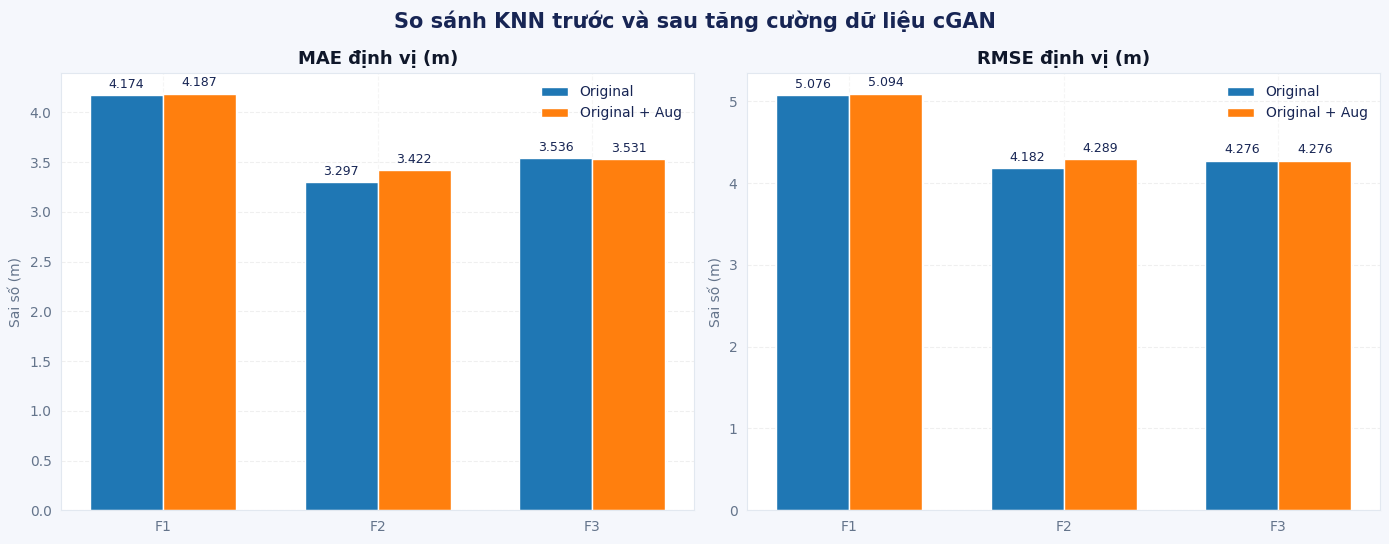

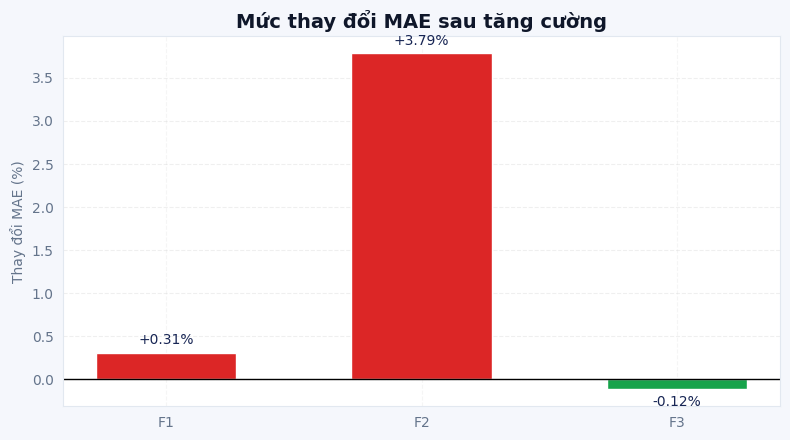

,Tầng,MAE Original (m),MAE Original + Aug (m),Δ MAE (m),Thay đổi MAE (%),RMSE Original (m),RMSE Original + Aug (m),Δ RMSE (m),Thay đổi RMSE (%),Đánh giá theo MAE
0,F1,4.1741,4.1869,+0.0128,+0.31%,5.0764,5.0938,+0.0174,+0.34%,Sai số tăng
1,F2,3.2974,3.4223,+0.1249,+3.79%,4.1818,4.2893,+0.1075,+2.57%,Sai số tăng
2,F3,3.5356,3.5314,-0.0042,-0.12%,4.2758,4.2759,+0.0001,+0.00%,Cải thiện



CELL 4.3.5 COMPLETED — KNN RESULTS SUMMARY
F1: MAE tăng — chưa cải thiện trong lần thử này. ΔMAE=+0.0128 m (+0.31%), ΔRMSE=+0.0174 m.
F2: MAE tăng — chưa cải thiện trong lần thử này. ΔMAE=+0.1249 m (+3.79%), ΔRMSE=+0.1075 m.
F3: MAE giảm — cải thiện trong lần thử này. ΔMAE=-0.0042 m (-0.12%), ΔRMSE=+0.0001 m.

MAE trung bình qua 3 tầng: Original=3.6690 m; Original + Aug=3.7135 m; thay đổi=+1.21%.

Lưu ý: đây là thống kê mô tả trên một lần đánh giá. Chưa thể kết luận ý nghĩa thống kê nếu chưa có nhiều lần chạy hoặc kiểm định bổ sung.


In [ ]:

# ============================================================
# CELL 4.3.5 — VISUALIZATION & SUMMARY
# KNN Localization: Standardized RSSI
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML


# ------------------------------------------------------------
# 1. Kiểm tra và chuẩn hóa tên cột
# ------------------------------------------------------------
if "knn_results_scaled_df" not in globals():
    raise NameError(
        "Không tìm thấy knn_results_scaled_df. "
        "Hãy chạy Cell 4.3.3 trước."
    )

results = knn_results_scaled_df.copy()

# Đổi tên cột tiếng Việt sang tên chuẩn để dùng trong biểu đồ
column_mapping = {
    "Tầng": "Floor",
    "Phương pháp": "Method",
    "MAE định vị (m)": "MAE_m",
    "RMSE định vị (m)": "RMSE_m",
}

results = results.rename(columns=column_mapping)

required_cols = {"Floor", "Method", "MAE_m", "RMSE_m"}
missing_cols = required_cols - set(results.columns)

if missing_cols:
    raise ValueError(
        f"Vẫn thiếu cột: {missing_cols}. "
        f"Các cột hiện có: {results.columns.tolist()}"
    )

results["Floor"] = results["Floor"].astype(str)
results["Method"] = results["Method"].astype(str)

floor_order = ["F1", "F2", "F3"]
method_order = ["Original", "Original + Aug"]

results = results[
    results["Floor"].isin(floor_order)
    & results["Method"].isin(method_order)
].copy()

if results.duplicated(["Floor", "Method"]).any():
    raise ValueError("Có dòng trùng tầng/phương pháp.")

if len(results) != 6:
    raise ValueError(
        f"Cần 6 dòng kết quả, hiện có {len(results)} dòng. "
        f"Hãy kiểm tra nhãn phương pháp trong bảng."
    )

print("PASS — Đã nhận diện đúng tên cột.")
print("Số kết quả:", len(results))
display(results)

# ------------------------------------------------------------
# 2. Tính mức thay đổi MAE và RMSE
# Giá trị âm = sai số giảm; dương = sai số tăng
# ------------------------------------------------------------
summary_rows = []

for floor in floor_order:
    floor_data = results[results["Floor"] == floor]

    original = floor_data[
        floor_data["Method"] == "Original"
    ].iloc[0]

    augmented = floor_data[
        floor_data["Method"] == "Original + Aug"
    ].iloc[0]

    mae_delta = float(augmented["MAE_m"] - original["MAE_m"])
    rmse_delta = float(augmented["RMSE_m"] - original["RMSE_m"])

    mae_pct = (
        mae_delta / float(original["MAE_m"]) * 100
        if float(original["MAE_m"]) != 0 else np.nan
    )

    rmse_pct = (
        rmse_delta / float(original["RMSE_m"]) * 100
        if float(original["RMSE_m"]) != 0 else np.nan
    )

    summary_rows.append({
        "Tầng": floor,
        "MAE Original (m)": float(original["MAE_m"]),
        "MAE Original + Aug (m)": float(augmented["MAE_m"]),
        "Δ MAE (m)": mae_delta,
        "Thay đổi MAE (%)": mae_pct,
        "RMSE Original (m)": float(original["RMSE_m"]),
        "RMSE Original + Aug (m)": float(augmented["RMSE_m"]),
        "Δ RMSE (m)": rmse_delta,
        "Thay đổi RMSE (%)": rmse_pct,
        "Đánh giá theo MAE": (
            "Cải thiện" if mae_delta < 0
            else "Sai số tăng" if mae_delta > 0
            else "Không đổi"
        )
    })

summary_df = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# 3. Dashboard tổng hợp
# ------------------------------------------------------------
mean_original = summary_df["MAE Original (m)"].mean()
mean_augmented = summary_df["MAE Original + Aug (m)"].mean()
mean_change = mean_augmented - mean_original
mean_change_pct = mean_change / mean_original * 100

improved_count = int((summary_df["Δ MAE (m)"] < 0).sum())

display(HTML("""
<div style="
    background: linear-gradient(120deg,#172554,#4338ca,#7c3aed);
    color:white;padding:20px 24px;border-radius:16px;
    margin:8px 0 14px 0;">
    <div style="font-size:13px;opacity:.85;letter-spacing:1px;">
        PHẦN 4 · ĐÁNH GIÁ ĐỊNH VỊ
    </div>
    <div style="font-size:24px;font-weight:700;margin-top:5px;">
        KNN Localization Dashboard
    </div>
    <div style="font-size:13px;opacity:.9;margin-top:5px;">
        Standardized RSSI · Original vs Original + cGAN
    </div>
</div>
"""))

def metric_card(title, value, subtitle):
    return f"""
    <div style="
        border:1px solid #dbe3f0;border-radius:12px;
        padding:15px;background:#f8fafc;min-width:160px;flex:1;">
        <div style="font-size:12px;color:#475569;">{title}</div>
        <div style="font-size:24px;font-weight:700;color:#1e293b;
                    margin:5px 0;">{value}</div>
        <div style="font-size:12px;color:#64748b;">{subtitle}</div>
    </div>
    """

cards = [
    metric_card("MAE trung bình · Original",
                f"{mean_original:.4f} m", "Trung bình 3 tầng"),
    metric_card("MAE trung bình · Augmented",
                f"{mean_augmented:.4f} m", "Trung bình 3 tầng"),
    metric_card("Thay đổi MAE trung bình",
                f"{mean_change_pct:+.2f}%",
                "Âm = giảm sai số; dương = tăng"),
    metric_card("Số tầng cải thiện",
                f"{improved_count}/3", "Dựa trên MAE")
]

display(HTML(
    '<div style="display:flex;gap:12px;flex-wrap:wrap;margin:10px 0 20px 0;">'
    + "".join(cards)
    + '</div>'
))

# ------------------------------------------------------------
# 4. Biểu đồ MAE và RMSE theo tầng
# ------------------------------------------------------------
x = np.arange(len(floor_order))
width = 0.34

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

metric_specs = [
    ("MAE_m", "MAE định vị (m)", axes[0]),
    ("RMSE_m", "RMSE định vị (m)", axes[1])
]

for col, title, ax in metric_specs:
    original_values = []
    augmented_values = []

    for floor in floor_order:
        part = results[results["Floor"] == floor]
        original_values.append(
            float(part[part["Method"] == "Original"][col].iloc[0])
        )
        augmented_values.append(
            float(part[part["Method"] == "Original + Aug"][col].iloc[0])
        )

    bars1 = ax.bar(
        x - width / 2, original_values, width,
        label="Original"
    )
    bars2 = ax.bar(
        x + width / 2, augmented_values, width,
        label="Original + Aug"
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(floor_order)
    ax.set_ylabel("Sai số (m)")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)
    ax.bar_label(bars1, fmt="%.3f", padding=3, fontsize=9)
    ax.bar_label(bars2, fmt="%.3f", padding=3, fontsize=9)
    ax.legend(frameon=False)

fig.suptitle(
    "So sánh KNN trước và sau tăng cường dữ liệu cGAN",
    fontsize=15, fontweight="bold"
)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Biểu đồ thay đổi MAE (%)
# ------------------------------------------------------------
changes = summary_df["Thay đổi MAE (%)"].to_numpy()
bar_colors = ["#16a34a" if v < 0 else "#dc2626" if v > 0 else "#64748b"
              for v in changes]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(summary_df["Tầng"], changes, color=bar_colors, width=0.55)

ax.axhline(0, color="black", linewidth=1)
ax.set_title("Mức thay đổi MAE sau tăng cường", fontweight="bold")
ax.set_ylabel("Thay đổi MAE (%)")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.bar_label(bars, labels=[f"{v:+.2f}%" for v in changes], padding=4)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Bảng kết quả chi tiết
# ------------------------------------------------------------
display(HTML("""
<h3 style="color:#4338ca;margin-top:18px;">
    Bảng tổng hợp mức thay đổi sai số
</h3>
"""))

display(
    summary_df.style
    .format({
        "MAE Original (m)": "{:.4f}",
        "MAE Original + Aug (m)": "{:.4f}",
        "Δ MAE (m)": "{:+.4f}",
        "Thay đổi MAE (%)": "{:+.2f}%",
        "RMSE Original (m)": "{:.4f}",
        "RMSE Original + Aug (m)": "{:.4f}",
        "Δ RMSE (m)": "{:+.4f}",
        "Thay đổi RMSE (%)": "{:+.2f}%"
    })
    .background_gradient(subset=["Thay đổi MAE (%)"], cmap="RdYlGn_r")
)

# ------------------------------------------------------------
# 7. Nhận xét tự động theo kết quả
# ------------------------------------------------------------
print("\n" + "=" * 68)
print("CELL 4.3.5 COMPLETED — KNN RESULTS SUMMARY")
print("=" * 68)

for _, row in summary_df.iterrows():
    if row["Δ MAE (m)"] < 0:
        message = "MAE giảm — cải thiện trong lần thử này."
    elif row["Δ MAE (m)"] > 0:
        message = "MAE tăng — chưa cải thiện trong lần thử này."
    else:
        message = "MAE không thay đổi."

    print(
        f'{row["Tầng"]}: {message} '
        f'ΔMAE={row["Δ MAE (m)"]:+.4f} m '
        f'({row["Thay đổi MAE (%)"]:+.2f}%), '
        f'ΔRMSE={row["Δ RMSE (m)"]:+.4f} m.'
    )

print(
    f"\nMAE trung bình qua 3 tầng: "
    f"Original={mean_original:.4f} m; "
    f"Original + Aug={mean_augmented:.4f} m; "
    f"thay đổi={mean_change_pct:+.2f}%."
)

print(
    "\nLưu ý: đây là thống kê mô tả trên một lần đánh giá. "
    "Chưa thể kết luận ý nghĩa thống kê nếu chưa có nhiều lần chạy "
    "hoặc kiểm định bổ sung."
)


### 4.3.6. Phân tích chất lượng fingerprint tổng hợp theo từng tầng

Mục tiêu là so sánh fingerprint Wi-Fi thực và fingerprint được sinh bởi cGAN trên ba tầng F1, F2 và F3.

Các tiêu chí phân tích gồm:
- Tỷ lệ AP được phát hiện và số AP trung bình trên mỗi fingerprint.
- Phân bố RSSI của các AP được phát hiện.
- Chênh lệch giữa dữ liệu thực và dữ liệu tổng hợp theo từng tầng.

Kết quả được sử dụng để tìm hiểu mối liên hệ giữa chất lượng dữ liệu tăng cường và hiệu quả định vị KNN. Các chỉ số thống kê chỉ phản ánh mức độ tương đồng của dữ liệu, không tự chúng chứng minh quan hệ nhân quả.

PASS — Đã tìm thấy dữ liệu fingerprint thực và dữ liệu cGAN.


,Tầng,Chỉ số,Real train,cGAN synthetic,Chênh lệch (cGAN - Real)
0,F1,N fingerprint,5020.000,76.000,-4944.000
1,F1,Tỷ lệ AP phát hiện (%),61.555,69.582,+8.027
2,F1,AP trung bình/fingerprint,10.464,11.829,+1.365
3,F1,RSSI trung bình AP phát hiện (dBm),-68.171,-75.866,-7.695
4,F1,RSSI độ lệch chuẩn (dBm),11.182,11.985,+0.803
5,F2,N fingerprint,2960.000,174.000,-2786.000
6,F2,Tỷ lệ AP phát hiện (%),63.128,73.563,+10.435
7,F2,AP trung bình/fingerprint,10.732,12.506,+1.774
8,F2,RSSI trung bình AP phát hiện (dBm),-68.979,-71.206,-2.226
9,F2,RSSI độ lệch chuẩn (dBm),10.864,6.549,-4.315


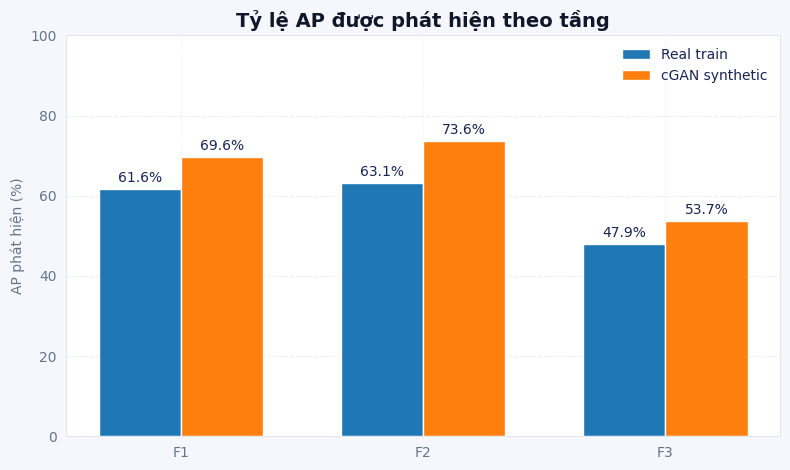

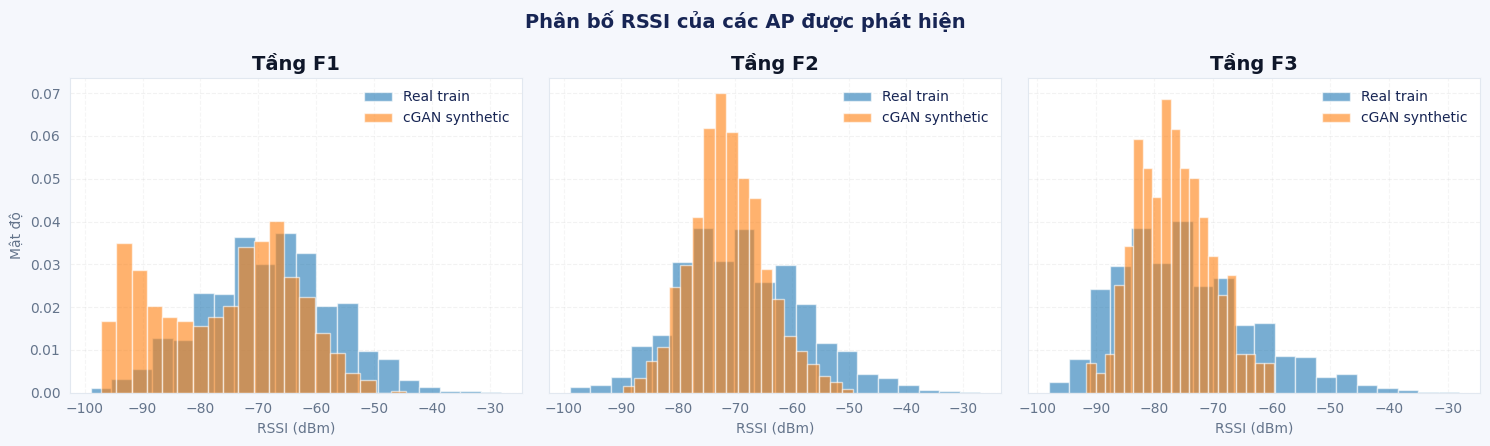


CELL 4.3.6 COMPLETED — FINGERPRINT QUALITY AUDIT

F1:
  Tỷ lệ AP phát hiện: Real=61.55%, cGAN=69.58%, chênh lệch=+8.03 điểm %
  AP trung bình/fingerprint: Real=10.46, cGAN=11.83
  RSSI trung bình AP đã phát hiện: Real=-68.17 dBm, cGAN=-75.87 dBm, chênh lệch=-7.70 dB

F2:
  Tỷ lệ AP phát hiện: Real=63.13%, cGAN=73.56%, chênh lệch=+10.44 điểm %
  AP trung bình/fingerprint: Real=10.73, cGAN=12.51
  RSSI trung bình AP đã phát hiện: Real=-68.98 dBm, cGAN=-71.21 dBm, chênh lệch=-2.23 dB

F3:
  Tỷ lệ AP phát hiện: Real=47.93%, cGAN=53.73%, chênh lệch=+5.79 điểm %
  AP trung bình/fingerprint: Real=8.15, cGAN=9.13
  RSSI trung bình AP đã phát hiện: Real=-75.06 dBm, cGAN=-76.66 dBm, chênh lệch=-1.59 dB

Lưu ý: bảng dùng tập train gốc để đối chiếu với dữ liệu cGAN. Biểu đồ RSSI chỉ tính AP đã phát hiện (RSSI > -100 dBm). Chênh lệch thống kê là dấu hiệu mô tả, không chứng minh quan hệ nhân quả.


In [ ]:

# ============================================================
# CELL 4.3.6 — SYNTHETIC FINGERPRINT QUALITY AUDIT
# So sánh fingerprint thực và fingerprint cGAN theo tầng
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# ------------------------------------------------------------
# 1. Kiểm tra dữ liệu cần thiết
# ------------------------------------------------------------
if "synthetic_df" not in globals():
    raise NameError(
        "Không tìm thấy synthetic_df. "
        "Hãy kiểm tra Cell 4.2.5 đã chạy thành công chưa."
    )

if "splits" not in globals():
    raise NameError("Không tìm thấy splits từ các cell chuẩn bị dữ liệu.")

AP_COLS = [f"AP{i}" for i in range(1, 18)]
FLOORS = ["F1", "F2", "F3"]

for floor in FLOORS:
    if floor not in splits:
        raise KeyError(f"Không tìm thấy dữ liệu tầng {floor} trong splits.")

    required = set(AP_COLS)
    missing = required - set(splits[floor]["train_df"].columns)

    if missing:
        raise ValueError(f"{floor} thiếu các cột AP: {missing}")

    missing_syn = required - set(synthetic_df.columns)
    if missing_syn:
        raise ValueError(f"synthetic_df thiếu các cột AP: {missing_syn}")

print("PASS — Đã tìm thấy dữ liệu fingerprint thực và dữ liệu cGAN.")

# ------------------------------------------------------------
# 2. Hàm thống kê fingerprint
# Quy ước -100 dBm = AP không được phát hiện
# ------------------------------------------------------------
def fingerprint_stats(df, ap_cols):
    rssi = df[ap_cols].to_numpy(dtype=float)

    if not np.isfinite(rssi).all():
        raise ValueError("Dữ liệu RSSI có NaN hoặc Inf.")

    detected = rssi > -100

    return {
        "N fingerprint": len(df),
        "Tỷ lệ AP phát hiện (%)": detected.mean() * 100,
        "AP trung bình/fingerprint": detected.sum(axis=1).mean(),
        "RSSI trung bình AP phát hiện (dBm)": (
            rssi[detected].mean() if detected.any() else np.nan
        ),
        "RSSI độ lệch chuẩn (dBm)": (
            rssi[detected].std() if detected.any() else np.nan
        ),
    }

# ------------------------------------------------------------
# 3. Tính thống kê theo tầng
# Dữ liệu thực dùng train gốc; không đưa test vào phân tích này
# ------------------------------------------------------------
rows = []

for floor in FLOORS:
    real_df = splits[floor]["train_df"]
    syn_df = synthetic_df[synthetic_df["Floor"].astype(str) == floor]

    if len(syn_df) == 0:
        raise ValueError(f"Không có fingerprint tổng hợp cho {floor}.")

    real_stats = fingerprint_stats(real_df, AP_COLS)
    syn_stats = fingerprint_stats(syn_df, AP_COLS)

    for metric in real_stats:
        rows.append({
            "Tầng": floor,
            "Chỉ số": metric,
            "Dữ liệu": "Real train",
            "Giá trị": real_stats[metric],
        })
        rows.append({
            "Tầng": floor,
            "Chỉ số": metric,
            "Dữ liệu": "cGAN synthetic",
            "Giá trị": syn_stats[metric],
        })

stats_long_df = pd.DataFrame(rows)

# Bảng so sánh gọn: mỗi chỉ số có cột Real và cGAN
comparison_rows = []

for floor in FLOORS:
    real = fingerprint_stats(splits[floor]["train_df"], AP_COLS)
    syn = fingerprint_stats(
        synthetic_df[synthetic_df["Floor"].astype(str) == floor],
        AP_COLS
    )

    for metric in real:
        rv = real[metric]
        sv = syn[metric]

        comparison_rows.append({
            "Tầng": floor,
            "Chỉ số": metric,
            "Real train": rv,
            "cGAN synthetic": sv,
            "Chênh lệch (cGAN - Real)": (
                sv - rv if np.isfinite(rv) and np.isfinite(sv) else np.nan
            )
        })

quality_comparison_df = pd.DataFrame(comparison_rows)

# ------------------------------------------------------------
# 4. Dashboard tiêu đề
# ------------------------------------------------------------
display(HTML("""
<div style="
    background:linear-gradient(120deg,#172554,#4338ca,#7c3aed);
    color:white;padding:20px 24px;border-radius:16px;margin:8px 0 16px 0;">
    <div style="font-size:12px;letter-spacing:1px;opacity:.85;">
        PHẦN 4 · KIỂM TRA CHẤT LƯỢNG DỮ LIỆU
    </div>
    <div style="font-size:23px;font-weight:700;margin-top:5px;">
        Real vs cGAN Fingerprint
    </div>
    <div style="font-size:13px;opacity:.9;margin-top:5px;">
        RSSI detection · AP count · RSSI distribution
    </div>
</div>
"""))

display(HTML(
    "<h3 style='color:#4338ca'>Bảng so sánh chất lượng fingerprint</h3>"
))

display(
    quality_comparison_df.style.format({
        "Real train": "{:.3f}",
        "cGAN synthetic": "{:.3f}",
        "Chênh lệch (cGAN - Real)": "{:+.3f}"
    }).background_gradient(
        subset=["Chênh lệch (cGAN - Real)"], cmap="RdYlGn_r"
    )
)

# ------------------------------------------------------------
# 5. Biểu đồ tỷ lệ AP được phát hiện
# ------------------------------------------------------------
detection = quality_comparison_df[
    quality_comparison_df["Chỉ số"] == "Tỷ lệ AP phát hiện (%)"
].copy()

x = np.arange(len(FLOORS))
width = 0.34

fig, ax = plt.subplots(figsize=(8, 4.8))

real_vals = [
    float(detection[detection["Tầng"] == f]["Real train"].iloc[0])
    for f in FLOORS
]
syn_vals = [
    float(detection[detection["Tầng"] == f]["cGAN synthetic"].iloc[0])
    for f in FLOORS
]

bars1 = ax.bar(x - width / 2, real_vals, width, label="Real train")
bars2 = ax.bar(x + width / 2, syn_vals, width, label="cGAN synthetic")

ax.set_title("Tỷ lệ AP được phát hiện theo tầng", fontweight="bold")
ax.set_ylabel("AP phát hiện (%)")
ax.set_xticks(x)
ax.set_xticklabels(FLOORS)
ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.bar_label(bars1, fmt="%.1f%%", padding=3)
ax.bar_label(bars2, fmt="%.1f%%", padding=3)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Phân bố RSSI: chỉ tính các AP đã được phát hiện
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, floor in zip(axes, FLOORS):
    real_df = splits[floor]["train_df"]
    syn_df = synthetic_df[synthetic_df["Floor"].astype(str) == floor]

    real_values = real_df[AP_COLS].to_numpy(dtype=float)
    syn_values = syn_df[AP_COLS].to_numpy(dtype=float)

    real_detected = real_values[real_values > -100]
    syn_detected = syn_values[syn_values > -100]

    ax.hist(
        real_detected, bins=20, alpha=0.6,
        density=True, label="Real train"
    )
    ax.hist(
        syn_detected, bins=20, alpha=0.6,
        density=True, label="cGAN synthetic"
    )

    ax.set_title(f"Tầng {floor}", fontweight="bold")
    ax.set_xlabel("RSSI (dBm)")
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.legend(frameon=False)

axes[0].set_ylabel("Mật độ")
fig.suptitle(
    "Phân bố RSSI của các AP được phát hiện",
    fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Tóm tắt nhận xét tự động
# ------------------------------------------------------------
print("\n" + "=" * 68)
print("CELL 4.3.6 COMPLETED — FINGERPRINT QUALITY AUDIT")
print("=" * 68)

for floor in FLOORS:
    part = quality_comparison_df[
        quality_comparison_df["Tầng"] == floor
    ].set_index("Chỉ số")

    real_det = part.loc["Tỷ lệ AP phát hiện (%)", "Real train"]
    syn_det = part.loc["Tỷ lệ AP phát hiện (%)", "cGAN synthetic"]

    real_count = part.loc[
        "AP trung bình/fingerprint", "Real train"
    ]
    syn_count = part.loc[
        "AP trung bình/fingerprint", "cGAN synthetic"
    ]

    real_rssi = part.loc[
        "RSSI trung bình AP phát hiện (dBm)", "Real train"
    ]
    syn_rssi = part.loc[
        "RSSI trung bình AP phát hiện (dBm)", "cGAN synthetic"
    ]

    print(f"\n{floor}:")
    print(
        f"  Tỷ lệ AP phát hiện: Real={real_det:.2f}%, "
        f"cGAN={syn_det:.2f}%, chênh lệch={syn_det-real_det:+.2f} điểm %"
    )
    print(
        f"  AP trung bình/fingerprint: Real={real_count:.2f}, "
        f"cGAN={syn_count:.2f}"
    )
    print(
        f"  RSSI trung bình AP đã phát hiện: "
        f"Real={real_rssi:.2f} dBm, cGAN={syn_rssi:.2f} dBm, "
        f"chênh lệch={syn_rssi-real_rssi:+.2f} dB"
    )

print(
    "\nLưu ý: bảng dùng tập train gốc để đối chiếu với dữ liệu cGAN. "
    "Biểu đồ RSSI chỉ tính AP đã phát hiện (RSSI > -100 dBm). "
    "Chênh lệch thống kê là dấu hiệu mô tả, không chứng minh quan hệ nhân quả."
)


### 4.3.7. Phân tích sai lệch RSSI theo từng Access Point

Mục tiêu là đánh giá mức độ tương đồng giữa fingerprint thực và fingerprint tổng hợp ở cấp độ từng AP.

Các chỉ số được phân tích:
- Tỷ lệ phát hiện AP trong dữ liệu thực và dữ liệu cGAN.
- RSSI trung bình của AP, chỉ tính trên các fingerprint mà AP được phát hiện.
- Chênh lệch giữa hai phân bố để xác định AP có sai lệch nổi bật.

Phân tích sử dụng tập train gốc làm dữ liệu thực đối chiếu và các fingerprint tổng hợp đã tạo ở Cell 4.2.5. Quy ước RSSI = −100 dBm là AP không được phát hiện.

Kết quả dùng để chẩn đoán chất lượng dữ liệu sinh, không trực tiếp chứng minh nguyên nhân làm sai số định vị tăng.

,Tầng,AP,Real detection (%),cGAN detection (%),Δ detection (điểm %),Real mean RSSI (dBm),cGAN mean RSSI (dBm),Δ mean RSSI (dB),Real RSSI std (dB),cGAN RSSI std (dB),Δ RSSI std (dB)
0,F1,AP1,89.8,100.0,+10.2,-62.68,-69.32,-6.64,9.54,4.46,-5.09
1,F1,AP2,77.5,98.7,+21.2,-70.74,-84.41,-13.67,8.40,4.32,-4.08
2,F1,AP3,98.2,100.0,+1.8,-58.02,-66.09,-8.07,8.08,5.78,-2.30
3,F1,AP4,80.5,96.1,+15.5,-65.02,-73.59,-8.57,10.34,6.17,-4.17
4,F1,AP5,83.0,100.0,+17.0,-63.92,-67.87,-3.94,10.70,7.69,-3.01
5,F1,AP6,94.2,100.0,+5.8,-62.18,-63.45,-1.27,8.19,5.01,-3.18
6,F1,AP7,96.2,100.0,+3.8,-64.93,-67.95,-3.03,7.90,9.38,+1.48
7,F1,AP8,74.3,98.7,+24.4,-82.42,-93.40,-10.98,6.50,1.87,-4.64
8,F1,AP9,10.8,0.0,-10.8,-79.75,nan,+nan,6.51,nan,+nan
9,F1,AP10,80.8,93.4,+12.6,-66.05,-68.81,-2.75,9.26,4.16,-5.10


,Tầng,AP,Real detection (%),cGAN detection (%),Δ detection (điểm %),Real mean RSSI (dBm),cGAN mean RSSI (dBm),Δ mean RSSI (dB),Real RSSI std (dB),cGAN RSSI std (dB),Δ RSSI std (dB)
17,F2,AP1,64.6,97.1,+32.5,-73.81,-72.81,+1.00,8.39,4.40,-3.99
18,F2,AP2,61.4,97.1,+35.7,-76.45,-75.07,+1.38,7.80,5.41,-2.39
19,F2,AP3,67.2,79.3,+12.1,-70.92,-74.49,-3.57,7.87,4.78,-3.10
20,F2,AP4,60.0,43.1,-16.9,-71.70,-72.41,-0.71,10.85,3.94,-6.91
21,F2,AP5,66.7,94.8,+28.1,-69.26,-71.23,-1.97,8.90,5.80,-3.10
22,F2,AP6,63.5,98.9,+35.3,-74.16,-74.66,-0.50,7.37,4.90,-2.47
23,F2,AP7,77.5,100.0,+22.5,-76.20,-73.68,+2.52,6.41,4.94,-1.47
24,F2,AP8,78.8,97.7,+18.9,-69.29,-75.47,-6.18,10.08,5.05,-5.03
25,F2,AP9,35.2,0.0,-35.2,-64.98,nan,+nan,10.78,nan,+nan
26,F2,AP10,83.2,98.3,+15.0,-64.39,-68.42,-4.03,7.59,3.35,-4.23


,Tầng,AP,Real detection (%),cGAN detection (%),Δ detection (điểm %),Real mean RSSI (dBm),cGAN mean RSSI (dBm),Δ mean RSSI (dB),Real RSSI std (dB),cGAN RSSI std (dB),Δ RSSI std (dB)
34,F3,AP1,37.5,3.3,-34.1,-83.93,-83.35,+0.58,6.33,0.00,-6.33
35,F3,AP2,44.9,93.3,+48.5,-84.37,-80.26,+4.11,5.93,4.99,-0.94
36,F3,AP3,42.4,50.0,+7.6,-83.02,-83.95,-0.93,5.23,4.08,-1.15
37,F3,AP4,42.2,23.3,-18.9,-76.80,-81.10,-4.31,8.36,3.19,-5.18
38,F3,AP5,59.2,100.0,+40.8,-75.49,-77.20,-1.71,8.33,3.96,-4.37
39,F3,AP6,34.0,0.0,-34.0,-85.93,nan,+nan,5.12,nan,+nan
40,F3,AP7,36.2,10.0,-26.2,-86.52,-87.20,-0.68,4.71,1.48,-3.23
41,F3,AP8,63.7,100.0,+36.3,-77.63,-81.48,-3.85,8.62,3.87,-4.75
42,F3,AP9,17.0,0.0,-17.0,-78.84,nan,+nan,7.36,nan,+nan
43,F3,AP10,54.2,60.0,+5.8,-80.48,-79.45,+1.03,5.89,3.37,-2.51


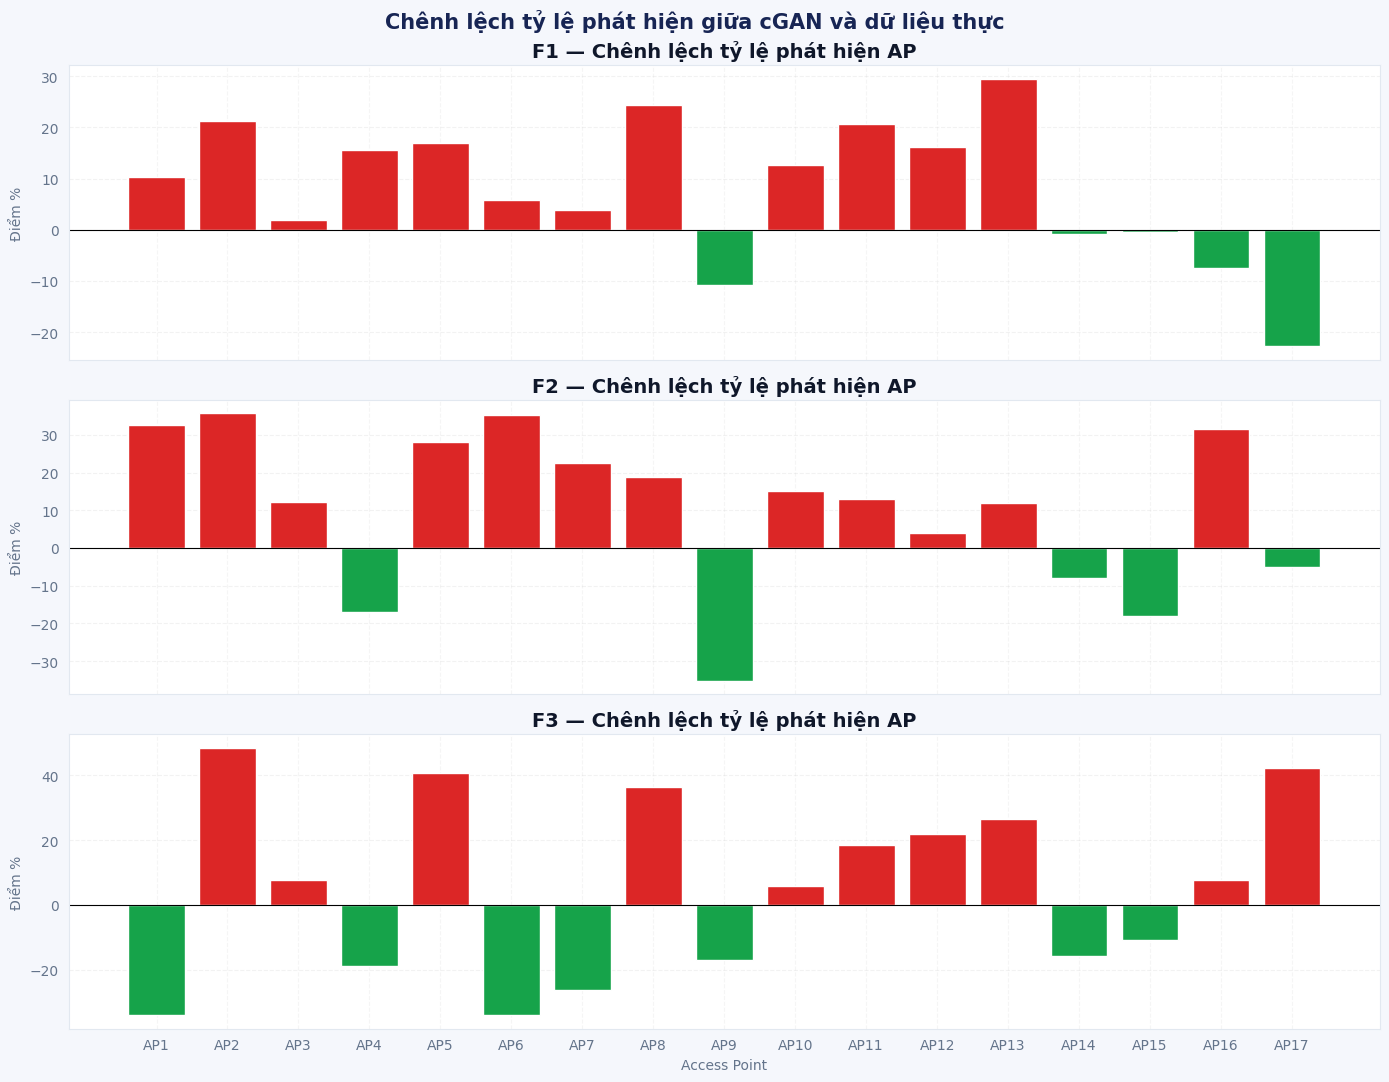

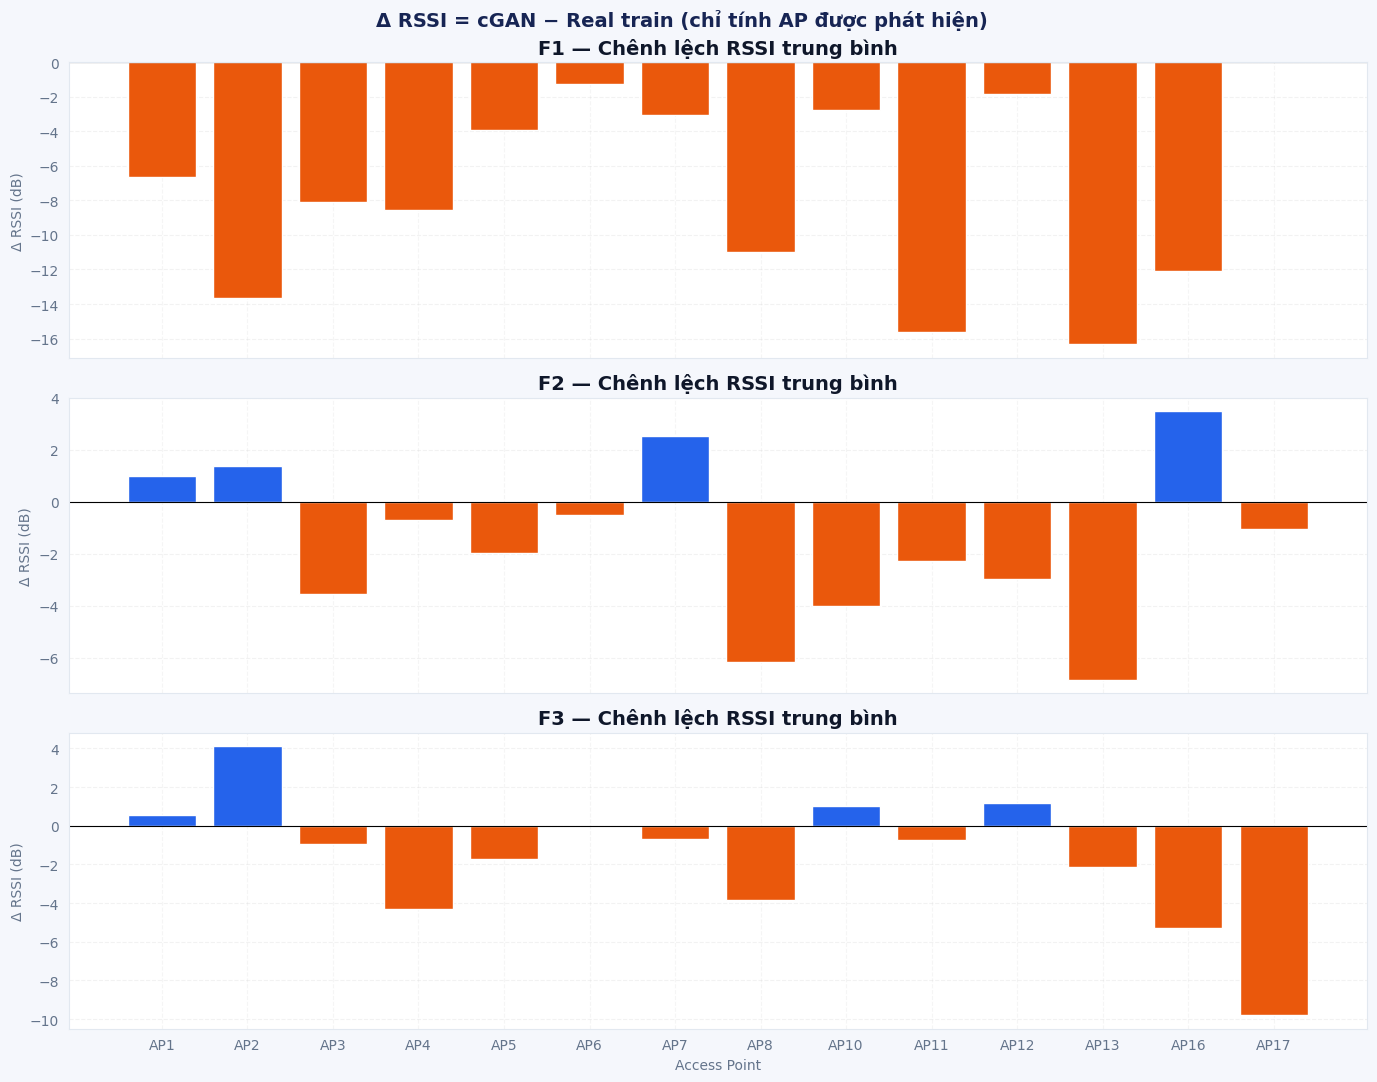


CELL 4.3.7 COMPLETED — PER-AP RSSI BIAS ANALYSIS

F1 — Top 5 AP có chênh lệch detection lớn nhất:


,AP,Real detection (%),cGAN detection (%),Δ detection (điểm %)
12,AP13,58.7,88.2,+29.5
7,AP8,74.3,98.7,+24.4
16,AP17,22.7,0.0,-22.7
1,AP2,77.5,98.7,+21.2
10,AP11,70.1,90.8,+20.7


F1 — Top 5 AP có |Δ RSSI trung bình| lớn nhất:


,AP,Real mean RSSI (dBm),cGAN mean RSSI (dBm),Δ mean RSSI (dB)
12,AP13,-75.02,-91.35,-16.32
10,AP11,-71.71,-87.32,-15.61
1,AP2,-70.74,-84.41,-13.67
15,AP16,-83.06,-95.13,-12.08
7,AP8,-82.42,-93.40,-10.98



F2 — Top 5 AP có chênh lệch detection lớn nhất:


...


F3 — Top 5 AP có chênh lệch detection lớn nhất:


,AP,Real detection (%),cGAN detection (%),Δ detection (điểm %)
35,AP2,44.9,93.3,+48.5
50,AP17,57.8,100.0,+42.2
38,AP5,59.2,100.0,+40.8
41,AP8,63.7,100.0,+36.3
34,AP1,37.5,3.3,-34.1


F3 — Top 5 AP có |Δ RSSI trung bình| lớn nhất:


,AP,Real mean RSSI (dBm),cGAN mean RSSI (dBm),Δ mean RSSI (dB)
50,AP17,-63.70,-73.51,-9.80
49,AP16,-61.97,-67.26,-5.29
37,AP4,-76.80,-81.10,-4.31
35,AP2,-84.37,-80.26,+4.11
41,AP8,-77.63,-81.48,-3.85



Lưu ý: Δ detection dương nghĩa là cGAN phát hiện AP thường xuyên hơn. Δ RSSI dương nghĩa RSSI trung bình cGAN mạnh hơn (ít âm hơn), và ngược lại. RSSI trung bình chỉ tính khi AP được phát hiện.


In [ ]:

# ============================================================
# CELL 4.3.7 — PER-AP RSSI BIAS ANALYSIS
# Phân tích sai lệch theo AP1–AP17
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

AP_COLS = [f"AP{i}" for i in range(1, 18)]
FLOORS = ["F1", "F2", "F3"]

if "synthetic_df" not in globals() or "splits" not in globals():
    raise NameError(
        "Thiếu synthetic_df hoặc splits. "
        "Hãy kiểm tra các cell chuẩn bị dữ liệu trước đó."
    )

# ------------------------------------------------------------
# 1. Tính thống kê riêng cho từng AP
# ------------------------------------------------------------
def per_ap_stats(df, ap_cols):
    values = df[ap_cols].to_numpy(dtype=float)

    if not np.isfinite(values).all():
        raise ValueError("Dữ liệu RSSI chứa NaN hoặc Inf.")

    detected = values > -100
    result = []

    for j, ap in enumerate(ap_cols):
        ap_detected = detected[:, j]
        detected_values = values[ap_detected, j]

        result.append({
            "AP": ap,
            "Detection (%)": ap_detected.mean() * 100,
            "Mean RSSI (dBm)": (
                detected_values.mean()
                if len(detected_values) else np.nan
            ),
            "RSSI Std (dB)": (
                detected_values.std()
                if len(detected_values) else np.nan
            ),
            "N detected": int(ap_detected.sum()),
            "N total": len(df)
        })

    return pd.DataFrame(result)


# ------------------------------------------------------------
# 2. So sánh Real train và cGAN theo tầng
# ------------------------------------------------------------
per_ap_rows = []

for floor in FLOORS:
    real_df = splits[floor]["train_df"]
    syn_df = synthetic_df[
        synthetic_df["Floor"].astype(str) == floor
    ]

    if len(syn_df) == 0:
        raise ValueError(f"Không có fingerprint cGAN cho {floor}.")

    real_stats = per_ap_stats(real_df, AP_COLS)
    syn_stats = per_ap_stats(syn_df, AP_COLS)

    for i, ap in enumerate(AP_COLS):
        r = real_stats.iloc[i]
        s = syn_stats.iloc[i]

        per_ap_rows.append({
            "Tầng": floor,
            "AP": ap,
            "Real detection (%)": r["Detection (%)"],
            "cGAN detection (%)": s["Detection (%)"],
            "Δ detection (điểm %)": (
                s["Detection (%)"] - r["Detection (%)"]
            ),
            "Real mean RSSI (dBm)": r["Mean RSSI (dBm)"],
            "cGAN mean RSSI (dBm)": s["Mean RSSI (dBm)"],
            "Δ mean RSSI (dB)": (
                s["Mean RSSI (dBm)"] - r["Mean RSSI (dBm)"]
                if pd.notna(s["Mean RSSI (dBm)"])
                and pd.notna(r["Mean RSSI (dBm)"])
                else np.nan
            ),
            "Real RSSI std (dB)": r["RSSI Std (dB)"],
            "cGAN RSSI std (dB)": s["RSSI Std (dB)"],
            "Δ RSSI std (dB)": (
                s["RSSI Std (dB)"] - r["RSSI Std (dB)"]
                if pd.notna(s["RSSI Std (dB)"])
                and pd.notna(r["RSSI Std (dB)"])
                else np.nan
            )
        })

per_ap_comparison_df = pd.DataFrame(per_ap_rows)

# ------------------------------------------------------------
# 3. Dashboard
# ------------------------------------------------------------
display(HTML("""
<div style="
    background:linear-gradient(120deg,#172554,#4338ca,#7c3aed);
    color:white;padding:20px 24px;border-radius:16px;margin:8px 0 16px 0;">
    <div style="font-size:12px;letter-spacing:1px;opacity:.85;">
        PHẦN 4 · CHẨN ĐOÁN THEO ACCESS POINT
    </div>
    <div style="font-size:23px;font-weight:700;margin-top:5px;">
        Per-AP RSSI Bias Analysis
    </div>
    <div style="font-size:13px;opacity:.9;margin-top:5px;">
        AP detection · Mean RSSI · RSSI variability
    </div>
</div>
"""))

# ------------------------------------------------------------
# 4. Bảng đầy đủ theo từng tầng
# ------------------------------------------------------------
for floor in FLOORS:
    display(HTML(
        f"<h3 style='color:#4338ca;margin-top:18px;'>Tầng {floor}</h3>"
    ))

    floor_table = per_ap_comparison_df[
        per_ap_comparison_df["Tầng"] == floor
    ].copy()

    display(
        floor_table.style.format({
            "Real detection (%)": "{:.1f}",
            "cGAN detection (%)": "{:.1f}",
            "Δ detection (điểm %)": "{:+.1f}",
            "Real mean RSSI (dBm)": "{:.2f}",
            "cGAN mean RSSI (dBm)": "{:.2f}",
            "Δ mean RSSI (dB)": "{:+.2f}",
            "Real RSSI std (dB)": "{:.2f}",
            "cGAN RSSI std (dB)": "{:.2f}",
            "Δ RSSI std (dB)": "{:+.2f}"
        }).background_gradient(
            subset=["Δ detection (điểm %)"], cmap="RdYlGn_r"
        ).background_gradient(
            subset=["Δ mean RSSI (dB)"], cmap="coolwarm"
        )
    )

# ------------------------------------------------------------
# 5. Biểu đồ chênh lệch detection rate theo AP
# ------------------------------------------------------------
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

for ax, floor in zip(axes, FLOORS):
    part = per_ap_comparison_df[
        per_ap_comparison_df["Tầng"] == floor
    ]

    delta = part["Δ detection (điểm %)"].to_numpy()
    colors = [
        "#16a34a" if v < 0 else "#dc2626" if v > 0 else "#64748b"
        for v in delta
    ]

    ax.bar(AP_COLS, delta, color=colors)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{floor} — Chênh lệch tỷ lệ phát hiện AP",
                 fontweight="bold")
    ax.set_ylabel("Điểm %")
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)

axes[-1].set_xlabel("Access Point")
fig.suptitle(
    "Chênh lệch tỷ lệ phát hiện giữa cGAN và dữ liệu thực",
    fontsize=15, fontweight="bold"
)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Biểu đồ chênh lệch RSSI trung bình theo AP
# Chỉ so sánh các AP có RSSI hợp lệ ở cả hai bộ dữ liệu
# ------------------------------------------------------------
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

for ax, floor in zip(axes, FLOORS):
    part = per_ap_comparison_df[
        per_ap_comparison_df["Tầng"] == floor
    ]

    delta = part["Δ mean RSSI (dB)"].to_numpy()
    valid = np.isfinite(delta)

    colors = [
        "#2563eb" if v >= 0 else "#ea580c"
        for v in delta[valid]
    ]

    ax.bar(
        np.array(AP_COLS)[valid],
        delta[valid],
        color=colors
    )
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{floor} — Chênh lệch RSSI trung bình",
                 fontweight="bold")
    ax.set_ylabel("Δ RSSI (dB)")
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)

axes[-1].set_xlabel("Access Point")
fig.suptitle(
    "Δ RSSI = cGAN − Real train (chỉ tính AP được phát hiện)",
    fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Xếp hạng AP có sai lệch nổi bật
# ------------------------------------------------------------
print("\n" + "=" * 68)
print("CELL 4.3.7 COMPLETED — PER-AP RSSI BIAS ANALYSIS")
print("=" * 68)

for floor in FLOORS:
    part = per_ap_comparison_df[
        per_ap_comparison_df["Tầng"] == floor
    ].copy()

    print(f"\n{floor} — Top 5 AP có chênh lệch detection lớn nhất:")
    display(
        part.assign(
            **{"|Δ detection|": part["Δ detection (điểm %)"].abs()}
        )
        .sort_values("|Δ detection|", ascending=False)
        [[
            "AP", "Real detection (%)", "cGAN detection (%)",
            "Δ detection (điểm %)"
        ]]
        .head(5)
        .style.format({
            "Real detection (%)": "{:.1f}",
            "cGAN detection (%)": "{:.1f}",
            "Δ detection (điểm %)": "{:+.1f}"
        })
    )

    valid_rssi = part.dropna(subset=["Δ mean RSSI (dB)"]).copy()

    print(f"{floor} — Top 5 AP có |Δ RSSI trung bình| lớn nhất:")
    display(
        valid_rssi.assign(
            **{"|Δ RSSI|": valid_rssi["Δ mean RSSI (dB)"].abs()}
        )
        .sort_values("|Δ RSSI|", ascending=False)
        [[
            "AP", "Real mean RSSI (dBm)",
            "cGAN mean RSSI (dBm)", "Δ mean RSSI (dB)"
        ]]
        .head(5)
        .style.format({
            "Real mean RSSI (dBm)": "{:.2f}",
            "cGAN mean RSSI (dBm)": "{:.2f}",
            "Δ mean RSSI (dB)": "{:+.2f}"
        })
    )

print(
    "\nLưu ý: Δ detection dương nghĩa là cGAN phát hiện AP thường xuyên hơn. "
    "Δ RSSI dương nghĩa RSSI trung bình cGAN mạnh hơn (ít âm hơn), "
    "và ngược lại. RSSI trung bình chỉ tính khi AP được phát hiện."
)


### 4.3.8. Kiểm tra xác suất detection mask trước ngưỡng phân loại

Trong mô hình cGAN, Generator tạo ra logits cho detection mask. Sau khi áp dụng hàm sigmoid, mỗi AP có một xác suất phát hiện nằm trong khoảng [0, 1]. Xác suất này được chuyển thành trạng thái phát hiện khi đạt ngưỡng 0,5.

Phần này kiểm tra:
- Phân bố xác suất phát hiện của từng AP trên các tọa độ ứng viên.
- Tỷ lệ AP có xác suất thấp, trung gian và cao.
- Mức độ khác biệt giữa xác suất dự đoán và tỷ lệ phát hiện thực tế trên tập train.

Mục đích là chẩn đoán hành vi của detection mask trước khi cân nhắc điều chỉnh ngưỡng hoặc huấn luyện lại mô hình.

PASS — Đã lấy xác suất mask trực tiếp từ Generator hiện có.
Không huấn luyện lại mô hình.


,Tầng,AP,Real detection (%),Mean predicted probability (%),Predicted detection at 0.5 (%),P < 0.1 (%),P 0.1–0.9 (%),P ≥ 0.9 (%)
0,F1,AP1,89.8,88.3,100.0,0.0,67.1,32.9
1,F1,AP2,77.5,67.9,98.7,0.0,100.0,0.0
2,F1,AP3,98.2,91.2,100.0,0.0,34.2,65.8
3,F1,AP4,80.5,70.8,96.1,0.0,100.0,0.0
4,F1,AP5,83.0,83.2,100.0,0.0,96.1,3.9
5,F1,AP6,94.2,90.0,100.0,0.0,42.1,57.9
6,F1,AP7,96.2,90.8,100.0,0.0,31.6,68.4
7,F1,AP8,74.3,69.7,98.7,0.0,100.0,0.0
8,F1,AP9,10.8,7.3,0.0,90.8,9.2,0.0
9,F1,AP10,80.8,70.4,93.4,0.0,100.0,0.0


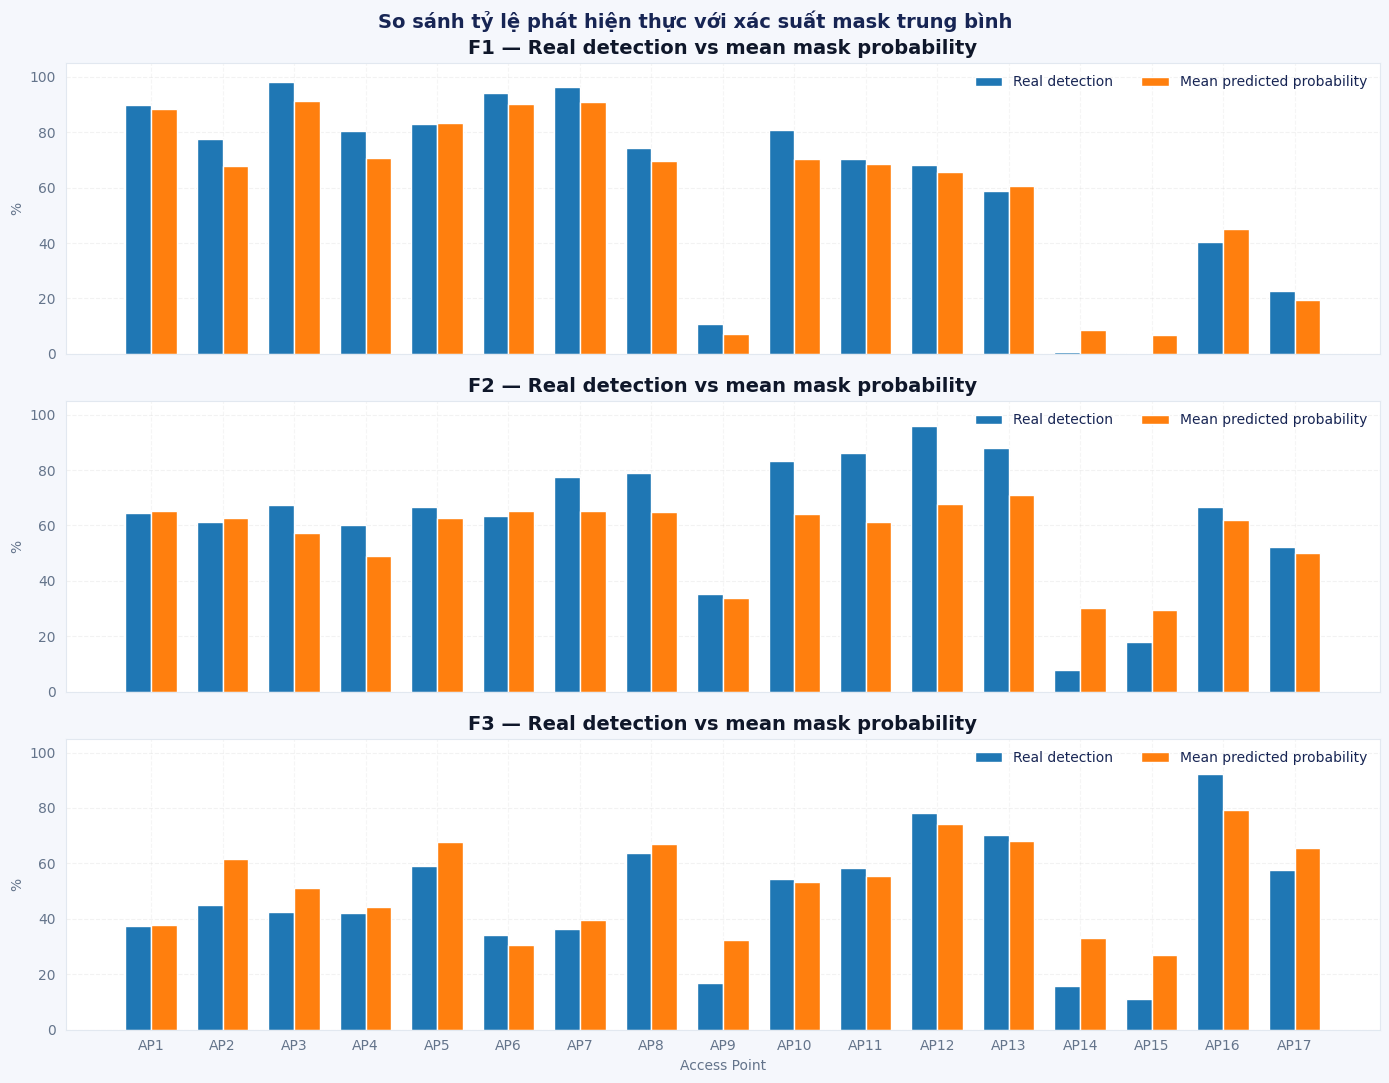

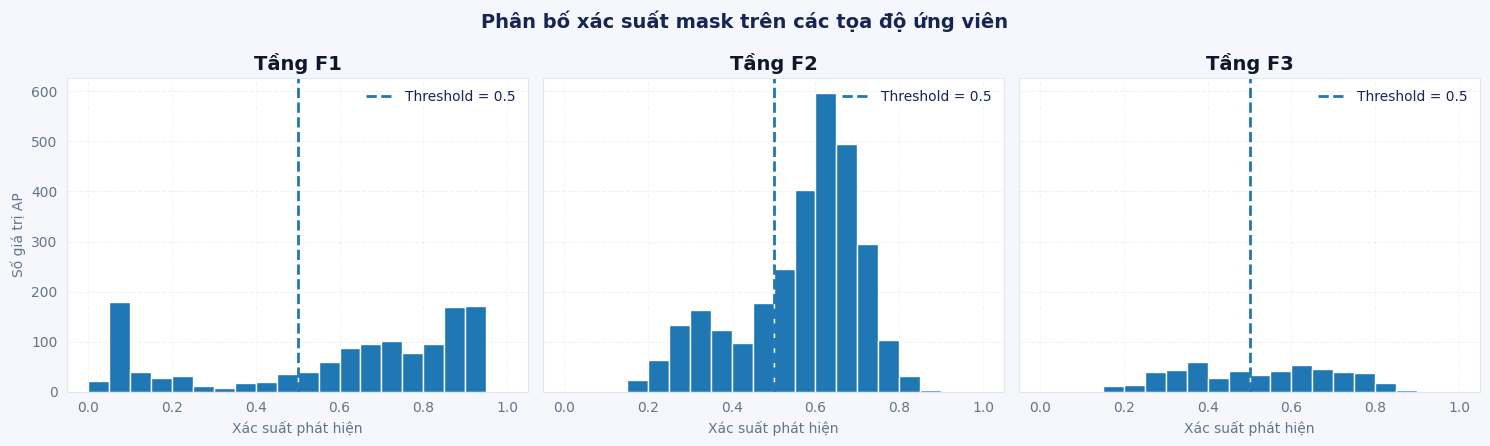

,Tầng,Candidate coordinates,Mean mask probability (%),Predicted detection at 0.5 (%),Real train detection (%),Low probability < 0.1 (%),High probability ≥ 0.9 (%),Uncertain probability 0.1–0.9 (%)
0,F1,76,59.08,69.58,61.55,15.63,13.47,70.90
1,F2,174,56.54,73.56,63.13,0.00,0.00,100.00
2,F3,30,52.23,53.73,47.93,0.00,0.00,100.00



CELL 4.3.8 COMPLETED — MASK PROBABILITY AUDIT
F1: mean P=59.08%, detection@0.5=69.58%, real train detection=61.55%, low P=15.63%, high P=13.47%.
F2: mean P=56.54%, detection@0.5=73.56%, real train detection=63.13%, low P=0.00%, high P=0.00%.
F3: mean P=52.23%, detection@0.5=53.73%, real train detection=47.93%, low P=0.00%, high P=0.00%.

Lưu ý: xác suất trung bình không đồng nghĩa với tỷ lệ dự đoán sau ngưỡng 0.5. Tập train thực và tọa độ ứng viên cũng khác nhau, nên đây là phân tích chẩn đoán chứ chưa phải đánh giá calibration trên cùng các mẫu.


In [ ]:

# ============================================================
# CELL 4.3.8 — DETECTION MASK PROBABILITY AUDIT
# Kiểm tra xác suất mask trước ngưỡng 0.5
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

import torch

FLOORS = ["F1", "F2", "F3"]
AP_COLS = [f"AP{i}" for i in range(1, 18)]
MASK_THRESHOLD = 0.5

# ------------------------------------------------------------
# 1. Kiểm tra biến cần thiết
# ------------------------------------------------------------
required_objects = [
    "models",
    "candidate_coords_norm",
    "c320_get_generator",
    "c320_generate",
    "splits"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        f"Thiếu biến/hàm: {missing_objects}. "
        "Không khởi tạo lại model; hãy kiểm tra các cell trước."
    )

# ------------------------------------------------------------
# 2. Lấy xác suất mask từ chính Generator đã huấn luyện
# c320_generate trả về mask_prob trước khi áp ngưỡng
# ------------------------------------------------------------
mask_prob_by_floor = {}
mask_rows = []

for floor in FLOORS:
    coords = candidate_coords_norm[floor]

    if isinstance(coords, np.ndarray):
        coords_tensor = torch.tensor(
            coords, dtype=torch.float32
        )
    elif torch.is_tensor(coords):
        coords_tensor = coords.detach().clone().float()
    else:
        coords_tensor = torch.tensor(
            np.asarray(coords), dtype=torch.float32
        )

    generator = c320_get_generator(floor)

    # Cùng seed với Cell 4.2.5 để giữ nhất quán lần sinh
    floor_seed = 4200 + FLOORS.index(floor)

    with torch.no_grad():
        _, _, mask_prob = c320_generate(
            generator,
            coords_tensor,
            seed=floor_seed
        )

    if torch.is_tensor(mask_prob):
        mask_prob = mask_prob.detach().cpu().numpy()

    mask_prob = np.asarray(mask_prob, dtype=float)

    expected_shape = (len(coords_tensor), len(AP_COLS))

    if mask_prob.shape != expected_shape:
        raise ValueError(
            f"{floor}: mask_prob có shape {mask_prob.shape}, "
            f"mong đợi {expected_shape}."
        )

    if not np.isfinite(mask_prob).all():
        raise ValueError(f"{floor}: xác suất mask có NaN/Inf.")

    if (mask_prob < 0).any() or (mask_prob > 1).any():
        raise ValueError(f"{floor}: xác suất mask ngoài khoảng [0,1].")

    mask_prob_by_floor[floor] = mask_prob

    real = splits[floor]["train_df"][AP_COLS].to_numpy(dtype=float)
    real_detect = real > -100

    for j, ap in enumerate(AP_COLS):
        p = mask_prob[:, j]

        mask_rows.append({
            "Tầng": floor,
            "AP": ap,
            "Real detection (%)": real_detect[:, j].mean() * 100,
            "Mean predicted probability (%)": p.mean() * 100,
            "Median probability (%)": np.median(p) * 100,
            "Predicted detection at 0.5 (%)": (
                p >= MASK_THRESHOLD
            ).mean() * 100,
            "P < 0.1 (%)": (p < 0.1).mean() * 100,
            "P 0.1–0.9 (%)": (
                (p >= 0.1) & (p < 0.9)
            ).mean() * 100,
            "P ≥ 0.9 (%)": (p >= 0.9).mean() * 100,
            "Min probability": p.min(),
            "Max probability": p.max()
        })

mask_audit_df = pd.DataFrame(mask_rows)

print("PASS — Đã lấy xác suất mask trực tiếp từ Generator hiện có.")
print("Không huấn luyện lại mô hình.")

# ------------------------------------------------------------
# 3. Dashboard
# ------------------------------------------------------------
display(HTML("""
<div style="
    background:linear-gradient(120deg,#172554,#4338ca,#7c3aed);
    color:white;padding:20px 24px;border-radius:16px;margin:8px 0 16px 0;">
    <div style="font-size:12px;letter-spacing:1px;opacity:.85;">
        PHẦN 4 · CHẨN ĐOÁN DETECTION MASK
    </div>
    <div style="font-size:23px;font-weight:700;margin-top:5px;">
        Mask Probability Audit
    </div>
    <div style="font-size:13px;opacity:.9;margin-top:5px;">
        Raw probability · Threshold = 0.5 · Per-AP analysis
    </div>
</div>
"""))

# ------------------------------------------------------------
# 4. So sánh tỷ lệ phát hiện thực và dự đoán
# ------------------------------------------------------------
display(HTML(
    "<h3 style='color:#4338ca'>Tỷ lệ phát hiện theo AP</h3>"
))

display(
    mask_audit_df[[
        "Tầng", "AP",
        "Real detection (%)",
        "Mean predicted probability (%)",
        "Predicted detection at 0.5 (%)",
        "P < 0.1 (%)",
        "P 0.1–0.9 (%)",
        "P ≥ 0.9 (%)"
    ]].style.format({
        "Real detection (%)": "{:.1f}",
        "Mean predicted probability (%)": "{:.1f}",
        "Predicted detection at 0.5 (%)": "{:.1f}",
        "P < 0.1 (%)": "{:.1f}",
        "P 0.1–0.9 (%)": "{:.1f}",
        "P ≥ 0.9 (%)": "{:.1f}"
    })
)

# ------------------------------------------------------------
# 5. Biểu đồ xác suất trung bình và detection rate thực
# ------------------------------------------------------------
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

for ax, floor in zip(axes, FLOORS):
    part = mask_audit_df[
        mask_audit_df["Tầng"] == floor
    ]

    x = np.arange(len(AP_COLS))
    width = 0.36

    bars1 = ax.bar(
        x - width / 2,
        part["Real detection (%)"],
        width,
        label="Real detection"
    )

    bars2 = ax.bar(
        x + width / 2,
        part["Mean predicted probability (%)"],
        width,
        label="Mean predicted probability"
    )

    ax.set_title(f"{floor} — Real detection vs mean mask probability",
                 fontweight="bold")
    ax.set_ylabel("%")
    ax.set_ylim(0, 105)
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, ncol=2)

axes[-1].set_xticks(np.arange(len(AP_COLS)))
axes[-1].set_xticklabels(AP_COLS)
axes[-1].set_xlabel("Access Point")

fig.suptitle(
    "So sánh tỷ lệ phát hiện thực với xác suất mask trung bình",
    fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Phân bố xác suất mask theo tầng
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, floor in zip(axes, FLOORS):
    probabilities = mask_prob_by_floor[floor].ravel()

    ax.hist(
        probabilities,
        bins=np.linspace(0, 1, 21),
        edgecolor="white"
    )
    ax.axvline(
        MASK_THRESHOLD, linestyle="--", linewidth=2,
        label="Threshold = 0.5"
    )
    ax.set_title(f"Tầng {floor}", fontweight="bold")
    ax.set_xlabel("Xác suất phát hiện")
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.legend(frameon=False)

axes[0].set_ylabel("Số giá trị AP")
fig.suptitle(
    "Phân bố xác suất mask trên các tọa độ ứng viên",
    fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Tổng hợp theo tầng
# ------------------------------------------------------------
floor_summary = []

for floor in FLOORS:
    p = mask_prob_by_floor[floor]
    real = splits[floor]["train_df"][AP_COLS].to_numpy(dtype=float) > -100

    floor_summary.append({
        "Tầng": floor,
        "Candidate coordinates": p.shape[0],
        "Mean mask probability (%)": p.mean() * 100,
        "Predicted detection at 0.5 (%)": (
            p >= MASK_THRESHOLD
        ).mean() * 100,
        "Real train detection (%)": real.mean() * 100,
        "Low probability < 0.1 (%)": (p < 0.1).mean() * 100,
        "High probability ≥ 0.9 (%)": (p >= 0.9).mean() * 100,
        "Uncertain probability 0.1–0.9 (%)": (
            (p >= 0.1) & (p < 0.9)
        ).mean() * 100
    })

mask_floor_summary_df = pd.DataFrame(floor_summary)

display(HTML(
    "<h3 style='color:#4338ca'>Tổng hợp theo tầng</h3>"
))

display(
    mask_floor_summary_df.style.format({
        "Mean mask probability (%)": "{:.2f}",
        "Predicted detection at 0.5 (%)": "{:.2f}",
        "Real train detection (%)": "{:.2f}",
        "Low probability < 0.1 (%)": "{:.2f}",
        "High probability ≥ 0.9 (%)": "{:.2f}",
        "Uncertain probability 0.1–0.9 (%)": "{:.2f}"
    })
)

# ------------------------------------------------------------
# 8. Kết thúc
# ------------------------------------------------------------
print("\n" + "=" * 68)
print("CELL 4.3.8 COMPLETED — MASK PROBABILITY AUDIT")
print("=" * 68)

for _, row in mask_floor_summary_df.iterrows():
    print(
        f'{row["Tầng"]}: mean P={row["Mean mask probability (%)"]:.2f}%, '
        f'detection@0.5={row["Predicted detection at 0.5 (%)"]:.2f}%, '
        f'real train detection={row["Real train detection (%)"]:.2f}%, '
        f'low P={row["Low probability < 0.1 (%)"]:.2f}%, '
        f'high P={row["High probability ≥ 0.9 (%)"]:.2f}%.'
    )

print(
    "\nLưu ý: xác suất trung bình không đồng nghĩa với tỷ lệ dự đoán "
    "sau ngưỡng 0.5. Tập train thực và tọa độ ứng viên cũng khác nhau, "
    "nên đây là phân tích chẩn đoán chứ chưa phải đánh giá calibration "
    "trên cùng các mẫu."
)


### 4.3.9. Phân tích độ nhạy của ngưỡng detection mask

Thí nghiệm khảo sát ảnh hưởng của các ngưỡng phân loại mask đến tỷ lệ AP được phát hiện trong fingerprint tổng hợp.

Các ngưỡng được khảo sát gồm 0,3; 0,4; 0,5; 0,6 và 0,7. Với mỗi ngưỡng, tỷ lệ phát hiện tổng thể và sai lệch theo từng AP được tính toán, sau đó so sánh giữa ba tầng.

Phân tích sử dụng cùng xác suất mask đã sinh ở Cell 4.3.8, không huấn luyện lại Generator.

**Lưu ý:** ngưỡng có sai lệch detection thấp nhất không mặc nhiên là ngưỡng tối ưu cho định vị. Kết quả cần được kiểm tra thêm bằng RSSI sau phân loại và đánh giá KNN trên tập test cố định.

PASS — Đã đánh giá các ngưỡng trên cùng xác suất mask.


,Tầng,Ngưỡng,Real detection tổng thể (%),cGAN detection tổng thể (%),Chênh lệch tổng thể (điểm %),MAE detection theo AP (điểm %),Bias detection theo AP (điểm %)
0,F1,0.3,61.55,75.93,+14.37,18.30,+14.37
1,F1,0.4,61.55,73.92,+12.36,16.44,+12.36
2,F1,0.5,61.55,69.58,+8.03,12.99,+8.03
3,F1,0.6,61.55,61.84,+0.29,9.13,+0.29
4,F1,0.7,61.55,47.68,-13.88,18.27,-13.88
5,F2,0.3,63.13,92.53,+29.40,29.40,+29.40
6,F2,0.4,63.13,82.86,+19.73,24.42,+19.73
7,F2,0.5,63.13,73.56,+10.44,20.23,+10.44
8,F2,0.6,63.13,51.62,-11.51,16.86,-11.51
9,F2,0.7,63.13,14.71,-48.42,48.42,-48.42


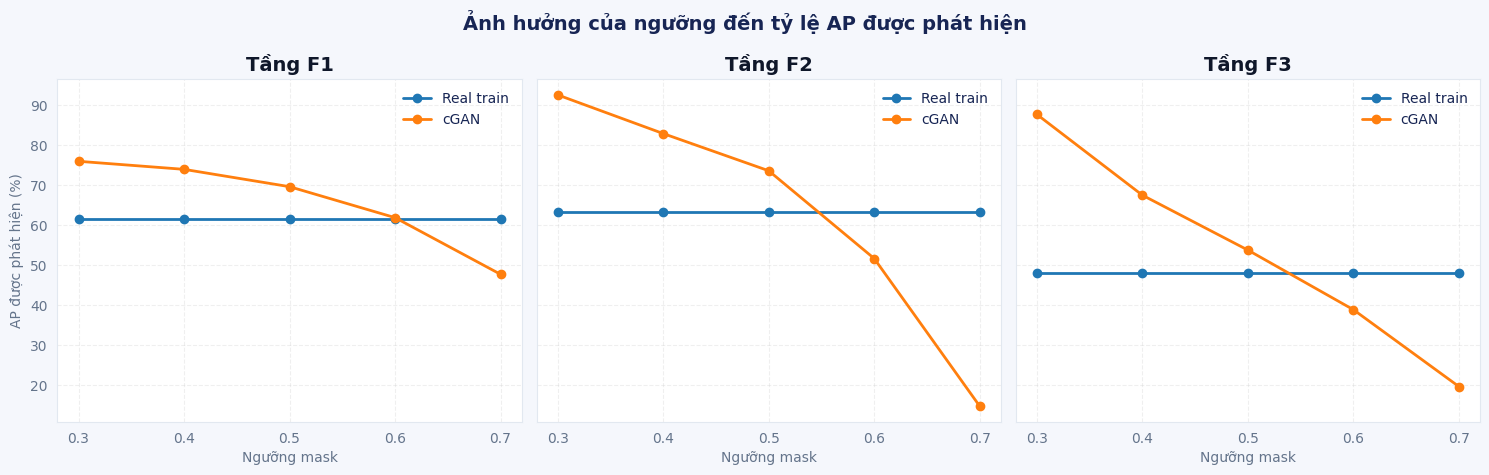

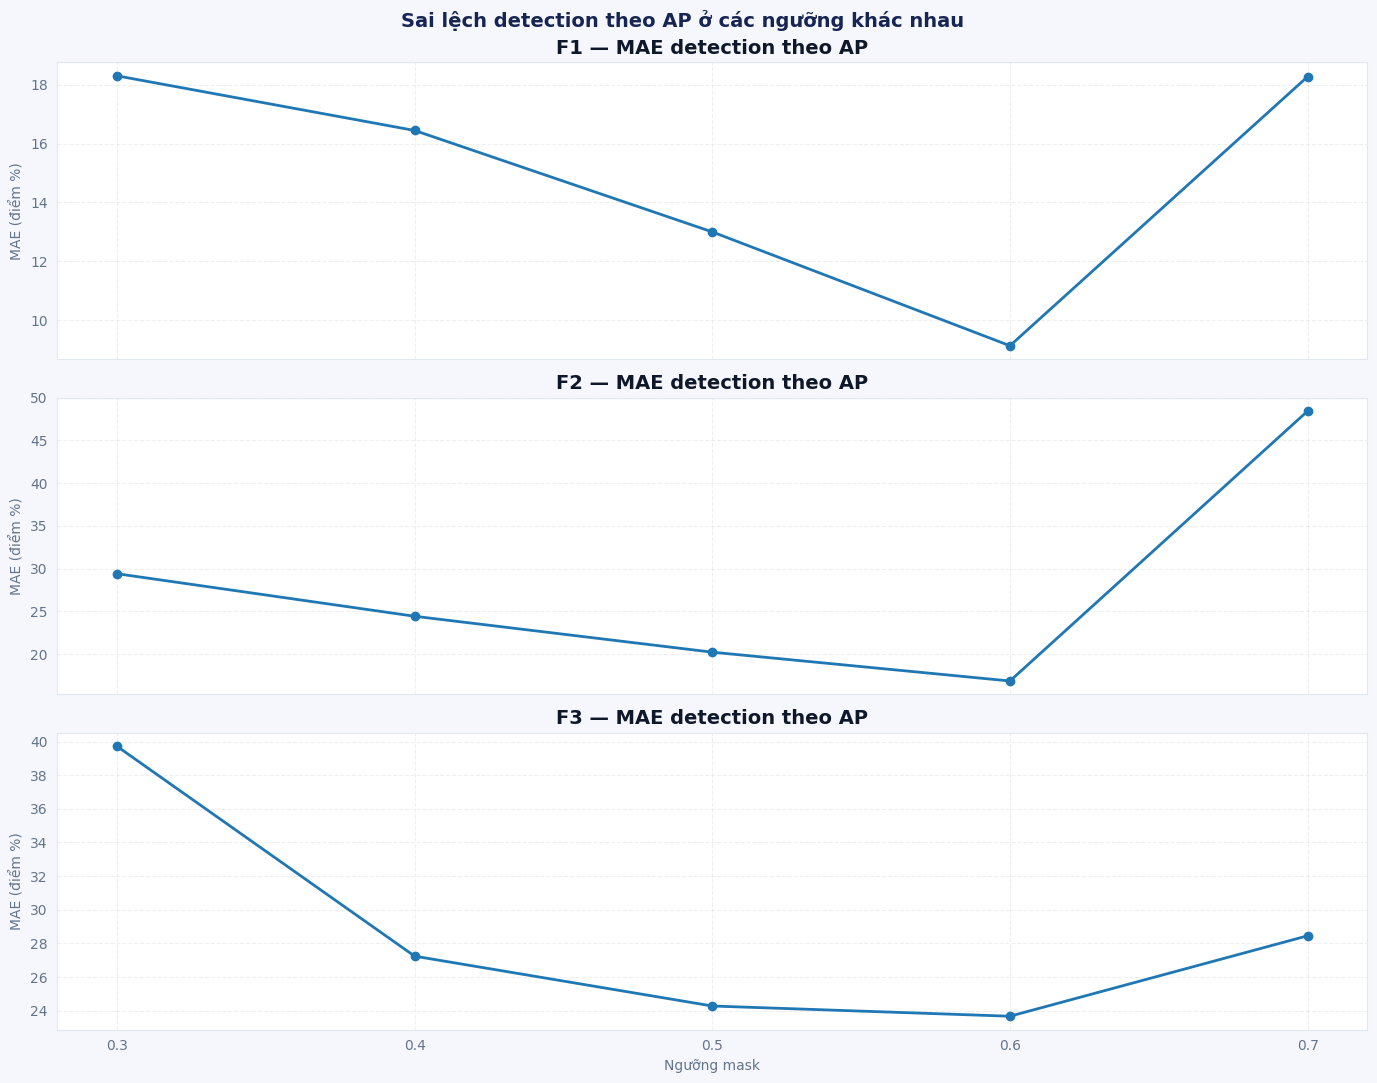


CELL 4.3.9 COMPLETED — THRESHOLD SENSITIVITY
F1: ngưỡng ứng viên=0.6; MAE detection theo AP=9.13 điểm %; độ lệch detection tổng thể=+0.29 điểm %.
F2: ngưỡng ứng viên=0.6; MAE detection theo AP=16.86 điểm %; độ lệch detection tổng thể=-11.51 điểm %.
F3: ngưỡng ứng viên=0.6; MAE detection theo AP=23.68 điểm %; độ lệch detection tổng thể=-9.11 điểm %.

Lưu ý: ngưỡng có MAE detection thấp nhất chỉ tối ưu chỉ số detection trên tập ứng viên ở lần sinh hiện tại. Không chọn ngưỡng cuối cùng chỉ dựa trên bảng này; cần đánh giá tiếp RSSI và KNN trên test set cố định.


In [ ]:

# ============================================================
# CELL 4.3.9 — MASK THRESHOLD SENSITIVITY ANALYSIS
# Thử nghiệm ngưỡng 0.3, 0.4, 0.5, 0.6, 0.7
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

FLOORS = ["F1", "F2", "F3"]
AP_COLS = [f"AP{i}" for i in range(1, 18)]
THRESHOLDS = [0.3, 0.4, 0.5, 0.6, 0.7]

# ------------------------------------------------------------
# 1. Kiểm tra xác suất mask đã có từ Cell 4.3.8
# ------------------------------------------------------------
if "mask_prob_by_floor" not in globals():
    raise NameError(
        "Không tìm thấy mask_prob_by_floor. "
        "Hãy chạy Cell 4.3.8 trước."
    )

if "splits" not in globals():
    raise NameError("Không tìm thấy splits.")

for floor in FLOORS:
    if floor not in mask_prob_by_floor:
        raise KeyError(f"Thiếu xác suất mask của {floor}.")

# ------------------------------------------------------------
# 2. Tỷ lệ phát hiện thực theo AP trên tập train
# ------------------------------------------------------------
real_detection_by_floor = {}

for floor in FLOORS:
    real_rssi = splits[floor]["train_df"][AP_COLS].to_numpy(dtype=float)
    real_detection_by_floor[floor] = (real_rssi > -100).mean(axis=0)

# ------------------------------------------------------------
# 3. Đánh giá từng ngưỡng
# ------------------------------------------------------------
threshold_rows = []
per_ap_threshold_rows = []

for floor in FLOORS:
    probs = np.asarray(mask_prob_by_floor[floor], dtype=float)
    real_ap_rates = real_detection_by_floor[floor]

    if probs.ndim != 2 or probs.shape[1] != len(AP_COLS):
        raise ValueError(f"{floor}: shape xác suất mask không hợp lệ.")

    for threshold in THRESHOLDS:
        predicted_mask = probs >= threshold

        # Tỷ lệ detection tổng thể
        predicted_overall = predicted_mask.mean() * 100
        real_overall = real_ap_rates.mean() * 100

        # Tỷ lệ detection theo từng AP tại ngưỡng đang xét
        predicted_ap_rates = predicted_mask.mean(axis=0) * 100
        real_ap_rates_pct = real_ap_rates * 100

        # MAE giữa detection rate theo AP
        # Đây là metric mô tả, không phải lỗi định vị.
        mae_ap_pp = np.mean(
            np.abs(predicted_ap_rates - real_ap_rates_pct)
        )

        mean_bias_pp = np.mean(
            predicted_ap_rates - real_ap_rates_pct
        )

        threshold_rows.append({
            "Tầng": floor,
            "Ngưỡng": threshold,
            "Real detection tổng thể (%)": real_overall,
            "cGAN detection tổng thể (%)": predicted_overall,
            "Chênh lệch tổng thể (điểm %)": (
                predicted_overall - real_overall
            ),
            "MAE detection theo AP (điểm %)": mae_ap_pp,
            "Bias detection theo AP (điểm %)": mean_bias_pp
        })

        for i, ap in enumerate(AP_COLS):
            per_ap_threshold_rows.append({
                "Tầng": floor,
                "Ngưỡng": threshold,
                "AP": ap,
                "Real detection (%)": real_ap_rates_pct[i],
                "cGAN detection (%)": predicted_ap_rates[i],
                "Chênh lệch (điểm %)": (
                    predicted_ap_rates[i] - real_ap_rates_pct[i]
                )
            })

threshold_summary_df = pd.DataFrame(threshold_rows)
threshold_per_ap_df = pd.DataFrame(per_ap_threshold_rows)

print("PASS — Đã đánh giá các ngưỡng trên cùng xác suất mask.")

# ------------------------------------------------------------
# 4. Dashboard
# ------------------------------------------------------------
display(HTML("""
<div style="
    background:linear-gradient(120deg,#172554,#4338ca,#7c3aed);
    color:white;padding:20px 24px;border-radius:16px;margin:8px 0 16px 0;">
    <div style="font-size:12px;letter-spacing:1px;opacity:.85;">
        PHẦN 4 · PHÂN TÍCH ĐỘ NHẠY
    </div>
    <div style="font-size:23px;font-weight:700;margin-top:5px;">
        Detection Mask Threshold Analysis
    </div>
    <div style="font-size:13px;opacity:.9;margin-top:5px;">
        Threshold sensitivity · Overall and per-AP detection
    </div>
</div>
"""))

# ------------------------------------------------------------
# 5. Bảng tổng hợp các ngưỡng
# ------------------------------------------------------------
display(HTML(
    "<h3 style='color:#4338ca'>Kết quả theo tầng và ngưỡng</h3>"
))

display(
    threshold_summary_df.style.format({
        "Ngưỡng": "{:.1f}",
        "Real detection tổng thể (%)": "{:.2f}",
        "cGAN detection tổng thể (%)": "{:.2f}",
        "Chênh lệch tổng thể (điểm %)": "{:+.2f}",
        "MAE detection theo AP (điểm %)": "{:.2f}",
        "Bias detection theo AP (điểm %)": "{:+.2f}"
    }).background_gradient(
        subset=["MAE detection theo AP (điểm %)"],
        cmap="RdYlGn_r"
    )
)

# ------------------------------------------------------------
# 6. Biểu đồ tỷ lệ detection tổng thể theo ngưỡng
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)

for ax, floor in zip(axes, FLOORS):
    part = threshold_summary_df[
        threshold_summary_df["Tầng"] == floor
    ]

    ax.plot(
        part["Ngưỡng"],
        part["Real detection tổng thể (%)"],
        marker="o", linewidth=2, label="Real train"
    )
    ax.plot(
        part["Ngưỡng"],
        part["cGAN detection tổng thể (%)"],
        marker="o", linewidth=2, label="cGAN"
    )

    ax.set_title(f"Tầng {floor}", fontweight="bold")
    ax.set_xlabel("Ngưỡng mask")
    ax.set_xticks(THRESHOLDS)
    ax.grid(linestyle="--", alpha=0.3)
    ax.legend(frameon=False)

axes[0].set_ylabel("AP được phát hiện (%)")
fig.suptitle(
    "Ảnh hưởng của ngưỡng đến tỷ lệ AP được phát hiện",
    fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Biểu đồ sai lệch detection theo từng AP
# ------------------------------------------------------------
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

for ax, floor in zip(axes, FLOORS):
    part = threshold_summary_df[
        threshold_summary_df["Tầng"] == floor
    ]

    ax.plot(
        part["Ngưỡng"],
        part["MAE detection theo AP (điểm %)"],
        marker="o", linewidth=2
    )

    ax.set_title(
        f"{floor} — MAE detection theo AP",
        fontweight="bold"
    )
    ax.set_ylabel("MAE (điểm %)")
    ax.set_xticks(THRESHOLDS)
    ax.grid(linestyle="--", alpha=0.3)

axes[-1].set_xlabel("Ngưỡng mask")
fig.suptitle(
    "Sai lệch detection theo AP ở các ngưỡng khác nhau",
    fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Ngưỡng có MAE detection theo AP thấp nhất trong từng tầng
# Chỉ là ngưỡng ứng viên để khảo sát tiếp, không phải kết luận
# tối ưu cho định vị.
# ------------------------------------------------------------
print("\n" + "=" * 68)
print("CELL 4.3.9 COMPLETED — THRESHOLD SENSITIVITY")
print("=" * 68)

for floor in FLOORS:
    part = threshold_summary_df[
        threshold_summary_df["Tầng"] == floor
    ].copy()

    best_idx = part["MAE detection theo AP (điểm %)"].idxmin()
    best = part.loc[best_idx]

    print(
        f'{floor}: ngưỡng ứng viên={best["Ngưỡng"]:.1f}; '
        f'MAE detection theo AP={best["MAE detection theo AP (điểm %)"]:.2f} '
        f'điểm %; '
        f'độ lệch detection tổng thể='
        f'{best["Chênh lệch tổng thể (điểm %)"]:+.2f} điểm %.'
    )

print(
    "\nLưu ý: ngưỡng có MAE detection thấp nhất chỉ tối ưu "
    "chỉ số detection trên tập ứng viên ở lần sinh hiện tại. "
    "Không chọn ngưỡng cuối cùng chỉ dựa trên bảng này; "
    "cần đánh giá tiếp RSSI và KNN trên test set cố định."
)


### 4.3.10. Đánh giá ảnh hưởng của ngưỡng detection mask đến định vị KNN

Mục tiêu là đánh giá liệu việc thay đổi ngưỡng detection mask có cải thiện hiệu quả định vị khi bổ sung fingerprint cGAN hay không.

Thí nghiệm so sánh:
- Original: chỉ sử dụng fingerprint thực trong tập train.
- Original + cGAN (ngưỡng 0,3; 0,4; 0,5; 0,6; 0,7): sử dụng dữ liệu train gốc kết hợp fingerprint tổng hợp với trạng thái AP được xác định theo từng ngưỡng.

Tất cả cấu hình sử dụng cùng test set, cùng KNN (K = 5, weights = distance) và cùng bộ chuẩn hóa RSSI được fit trên tập train gốc.

RSSI của AP không được phát hiện được đặt bằng −100 dBm. Kết quả được đánh giá bằng MAE, RMSE và Median Error theo mét.

**Lưu ý:** đây là thí nghiệm độ nhạy của hậu xử lý mask, không phải huấn luyện lại cGAN. Ngưỡng tốt nhất theo detection chưa chắc tốt nhất theo định vị.

PASS — Đã đánh giá baseline và các ngưỡng mask.
Scaler được fit riêng trên train gốc của từng tầng.


,Tầng,Phương pháp,Ngưỡng mask,Train samples,Test samples,MAE định vị (m),RMSE định vị (m),Median Error (m),MAE X (m),MAE Y (m)
0,F1,Original,—,5020,1260,4.1741,5.0764,3.5297,3.2844,1.8828
1,F1,Original + cGAN,0.3,5096,1260,4.1869,5.0938,3.5842,3.2934,1.8904
2,F1,Original + cGAN,0.4,5096,1260,4.1869,5.0938,3.5842,3.2934,1.8904
3,F1,Original + cGAN,0.5,5096,1260,4.1869,5.0938,3.5842,3.2934,1.8904
4,F1,Original + cGAN,0.6,5096,1260,4.1890,5.0936,3.5534,3.3029,1.8785
5,F1,Original + cGAN,0.7,5096,1260,4.1822,5.0791,3.5718,3.2742,1.9076
6,F2,Original,—,2960,760,3.2974,4.1818,2.6641,2.7449,1.2340
7,F2,Original + cGAN,0.3,3134,760,3.4223,4.2893,2.7780,2.8731,1.2737
8,F2,Original + cGAN,0.4,3134,760,3.4223,4.2893,2.7780,2.8731,1.2737
9,F2,Original + cGAN,0.5,3134,760,3.4223,4.2893,2.7780,2.8731,1.2737


,Tầng,Ngưỡng mask,MAE Original (m),MAE Original + cGAN (m),Δ MAE (m),Thay đổi MAE (%),Kết quả
0,F1,0.3,4.1741,4.1869,+0.0129,+0.31%,Sai số tăng
1,F1,0.4,4.1741,4.1869,+0.0129,+0.31%,Sai số tăng
2,F1,0.5,4.1741,4.1869,+0.0129,+0.31%,Sai số tăng
3,F1,0.6,4.1741,4.1890,+0.0150,+0.36%,Sai số tăng
4,F1,0.7,4.1741,4.1822,+0.0082,+0.20%,Sai số tăng
5,F2,0.3,3.2974,3.4223,+0.1249,+3.79%,Sai số tăng
6,F2,0.4,3.2974,3.4223,+0.1249,+3.79%,Sai số tăng
7,F2,0.5,3.2974,3.4223,+0.1249,+3.79%,Sai số tăng
8,F2,0.6,3.2974,3.4550,+0.1576,+4.78%,Sai số tăng
9,F2,0.7,3.2974,3.3548,+0.0574,+1.74%,Sai số tăng


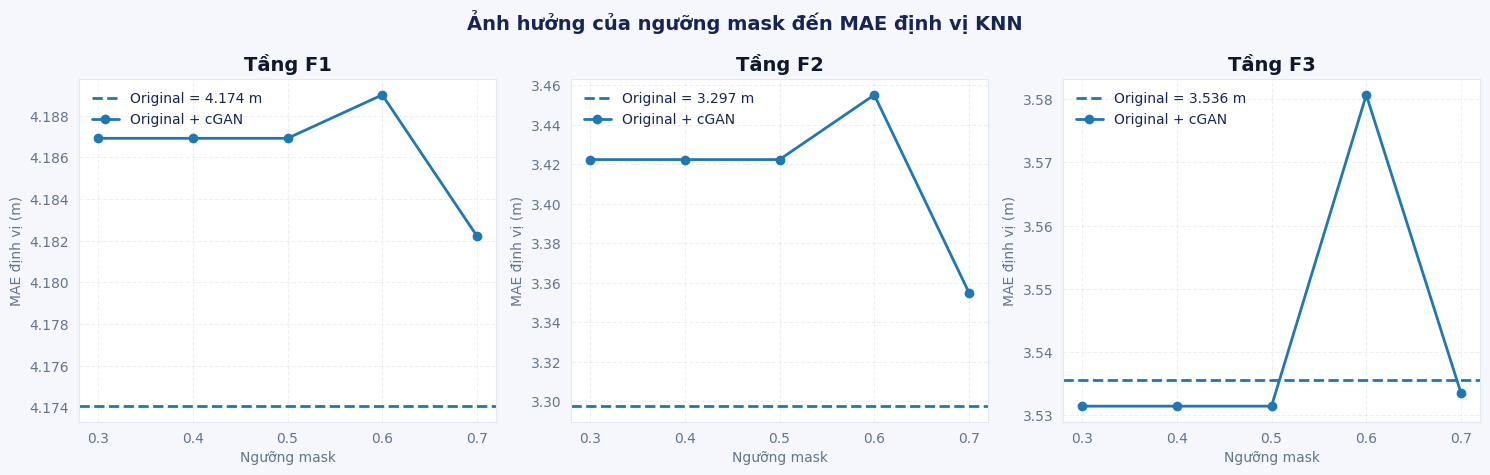


CELL 4.3.10 COMPLETED — KNN THRESHOLD EXPERIMENT
F1: ngưỡng tốt nhất trong các ngưỡng thử=0.7; MAE=4.1822 m; Original=4.1741 m; thay đổi=+0.20%.
F2: ngưỡng tốt nhất trong các ngưỡng thử=0.7; MAE=3.3548 m; Original=3.2974 m; thay đổi=+1.74%.
F3: ngưỡng tốt nhất trong các ngưỡng thử=0.3; MAE=3.5314 m; Original=3.5356 m; thay đổi=-0.12%.

Lưu ý: ngưỡng tốt nhất ở đây được chọn theo MAE trên test set, nên chỉ được xem là kết quả khảo sát. Nếu dùng test để chọn ngưỡng rồi báo cáo hiệu năng cuối cùng trên chính test đó, kết quả có thể lạc quan hơn thực tế. Cần validation riêng để chọn ngưỡng và giữ test cho đánh giá cuối cùng.


In [ ]:

# ============================================================
# CELL 4.3.10 — THRESHOLD IMPACT ON KNN LOCALIZATION
# Original vs Original + cGAN at different mask thresholds
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from IPython.display import display, HTML

FLOORS = ["F1", "F2", "F3"]
AP_COLS = [f"AP{i}" for i in range(1, 18)]
XY_COLS = ["X", "Y"]
THRESHOLDS = [0.3, 0.4, 0.5, 0.6, 0.7]
K_NEIGHBORS = 5

# ------------------------------------------------------------
# 1. Kiểm tra các biến cần thiết
# ------------------------------------------------------------
required_objects = [
    "synthetic_df",
    "mask_prob_by_floor",
    "localization_datasets",
    "splits"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        f"Thiếu biến: {missing_objects}. "
        "Hãy kiểm tra các cell trước khi chạy."
    )

# ------------------------------------------------------------
# 2. Hàm đánh giá định vị
# ------------------------------------------------------------
def localization_metrics(y_true, y_pred):
    errors_xy = np.linalg.norm(y_true - y_pred, axis=1)

    return {
        "MAE định vị (m)": float(errors_xy.mean()),
        "RMSE định vị (m)": float(np.sqrt(np.mean(errors_xy ** 2))),
        "Median Error (m)": float(np.median(errors_xy)),
        "MAE X (m)": float(np.abs(y_true[:, 0] - y_pred[:, 0]).mean()),
        "MAE Y (m)": float(np.abs(y_true[:, 1] - y_pred[:, 1]).mean())
    }

# ------------------------------------------------------------
# 3. Chạy baseline và các ngưỡng mask
# Scaler chỉ fit trên train gốc, không fit trên test
# ------------------------------------------------------------
threshold_knn_rows = []
threshold_knn_predictions = {}
threshold_synthetic_dfs = {}

for floor in FLOORS:
    train_original = localization_datasets[floor][
        "train_original"
    ].copy()

    test_df = localization_datasets[floor]["test"].copy()

    coords = mask_prob_by_floor[floor]
    syn_original = synthetic_df[
        synthetic_df["Floor"].astype(str) == floor
    ].copy().reset_index(drop=True)

    if len(syn_original) != len(coords):
        raise ValueError(
            f"{floor}: số fingerprint synthetic ({len(syn_original)}) "
            f"không khớp số tọa độ có mask ({len(coords)})."
        )

    X_train_original = train_original[AP_COLS].to_numpy(dtype=float)
    y_train_original = train_original[XY_COLS].to_numpy(dtype=float)

    X_test = test_df[AP_COLS].to_numpy(dtype=float)
    y_test = test_df[XY_COLS].to_numpy(dtype=float)

    # Fit scaler chỉ trên dữ liệu train gốc
    scaler = StandardScaler()
    X_train_original_scaled = scaler.fit_transform(X_train_original)
    X_test_scaled = scaler.transform(X_test)

    # Baseline: Original
    baseline_model = KNeighborsRegressor(
        n_neighbors=K_NEIGHBORS,
        weights="distance"
    )
    baseline_model.fit(X_train_original_scaled, y_train_original)
    baseline_pred = baseline_model.predict(X_test_scaled)

    baseline_metrics = localization_metrics(y_test, baseline_pred)

    threshold_knn_rows.append({
        "Tầng": floor,
        "Phương pháp": "Original",
        "Ngưỡng mask": np.nan,
        "Train samples": len(train_original),
        "Test samples": len(test_df),
        **baseline_metrics
    })

    threshold_knn_predictions[(floor, "Original")] = baseline_pred

    # Các ngưỡng mask
    for threshold in THRESHOLDS:
        syn = syn_original.copy()

        # Xác định trạng thái AP theo xác suất mask
        detected_mask = coords >= threshold

        # Chuyển RSSI tổng hợp về -100 dBm ở AP bị mask
        syn_rssi = syn[AP_COLS].to_numpy(dtype=float)
        syn_rssi[~detected_mask] = -100.0
        syn.loc[:, AP_COLS] = syn_rssi

        # Không thay đổi tọa độ synthetic
        X_syn = syn[AP_COLS].to_numpy(dtype=float)

        # Chuẩn hóa bằng scaler fit trên train gốc
        X_syn_scaled = scaler.transform(X_syn)

        X_train_aug = np.vstack([
            X_train_original_scaled,
            X_syn_scaled
        ])

        y_train_aug = np.vstack([
            y_train_original,
            syn[XY_COLS].to_numpy(dtype=float)
        ])

        model = KNeighborsRegressor(
            n_neighbors=K_NEIGHBORS,
            weights="distance"
        )
        model.fit(X_train_aug, y_train_aug)

        y_pred = model.predict(X_test_scaled)
        metrics = localization_metrics(y_test, y_pred)

        threshold_knn_rows.append({
            "Tầng": floor,
            "Phương pháp": "Original + cGAN",
            "Ngưỡng mask": threshold,
            "Train samples": len(train_original) + len(syn),
            "Test samples": len(test_df),
            **metrics
        })

        threshold_knn_predictions[(floor, threshold)] = y_pred
        threshold_synthetic_dfs[(floor, threshold)] = syn

threshold_knn_results_df = pd.DataFrame(threshold_knn_rows)

print("PASS — Đã đánh giá baseline và các ngưỡng mask.")
print("Scaler được fit riêng trên train gốc của từng tầng.")

# ------------------------------------------------------------
# 4. Bảng kết quả
# ------------------------------------------------------------
display(HTML("""
<div style="
    background:linear-gradient(120deg,#172554,#4338ca,#7c3aed);
    color:white;padding:20px 24px;border-radius:16px;margin:8px 0 16px 0;">
    <div style="font-size:12px;letter-spacing:1px;opacity:.85;">
        PHẦN 4 · ĐÁNH GIÁ ĐỊNH VỊ
    </div>
    <div style="font-size:23px;font-weight:700;margin-top:5px;">
        KNN Performance by Mask Threshold
    </div>
    <div style="font-size:13px;opacity:.9;margin-top:5px;">
        Same test set · Same KNN configuration · Same RSSI scaler
    </div>
</div>
"""))

display(
    threshold_knn_results_df.style.format({
        "Ngưỡng mask": lambda v: "—" if pd.isna(v) else f"{v:.1f}",
        "MAE định vị (m)": "{:.4f}",
        "RMSE định vị (m)": "{:.4f}",
        "Median Error (m)": "{:.4f}",
        "MAE X (m)": "{:.4f}",
        "MAE Y (m)": "{:.4f}"
    })
)

# ------------------------------------------------------------
# 5. So sánh thay đổi MAE so với baseline
# Giá trị âm = cải thiện; dương = sai số tăng
# ------------------------------------------------------------
threshold_delta_rows = []

for floor in FLOORS:
    part = threshold_knn_results_df[
        threshold_knn_results_df["Tầng"] == floor
    ]

    base = part[part["Phương pháp"] == "Original"].iloc[0]

    for threshold in THRESHOLDS:
        row = part[
            (part["Phương pháp"] == "Original + cGAN")
            & (part["Ngưỡng mask"] == threshold)
        ].iloc[0]

        delta = (
            row["MAE định vị (m)"] - base["MAE định vị (m)"]
        )
        delta_pct = delta / base["MAE định vị (m)"] * 100

        threshold_delta_rows.append({
            "Tầng": floor,
            "Ngưỡng mask": threshold,
            "MAE Original (m)": base["MAE định vị (m)"],
            "MAE Original + cGAN (m)": row["MAE định vị (m)"],
            "Δ MAE (m)": delta,
            "Thay đổi MAE (%)": delta_pct,
            "Kết quả": (
                "Cải thiện" if delta < 0
                else "Sai số tăng" if delta > 0
                else "Không đổi"
            )
        })

threshold_knn_delta_df = pd.DataFrame(threshold_delta_rows)

display(HTML(
    "<h3 style='color:#4338ca'>Mức thay đổi MAE so với Original</h3>"
))

display(
    threshold_knn_delta_df.style.format({
        "Ngưỡng mask": "{:.1f}",
        "MAE Original (m)": "{:.4f}",
        "MAE Original + cGAN (m)": "{:.4f}",
        "Δ MAE (m)": "{:+.4f}",
        "Thay đổi MAE (%)": "{:+.2f}%"
    }).background_gradient(
        subset=["Thay đổi MAE (%)"],
        cmap="RdYlGn_r"
    )
)

# ------------------------------------------------------------
# 6. Biểu đồ MAE theo ngưỡng
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=False)

for ax, floor in zip(axes, FLOORS):
    part = threshold_knn_results_df[
        threshold_knn_results_df["Tầng"] == floor
    ]

    baseline_mae = float(
        part[part["Phương pháp"] == "Original"][
            "MAE định vị (m)"
        ].iloc[0]
    )

    aug = part[
        part["Phương pháp"] == "Original + cGAN"
    ].sort_values("Ngưỡng mask")

    ax.axhline(
        baseline_mae,
        linestyle="--",
        linewidth=2,
        label=f"Original = {baseline_mae:.3f} m"
    )

    ax.plot(
        aug["Ngưỡng mask"],
        aug["MAE định vị (m)"],
        marker="o",
        linewidth=2,
        label="Original + cGAN"
    )

    ax.set_title(f"Tầng {floor}", fontweight="bold")
    ax.set_xlabel("Ngưỡng mask")
    ax.set_ylabel("MAE định vị (m)")
    ax.set_xticks(THRESHOLDS)
    ax.grid(linestyle="--", alpha=0.3)
    ax.legend(frameon=False)

fig.suptitle(
    "Ảnh hưởng của ngưỡng mask đến MAE định vị KNN",
    fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Báo cáo ngưỡng tốt nhất theo MAE mỗi tầng
# Chỉ là kết quả trong các ngưỡng được thử
# ------------------------------------------------------------
print("\n" + "=" * 68)
print("CELL 4.3.10 COMPLETED — KNN THRESHOLD EXPERIMENT")
print("=" * 68)

for floor in FLOORS:
    part = threshold_knn_delta_df[
        threshold_knn_delta_df["Tầng"] == floor
    ].copy()

    best = part.loc[part["MAE Original + cGAN (m)"].idxmin()]

    baseline = float(part["MAE Original (m)"].iloc[0])

    print(
        f'{floor}: ngưỡng tốt nhất trong các ngưỡng thử={best["Ngưỡng mask"]:.1f}; '
        f'MAE={best["MAE Original + cGAN (m)"]:.4f} m; '
        f'Original={baseline:.4f} m; '
        f'thay đổi={best["Thay đổi MAE (%)"]:+.2f}%.'
    )

print(
    "\nLưu ý: ngưỡng tốt nhất ở đây được chọn theo MAE trên test set, "
    "nên chỉ được xem là kết quả khảo sát. Nếu dùng test để chọn ngưỡng "
    "rồi báo cáo hiệu năng cuối cùng trên chính test đó, kết quả có thể "
    "lạc quan hơn thực tế. Cần validation riêng để chọn ngưỡng và giữ "
    "test cho đánh giá cuối cùng."
)


### 4.3.11. Phân tích ảnh hưởng của tỷ lệ dữ liệu cGAN được bổ sung

Thí nghiệm đánh giá ảnh hưởng của số lượng fingerprint tổng hợp được bổ sung vào tập huấn luyện đến hiệu quả định vị KNN.

Các cấu hình so sánh gồm:
- **Original:** chỉ sử dụng dữ liệu huấn luyện gốc.
- **Original + 25% cGAN:** bổ sung 25% fingerprint tổng hợp hiện có.
- **Original + 50% cGAN:** bổ sung 50% fingerprint tổng hợp hiện có.
- **Original + 100% cGAN:** bổ sung toàn bộ fingerprint tổng hợp hiện có.

Các fingerprint được chọn từ tập dữ liệu tổng hợp đã sinh, không sao chép lặp để tăng số lượng mẫu. Tất cả cấu hình sử dụng cùng test set, KNN với K = 5 và weights = distance, cùng bộ chuẩn hóa RSSI được fit trên tập train gốc.

Hiệu quả được đánh giá bằng MAE, RMSE và Median Error theo mét. Kết quả nhằm khảo sát mối liên hệ giữa tỷ lệ dữ liệu tổng hợp và hiệu quả định vị, không mặc định rằng tăng dữ liệu sẽ cải thiện độ chính xác.

PASS — Đã đánh giá các tỷ lệ bổ sung cGAN.
Không nhân bản fingerprint; test set không đổi.
StandardScaler chỉ fit trên train gốc của từng tầng.


,Tầng,Tỷ lệ cGAN,Số synthetic,Train samples,Test samples,MAE định vị (m),RMSE định vị (m),Median Error (m),MAE X (m),MAE Y (m)
0,F1,Original,0,5020,1260,4.1741,5.0764,3.5297,3.2844,1.8828
1,F1,25%,19,5039,1260,4.1639,5.0582,3.5275,3.2719,1.8849
2,F1,50%,38,5058,1260,4.1902,5.0898,3.5756,3.3020,1.8830
3,F1,100%,76,5096,1260,4.1869,5.0938,3.5842,3.2934,1.8904
4,F2,Original,0,2960,760,3.2974,4.1818,2.6641,2.7449,1.2340
5,F2,25%,44,3004,760,3.3608,4.2340,2.7533,2.8121,1.2449
6,F2,50%,87,3047,760,3.3742,4.2330,2.7533,2.8336,1.2451
7,F2,100%,174,3134,760,3.4223,4.2893,2.7780,2.8731,1.2737
8,F3,Original,0,2400,600,3.5356,4.2758,3.0986,3.0433,1.2097
9,F3,25%,8,2408,600,3.5033,4.2423,3.0634,3.0047,1.2061


,Tầng,Tỷ lệ cGAN,Số synthetic,Δ MAE (m),Thay đổi MAE (%),Δ RMSE (m),Thay đổi RMSE (%)
0,F1,25%,19,-0.0102,-0.24%,-0.0182,-0.36%
1,F1,50%,38,+0.0162,+0.39%,+0.0134,+0.26%
2,F1,100%,76,+0.0129,+0.31%,+0.0174,+0.34%
3,F2,25%,44,+0.0634,+1.92%,+0.0521,+1.25%
4,F2,50%,87,+0.0767,+2.33%,+0.0511,+1.22%
5,F2,100%,174,+0.1249,+3.79%,+0.1075,+2.57%
6,F3,25%,8,-0.0323,-0.91%,-0.0336,-0.79%
7,F3,50%,15,+0.0142,+0.40%,+0.0128,+0.30%
8,F3,100%,30,-0.0042,-0.12%,+0.0001,+0.00%


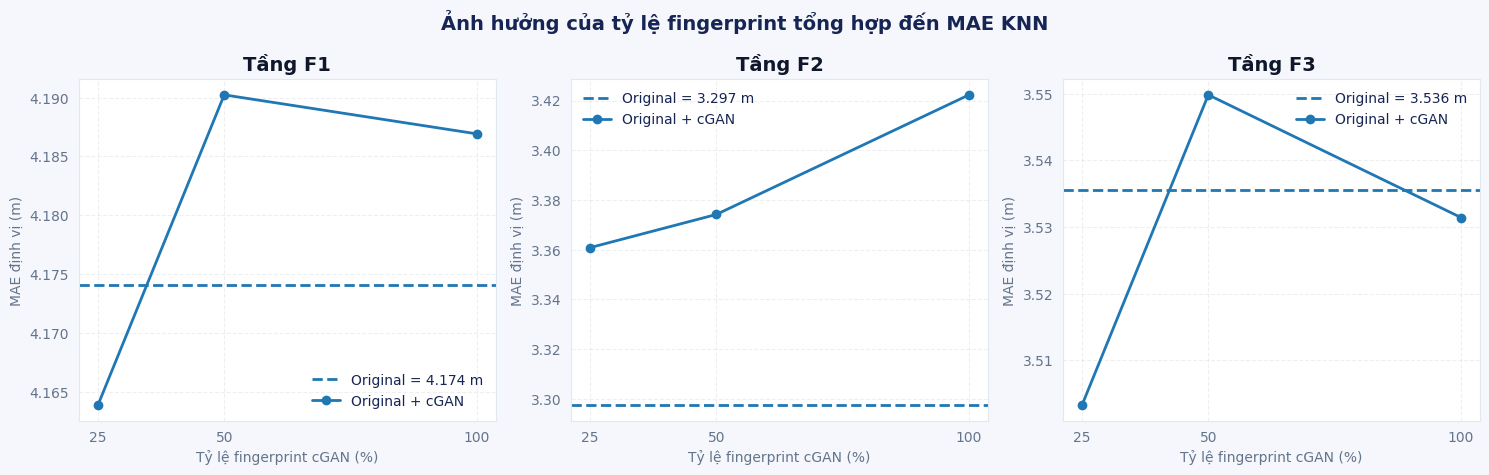


CELL 4.3.11 COMPLETED — SYNTHETIC DATA RATIO ANALYSIS
F1: tỷ lệ có MAE thấp nhất trong các mức thử=25%; MAE=4.1639 m; Original=4.1741 m; thay đổi=-0.24%.
F2: tỷ lệ có MAE thấp nhất trong các mức thử=25%; MAE=3.3608 m; Original=3.2974 m; thay đổi=+1.92%.
F3: tỷ lệ có MAE thấp nhất trong các mức thử=25%; MAE=3.5033 m; Original=3.5356 m; thay đổi=-0.91%.

Lưu ý: mỗi tỷ lệ dùng một tập con không hoàn lại của fingerprint cGAN. Kết quả có thể phụ thuộc vào mẫu được chọn; đây là thí nghiệm khảo sát, chưa phải bằng chứng rằng một tỷ lệ là tối ưu. Cần chọn cấu hình trên validation set trước khi đánh giá test cuối cùng.


In [ ]:

# ============================================================
# CELL 4.3.11 — SYNTHETIC DATA RATIO EXPERIMENT
# Original vs Original + 25%, 50%, 100% cGAN
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from IPython.display import display, HTML

FLOORS = ["F1", "F2", "F3"]
AP_COLS = [f"AP{i}" for i in range(1, 18)]
XY_COLS = ["X", "Y"]
AUGMENT_RATIOS = [0.25, 0.50, 1.00]
K_NEIGHBORS = 5
RANDOM_SEED = 4311

# ------------------------------------------------------------
# 1. Kiểm tra dữ liệu đầu vào
# ------------------------------------------------------------
required_objects = ["localization_datasets", "synthetic_df"]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        f"Thiếu biến: {missing_objects}. "
        "Hãy chạy lại các cell chuẩn bị dữ liệu trước."
    )

required_columns = ["Floor"] + XY_COLS + AP_COLS

missing_cols = set(required_columns) - set(synthetic_df.columns)

if missing_cols:
    raise ValueError(
        f"synthetic_df thiếu cột: {sorted(missing_cols)}"
    )

# ------------------------------------------------------------
# 2. Hàm tính metric định vị
# ------------------------------------------------------------
def ratio_localization_metrics(y_true, y_pred):
    errors_xy = np.linalg.norm(y_true - y_pred, axis=1)

    return {
        "MAE định vị (m)": float(errors_xy.mean()),
        "RMSE định vị (m)": float(
            np.sqrt(np.mean(errors_xy ** 2))
        ),
        "Median Error (m)": float(np.median(errors_xy)),
        "MAE X (m)": float(
            np.abs(y_true[:, 0] - y_pred[:, 0]).mean()
        ),
        "MAE Y (m)": float(
            np.abs(y_true[:, 1] - y_pred[:, 1]).mean()
        )
    }

# ------------------------------------------------------------
# 3. Đánh giá theo tỷ lệ dữ liệu tổng hợp
# Mỗi tỷ lệ là tập con của cùng synthetic_df.
# Không lấy mẫu lặp, không dùng test để fit scaler.
# ------------------------------------------------------------
ratio_results = []
ratio_predictions = {}
ratio_selected_synthetic = {}

for floor_idx, floor in enumerate(FLOORS):

    train_original = localization_datasets[floor][
        "train_original"
    ].copy().reset_index(drop=True)

    test_df = localization_datasets[floor][
        "test"
    ].copy().reset_index(drop=True)

    syn_floor = synthetic_df[
        synthetic_df["Floor"].astype(str) == floor
    ].copy().reset_index(drop=True)

    if train_original.empty or test_df.empty:
        raise ValueError(
            f"{floor}: tập train hoặc test đang rỗng."
        )

    if syn_floor.empty:
        raise ValueError(
            f"{floor}: không có fingerprint cGAN."
        )

    # Kiểm tra cột và giá trị số
    for name, frame in [
        ("train_original", train_original),
        ("test", test_df),
        ("synthetic", syn_floor)
    ]:
        values = frame[XY_COLS + AP_COLS].to_numpy(dtype=float)

        if not np.isfinite(values).all():
            raise ValueError(
                f"{floor}: dữ liệu {name} có NaN hoặc Inf."
            )

    X_train_original = train_original[AP_COLS].to_numpy(dtype=float)
    y_train_original = train_original[XY_COLS].to_numpy(dtype=float)

    X_test = test_df[AP_COLS].to_numpy(dtype=float)
    y_test = test_df[XY_COLS].to_numpy(dtype=float)

    # Fit scaler chỉ trên train gốc
    scaler = StandardScaler()
    X_train_original_scaled = scaler.fit_transform(X_train_original)
    X_test_scaled = scaler.transform(X_test)

    # Baseline Original
    baseline_model = KNeighborsRegressor(
        n_neighbors=K_NEIGHBORS,
        weights="distance"
    )
    baseline_model.fit(
        X_train_original_scaled,
        y_train_original
    )

    baseline_pred = baseline_model.predict(X_test_scaled)
    baseline_metrics = ratio_localization_metrics(
        y_test, baseline_pred
    )

    ratio_results.append({
        "Tầng": floor,
        "Tỷ lệ cGAN": "Original",
        "Số synthetic": 0,
        "Train samples": len(train_original),
        "Test samples": len(test_df),
        **baseline_metrics
    })

    ratio_predictions[(floor, "Original")] = baseline_pred

    # Chọn các tập con theo tỷ lệ
    for ratio in AUGMENT_RATIOS:
        n_select = max(1, int(round(len(syn_floor) * ratio)))

        # Cùng seed theo tầng, lấy mẫu không hoàn lại
        rng = np.random.default_rng(
            RANDOM_SEED + floor_idx
        )
        selected_positions = np.sort(
            rng.choice(
                len(syn_floor),
                size=n_select,
                replace=False
            )
        )

        syn_selected = syn_floor.iloc[
            selected_positions
        ].copy().reset_index(drop=True)

        ratio_label = f"{int(ratio * 100)}%"

        ratio_selected_synthetic[
            (floor, ratio_label)
        ] = syn_selected.copy()

        X_syn = syn_selected[AP_COLS].to_numpy(dtype=float)
        y_syn = syn_selected[XY_COLS].to_numpy(dtype=float)

        X_syn_scaled = scaler.transform(X_syn)

        X_train_aug_scaled = np.vstack([
            X_train_original_scaled,
            X_syn_scaled
        ])

        y_train_aug = np.vstack([
            y_train_original,
            y_syn
        ])

        model = KNeighborsRegressor(
            n_neighbors=K_NEIGHBORS,
            weights="distance"
        )

        model.fit(X_train_aug_scaled, y_train_aug)

        pred = model.predict(X_test_scaled)
        metrics = ratio_localization_metrics(y_test, pred)

        ratio_results.append({
            "Tầng": floor,
            "Tỷ lệ cGAN": ratio_label,
            "Số synthetic": n_select,
            "Train samples": len(train_original) + n_select,
            "Test samples": len(test_df),
            **metrics
        })

        ratio_predictions[(floor, ratio_label)] = pred

ratio_results_df = pd.DataFrame(ratio_results)

print("PASS — Đã đánh giá các tỷ lệ bổ sung cGAN.")
print("Không nhân bản fingerprint; test set không đổi.")
print("StandardScaler chỉ fit trên train gốc của từng tầng.")

# ------------------------------------------------------------
# 4. Dashboard và bảng kết quả
# ------------------------------------------------------------
display(HTML("""
<div style="
    background:linear-gradient(120deg,#172554,#4338ca,#7c3aed);
    color:white;padding:20px 24px;border-radius:16px;margin:8px 0 16px 0;">
    <div style="font-size:12px;letter-spacing:1px;opacity:.85;">
        PHẦN 4 · THÍ NGHIỆM TỶ LỆ TĂNG CƯỜNG
    </div>
    <div style="font-size:23px;font-weight:700;margin-top:5px;">
        Synthetic Data Ratio Analysis
    </div>
    <div style="font-size:13px;opacity:.9;margin-top:5px;">
        Original · 25% · 50% · 100% cGAN
    </div>
</div>
"""))

display(
    ratio_results_df.style.format({
        "MAE định vị (m)": "{:.4f}",
        "RMSE định vị (m)": "{:.4f}",
        "Median Error (m)": "{:.4f}",
        "MAE X (m)": "{:.4f}",
        "MAE Y (m)": "{:.4f}"
    })
)

# ------------------------------------------------------------
# 5. Mức thay đổi MAE/RMSE so với Original
# ------------------------------------------------------------
ratio_delta_rows = []

for floor in FLOORS:
    part = ratio_results_df[
        ratio_results_df["Tầng"] == floor
    ]

    base = part[
        part["Tỷ lệ cGAN"] == "Original"
    ].iloc[0]

    for label in ["25%", "50%", "100%"]:
        row = part[
            part["Tỷ lệ cGAN"] == label
        ].iloc[0]

        mae_delta = (
            row["MAE định vị (m)"] -
            base["MAE định vị (m)"]
        )

        rmse_delta = (
            row["RMSE định vị (m)"] -
            base["RMSE định vị (m)"]
        )

        ratio_delta_rows.append({
            "Tầng": floor,
            "Tỷ lệ cGAN": label,
            "Số synthetic": int(row["Số synthetic"]),
            "Δ MAE (m)": mae_delta,
            "Thay đổi MAE (%)": (
                mae_delta / base["MAE định vị (m)"] * 100
            ),
            "Δ RMSE (m)": rmse_delta,
            "Thay đổi RMSE (%)": (
                rmse_delta / base["RMSE định vị (m)"] * 100
            )
        })

ratio_delta_df = pd.DataFrame(ratio_delta_rows)

display(HTML(
    "<h3 style='color:#4338ca'>Thay đổi sai số so với Original</h3>"
))

display(
    ratio_delta_df.style.format({
        "Tỷ lệ cGAN": "{}",
        "Δ MAE (m)": "{:+.4f}",
        "Thay đổi MAE (%)": "{:+.2f}%",
        "Δ RMSE (m)": "{:+.4f}",
        "Thay đổi RMSE (%)": "{:+.2f}%"
    }).background_gradient(
        subset=["Thay đổi MAE (%)"],
        cmap="RdYlGn_r"
    )
)

# ------------------------------------------------------------
# 6. Biểu đồ MAE theo tỷ lệ tăng cường
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

for ax, floor in zip(axes, FLOORS):
    part = ratio_results_df[
        ratio_results_df["Tầng"] == floor
    ]

    base_mae = float(
        part[part["Tỷ lệ cGAN"] == "Original"][
            "MAE định vị (m)"
        ].iloc[0]
    )

    aug = part[
        part["Tỷ lệ cGAN"].isin(["25%", "50%", "100%"])
    ].copy()

    order = {"25%": 25, "50%": 50, "100%": 100}
    aug["_order"] = aug["Tỷ lệ cGAN"].map(order)
    aug = aug.sort_values("_order")

    ax.axhline(
        base_mae,
        linestyle="--",
        linewidth=2,
        label=f"Original = {base_mae:.3f} m"
    )

    ax.plot(
        aug["_order"],
        aug["MAE định vị (m)"],
        marker="o",
        linewidth=2,
        label="Original + cGAN"
    )

    ax.set_title(f"Tầng {floor}", fontweight="bold")
    ax.set_xlabel("Tỷ lệ fingerprint cGAN (%)")
    ax.set_ylabel("MAE định vị (m)")
    ax.set_xticks([25, 50, 100])
    ax.grid(linestyle="--", alpha=0.3)
    ax.legend(frameon=False)

fig.suptitle(
    "Ảnh hưởng của tỷ lệ fingerprint tổng hợp đến MAE KNN",
    fontsize=14,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Báo cáo mô tả theo tầng
# ------------------------------------------------------------
print("\n" + "=" * 68)
print("CELL 4.3.11 COMPLETED — SYNTHETIC DATA RATIO ANALYSIS")
print("=" * 68)

for floor in FLOORS:
    part = ratio_results_df[
        (ratio_results_df["Tầng"] == floor) &
        (ratio_results_df["Tỷ lệ cGAN"] != "Original")
    ].copy()

    best_idx = part["MAE định vị (m)"].idxmin()
    best = part.loc[best_idx]

    base = ratio_results_df[
        (ratio_results_df["Tầng"] == floor) &
        (ratio_results_df["Tỷ lệ cGAN"] == "Original")
    ]["MAE định vị (m)"].iloc[0]

    change_pct = (
        best["MAE định vị (m)"] - base
    ) / base * 100

    print(
        f'{floor}: tỷ lệ có MAE thấp nhất trong các mức thử='
        f'{best["Tỷ lệ cGAN"]}; '
        f'MAE={best["MAE định vị (m)"]:.4f} m; '
        f'Original={base:.4f} m; '
        f'thay đổi={change_pct:+.2f}%.'
    )

print(
    "\nLưu ý: mỗi tỷ lệ dùng một tập con không hoàn lại của fingerprint "
    "cGAN. Kết quả có thể phụ thuộc vào mẫu được chọn; đây là thí nghiệm "
    "khảo sát, chưa phải bằng chứng rằng một tỷ lệ là tối ưu. "
    "Cần chọn cấu hình trên validation set trước khi đánh giá test cuối cùng."
)


### 4.3.12. Đánh giá độ ổn định qua nhiều lần lấy mẫu fingerprint cGAN

Thí nghiệm đánh giá mức độ nhạy của kết quả định vị KNN đối với việc lựa chọn fingerprint tổng hợp từ cùng một tập cGAN đã sinh.

Các mức tăng cường được khảo sát gồm 25%, 50% và 100%. Với mức 25% và 50%, nhiều tập con không lặp lại được chọn bằng các seed khác nhau. Mức 100% sử dụng toàn bộ fingerprint tổng hợp hiện có.

Các cấu hình dùng chung tập train gốc, test set, bộ chuẩn hóa RSSI và thuật toán KNN với K = 5, weights = distance.

Kết quả được tổng hợp bằng MAE trung bình, độ lệch chuẩn và khoảng giá trị quan sát được. Đây là phân tích độ nhạy theo lựa chọn mẫu, không phải các lần huấn luyện cGAN độc lập và cũng không thay thế kiểm định thống kê.

PASS — Hoàn tất 180 lượt đánh giá cGAN (20 lần lặp mỗi tỷ lệ và mỗi tầng).
Lưu ý: mức 100% dùng cùng toàn bộ fingerprint ở mỗi lần lặp, nên kết quả ở mức này giống nhau giữa các lần.


,Tầng,Tỷ lệ cGAN (%),Số lần chạy,MAE trung bình (m),Độ lệch chuẩn MAE (m),MAE nhỏ nhất (m),MAE lớn nhất (m),RMSE trung bình (m),Median Error trung bình (m)
0,F1,25,20,4.1805,0.00660,4.1636,4.1906,5.0783,3.5593
1,F1,50,20,4.1818,0.00703,4.1696,4.1978,5.0815,3.5661
2,F1,100,20,4.1869,0.00000,4.1869,4.1869,5.0938,3.5842
3,F2,25,20,3.3328,0.01132,3.3163,3.3577,4.2091,2.7148
4,F2,50,20,3.3657,0.01374,3.3317,3.3891,4.2393,2.7462
5,F2,100,20,3.4223,0.00000,3.4223,3.4223,4.2893,2.7780
6,F3,25,20,3.5383,0.01298,3.5117,3.5594,4.2832,3.0917
7,F3,50,20,3.5478,0.02076,3.5024,3.5789,4.2953,3.0924
8,F3,100,20,3.5314,0.00000,3.5314,3.5314,4.2759,3.0694


,Tầng,MAE (m),RMSE (m),Median Error (m)
0,F1,4.1741,5.0764,3.5297
1,F2,3.2974,4.1818,2.6641
2,F3,3.5356,4.2758,3.0986


,Tầng,Tỷ lệ cGAN (%),Original MAE (m),MAE trung bình (m),Δ MAE trung bình (m),Thay đổi MAE trung bình (%),Độ lệch chuẩn MAE (m)
0,F1,25,4.1741,4.1805,+0.0065,+0.16%,0.00660
1,F1,50,4.1741,4.1818,+0.0078,+0.19%,0.00703
2,F1,100,4.1741,4.1869,+0.0129,+0.31%,0.00000
3,F2,25,3.2974,3.3328,+0.0354,+1.07%,0.01132
4,F2,50,3.2974,3.3657,+0.0683,+2.07%,0.01374
5,F2,100,3.2974,3.4223,+0.1249,+3.79%,0.00000
6,F3,25,3.5356,3.5383,+0.0027,+0.08%,0.01298
7,F3,50,3.5356,3.5478,+0.0122,+0.35%,0.02076
8,F3,100,3.5356,3.5314,-0.0042,-0.12%,0.00000


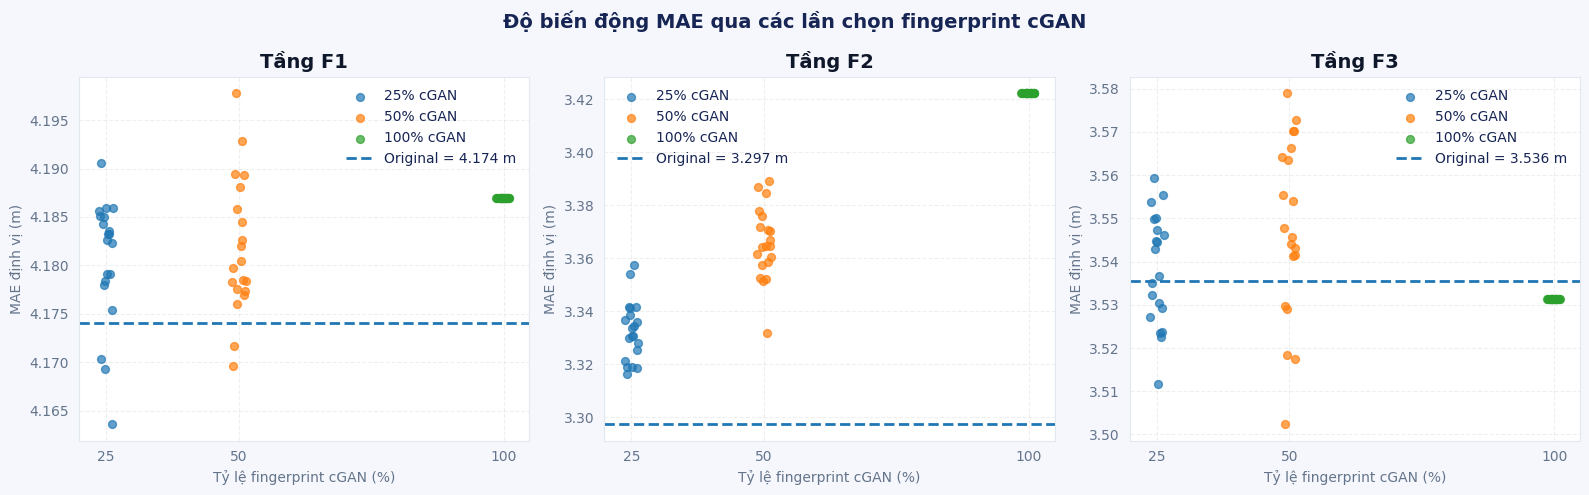


CELL 4.3.12 COMPLETED — ROBUSTNESS ANALYSIS
F1: mức có MAE trung bình thấp nhất=25%; MAE trung bình=4.1805 m; std=0.00660 m; thay đổi so với Original=+0.16%.
F2: mức có MAE trung bình thấp nhất=25%; MAE trung bình=3.3328 m; std=0.01132 m; thay đổi so với Original=+1.07%.
F3: mức có MAE trung bình thấp nhất=100%; MAE trung bình=3.5314 m; std=0.00000 m; thay đổi so với Original=-0.12%.

Lưu ý: các lần lặp chỉ thay đổi tập con fingerprint cGAN, không phải các lần huấn luyện độc lập. Mức 100% không có biến động do chọn mẫu vì luôn dùng cùng toàn bộ dữ liệu tổng hợp. Đây là phân tích độ nhạy, không phải kiểm định ý nghĩa thống kê.


In [ ]:

# ============================================================
# CELL 4.3.12 — ROBUSTNESS TO SYNTHETIC SUBSET SELECTION
# Multiple random subsets, fixed KNN/test/scaler
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from IPython.display import display, HTML

FLOORS = ["F1", "F2", "F3"]
AP_COLS = [f"AP{i}" for i in range(1, 18)]
XY_COLS = ["X", "Y"]

RATIOS = [0.25, 0.50, 1.00]
N_REPEATS = 20
BASE_SEED = 4312
K_NEIGHBORS = 5

# ------------------------------------------------------------
# 1. Kiểm tra đầu vào
# ------------------------------------------------------------
required_objects = ["localization_datasets", "synthetic_df"]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        f"Thiếu biến: {missing_objects}. "
        "Hãy kiểm tra các cell chuẩn bị dữ liệu."
    )

required_cols = ["Floor"] + XY_COLS + AP_COLS
missing_cols = set(required_cols) - set(synthetic_df.columns)

if missing_cols:
    raise ValueError(
        f"synthetic_df thiếu cột: {sorted(missing_cols)}"
    )

# ------------------------------------------------------------
# 2. Hàm metric
# ------------------------------------------------------------
def robustness_metrics(y_true, y_pred):
    error = np.linalg.norm(y_true - y_pred, axis=1)

    return {
        "MAE (m)": float(error.mean()),
        "RMSE (m)": float(np.sqrt(np.mean(error ** 2))),
        "Median Error (m)": float(np.median(error))
    }

# ------------------------------------------------------------
# 3. Lặp lại lựa chọn fingerprint tổng hợp
# ------------------------------------------------------------
repeat_rows = []
baseline_rows = []

for floor_idx, floor in enumerate(FLOORS):

    train_df = localization_datasets[floor][
        "train_original"
    ].copy().reset_index(drop=True)

    test_df = localization_datasets[floor][
        "test"
    ].copy().reset_index(drop=True)

    syn_df = synthetic_df[
        synthetic_df["Floor"].astype(str) == floor
    ].copy().reset_index(drop=True)

    if train_df.empty or test_df.empty or syn_df.empty:
        raise ValueError(
            f"{floor}: train, test hoặc synthetic đang rỗng."
        )

    X_train = train_df[AP_COLS].to_numpy(dtype=float)
    y_train = train_df[XY_COLS].to_numpy(dtype=float)

    X_test = test_df[AP_COLS].to_numpy(dtype=float)
    y_test = test_df[XY_COLS].to_numpy(dtype=float)

    X_syn = syn_df[AP_COLS].to_numpy(dtype=float)
    y_syn = syn_df[XY_COLS].to_numpy(dtype=float)

    # Fit scaler duy nhất trên train gốc
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    X_syn_scaled = scaler.transform(X_syn)

    # Baseline cố định
    baseline_model = KNeighborsRegressor(
        n_neighbors=K_NEIGHBORS,
        weights="distance"
    )
    baseline_model.fit(X_train_scaled, y_train)

    baseline_pred = baseline_model.predict(X_test_scaled)
    baseline_metric = robustness_metrics(y_test, baseline_pred)

    baseline_rows.append({
        "Tầng": floor,
        **baseline_metric
    })

    # Thử các tỷ lệ cGAN
    for ratio in RATIOS:
        n_select = max(1, int(round(len(syn_df) * ratio)))

        for repeat in range(N_REPEATS):
            seed = BASE_SEED + floor_idx * 1000 + repeat

            if ratio >= 1.0:
                selected_idx = np.arange(len(syn_df))
            else:
                rng = np.random.default_rng(seed)
                selected_idx = np.sort(
                    rng.choice(
                        len(syn_df),
                        size=n_select,
                        replace=False
                    )
                )

            X_syn_subset = X_syn_scaled[selected_idx]
            y_syn_subset = y_syn[selected_idx]

            X_aug = np.vstack([
                X_train_scaled,
                X_syn_subset
            ])

            y_aug = np.vstack([
                y_train,
                y_syn_subset
            ])

            model = KNeighborsRegressor(
                n_neighbors=K_NEIGHBORS,
                weights="distance"
            )
            model.fit(X_aug, y_aug)

            y_pred = model.predict(X_test_scaled)
            metrics = robustness_metrics(y_test, y_pred)

            repeat_rows.append({
                "Tầng": floor,
                "Tỷ lệ cGAN (%)": int(ratio * 100),
                "Lần lặp": repeat + 1,
                "Seed": seed,
                "Số synthetic": len(selected_idx),
                **metrics
            })

repeat_results_df = pd.DataFrame(repeat_rows)
baseline_robustness_df = pd.DataFrame(baseline_rows)

print(
    f"PASS — Hoàn tất {len(repeat_results_df)} lượt đánh giá "
    f"cGAN ({N_REPEATS} lần lặp mỗi tỷ lệ và mỗi tầng)."
)
print(
    "Lưu ý: mức 100% dùng cùng toàn bộ fingerprint ở mỗi lần lặp, "
    "nên kết quả ở mức này giống nhau giữa các lần."
)

# ------------------------------------------------------------
# 4. Tóm tắt MAE theo tỷ lệ
# ------------------------------------------------------------
ratio_summary_df = (
    repeat_results_df
    .groupby(["Tầng", "Tỷ lệ cGAN (%)"], as_index=False)
    .agg(
        **{
            "Số lần chạy": ("MAE (m)", "count"),
            "MAE trung bình (m)": ("MAE (m)", "mean"),
            "Độ lệch chuẩn MAE (m)": ("MAE (m)", "std"),
            "MAE nhỏ nhất (m)": ("MAE (m)", "min"),
            "MAE lớn nhất (m)": ("MAE (m)", "max"),
            "RMSE trung bình (m)": ("RMSE (m)", "mean"),
            "Median Error trung bình (m)": ("Median Error (m)", "mean")
        }
    )
)

display(HTML("""
<div style="
    background:linear-gradient(120deg,#172554,#4338ca,#7c3aed);
    color:white;padding:20px 24px;border-radius:16px;margin:8px 0 16px 0;">
    <div style="font-size:12px;letter-spacing:1px;opacity:.85;">
        PHẦN 4 · ĐỘ ỔN ĐỊNH KẾT QUẢ
    </div>
    <div style="font-size:23px;font-weight:700;margin-top:5px;">
        KNN Robustness Analysis
    </div>
    <div style="font-size:13px;opacity:.9;margin-top:5px;">
        Repeated subset selection · Fixed test set
    </div>
</div>
"""))

display(HTML("<h3 style='color:#4338ca'>Tóm tắt theo tầng và tỷ lệ</h3>"))

display(
    ratio_summary_df.style.format({
        "Tỷ lệ cGAN (%)": "{:.0f}",
        "MAE trung bình (m)": "{:.4f}",
        "Độ lệch chuẩn MAE (m)": "{:.5f}",
        "MAE nhỏ nhất (m)": "{:.4f}",
        "MAE lớn nhất (m)": "{:.4f}",
        "RMSE trung bình (m)": "{:.4f}",
        "Median Error trung bình (m)": "{:.4f}"
    })
)

display(HTML("<h3 style='color:#4338ca'>Baseline Original</h3>"))

display(
    baseline_robustness_df.style.format({
        "MAE (m)": "{:.4f}",
        "RMSE (m)": "{:.4f}",
        "Median Error (m)": "{:.4f}"
    })
)

# ------------------------------------------------------------
# 5. So sánh MAE trung bình với baseline
# ------------------------------------------------------------
delta_rows = []

for floor in FLOORS:
    baseline_mae = float(
        baseline_robustness_df.loc[
            baseline_robustness_df["Tầng"] == floor,
            "MAE (m)"
        ].iloc[0]
    )

    part = ratio_summary_df[
        ratio_summary_df["Tầng"] == floor
    ]

    for _, row in part.iterrows():
        delta = row["MAE trung bình (m)"] - baseline_mae

        delta_rows.append({
            "Tầng": floor,
            "Tỷ lệ cGAN (%)": int(row["Tỷ lệ cGAN (%)"]),
            "Original MAE (m)": baseline_mae,
            "MAE trung bình (m)": row["MAE trung bình (m)"],
            "Δ MAE trung bình (m)": delta,
            "Thay đổi MAE trung bình (%)": delta / baseline_mae * 100,
            "Độ lệch chuẩn MAE (m)": row["Độ lệch chuẩn MAE (m)"]
        })

robustness_delta_df = pd.DataFrame(delta_rows)

display(HTML(
    "<h3 style='color:#4338ca'>Thay đổi MAE so với baseline</h3>"
))

display(
    robustness_delta_df.style.format({
        "Tỷ lệ cGAN (%)": "{:.0f}",
        "Original MAE (m)": "{:.4f}",
        "MAE trung bình (m)": "{:.4f}",
        "Δ MAE trung bình (m)": "{:+.4f}",
        "Thay đổi MAE trung bình (%)": "{:+.2f}%",
        "Độ lệch chuẩn MAE (m)": "{:.5f}"
    }).background_gradient(
        subset=["Thay đổi MAE trung bình (%)"],
        cmap="RdYlGn_r"
    )
)

# ------------------------------------------------------------
# 6. Biểu đồ MAE qua các lần lấy mẫu
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, floor in zip(axes, FLOORS):
    part = repeat_results_df[
        repeat_results_df["Tầng"] == floor
    ]

    baseline_mae = float(
        baseline_robustness_df.loc[
            baseline_robustness_df["Tầng"] == floor,
            "MAE (m)"
        ].iloc[0]
    )

    for ratio in [25, 50, 100]:
        values = part.loc[
            part["Tỷ lệ cGAN (%)"] == ratio,
            "MAE (m)"
        ].to_numpy()

        positions = np.full(len(values), ratio, dtype=float)
        jitter_rng = np.random.default_rng(
            BASE_SEED + floor_idx + ratio
        )
        positions += jitter_rng.uniform(-1.5, 1.5, size=len(values))

        ax.scatter(
            positions,
            values,
            alpha=0.7,
            s=32,
            label=f"{ratio}% cGAN"
        )

    ax.axhline(
        baseline_mae,
        linestyle="--",
        linewidth=2,
        label=f"Original = {baseline_mae:.3f} m"
    )

    ax.set_title(f"Tầng {floor}", fontweight="bold")
    ax.set_xlabel("Tỷ lệ fingerprint cGAN (%)")
    ax.set_ylabel("MAE định vị (m)")
    ax.set_xticks([25, 50, 100])
    ax.grid(linestyle="--", alpha=0.3)
    ax.legend(frameon=False)

fig.suptitle(
    "Độ biến động MAE qua các lần chọn fingerprint cGAN",
    fontsize=14,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Kết luận mô tả
# ------------------------------------------------------------
print("\n" + "=" * 68)
print("CELL 4.3.12 COMPLETED — ROBUSTNESS ANALYSIS")
print("=" * 68)

for floor in FLOORS:
    base = float(
        baseline_robustness_df.loc[
            baseline_robustness_df["Tầng"] == floor,
            "MAE (m)"
        ].iloc[0]
    )

    part = ratio_summary_df[
        ratio_summary_df["Tầng"] == floor
    ]

    best_idx = part["MAE trung bình (m)"].idxmin()
    best = part.loc[best_idx]

    change_pct = (
        best["MAE trung bình (m)"] - base
    ) / base * 100

    print(
        f'{floor}: mức có MAE trung bình thấp nhất={int(best["Tỷ lệ cGAN (%)"])}%; '
        f'MAE trung bình={best["MAE trung bình (m)"]:.4f} m; '
        f'std={best["Độ lệch chuẩn MAE (m)"]:.5f} m; '
        f'thay đổi so với Original={change_pct:+.2f}%.'
    )

print(
    "\nLưu ý: các lần lặp chỉ thay đổi tập con fingerprint cGAN, "
    "không phải các lần huấn luyện độc lập. Mức 100% không có biến "
    "động do chọn mẫu vì luôn dùng cùng toàn bộ dữ liệu tổng hợp. "
    "Đây là phân tích độ nhạy, không phải kiểm định ý nghĩa thống kê."
)


### 4.3.13A. Kiểm tra dữ liệu validation phục vụ lựa chọn cấu hình

Mục tiêu là xác định các biến chứa dữ liệu train, validation và test của từng tầng; kiểm tra cấu trúc tọa độ, fingerprint RSSI và mức độ giao nhau giữa các tập theo ID_RP hoặc tọa độ.

Bước kiểm tra này không huấn luyện lại cGAN, không thay đổi dữ liệu và không lựa chọn cấu hình dựa trên tập test.

In [ ]:

# ============================================================
# CELL 4.3.13A — AUDIT VALIDATION SPLIT
# Read-only inspection: không sửa dữ liệu, không train model
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display, HTML

print("=" * 72)
print("CELL 4.3.13A — KIỂM TRA CẤU TRÚC VALIDATION")
print("=" * 72)

# 1. Tìm các biến có thể chứa dữ liệu validation
keywords = ("val", "valid", "validation", "split", "loader", "prepared")

found = []
for name, obj in list(globals().items()):
    if any(k in name.lower() for k in keywords):
        if isinstance(obj, (dict, pd.DataFrame, pd.Series, list, tuple)):
            found.append({
                "Tên biến": name,
                "Kiểu dữ liệu": type(obj).__name__,
                "Các tầng / số phần tử": (
                    ", ".join(map(str, obj.keys()))
                    if isinstance(obj, dict)
                    else (
                        f"{len(obj)} dòng"
                        if isinstance(obj, (pd.DataFrame, pd.Series, list, tuple))
                        else "-"
                    )
                )
            })

display(pd.DataFrame(found))

# 2. Kiểm tra cấu trúc các biến split hiện có
for var_name in ["splits", "prepared", "localization_datasets"]:
    if var_name not in globals():
        print(f"\n{var_name}: CHƯA TỒN TẠI")
        continue

    obj = globals()[var_name]
    print(f"\n--- {var_name} ---")

    if isinstance(obj, dict):
        for key, value in obj.items():
            if isinstance(value, dict):
                print(f"{key}:")
                for subkey, subvalue in value.items():
                    if isinstance(subvalue, pd.DataFrame):
                        print(
                            f"  {subkey}: DataFrame "
                            f"shape={subvalue.shape}, "
                            f"columns={list(subvalue.columns)}"
                        )
                    elif isinstance(subvalue, (np.ndarray, list, tuple)):
                        print(
                            f"  {subkey}: {type(subvalue).__name__}, "
                            f"shape/length={getattr(subvalue, 'shape', len(subvalue))}"
                        )
                    else:
                        print(
                            f"  {subkey}: {type(subvalue).__name__}"
                        )
            elif isinstance(value, pd.DataFrame):
                print(
                    f"{key}: DataFrame shape={value.shape}, "
                    f"columns={list(value.columns)}"
                )
            else:
                print(f"{key}: {type(value).__name__}")

# 3. Kiểm tra các biến loader đã biết
for var_name in ["train_loaders", "val_loaders"]:
    if var_name not in globals():
        print(f"\n{var_name}: CHƯA TỒN TẠI")
        continue

    obj = globals()[var_name]
    print(f"\n{var_name}:")
    if isinstance(obj, dict):
        for floor, loader in obj.items():
            try:
                print(
                    f"  {floor}: batches={len(loader)}, "
                    f"dataset_size={len(loader.dataset)}"
                )
            except Exception as exc:
                print(f"  {floor}: không đọc được kích thước ({exc})")
    else:
        print(f"  Kiểu: {type(obj).__name__}")

print("\n" + "=" * 72)
print("AUDIT HOÀN TẤT — CHƯA THAY ĐỔI DỮ LIỆU")
print("=" * 72)


CELL 4.3.13A — KIỂM TRA CẤU TRÚC VALIDATION


,Tên biến,Kiểu dữ liệu,Các tầng / số phần tử
0,valid1,DataFrame,3000 dòng
1,valid2,DataFrame,3000 dòng
2,splits,dict,"F1, F2, F3"
3,prepared,dict,"F1, F2, F3"
4,train_loaders,dict,"F1, F2, F3"
5,val_loaders,dict,"F1, F2, F3"
6,val_ids_by_floor,dict,"F1, F2, F3"
7,val_df,DataFrame,360 dòng
8,best_val_scores,dict,"F1, F2, F3"
9,real_rssi_values,list,6 dòng



--- splits ---
F1:
  train_ids: set
  test_ids: set
  train_df: DataFrame shape=(5020, 23), columns=['ID_RP', 'X', 'Y', 'AP1', 'AP2', 'AP3', 'AP4', 'AP5', 'AP6', 'AP7', 'AP8', 'AP9', 'AP10', 'AP11', 'AP12', 'AP13', 'AP14', 'AP15', 'AP16', 'AP17', 'Smartphones', 'Users', 'Direction']
  test_df: DataFrame shape=(1260, 23), columns=['ID_RP', 'X', 'Y', 'AP1', 'AP2', 'AP3', 'AP4', 'AP5', 'AP6', 'AP7', 'AP8', 'AP9', 'AP10', 'AP11', 'AP12', 'AP13', 'AP14', 'AP15', 'AP16', 'AP17', 'Smartphones', 'Users', 'Direction']
F2:
  train_ids: set
  test_ids: set
  train_df: DataFrame shape=(2960, 23), columns=['ID_RP', 'X', 'Y', 'AP1', 'AP2', 'AP3', 'AP4', 'AP5', 'AP6', 'AP7', 'AP8', 'AP9', 'AP10', 'AP11', 'AP12', 'AP13', 'AP14', 'AP15', 'AP16', 'AP17', 'Smartphones', 'Users', 'Direction']
  test_df: DataFrame shape=(760, 23), columns=['ID_RP', 'X', 'Y', 'AP1', 'AP2', 'AP3', 'AP4', 'AP5', 'AP6', 'AP7', 'AP8', 'AP9', 'AP10', 'AP11', 'AP12', 'AP13', 'AP14', 'AP15', 'AP16', 'AP17', 'Smartphones', 'Users'

### 4.3.13B. Trích xuất dữ liệu validation cho đánh giá định vị

Trích xuất tọa độ và fingerprint RSSI từ các tập validation đã được tạo trong quá trình chia dữ liệu. Kiểm tra kích thước, giá trị thiếu và tính nhất quán của dữ liệu.

Bước này chỉ đọc dữ liệu hiện có, không huấn luyện lại cGAN, không thay đổi tập train/test và không lựa chọn cấu hình dựa trên kết quả test.

In [ ]:

# ============================================================
# CELL 4.3.13B — VALIDATION DATA INSPECTION
# Chỉ đọc dữ liệu hiện có, không sửa model hoặc split
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

FLOORS = ["F1", "F2", "F3"]
AP_COLS = [f"AP{i}" for i in range(1, 18)]
XY_COLS = ["X", "Y"]

assert "val_loaders" in globals(), "Không tìm thấy val_loaders."
assert "val_ids_by_floor" in globals(), "Không tìm thấy val_ids_by_floor."

validation_audit_rows = []

for floor in FLOORS:
    loader = val_loaders[floor]
    expected_ids = val_ids_by_floor[floor]

    print(f"\n{'=' * 60}")
    print(f"VALIDATION — {floor}")
    print(f"{'=' * 60}")

    print("Số batch:", len(loader))
    print("Số mẫu:", len(loader.dataset))
    print("Số RP validation trong val_ids_by_floor:", len(expected_ids))
    print("Kiểu dataset:", type(loader.dataset).__name__)

    # Kiểm tra một batch để xác nhận cấu trúc
    batch = next(iter(loader))

    print("Kiểu batch:", type(batch).__name__)

    if isinstance(batch, (tuple, list)):
        for i, item in enumerate(batch):
            print(
                f"  Thành phần {i}: "
                f"shape={tuple(item.shape) if hasattr(item, 'shape') else 'N/A'}, "
                f"type={type(item).__name__}"
            )
    elif isinstance(batch, dict):
        for key, item in batch.items():
            print(
                f"  {key}: "
                f"shape={tuple(item.shape) if hasattr(item, 'shape') else 'N/A'}"
            )

    # Kiểm tra xem có DataFrame validation sẵn theo tầng không
    candidate_names = [
        f"val_df_{floor}",
        f"validation_df_{floor}",
        f"valid_df_{floor}",
    ]

    found_df = None
    found_name = None

    for name in candidate_names:
        if name in globals() and isinstance(globals()[name], pd.DataFrame):
            found_df = globals()[name]
            found_name = name
            break

    if found_df is not None:
        print(f"\nĐã tìm thấy DataFrame: {found_name}")
        print("Shape:", found_df.shape)
        print("Columns:", list(found_df.columns))
        display(found_df.head(3))
    else:
        print(
            "\nChưa tìm thấy DataFrame validation theo tầng "
            "trong các tên biến phổ biến."
        )

    validation_audit_rows.append({
        "Tầng": floor,
        "Validation samples": len(loader.dataset),
        "Validation RP IDs": len(expected_ids),
        "Batch count": len(loader),
        "Batch structure": type(batch).__name__
    })

print("\n" + "=" * 60)
print("TỔNG HỢP VALIDATION AUDIT")
print("=" * 60)
display(pd.DataFrame(validation_audit_rows))



VALIDATION — F1
Số batch: 12
Số mẫu: 760
Số RP validation trong val_ids_by_floor: 38
Kiểu dataset: TensorDataset
Kiểu batch: list
  Thành phần 0: shape=(64, 2), type=Tensor
  Thành phần 1: shape=(64, 17), type=Tensor
  Thành phần 2: shape=(64, 17), type=Tensor

Chưa tìm thấy DataFrame validation theo tầng trong các tên biến phổ biến.

VALIDATION — F2
Số batch: 8
Số mẫu: 460
Số RP validation trong val_ids_by_floor: 23
Kiểu dataset: TensorDataset
Kiểu batch: list
  Thành phần 0: shape=(64, 2), type=Tensor
  Thành phần 1: shape=(64, 17), type=Tensor
  Thành phần 2: shape=(64, 17), type=Tensor

Chưa tìm thấy DataFrame validation theo tầng trong các tên biến phổ biến.

VALIDATION — F3
Số batch: 6
Số mẫu: 360
Số RP validation trong val_ids_by_floor: 18
Kiểu dataset: TensorDataset
Kiểu batch: list
  Thành phần 0: shape=(64, 2), type=Tensor
  Thành phần 1: shape=(64, 17), type=Tensor
  Thành phần 2: shape=(64, 17), type=Tensor

Chưa tìm thấy DataFrame validation theo tầng trong các tên biến p

,Tầng,Validation samples,Validation RP IDs,Batch count,Batch structure
0,F1,760,38,12,list
1,F2,460,23,8,list
2,F3,360,18,6,list


### 4.3.13C. Khôi phục dữ liệu validation theo RP

Tái tạo DataFrame validation từ dữ liệu gốc đã chia theo RP, sử dụng danh sách ID_RP validation hiện có. Kiểm tra số lượng mẫu, số RP và mức độ giao nhau giữa validation với train/test.

Bước này không huấn luyện lại cGAN và không thay đổi các tập dữ liệu hiện tại. Nếu không thể xác định chính xác ID_RP hoặc dữ liệu nguồn, cần dừng để kiểm tra thay vì tự tạo split mới.

In [ ]:

# ============================================================
# CELL 4.3.13C-DEBUG — TRACE RP SPLITS
# Read-only: không thay đổi dữ liệu hoặc mô hình
# ============================================================

import pandas as pd

for floor in ["F1", "F2", "F3"]:
    print(f"\n{'=' * 60}\n{floor}\n{'=' * 60}")

    val_ids = set(val_ids_by_floor[floor])
    split_train_ids = set(splits[floor]["train_ids"])
    split_test_ids = set(splits[floor]["test_ids"])

    # ID trong DataFrame train/test hiện có
    train_df_ids = set(
        splits[floor]["train_df"]["ID_RP"].dropna().unique()
    )
    test_df_ids = set(
        splits[floor]["test_df"]["ID_RP"].dropna().unique()
    )

    # ID trong tập train/validation nội bộ đã dùng cho cGAN
    if floor in globals().get("normalized_coords", {}):
        print("Có normalized_coords cho tầng:", floor)

    print("Validation IDs:", len(val_ids))
    print("splits train_ids:", len(split_train_ids))
    print("splits test_ids:", len(split_test_ids))
    print("Train DataFrame RP:", len(train_df_ids))
    print("Test DataFrame RP:", len(test_df_ids))

    print("Validation ∩ splits train_ids:",
          len(val_ids & split_train_ids))
    print("Validation ∩ splits test_ids:",
          len(val_ids & split_test_ids))
    print("Validation ∩ train DataFrame IDs:",
          len(val_ids & train_df_ids))
    print("Validation ∩ test DataFrame IDs:",
          len(val_ids & test_df_ids))

    # Kiểm tra xem train_ids có phải là tập cha chứa validation không
    print("Validation là tập con của splits train_ids:",
          val_ids.issubset(split_train_ids))

    # In một vài ID để đối chiếu
    print("Ví dụ validation IDs:", list(sorted(val_ids, key=str))[:8])
    print("Ví dụ train IDs:", list(sorted(split_train_ids, key=str))[:8])
    print("Ví dụ test IDs:", list(sorted(split_test_ids, key=str))[:8])

print("\nDEBUG HOÀN TẤT — không có dữ liệu nào bị thay đổi.")



F1
Có normalized_coords cho tầng: F1
Validation IDs: 38
splits train_ids: 251
splits test_ids: 63
Train DataFrame RP: 251
Test DataFrame RP: 63
Validation ∩ splits train_ids: 38
Validation ∩ splits test_ids: 0
Validation ∩ train DataFrame IDs: 38
Validation ∩ test DataFrame IDs: 0
Validation là tập con của splits train_ids: True
Ví dụ validation IDs: [np.int64(11), np.int64(14), np.int64(143), np.int64(146), np.int64(15), np.int64(151), np.int64(154), np.int64(162)]
Ví dụ train IDs: [np.int64(1), np.int64(100), np.int64(101), np.int64(102), np.int64(103), np.int64(104), np.int64(105), np.int64(106)]
Ví dụ test IDs: [np.int64(10), np.int64(112), np.int64(115), np.int64(117), np.int64(120), np.int64(127), np.int64(133), np.int64(140)]

F2
Có normalized_coords cho tầng: F2
Validation IDs: 23
splits train_ids: 148
splits test_ids: 38
Train DataFrame RP: 148
Test DataFrame RP: 38
Validation ∩ splits train_ids: 23
Validation ∩ splits test_ids: 0
Validation ∩ train DataFrame IDs: 23
Validati

### 4.3.13D. Tách dữ liệu train nội bộ và validation cho KNN

Sử dụng các ID_RP validation đã được xác định trước để chia tập train tổng thành hai phần không giao nhau: train nội bộ và validation.

Tập test ban đầu được giữ nguyên và không được sử dụng để chọn tỷ lệ dữ liệu cGAN hoặc ngưỡng detection mask. Các tập dữ liệu mới chỉ phục vụ thí nghiệm lựa chọn cấu hình.

In [ ]:

# ============================================================
# CELL 4.3.13D — BUILD DISJOINT TRAIN/VALIDATION DATA
# Không sửa splits gốc; tạo biến mới
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

FLOORS = ["F1", "F2", "F3"]
AP_COLS = [f"AP{i}" for i in range(1, 18)]
REQUIRED = ["ID_RP", "X", "Y"] + AP_COLS

knn_selection_data = {}
audit_rows = []

for floor in FLOORS:
    full_train = splits[floor]["train_df"].copy()
    test_df = splits[floor]["test_df"].copy()

    val_ids = set(val_ids_by_floor[floor])
    test_ids = set(test_df["ID_RP"].dropna().unique())

    # Validation: chỉ các RP đã được xác định trước
    val_df = full_train[
        full_train["ID_RP"].isin(val_ids)
    ].copy()

    # Train nội bộ: loại toàn bộ RP validation
    inner_train_df = full_train[
        ~full_train["ID_RP"].isin(val_ids)
    ].copy()

    inner_train_ids = set(inner_train_df["ID_RP"].dropna().unique())
    actual_val_ids = set(val_df["ID_RP"].dropna().unique())

    # Kiểm tra tính độc lập theo RP
    overlap_train_val = inner_train_ids & actual_val_ids
    overlap_val_test = actual_val_ids & test_ids
    overlap_train_test = inner_train_ids & test_ids

    if overlap_train_val or overlap_val_test or overlap_train_test:
        raise ValueError(
            f"{floor}: phát hiện giao nhau giữa các tập RP."
        )

    if actual_val_ids != val_ids:
        raise ValueError(
            f"{floor}: ID validation không khớp danh sách đã lưu."
        )

    if val_df.empty or inner_train_df.empty:
        raise ValueError(f"{floor}: train hoặc validation bị rỗng.")

    # Lưu vào cấu trúc mới, không ghi đè biến cũ
    knn_selection_data[floor] = {
        "train": inner_train_df.reset_index(drop=True),
        "validation": val_df.reset_index(drop=True),
        "test": test_df.reset_index(drop=True)
    }

    audit_rows.append({
        "Tầng": floor,
        "Train samples": len(inner_train_df),
        "Train RP": inner_train_df["ID_RP"].nunique(),
        "Validation samples": len(val_df),
        "Validation RP": val_df["ID_RP"].nunique(),
        "Test samples": len(test_df),
        "Test RP": test_df["ID_RP"].nunique(),
        "Overlap train-validation": len(overlap_train_val),
        "Overlap validation-test": len(overlap_val_test),
        "Overlap train-test": len(overlap_train_test)
    })

knn_selection_audit_df = pd.DataFrame(audit_rows)

display(knn_selection_audit_df)

assert (knn_selection_audit_df["Overlap train-validation"] == 0).all()
assert (knn_selection_audit_df["Overlap validation-test"] == 0).all()
assert (knn_selection_audit_df["Overlap train-test"] == 0).all()

print("\nPASS — Train, validation và test không giao nhau theo ID_RP.")
print("Các biến splits và localization_datasets gốc vẫn được giữ nguyên.")


,Tầng,Train samples,Train RP,Validation samples,Validation RP,Test samples,Test RP,Overlap train-validation,Overlap validation-test,Overlap train-test
0,F1,4260,213,760,38,1260,63,0,0,0
1,F2,2500,125,460,23,760,38,0,0,0
2,F3,2040,102,360,18,600,30,0,0,0



PASS — Train, validation và test không giao nhau theo ID_RP.
Các biến splits và localization_datasets gốc vẫn được giữ nguyên.


In [ ]:
### Cell 4.3.14 — Chọn tỷ lệ tăng cường trên Validation

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

AP_COLS = [f"AP{i}" for i in range(1, 18)]
RATIOS = [0, 0.25, 0.50, 1.00]
SEED = 42

results = []

for floor in ["F1", "F2", "F3"]:
    data = knn_selection_data[floor]
    train_df = data["train"].copy()
    val_df = data["validation"].copy()

    # Dữ liệu cGAN tại các vị trí ứng viên chưa khảo sát
    syn_df = synthetic_df[synthetic_df["Floor"] == floor].copy()

    # Chỉ giữ tọa độ và 17 giá trị RSSI
    train_df = train_df[["X", "Y"] + AP_COLS].dropna()
    val_df = val_df[["X", "Y"] + AP_COLS].dropna()
    syn_df = syn_df[["X", "Y"] + AP_COLS].dropna()

    # Chuẩn hóa chỉ bằng inner-train, tránh rò rỉ validation
    scaler = StandardScaler()
    X_train_original = scaler.fit_transform(train_df[AP_COLS])
    X_val = scaler.transform(val_df[AP_COLS])

    y_train_original = train_df[["X", "Y"]].to_numpy()
    y_val = val_df[["X", "Y"]].to_numpy()

    # Cố định thứ tự và cách chọn mẫu để có thể tái lập
    rng = np.random.default_rng(SEED)
    order = rng.permutation(len(syn_df))

    for ratio in RATIOS:
        n_syn = int(round(len(syn_df) * ratio))
        selected_syn = syn_df.iloc[order[:n_syn]]

        if n_syn:
            X_syn = scaler.transform(selected_syn[AP_COLS])
            y_syn = selected_syn[["X", "Y"]].to_numpy()
            X_train = np.vstack([X_train_original, X_syn])
            y_train = np.vstack([y_train_original, y_syn])
        else:
            X_train = X_train_original
            y_train = y_train_original

        knn = KNeighborsRegressor(n_neighbors=5, weights="distance")
        knn.fit(X_train, y_train)
        pred = knn.predict(X_val)

        mae = mean_absolute_error(y_val, pred)
        rmse = np.sqrt(mean_squared_error(y_val, pred))

        results.append({
            "Floor": floor,
            "Ratio_cGAN": f"{int(ratio * 100)}%",
            "Train_samples": len(X_train),
            "Validation_samples": len(y_val),
            "MAE_m": mae,
            "RMSE_m": rmse
        })

validation_results_df = pd.DataFrame(results)

display(
    validation_results_df
    .sort_values(["Floor", "MAE_m"])
    .round(4)
    .reset_index(drop=True)
)

best_configs = (
    validation_results_df
    .loc[validation_results_df.groupby("Floor")["MAE_m"].idxmin()]
    .sort_values("Floor")
    .reset_index(drop=True)
)

print("CẤU HÌNH TỐT NHẤT THEO VALIDATION")
display(best_configs.round(4))


,Floor,Ratio_cGAN,Train_samples,Validation_samples,MAE_m,RMSE_m
0,F1,0%,4260,760,2.6660,4.0593
1,F1,25%,4279,760,2.6733,4.0621
2,F1,50%,4298,760,2.6788,4.0687
3,F1,100%,4336,760,2.6834,4.0660
4,F2,0%,2500,460,2.1576,3.4220
5,F2,25%,2544,460,2.1795,3.4552
6,F2,50%,2587,460,2.1991,3.4885
7,F2,100%,2674,460,2.2111,3.5054
8,F3,0%,2040,360,2.2005,3.1668
9,F3,50%,2055,360,2.2229,3.2015


CẤU HÌNH TỐT NHẤT THEO VALIDATION


,Floor,Ratio_cGAN,Train_samples,Validation_samples,MAE_m,RMSE_m
0,F1,0%,4260,760,2.6660,4.0593
1,F2,0%,2500,460,2.1576,3.4220
2,F3,0%,2040,360,2.2005,3.1668


Cell 4.3.15 — Đánh giá cuối trên tập Test độc lập
Cell này so sánh KNN dùng dữ liệu gốc với KNN dùng dữ liệu gốc kết hợp cGAN theo các tỷ lệ đã thử. Lưu ý: kết quả Test chỉ dùng để báo cáo đánh giá cuối, không dùng chọn cấu hình.

In [ ]:

# CELL 4.3.15 — FINAL TEST EVALUATION
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

AP_COLS = [f"AP{i}" for i in range(1, 18)]
RATIOS = [0, 0.25, 0.50, 1.00]
SEED = 42

test_results = []

for floor in ["F1", "F2", "F3"]:
    # Dùng toàn bộ train gốc và test độc lập
    train_df = splits[floor]["train_df"].copy()
    test_df = splits[floor]["test_df"].copy()
    syn_df = synthetic_df[synthetic_df["Floor"] == floor].copy()

    train_df = train_df[["X", "Y"] + AP_COLS].dropna()
    test_df = test_df[["X", "Y"] + AP_COLS].dropna()
    syn_df = syn_df[["X", "Y"] + AP_COLS].dropna()

    # Fit scaler chỉ trên train gốc
    scaler = StandardScaler()
    X_train_original = scaler.fit_transform(train_df[AP_COLS])
    X_test = scaler.transform(test_df[AP_COLS])

    y_train_original = train_df[["X", "Y"]].to_numpy()
    y_test = test_df[["X", "Y"]].to_numpy()

    # Chọn tập con cGAN tái lập được
    rng = np.random.default_rng(SEED)
    order = rng.permutation(len(syn_df))

    for ratio in RATIOS:
        n_syn = int(round(len(syn_df) * ratio))
        selected_syn = syn_df.iloc[order[:n_syn]]

        if n_syn > 0:
            X_syn = scaler.transform(selected_syn[AP_COLS])
            y_syn = selected_syn[["X", "Y"]].to_numpy()
            X_train = np.vstack([X_train_original, X_syn])
            y_train = np.vstack([y_train_original, y_syn])
        else:
            X_train = X_train_original
            y_train = y_train_original

        knn = KNeighborsRegressor(n_neighbors=5, weights="distance")
        knn.fit(X_train, y_train)
        pred = knn.predict(X_test)

        mae = mean_absolute_error(y_test, pred)
        rmse = np.sqrt(mean_squared_error(y_test, pred))
        errors = np.linalg.norm(y_test - pred, axis=1)
        median_error = np.median(errors)

        test_results.append({
            "Floor": floor,
            "Ratio_cGAN": f"{int(ratio * 100)}%",
            "Train_samples": len(X_train),
            "Test_samples": len(y_test),
            "MAE_m": mae,
            "RMSE_m": rmse,
            "Median_error_m": median_error
        })

test_results_df = pd.DataFrame(test_results)

print("KẾT QUẢ ĐÁNH GIÁ CUỐI TRÊN TEST")
display(
    test_results_df
    .sort_values(["Floor", "Ratio_cGAN"])
    .round(4)
    .reset_index(drop=True)
)

# So sánh MAE với baseline 0% trong cùng tầng
baseline = (
    test_results_df[test_results_df["Ratio_cGAN"] == "0%"]
    [["Floor", "MAE_m"]]
    .rename(columns={"MAE_m": "Baseline_MAE_m"})
)

comparison = test_results_df.merge(baseline, on="Floor")
comparison["Delta_MAE_m"] = comparison["MAE_m"] - comparison["Baseline_MAE_m"]
comparison["Delta_MAE_pct"] = (
    comparison["Delta_MAE_m"] / comparison["Baseline_MAE_m"] * 100
)

print("SO SÁNH VỚI BASELINE — ΔMAE âm là tốt hơn")
display(
    comparison[
        ["Floor", "Ratio_cGAN", "Baseline_MAE_m",
         "MAE_m", "Delta_MAE_m", "Delta_MAE_pct"]
    ].round(4).reset_index(drop=True)
)


KẾT QUẢ ĐÁNH GIÁ CUỐI TRÊN TEST


,Floor,Ratio_cGAN,Train_samples,Test_samples,MAE_m,RMSE_m,Median_error_m
0,F1,0%,5020,1260,2.5836,3.5896,3.5297
1,F1,100%,5096,1260,2.5919,3.6019,3.5842
2,F1,25%,5039,1260,2.5902,3.5966,3.5675
3,F1,50%,5058,1260,2.5978,3.6169,3.5718
4,F2,0%,2960,760,1.9894,2.9570,2.6641
5,F2,100%,3134,760,2.0734,3.0330,2.7780
6,F2,25%,3004,760,2.0086,2.9720,2.7234
7,F2,50%,3047,760,2.0346,2.9954,2.7601
8,F3,0%,2400,600,2.1265,3.0235,3.0986
9,F3,100%,2430,600,2.1238,3.0236,3.0694


SO SÁNH VỚI BASELINE — ΔMAE âm là tốt hơn


,Floor,Ratio_cGAN,Baseline_MAE_m,MAE_m,Delta_MAE_m,Delta_MAE_pct
0,F1,0%,2.5836,2.5836,0.0000,0.0000
1,F1,25%,2.5836,2.5902,0.0067,0.2580
2,F1,50%,2.5836,2.5978,0.0142,0.5497
3,F1,100%,2.5836,2.5919,0.0084,0.3233
4,F2,0%,1.9894,1.9894,0.0000,0.0000
5,F2,25%,1.9894,2.0086,0.0192,0.9648
6,F2,50%,1.9894,2.0346,0.0451,2.2686
7,F2,100%,1.9894,2.0734,0.0840,4.2203
8,F3,0%,2.1265,2.1265,0.0000,0.0000
9,F3,25%,2.1265,2.1205,-0.0060,-0.2825


📊 BẢNG TỔNG HỢP KẾT QUẢ TEST


,Floor,Ratio_cGAN,MAE_m,RMSE_m,Delta_MAE_pct,Delta_RMSE_pct
0,F1,0%,2.5836,3.5896,+0.00%,+0.00%
1,F1,25%,2.5902,3.5966,+0.26%,+0.20%
2,F1,50%,2.5978,3.6169,+0.55%,+0.76%
3,F1,100%,2.5919,3.6019,+0.32%,+0.34%
4,F2,0%,1.9894,2.9570,+0.00%,+0.00%
5,F2,25%,2.0086,2.9720,+0.96%,+0.51%
6,F2,50%,2.0346,2.9954,+2.27%,+1.30%
7,F2,100%,2.0734,3.0330,+4.22%,+2.57%
8,F3,0%,2.1265,3.0235,+0.00%,+0.00%
9,F3,25%,2.1205,3.0099,-0.28%,-0.45%


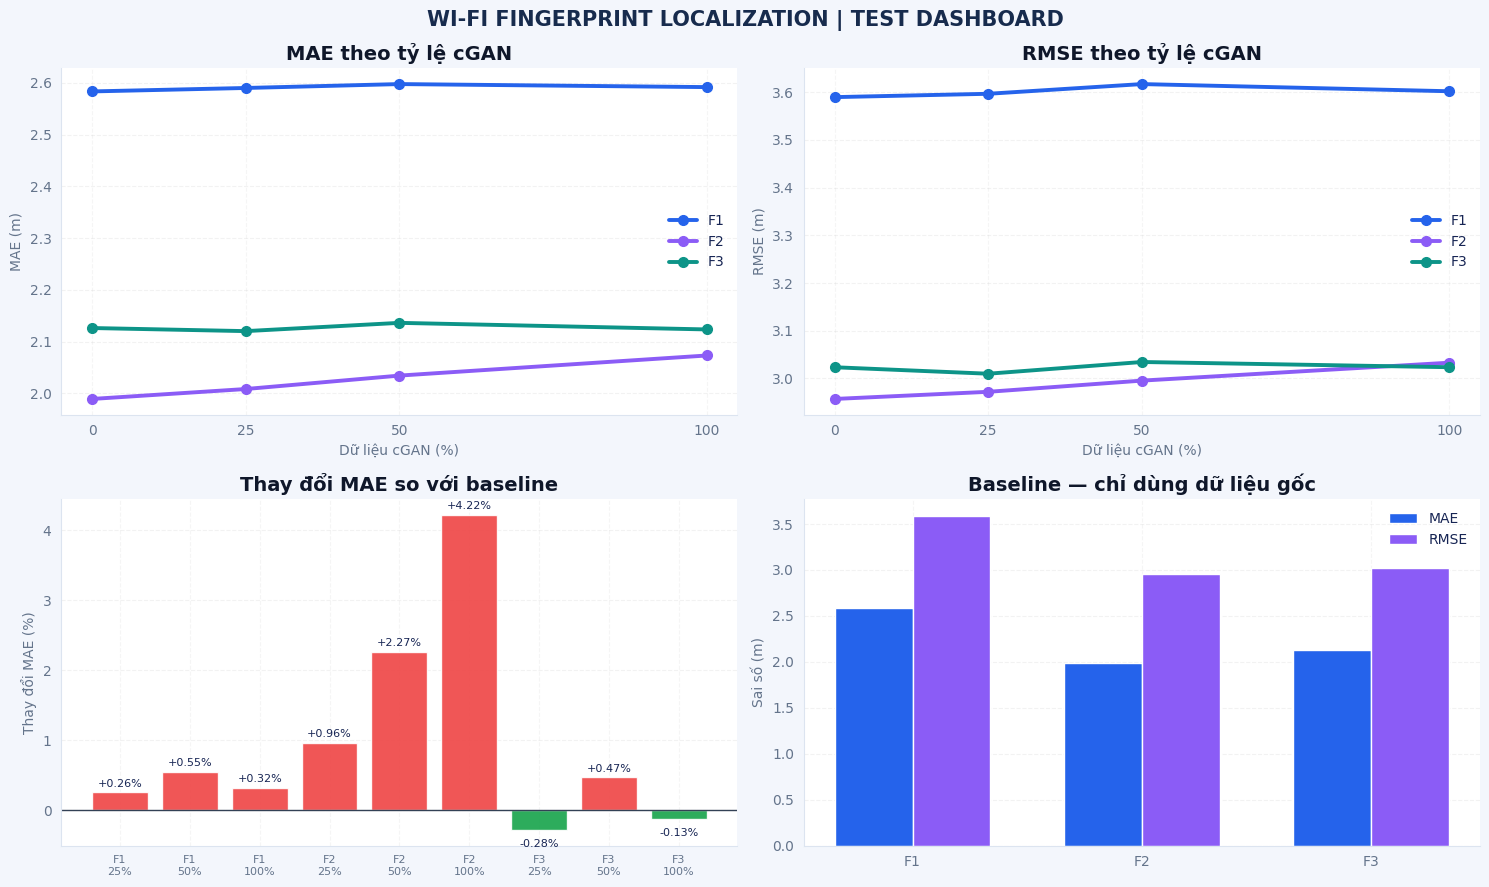

Đã lưu bảng tổng hợp: /content/ket_qua_tong_hop_test_cGAN.csv


In [ ]:

# ============================================================
# CELL 4.3.16 — FINAL TEST DASHBOARD
# Wi-Fi Fingerprinting | KNN vs cGAN Augmentation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ---------- 1. Kiểm tra dữ liệu ----------
required_cols = {
    "Floor", "Ratio_cGAN", "MAE_m", "RMSE_m"
}

if "test_results_df" not in globals():
    raise NameError(
        "Không tìm thấy test_results_df. "
        "Hãy chạy lại Cell 4.3.15 trước."
    )

missing = required_cols - set(test_results_df.columns)
if missing:
    raise ValueError(f"Thiếu cột trong test_results_df: {missing}")

df = test_results_df.copy()
df["Ratio_pct"] = (
    df["Ratio_cGAN"].astype(str).str.replace("%", "", regex=False).astype(float)
)

# Baseline được xác định trước: 0% cGAN
baseline = (
    df[df["Ratio_pct"] == 0]
    [["Floor", "MAE_m", "RMSE_m"]]
    .rename(columns={
        "MAE_m": "Baseline_MAE_m",
        "RMSE_m": "Baseline_RMSE_m"
    })
)

if set(baseline["Floor"]) != {"F1", "F2", "F3"}:
    raise ValueError("Cần có baseline 0% cGAN cho đủ F1, F2, F3.")

df = df.merge(baseline, on="Floor", how="left")
df["Delta_MAE_pct"] = (
    (df["MAE_m"] - df["Baseline_MAE_m"])
    / df["Baseline_MAE_m"] * 100
)
df["Delta_RMSE_pct"] = (
    (df["RMSE_m"] - df["Baseline_RMSE_m"])
    / df["Baseline_RMSE_m"] * 100
)


# ---------- FIX + DASHBOARD ----------
# Dùng df đã được chuẩn bị ở phần 1 của Cell 4.3.16

df = df.copy()

# Đảm bảo cột tỷ lệ tồn tại
if "Ratio_pct" not in df.columns:
    df["Ratio_pct"] = (
        df["Ratio_cGAN"].astype(str)
        .str.replace("%", "", regex=False)
        .astype(float)
    )

# Bảng kết quả
print("📊 BẢNG TỔNG HỢP KẾT QUẢ TEST")

display(
    df.sort_values(["Floor", "Ratio_pct"])[[
        "Floor", "Ratio_cGAN", "MAE_m", "RMSE_m",
        "Delta_MAE_pct", "Delta_RMSE_pct"
    ]]
    .round(4)
    .reset_index(drop=True)
    .style
    .format({
        "MAE_m": "{:.4f}",
        "RMSE_m": "{:.4f}",
        "Delta_MAE_pct": "{:+.2f}%",
        "Delta_RMSE_pct": "{:+.2f}%"
    })
    .background_gradient(
        subset=["MAE_m", "RMSE_m"], cmap="YlGnBu"
    )
    .background_gradient(
        subset=["Delta_MAE_pct"], cmap="RdYlGn_r"
    )
    .set_caption("KNN Localization — Independent Test Set")
)

# Dashboard hiện đại
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    "figure.facecolor": "#F3F6FC",
    "axes.facecolor": "#FFFFFF",
    "axes.edgecolor": "#DCE4F0",
    "axes.titleweight": "bold",
    "font.size": 10
})

floors = ["F1", "F2", "F3"]
ratios = [0, 25, 50, 100]
floor_colors = {"F1": "#2563EB", "F2": "#8B5CF6", "F3": "#0D9488"}

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
fig.patch.set_facecolor("#F3F6FC")

# 1. MAE
ax = axes[0, 0]
for floor in floors:
    sub = df[df["Floor"] == floor].sort_values("Ratio_pct")
    ax.plot(
        sub["Ratio_pct"], sub["MAE_m"],
        marker="o", linewidth=2.8, markersize=7,
        color=floor_colors[floor], label=floor
    )
ax.set_title("MAE theo tỷ lệ cGAN")
ax.set_xlabel("Dữ liệu cGAN (%)")
ax.set_ylabel("MAE (m)")
ax.set_xticks(ratios)
ax.grid(axis="y", alpha=.25)
ax.legend(frameon=False)

# 2. RMSE
ax = axes[0, 1]
for floor in floors:
    sub = df[df["Floor"] == floor].sort_values("Ratio_pct")
    ax.plot(
        sub["Ratio_pct"], sub["RMSE_m"],
        marker="o", linewidth=2.8, markersize=7,
        color=floor_colors[floor], label=floor
    )
ax.set_title("RMSE theo tỷ lệ cGAN")
ax.set_xlabel("Dữ liệu cGAN (%)")
ax.set_ylabel("RMSE (m)")
ax.set_xticks(ratios)
ax.grid(axis="y", alpha=.25)
ax.legend(frameon=False)

# 3. Mức thay đổi MAE so với baseline
ax = axes[1, 0]
plot_df = df[df["Ratio_pct"] > 0].copy()
labels = [
    f'{r["Floor"]}\n{int(r["Ratio_pct"])}%'
    for _, r in plot_df.iterrows()
]
values = plot_df["Delta_MAE_pct"].to_numpy()
bar_colors = [
    "#16A34A" if v < 0 else "#EF4444"
    for v in values
]
bars = ax.bar(range(len(values)), values, color=bar_colors, alpha=.9)
ax.axhline(0, color="#334155", linewidth=1)
ax.set_xticks(range(len(values)))
ax.set_xticklabels(labels, fontsize=8)
ax.set_title("Thay đổi MAE so với baseline")
ax.set_ylabel("Thay đổi MAE (%)")
ax.grid(axis="y", alpha=.25)

for bar, value in zip(bars, values):
    offset = 4 if value >= 0 else -12
    ax.annotate(
        f"{value:+.2f}%",
        (bar.get_x() + bar.get_width()/2, value),
        xytext=(0, offset), textcoords="offset points",
        ha="center", fontsize=8
    )

# 4. Baseline MAE / RMSE
ax = axes[1, 1]
base = df[df["Ratio_pct"] == 0].set_index("Floor").loc[floors]
x = np.arange(len(floors))
width = .34
ax.bar(x - width/2, base["MAE_m"], width,
       label="MAE", color="#2563EB")
ax.bar(x + width/2, base["RMSE_m"], width,
       label="RMSE", color="#8B5CF6")
ax.set_xticks(x)
ax.set_xticklabels(floors)
ax.set_title("Baseline — chỉ dùng dữ liệu gốc")
ax.set_ylabel("Sai số (m)")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=.25)

for ax in axes.flat:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "WI-FI FINGERPRINT LOCALIZATION | TEST DASHBOARD",
    fontsize=15, fontweight="bold", color="#172B4D"
)
plt.tight_layout()
plt.show()

# Xuất bảng tổng hợp
output_csv = "/content/ket_qua_tong_hop_test_cGAN.csv"
df.sort_values(["Floor", "Ratio_pct"]).to_csv(
    output_csv, index=False, encoding="utf-8-sig"
)
print(f"Đã lưu bảng tổng hợp: {output_csv}")


# FINAL PRESENTATION DASHBOARD — Wi-Fi Fingerprint + cGAN

**Mục tiêu:** một điểm vào duy nhất để trình bày kết quả chính, không cần tìm thủ công nhiều cell.

- Đọc kết quả đã tính trong notebook; **không huấn luyện lại mô hình**.
- So sánh MAE/RMSE trên Test theo tầng và tỷ lệ cGAN.
- Hiển thị quy mô dữ liệu, kết quả Validation đã chọn và các lưu ý phương pháp.
- Xuất bảng CSV và ảnh PNG để đưa vào báo cáo/slide.

**Điều kiện:** chạy các cell tạo `test_results_df`, `validation_results_df` và `synthetic_df` trước cell này. Dashboard sẽ báo rõ nếu thiếu biến thay vì tự tạo số liệu.



## 📡 Wi-Fi Fingerprint Lab — Kết quả tổng hợp

| Chỉ số | Kết quả |
|---|---:|
| Số tầng được đánh giá | 3 |
| Fingerprint tổng hợp | 280 |
| Phương pháp định vị | KNN, k = 5 |
| Trọng số KNN | Distance weighting |
| Tỷ lệ chọn theo Validation | F1: 0%, F2: 0%, F3: 0% |

**Lưu ý:** Validation được dùng để chọn tỷ lệ dữ liệu tổng hợp.
Tập Test được dùng để đánh giá cuối cùng, không dùng để chọn lại cấu hình.


📊 BẢNG KẾT QUẢ TRÊN TẬP TEST ĐỘC LẬP


,Floor,Ratio_cGAN,MAE_m,RMSE_m,Delta_MAE_pct,Delta_RMSE_pct
0,F1,0%,2.5836,3.5896,+0.00%,+0.00%
1,F1,25%,2.5902,3.5966,+0.26%,+0.20%
2,F1,50%,2.5978,3.6169,+0.55%,+0.76%
3,F1,100%,2.5919,3.6019,+0.32%,+0.34%
4,F2,0%,1.9894,2.9570,+0.00%,+0.00%
5,F2,25%,2.0086,2.9720,+0.96%,+0.51%
6,F2,50%,2.0346,2.9954,+2.27%,+1.30%
7,F2,100%,2.0734,3.0330,+4.22%,+2.57%
8,F3,0%,2.1265,3.0235,+0.00%,+0.00%
9,F3,25%,2.1205,3.0099,-0.28%,-0.45%


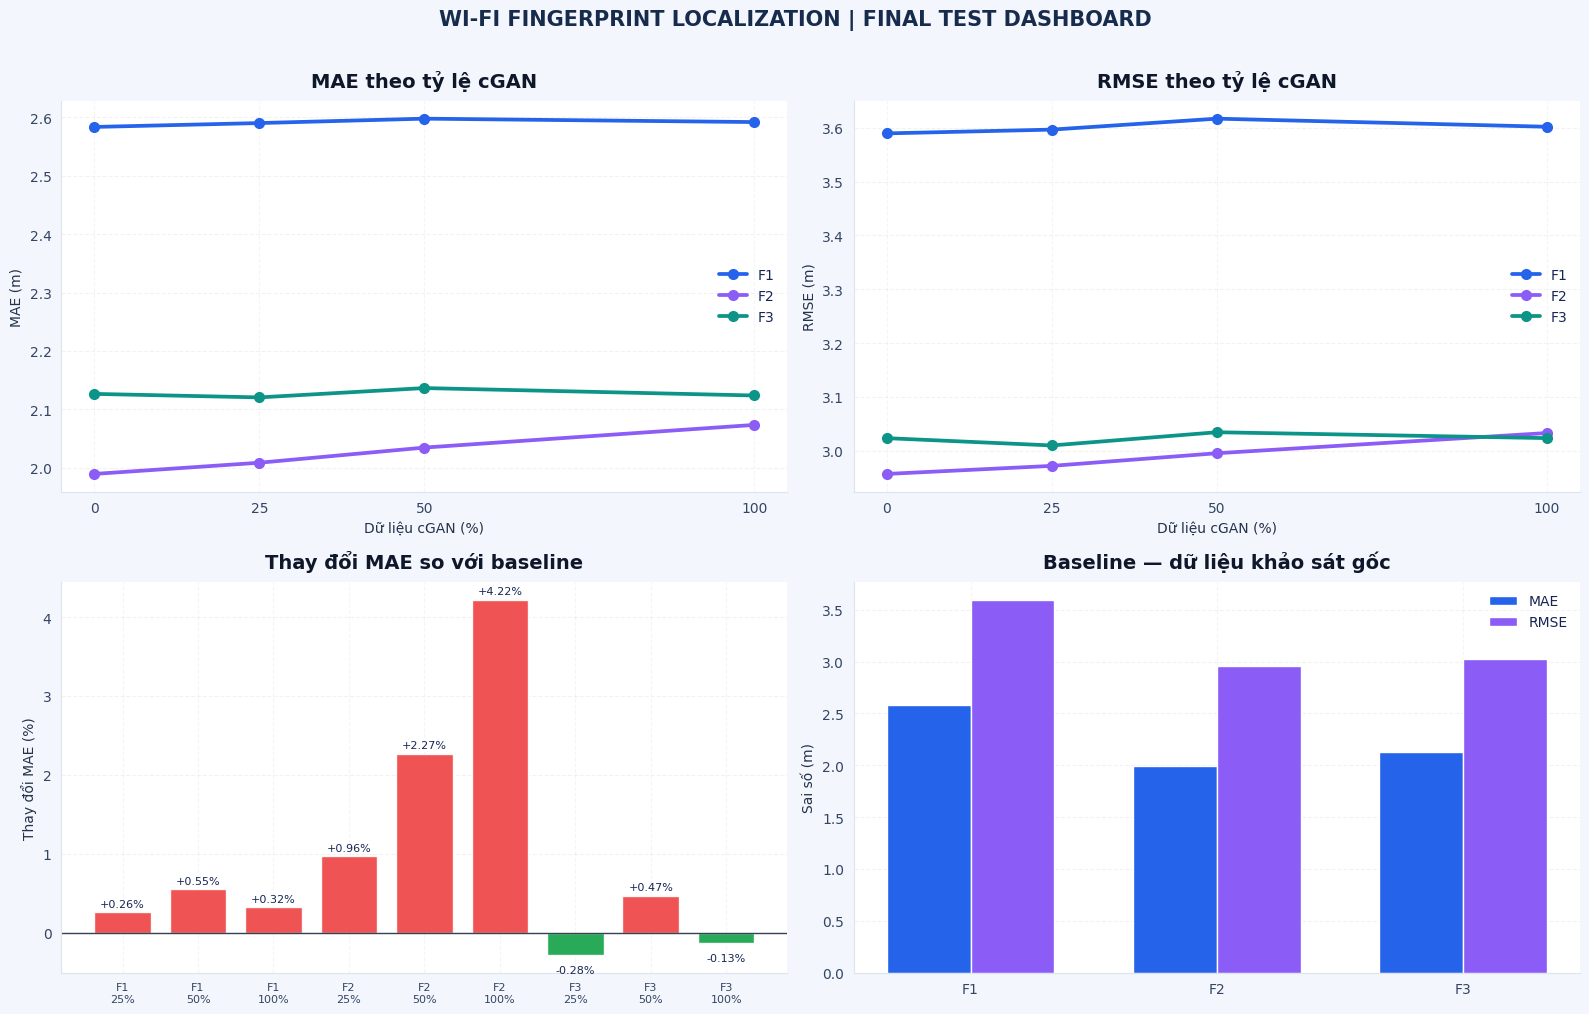

✅ Đã lưu biểu đồ: /content/final_presentation_dashboard.png
✅ Đã lưu bảng CSV: /content/final_test_results_summary.csv

📌 TỶ LỆ ĐƯỢC CHỌN THEO VALIDATION
F1: 0% cGAN
F2: 0% cGAN
F3: 0% cGAN

Lưu ý: Kết quả Test chỉ dùng để báo cáo hiệu năng cuối; không dùng để lựa chọn lại cấu hình.


In [ ]:
# ============================================================
# FINAL PRESENTATION DASHBOARD
# Wi-Fi Fingerprint Localization — KNN vs cGAN
# Không huấn luyện lại GAN, không chọn cấu hình dựa trên Test
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# ------------------------------------------------------------
# 1. KIỂM TRA DỮ LIỆU ĐẦU VÀO
# ------------------------------------------------------------
required = [
    "test_results_df",
    "validation_results_df",
    "synthetic_df"
]

missing_vars = [
    name for name in required
    if name not in globals()
]

if missing_vars:
    raise NameError(
        "Dashboard thiếu biến: "
        + ", ".join(missing_vars)
        + ". Hãy chạy các cell tạo kết quả Test, "
          "Validation và synthetic_df trước."
    )

test_df = test_results_df.copy()
val_df = validation_results_df.copy()

required_test_cols = {
    "Floor", "Ratio_cGAN", "MAE_m", "RMSE_m"
}
required_val_cols = {
    "Floor", "Ratio_cGAN", "MAE_m"
}

if not required_test_cols.issubset(test_df.columns):
    raise ValueError(
        "test_results_df thiếu cột: "
        f"{required_test_cols - set(test_df.columns)}"
    )

if not required_val_cols.issubset(val_df.columns):
    raise ValueError(
        "validation_results_df thiếu cột: "
        f"{required_val_cols - set(val_df.columns)}"
    )


def ratio_to_pct(series):
    """Chuyển tỷ lệ cGAN dạng số hoặc chuỗi về số phần trăm."""
    return pd.to_numeric(
        series.astype(str)
        .str.replace("%", "", regex=False),
        errors="raise"
    )


test_df["Ratio_pct"] = ratio_to_pct(test_df["Ratio_cGAN"])
val_df["Ratio_pct"] = ratio_to_pct(val_df["Ratio_cGAN"])

floors = [
    floor for floor in ["F1", "F2", "F3"]
    if floor in set(test_df["Floor"])
]

if not floors:
    raise ValueError(
        "Không tìm thấy dữ liệu các tầng F1, F2, F3."
    )

# ------------------------------------------------------------
# 2. TÍNH MỨC THAY ĐỔI SO VỚI BASELINE 0% cGAN
# ------------------------------------------------------------
baseline = (
    test_df.loc[
        test_df["Ratio_pct"] == 0,
        ["Floor", "MAE_m", "RMSE_m"]
    ]
    .drop_duplicates("Floor")
    .rename(columns={
        "MAE_m": "Baseline_MAE_m",
        "RMSE_m": "Baseline_RMSE_m"
    })
)

if set(floors) - set(baseline["Floor"]):
    raise ValueError(
        "Thiếu kết quả baseline 0% cGAN ở ít nhất một tầng."
    )

test_df = test_df.merge(
    baseline,
    on="Floor",
    how="left",
    validate="many_to_one"
)

test_df["Delta_MAE_pct"] = (
    (test_df["MAE_m"] / test_df["Baseline_MAE_m"] - 1)
    * 100
)

test_df["Delta_RMSE_pct"] = (
    (test_df["RMSE_m"] / test_df["Baseline_RMSE_m"] - 1)
    * 100
)

# ------------------------------------------------------------
# 3. CHỌN TỶ LỆ THEO VALIDATION, KHÔNG DÙNG TEST ĐỂ CHỌN
# ------------------------------------------------------------
best_val_rows = (
    val_df.loc[
        val_df.groupby("Floor")["MAE_m"].idxmin()
    ]
    .set_index("Floor")
    .reindex(floors)
)

selected_ratios = {
    floor: (
        float(best_val_rows.loc[floor, "Ratio_pct"])
        if pd.notna(best_val_rows.loc[floor, "Ratio_pct"])
        else np.nan
    )
    for floor in floors
}

# ------------------------------------------------------------
# 4. THỐNG KÊ DỮ LIỆU TỔNG HỢP
# ------------------------------------------------------------
synthetic_counts = {}

if "Floor" in synthetic_df.columns:
    synthetic_counts = (
        synthetic_df.groupby("Floor")
        .size()
        .to_dict()
    )

candidate_total = int(
    sum(synthetic_counts.get(floor, 0) for floor in floors)
)

display(Markdown(
    f"""
## 📡 Wi-Fi Fingerprint Lab — Kết quả tổng hợp

| Chỉ số | Kết quả |
|---|---:|
| Số tầng được đánh giá | {len(floors)} |
| Fingerprint tổng hợp | {candidate_total if candidate_total else 'Chưa xác định'} |
| Phương pháp định vị | KNN, k = 5 |
| Trọng số KNN | Distance weighting |
| Tỷ lệ chọn theo Validation | {', '.join(f'{f}: {selected_ratios[f]:.0f}%' for f in floors)} |

**Lưu ý:** Validation được dùng để chọn tỷ lệ dữ liệu tổng hợp.
Tập Test được dùng để đánh giá cuối cùng, không dùng để chọn lại cấu hình.
"""
))

# ------------------------------------------------------------
# 5. BẢNG KẾT QUẢ TEST
# ------------------------------------------------------------
table_cols = [
    "Floor",
    "Ratio_cGAN",
    "MAE_m",
    "RMSE_m",
    "Delta_MAE_pct",
    "Delta_RMSE_pct"
]

print("📊 BẢNG KẾT QUẢ TRÊN TẬP TEST ĐỘC LẬP")

# SỬA LỖI: sắp xếp trước, chọn cột sau
display(
    test_df.sort_values(
        ["Floor", "Ratio_pct"]
    )[table_cols]
    .reset_index(drop=True)
    .style
    .format({
        "MAE_m": "{:.4f}",
        "RMSE_m": "{:.4f}",
        "Delta_MAE_pct": "{:+.2f}%",
        "Delta_RMSE_pct": "{:+.2f}%"
    })
    .background_gradient(
        subset=["MAE_m", "RMSE_m"],
        cmap="YlGnBu"
    )
    .background_gradient(
        subset=["Delta_MAE_pct"],
        cmap="RdYlGn_r"
    )
    .set_caption(
        "Independent Test Set — KNN Localization"
    )
)

# ------------------------------------------------------------
# 6. THIẾT LẬP GIAO DIỆN BIỂU ĐỒ
# ------------------------------------------------------------
plt.rcParams.update({
    "figure.facecolor": "#F3F6FC",
    "axes.facecolor": "#FFFFFF",
    "axes.edgecolor": "#DCE4F0",
    "axes.labelcolor": "#24324B",
    "xtick.color": "#344563",
    "ytick.color": "#344563",
    "font.size": 10
})

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 10)
)

fig.patch.set_facecolor("#F3F6FC")

floor_colors = {
    "F1": "#2563EB",
    "F2": "#8B5CF6",
    "F3": "#0D9488"
}

ratio_ticks = sorted(
    test_df["Ratio_pct"].unique()
)

# ------------------------------------------------------------
# 6.1 MAE THEO TỶ LỆ cGAN
# ------------------------------------------------------------
ax = axes[0, 0]

for floor in floors:
    sub = (
        test_df[test_df["Floor"] == floor]
        .sort_values("Ratio_pct")
    )

    ax.plot(
        sub["Ratio_pct"],
        sub["MAE_m"],
        marker="o",
        linewidth=2.7,
        markersize=7,
        color=floor_colors.get(floor, "#64748B"),
        label=floor
    )

ax.set_title(
    "MAE theo tỷ lệ cGAN",
    fontweight="bold",
    pad=10
)
ax.set_xlabel("Dữ liệu cGAN (%)")
ax.set_ylabel("MAE (m)")
ax.set_xticks(ratio_ticks)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)

# ------------------------------------------------------------
# 6.2 RMSE THEO TỶ LỆ cGAN
# ------------------------------------------------------------
ax = axes[0, 1]

for floor in floors:
    sub = (
        test_df[test_df["Floor"] == floor]
        .sort_values("Ratio_pct")
    )

    ax.plot(
        sub["Ratio_pct"],
        sub["RMSE_m"],
        marker="o",
        linewidth=2.7,
        markersize=7,
        color=floor_colors.get(floor, "#64748B"),
        label=floor
    )

ax.set_title(
    "RMSE theo tỷ lệ cGAN",
    fontweight="bold",
    pad=10
)
ax.set_xlabel("Dữ liệu cGAN (%)")
ax.set_ylabel("RMSE (m)")
ax.set_xticks(ratio_ticks)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)

# ------------------------------------------------------------
# 6.3 THAY ĐỔI MAE SO VỚI BASELINE
# ------------------------------------------------------------
ax = axes[1, 0]

nonbase = (
    test_df[test_df["Ratio_pct"] > 0]
    .sort_values(["Floor", "Ratio_pct"])
    .copy()
)

labels = [
    f'{row["Floor"]}\n{int(row["Ratio_pct"])}%'
    for _, row in nonbase.iterrows()
]

values = nonbase["Delta_MAE_pct"].to_numpy()

bar_colors = [
    "#16A34A" if value < 0 else "#EF4444"
    for value in values
]

bars = ax.bar(
    np.arange(len(values)),
    values,
    color=bar_colors,
    alpha=0.92,
    width=0.75
)

ax.axhline(
    0,
    color="#334155",
    linewidth=1
)

ax.set_xticks(np.arange(len(values)))
ax.set_xticklabels(labels, fontsize=8)
ax.set_title(
    "Thay đổi MAE so với baseline",
    fontweight="bold",
    pad=10
)
ax.set_ylabel("Thay đổi MAE (%)")
ax.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, values):
    ax.annotate(
        f"{value:+.2f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            value
        ),
        xytext=(0, 4 if value >= 0 else -13),
        textcoords="offset points",
        ha="center",
        fontsize=8
    )

# ------------------------------------------------------------
# 6.4 BASELINE: MAE VÀ RMSE
# ------------------------------------------------------------
ax = axes[1, 1]

baseline_rows = (
    test_df[test_df["Ratio_pct"] == 0]
    .drop_duplicates("Floor")
    .set_index("Floor")
    .reindex(floors)
)

x = np.arange(len(floors))
width = 0.34

ax.bar(
    x - width / 2,
    baseline_rows["Baseline_MAE_m"],
    width,
    label="MAE",
    color="#2563EB"
)

ax.bar(
    x + width / 2,
    baseline_rows["Baseline_RMSE_m"],
    width,
    label="RMSE",
    color="#8B5CF6"
)

ax.set_xticks(x)
ax.set_xticklabels(floors)
ax.set_title(
    "Baseline — dữ liệu khảo sát gốc",
    fontweight="bold",
    pad=10
)
ax.set_ylabel("Sai số (m)")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)

# ------------------------------------------------------------
# 7. HOÀN THIỆN DASHBOARD
# ------------------------------------------------------------
for ax in axes.flat:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "WI-FI FINGERPRINT LOCALIZATION | FINAL TEST DASHBOARD",
    fontsize=15,
    fontweight="bold",
    color="#172B4D",
    y=1.01
)

plt.tight_layout()

# ------------------------------------------------------------
# 8. LƯU BIỂU ĐỒ VÀ BẢNG KẾT QUẢ
# ------------------------------------------------------------
output_dir = (
    "/content"
    if os.path.isdir("/content")
    else os.getcwd()
)

png_path = os.path.join(
    output_dir,
    "final_presentation_dashboard.png"
)

csv_path = os.path.join(
    output_dir,
    "final_test_results_summary.csv"
)

fig.savefig(
    png_path,
    dpi=220,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

# SỬA LỖI TƯƠNG TỰ Ở PHẦN XUẤT CSV:
# Sắp xếp DataFrame đầy đủ trước khi lấy các cột cần xuất.
(
    test_df.sort_values(["Floor", "Ratio_pct"])[table_cols]
    .to_csv(
        csv_path,
        index=False,
        encoding="utf-8-sig"
    )
)

print(f"✅ Đã lưu biểu đồ: {png_path}")
print(f"✅ Đã lưu bảng CSV: {csv_path}")

# ------------------------------------------------------------
# 9. IN KẾT QUẢ ĐƯỢC CHỌN THEO VALIDATION
# ------------------------------------------------------------
print("\n📌 TỶ LỆ ĐƯỢC CHỌN THEO VALIDATION")

for floor in floors:
    chosen = selected_ratios[floor]
    print(
        f"{floor}: {chosen:.0f}% cGAN"
        if pd.notna(chosen)
        else f"{floor}: chưa xác định được tỷ lệ"
    )

print(
    "\nLưu ý: Kết quả Test chỉ dùng để báo cáo hiệu năng cuối; "
    "không dùng để lựa chọn lại cấu hình."
)

In [ ]:

# ============================================================
# 3D INTERACTIVE FLOOR MAP — WI-FI FINGERPRINT
# Dữ liệu tọa độ thực | F1, F2, F3 | Plotly
# ============================================================

import os
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# 1. Đọc dữ liệu tọa độ
DATA_PATH = "/content/toa_do_RP_va_ung_vien.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Không tìm thấy {DATA_PATH}. "
        "Hãy chạy cell tạo file tọa độ RP và ứng viên trước."
    )

df = pd.read_csv(DATA_PATH)

required_cols = {"Floor", "X", "Y", "Status"}
if not required_cols.issubset(df.columns):
    raise ValueError(
        f"File cần có các cột {required_cols}. "
        f"Các cột hiện tại: {list(df.columns)}"
    )

df["Floor"] = df["Floor"].astype(str).str.strip().str.upper()
df["Status"] = df["Status"].astype(str).str.strip()
df["X"] = pd.to_numeric(df["X"], errors="coerce")
df["Y"] = pd.to_numeric(df["Y"], errors="coerce")
df = df.dropna(subset=["X", "Y"])

# Chỉ giữ ba tầng cần trình bày
floor_order = ["F1", "F2", "F3"]
df = df[df["Floor"].isin(floor_order)].copy()

if df.empty:
    raise ValueError("Không có dữ liệu hợp lệ cho F1, F2, F3.")

# 2. Xác định trạng thái khảo sát từ dữ liệu
status_norm = (
    df["Status"].str.lower()
    .str.replace(" ", "", regex=False)
)

surveyed_mask = status_norm.isin([
    "da_khao_sat",
    "đã_khảo_sát",
    "dakhaosat"
])

candidate_mask = status_norm.isin([
    "ung_vien_chua_co_rp",
    "ứng_viên_chưa_có_rp",
    "ung_vien",
    "ungvienchuacor"
])

unknown_statuses = sorted(
    df.loc[~(surveyed_mask | candidate_mask), "Status"].unique()
)

if unknown_statuses:
    raise ValueError(
        "Có trạng thái chưa được ánh xạ, tránh phân loại sai: "
        f"{unknown_statuses}"
    )

df["Loai"] = np.where(
    surveyed_mask,
    "RP đã khảo sát",
    "Vị trí ứng viên chưa có RP"
)

# 3. Tạo độ cao hiển thị cho từng tầng
# Đây là khoảng cách hiển thị, KHÔNG phải chiều cao thực của tòa nhà.
floor_z = {"F1": 0, "F2": 3, "F3": 6}
df["Z_plot"] = df["Floor"].map(floor_z)

# 4. Thống kê số điểm theo tầng
summary = (
    df.groupby(["Floor", "Loai"])
    .size()
    .unstack(fill_value=0)
    .reindex(floor_order, fill_value=0)
)

print("THỐNG KÊ ĐIỂM TỌA ĐỘ")
display(summary)

# 5. Dựng mô hình 3D
fig = go.Figure()

styles = {
    "RP đã khảo sát": {
        "color": "#2563EB",
        "symbol": "circle",
        "size": 4,
    },
    "Vị trí ứng viên chưa có RP": {
        "color": "#EF4444",
        "symbol": "diamond",
        "size": 5,
    },
}

for floor in floor_order:
    floor_df = df[df["Floor"] == floor]

    for label, style in styles.items():
        points = floor_df[floor_df["Loai"] == label]

        if points.empty:
            continue

        fig.add_trace(go.Scatter3d(
            x=points["X"],
            y=points["Y"],
            z=points["Z_plot"],
            mode="markers",
            name=label,
            legendgroup=label,
            showlegend=(floor == "F1"),
            marker=dict(
                color=style["color"],
                symbol=style["symbol"],
                size=style["size"],
                opacity=0.85,
                line=dict(width=0.25, color="white"),
            ),
            customdata=np.column_stack([
                points["Floor"],
                points["Status"],
                points["X"],
                points["Y"],
            ]),
            hovertemplate=(
                "<b>Tầng %{customdata[0]}</b><br>"
                "X = %{customdata[2]:.2f} m<br>"
                "Y = %{customdata[3]:.2f} m<br>"
                "Trạng thái: %{customdata[1]}"
                "<extra></extra>"
            ),
        ))

# 6. Vẽ mặt phẳng mờ để phân biệt tầng
x_min, x_max = df["X"].min(), df["X"].max()
y_min, y_max = df["Y"].min(), df["Y"].max()

for floor in floor_order:
    z = floor_z[floor]

    fig.add_trace(go.Mesh3d(
        x=[x_min, x_max, x_max, x_min],
        y=[y_min, y_min, y_max, y_max],
        z=[z, z, z, z],
        i=[0, 0],
        j=[1, 2],
        k=[2, 3],
        color={
            "F1": "#DBEAFE",
            "F2": "#EDE9FE",
            "F3": "#D1FAE5",
        }[floor],
        opacity=0.16,
        name=f"Mặt phẳng {floor}",
        showlegend=False,
        hoverinfo="skip",
    ))

# 7. Gắn nhãn tầng
for floor in floor_order:
    fig.add_trace(go.Scatter3d(
        x=[x_min],
        y=[y_max],
        z=[floor_z[floor]],
        mode="text",
        text=[floor],
        textfont=dict(size=16, color="#172554"),
        showlegend=False,
        hoverinfo="skip",
    ))

# 8. Hoàn thiện giao diện
n_surveyed = int(surveyed_mask.sum())
n_candidates = int(candidate_mask.sum())

fig.update_layout(
    title=dict(
        text=(
            "MẶT BẰNG 3D WI-FI FINGERPRINT"
            "<br><sup>"
            f"RP đã khảo sát: {n_surveyed} | "
            f"Vị trí ứng viên: {n_candidates} | "
            "Z biểu thị tầng, không phải chiều cao thực"
            "</sup>"
        ),
        x=0.5,
        xanchor="center",
    ),
    template="plotly_white",
    height=780,
    margin=dict(l=0, r=0, t=100, b=0),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="center",
        x=0.5,
    ),
    scene=dict(
        xaxis=dict(title="X (m)", range=[x_min - 1, x_max + 1]),
        yaxis=dict(title="Y (m)", range=[y_min - 1, y_max + 1]),
        zaxis=dict(
            title="Tầng (vị trí hiển thị)",
            tickvals=[0, 3, 6],
            ticktext=["F1", "F2", "F3"],
            range=[-1, 7],
        ),
        aspectmode="manual",
        aspectratio=dict(x=1.4, y=0.8, z=0.65),
        camera=dict(
            eye=dict(x=1.65, y=1.65, z=1.25)
        ),
    ),
)

fig.show()

# 9. Lưu bản HTML tương tác để trình chiếu
output_path = "/content/wifi_fingerprint_3d_floor_map.html"
fig.write_html(output_path, include_plotlyjs=True)

print(f"\nĐã tạo mô hình 3D tương tác.")
print(f"File HTML: {output_path}")
print("Có thể xoay, zoom và rê chuột lên điểm để xem tọa độ.")


THỐNG KÊ ĐIỂM TỌA ĐỘ


Loai,RP đã khảo sát,Vị trí ứng viên chưa có RP
Floor,,
F1,314,76
F2,186,174
F3,150,30



Đã tạo mô hình 3D tương tác.
File HTML: /content/wifi_fingerprint_3d_floor_map.html
Có thể xoay, zoom và rê chuột lên điểm để xem tọa độ.
